In [1]:
# Configuration. Open the notebook in Jupyter and select Run All.
# Existing data: set INPUT_DATA_DIR to the project or catalogue folder, if needed.
# "auto" reuses a verified canonical pair when available; otherwise it starts at raw FITS.
# "raw" rebuilds the canonical pair from the public FITS files (about 1.75 GB).
# "canonical" runs offline from an existing, byte-verified pair of canonical CSVs.
# A new output directory is created for each run. Input files are never edited.
from pathlib import Path
from datetime import datetime, timezone
import os

INPUT_MODE = os.environ.get("USYD_INPUT_MODE", "auto")
INPUT_DATA_DIR = os.environ.get("USYD_INPUT_DATA_DIR") or None
OUTPUT_DIR = Path(os.environ.get("USYD_OUTPUT_DIR", "usyd_runs"))
ALLOW_DOWNLOADS = True
# Optional: location of a local authors' source checkout for the provenance audit.
AUTHOR_SOURCE_DIR = os.environ.get("USYD_AUTHOR_SOURCE_DIR") or None

# Set True in a fresh Python 3.11+ kernel to install missing dependencies.
INSTALL_MISSING_DEPENDENCIES = True


In [2]:
# Runtime, isolated output directories and scientific stage runner
import hashlib
import importlib.metadata as metadata
import json
import shutil
import subprocess
import sys
import tempfile
import time
from urllib.error import URLError
from urllib.request import Request, urlopen

DEPENDENCIES = {
    "numpy": "2.3.5", "pandas": "2.2.3", "scipy": "1.17.0",
    "matplotlib": "3.10.8", "astropy": "7.2.0", "emcee": "3.1.6",
}
if INPUT_MODE not in {"auto", "raw", "canonical"}:
    raise ValueError("INPUT_MODE must be auto, raw or canonical.")
if sys.version_info < (3, 11):
    raise RuntimeError("Use a Python 3.11 or newer Jupyter kernel.")
missing = []
for package, version in DEPENDENCIES.items():
    try:
        metadata.version(package)
    except metadata.PackageNotFoundError:
        missing.append(f"{package}=={version}")
if missing:
    command = [sys.executable, "-m", "pip", "install", *missing]
    if not INSTALL_MISSING_DEPENDENCIES:
        raise RuntimeError(f"Install the missing dependencies in this kernel: {missing}")
    subprocess.check_call(command)

import astropy.units as u
from astropy.coordinates import SkyCoord
from IPython.display import display, Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, linear_sum_assignment

cwd = Path.cwd().resolve()
input_roots = list(dict.fromkeys(
    [Path(INPUT_DATA_DIR).expanduser().resolve()] if INPUT_DATA_DIR
    else [cwd, cwd.parent]
))
if INPUT_DATA_DIR and not input_roots[0].is_dir():
    raise FileNotFoundError(input_roots[0])

OUTPUT_DIR = OUTPUT_DIR.expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
PROJECT = RUN = Path(tempfile.mkdtemp(prefix=run_stamp + "-", dir=OUTPUT_DIR))
for name in ("data/raw/external_catalogues", "data/interim", "data/processed",
             "external", "scripts", "logs", "reports", "results", "figures"):
    (PROJECT / name).mkdir(parents=True, exist_ok=True)
versions = {name: metadata.version(name) for name in DEPENDENCIES}
(PROJECT / "reports/runtime_versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
print("Python:", sys.executable)
print("Package versions:", versions)
print("Result directory:", PROJECT)

def sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

def atomic_copy(source, destination):
    destination = Path(destination)
    with tempfile.NamedTemporaryFile(dir=destination.parent, delete=False) as temporary:
        temp_path = Path(temporary.name)
    try:
        shutil.copyfile(source, temp_path)
        temp_path.replace(destination)
    finally:
        temp_path.unlink(missing_ok=True)

def run_stage(filename, *arguments):
    script = PROJECT / "scripts" / filename
    log_path = PROJECT / "logs" / (script.stem + ".log")
    command = [sys.executable, "-u", str(script), *map(str, arguments)]
    print(f"Running {filename}", flush=True)
    with log_path.open("w", encoding="utf-8") as log, subprocess.Popen(
        command, cwd=PROJECT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding="utf-8", errors="replace",
        env={**os.environ, "PYTHONUTF8": "1", "PYTHONDONTWRITEBYTECODE": "1", "MPLBACKEND": "Agg"},
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        status = process.wait()
    if status:
        raise RuntimeError(f"{filename} exited with status {status}. See {log_path}")

def run_source(filename, source, *arguments):
    # Each audited stage has an isolated namespace; dependent stages can import its file.
    compile(source, filename, "exec")
    (PROJECT / "scripts" / filename).write_text(source, encoding="utf-8")
    run_stage(filename, *arguments)

def save_figure_pair(fig, stem):
    for extension in ("png", "pdf"):
        fig.savefig(PROJECT / "figures" / f"{stem}.{extension}", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


Python: /Volumes/Sudipta_T7/conda/envs/galactic_rotation_curve/bin/python
Package versions: {'numpy': '1.26.4', 'pandas': '2.3.3', 'scipy': '1.17.1', 'matplotlib': '3.11.2', 'astropy': '7.2.0', 'emcee': '3.1.6'}
Result directory: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5


In [3]:
# Locate verified local inputs first. Downloads are stored in a reusable cache.
INPUT_HASHES = {
    "canonical_target_table_step7D.csv": "9b61b763ce7cdf2a7031c9cde92808b4950f8aa68a1a73db1d706fd2d02fc788",
    "canonical_target_quality_flags_step7E.csv": "e55d8df12d81327f7a9f1fc6ae23e6a79ba3f7b0d7c1225f931e7bfe76e20885",
}
sdss_file = "/sas/dr14/apogee/spectro/redux/r8/stars/l31c/l31c.2/allStar-l31c.2.fits"
RAW_FILES = {
    "data/raw/data_HoggEilersRix2018.fits": (
        2649600, "ee5e5f103174ca6c191fd307c542ab2a000d83c988806dd70f3e9c2b04234bfe",
        ("https://zenodo.org/records/1468053/files/data_HoggEilersRix2018.fits?download=1",),
    ),
    "data/raw/external_catalogues/allStar-l31c.2.fits": (
        1702002240, "00f12cb93717998d5af03df446206ae918e61e8938452fae0f8b442bea26c4e5",
        ("https://dr14.sdss.org" + sdss_file + "?download=1",
         "https://data.sdss.org" + sdss_file, "https://dr12.sdss.org" + sdss_file),
    ),
    "data/raw/external_catalogues/apogee_dr14_nn_dist.fits": (
        50492160, "b6b7f95845294cc68a741a5b0418e2f3390228a499782512c6b8e248a535a779",
        ("https://raw.githubusercontent.com/henrysky/astroNN_gaia_dr2_paper/master/apogee_dr14_nn_dist.fits",),
    ),
}
CACHE = OUTPUT_DIR / "download_cache"
CACHE.mkdir(exist_ok=True)
input_records = []
verified_hashes = {}

def find_verified(relative, digest, size=None):
    path = Path(relative)
    for root in [*input_roots, CACHE]:
        for candidate in (root / path, root / path.name, root / path.parent.name / path.name):
            if not candidate.is_file():
                continue
            if size is not None and candidate.stat().st_size != size:
                print("Ignoring incorrect file size:", candidate)
                continue
            if candidate not in verified_hashes:
                verified_hashes[candidate] = sha256(candidate)
            if verified_hashes[candidate] == digest:
                return candidate
            print("Ignoring checksum mismatch:", candidate)
    return None

def stage_input(source, relative, digest, origin):
    destination = PROJECT / relative
    atomic_copy(source, destination)
    # Staging copies keep the original project writable state independent of this run.
    input_records.append({"file": relative, "source": origin, "sha256": digest})
    print(f"{relative}: {origin}")

def acquire_raw(relative, size, digest, urls):
    source = find_verified(relative, digest, size)
    if source is not None:
        stage_input(source, relative, digest, f"local: {source}")
        return
    if not ALLOW_DOWNLOADS:
        raise FileNotFoundError(f"Need a verified local copy of {relative} with downloads disabled.")
    cached = CACHE / Path(relative).name
    failures = []
    for url in urls:
        for attempt in range(2):
            with tempfile.NamedTemporaryFile(dir=CACHE, delete=False) as temporary:
                part = Path(temporary.name)
            try:
                print(f"Downloading {cached.name} ({size / 2**20:,.1f} MiB) from {url}", flush=True)
                with urlopen(Request(url, headers={"User-Agent": "USYD-notebook/1.0"}), timeout=90) as response, part.open("wb") as output:
                    shutil.copyfileobj(response, output, length=2**20)
                if part.stat().st_size != size or sha256(part) != digest:
                    raise ValueError("Downloaded bytes do not match the reference size and SHA-256.")
                part.replace(cached)
                stage_input(cached, relative, digest, url)
                return
            except (OSError, URLError, ValueError) as error:
                failures.append(f"{url}: {error}")
                if attempt == 0:
                    time.sleep(2)
            finally:
                part.unlink(missing_ok=True)
    raise RuntimeError(
        f"Unable to acquire {relative}. Provide a verified local copy or use the bundled "
        f"canonical inputs in auto/canonical mode. Details: {failures}"
    )

canonical_inputs = {
    name: find_verified(f"data/interim/{name}", digest)
    for name, digest in INPUT_HASHES.items()
}
REBUILD_CANONICAL = INPUT_MODE == "raw" or not all(canonical_inputs.values())
if REBUILD_CANONICAL:
    if INPUT_MODE == "canonical":
        raise FileNotFoundError("The verified canonical pair was not found. Set INPUT_DATA_DIR or extract the companion bundle.")
    for relative, (size, digest, urls) in RAW_FILES.items():
        acquire_raw(relative, size, digest, urls)
else:
    for name, source in canonical_inputs.items():
        stage_input(source, f"data/interim/{name}", INPUT_HASHES[name], f"local audited canonical: {source}")
    # The forensic report also records presence of any locally available raw files.
    for relative, (size, digest, _) in RAW_FILES.items():
        source = find_verified(relative, digest, size)
        if source is not None:
            stage_input(source, relative, digest, f"local: {source}")

authors_repo = next((p for p in (
    [Path(AUTHOR_SOURCE_DIR).expanduser().resolve()] if AUTHOR_SOURCE_DIR else
    [root / "external/spectroscopic_parallax" for root in input_roots]
) if p.is_dir()), None)
# The forensic audit reads the checkout in place when supplied; its availability is recorded.

# Keep the historical source evidence separate from the scientific catalogue inputs.
# Prefer local copies. A clean raw-data run retrieves the three pinned source files.
author_commit = "2e324b2e669503a4b55618ab217f12247ec6aff1"
author_hashes = {
    "rotation_curve_uncertainties.py": "5744a1e461911f99e9ab8a0ab2fc498564deb012f25b71990808e6f0648ac40a",
    "parent_sample.py": "597c4d0242e283dd1f5fbe47e1604d91bb0911e4873009261bd6a52c32455565",
    "fit_rot_curve.py": "685cd3d87fcffb208b73f7427fe4f2ca37b2a86279d3929f7c12028a00cd3051",
}
if AUTHOR_SOURCE_DIR and authors_repo is None:
    raise FileNotFoundError(f"Author source location does not exist: {AUTHOR_SOURCE_DIR}")
if authors_repo is None and REBUILD_CANONICAL and ALLOW_DOWNLOADS:
    authors_repo = PROJECT / "external/spectroscopic_parallax"
    authors_repo.mkdir()
    for name, digest in author_hashes.items():
        url = f"https://raw.githubusercontent.com/aceilers/spectroscopic_parallax/{author_commit}/{name}"
        try:
            with urlopen(url, timeout=30) as response:
                content = response.read()
            if hashlib.sha256(content).hexdigest() != digest:
                raise ValueError(f"Author source checksum mismatch: {url}")
            (authors_repo / name).write_bytes(content)
            input_records.append({"file": name, "source": url, "sha256": digest})
        except (OSError, URLError, ValueError) as error:
            print(f"Historical source unavailable for {name}: {error}")


data/interim/canonical_target_table_step7D.csv: local audited canonical: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/data/interim/canonical_target_table_step7D.csv
data/interim/canonical_target_quality_flags_step7E.csv: local audited canonical: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/data/interim/canonical_target_quality_flags_step7E.csv


In [4]:
# Rebuild the raw APOGEE candidate inventory
if REBUILD_CANONICAL:
    source = r'''#!/usr/bin/env python3
"""Step 7A: build an auditable APOGEE candidate-record inventory.

This script DOES NOT make the final scientific choice of one APOGEE record per
star. It generates a reproducible ranked candidate table and lists groups that
need review before a canonical 44,784-row catalogue is made.

Run in the project's Python environment on the Mac where the source catalogues
exist. Raw catalogues are only read; outputs go to data/interim and reports.
"""
from __future__ import annotations

from pathlib import Path
import sys
import numpy as np
from astropy.io import fits
from astropy.table import Table

ROOT = Path(__file__).resolve().parents[1]
PARALLAX_PATH = ROOT / "data/raw/data_HoggEilersRix2018.fits"
APOGEE_PATH = ROOT / "data/raw/external_catalogues/allStar-l31c.2.fits"
GAIA_XMATCH_PATH = ROOT / "data/raw/external_catalogues/apogee_dr14_nn_dist.fits"
OUT_DIR = ROOT / "data/interim"
REPORT_DIR = ROOT / "reports"

# STARFLAG bits from the DR14 definitions. The first group is severe spectrum
# quality; the second group is explicitly RV-related warnings.
STARFLAG_SEVERE_MASK = (1 << 0) | (1 << 3) | (1 << 4)
STARFLAG_RV_WARNING_MASK = (1 << 16) | (1 << 17)
EXTRATARG_DUPLICATE_MASK = 1 << 4


def normalized_strings(values) -> np.ndarray:
    """Convert FITS string columns to stripped Unicode without changing IDs."""
    arr = np.asarray(values)
    if arr.dtype.kind == "S":
        arr = np.char.decode(arr, encoding="utf-8", errors="replace")
    else:
        arr = arr.astype(str)
    return np.char.strip(arr)


def names_map(data) -> dict[str, str]:
    return {str(n).upper(): str(n) for n in data.names}


def get_col(data, name: str, *, required: bool = True, default=None):
    available = names_map(data)
    key = name.upper()
    if key not in available:
        if required:
            raise KeyError(f"Required column {name!r} not found. Available columns: {list(data.names)}")
        return np.full(len(data), default)
    return np.asarray(data[available[key]])


def numeric(values, dtype=float) -> np.ndarray:
    try:
        return np.asarray(values).astype(dtype, copy=False)
    except (TypeError, ValueError):
        return np.asarray(values, dtype=dtype)


def safe_float(values) -> np.ndarray:
    return numeric(values, float)


def main() -> int:
    for path in (PARALLAX_PATH, APOGEE_PATH, GAIA_XMATCH_PATH):
        if not path.exists():
            print(f"ERROR: required source file is missing: {path}", file=sys.stderr)
            return 2

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    REPORT_DIR.mkdir(parents=True, exist_ok=True)

    print("Reading the published parallax table...")
    parent = Table.read(PARALLAX_PATH)
    parent_id = normalized_strings(parent["2MASS_ID"])
    if len(np.unique(parent_id)) != len(parent_id):
        raise RuntimeError("The published parallax table no longer has unique 2MASS_ID values.")
    parent_lookup = {sid: i for i, sid in enumerate(parent_id)}

    print("Opening APOGEE DR14 and Gaia cross-match catalogues (read-only)...")
    with fits.open(APOGEE_PATH, memmap=True) as ap_hdul, fits.open(GAIA_XMATCH_PATH, memmap=True) as gaia_hdul:
        if len(ap_hdul) < 2 or len(gaia_hdul) < 2:
            raise RuntimeError("Expected table data in extension 1 of both catalogues.")
        ap = ap_hdul[1].data
        gaia = gaia_hdul[1].data
        if len(ap) != len(gaia):
            raise RuntimeError(f"Row counts do not align: APOGEE={len(ap)}, Gaia cross-match={len(gaia)}")

        ap_id_all = normalized_strings(get_col(ap, "APOGEE_ID"))
        gaia_id_all = normalized_strings(get_col(gaia, "APOGEE_ID"))
        if not np.array_equal(ap_id_all, gaia_id_all):
            raise RuntimeError("APOGEE_ID row order differs between allStar and Gaia cross-match.")

        ap_loc_all = get_col(ap, "LOCATION_ID")
        gaia_loc_all = get_col(gaia, "LOCATION_ID")
        if not np.array_equal(ap_loc_all, gaia_loc_all):
            raise RuntimeError("LOCATION_ID row order differs between allStar and Gaia cross-match.")

        # The published catalogue's 2MASS_ID values are the parent sample IDs.
        matched_rows = np.flatnonzero(np.isin(ap_id_all, parent_id))
        candidate_ids = ap_id_all[matched_rows]
        parent_rows = np.fromiter((parent_lookup[sid] for sid in candidate_ids), dtype=np.int64, count=len(candidate_ids))

        # Required columns used for candidate ranking and later kinematic work.
        apogee_id = ap_id_all[matched_rows]
        location_id = numeric(get_col(ap, "LOCATION_ID")[matched_rows], np.int64)
        field = normalized_strings(get_col(ap, "FIELD", required=False, default=""))[matched_rows]
        ap_ra = safe_float(get_col(ap, "RA")[matched_rows])
        ap_dec = safe_float(get_col(ap, "DEC")[matched_rows])
        glon = safe_float(get_col(ap, "GLON")[matched_rows])
        glat = safe_float(get_col(ap, "GLAT")[matched_rows])

        rv = safe_float(get_col(ap, "VHELIO_AVG")[matched_rows])
        rv_err = safe_float(get_col(ap, "VERR")[matched_rows])
        rv_err_med = safe_float(get_col(ap, "VERR_MED")[matched_rows])
        rv_scatter = safe_float(get_col(ap, "VSCATTER")[matched_rows])
        nvisits = numeric(get_col(ap, "NVISITS")[matched_rows], np.int64)
        starflag_signed = numeric(get_col(ap, "STARFLAG")[matched_rows], np.int64)
        aspcapflag_signed = numeric(get_col(ap, "ASPCAPFLAG")[matched_rows], np.int64)
        extratarg_signed = numeric(get_col(ap, "EXTRATARG")[matched_rows], np.int64)
        alpha_m = safe_float(get_col(ap, "ALPHA_M")[matched_rows])
        paramflag = get_col(ap, "PARAMFLAG")[matched_rows]
        param = get_col(ap, "PARAM")[matched_rows]
        fparam = get_col(ap, "FPARAM")[matched_rows]
        snr_all = safe_float(get_col(ap, "SNR", required=False, default=np.nan))
        snr = snr_all[matched_rows]

        # These Gaia DR2 values come from the cross-match table. Its row order was
        # checked above; do not use exact coordinate equality as a join key.
        gaia_ra = safe_float(get_col(gaia, "RA")[matched_rows])
        gaia_dec = safe_float(get_col(gaia, "DEC")[matched_rows])
        pmra = safe_float(get_col(gaia, "PMRA")[matched_rows])
        pmdec = safe_float(get_col(gaia, "PMDEC")[matched_rows])
        pmra_err = safe_float(get_col(gaia, "PMRA_ERROR")[matched_rows])
        pmdec_err = safe_float(get_col(gaia, "PMDEC_ERROR")[matched_rows])

        # Preserve raw flag values for audit; cast to uint32 only when testing bits
        # so signed sentinel values such as ASPCAPFLAG=-2147483648 retain bit 31.
        starflag_u = starflag_signed.astype(np.uint32, copy=False)
        extratarg_u = extratarg_signed.astype(np.uint32, copy=False)
        dup_flag = (extratarg_u & EXTRATARG_DUPLICATE_MASK) != 0
        severe_starflag = (starflag_u & STARFLAG_SEVERE_MASK) != 0
        rv_warning_flag = (starflag_u & STARFLAG_RV_WARNING_MASK) != 0

        rv_valid = (
            np.isfinite(rv) & (np.abs(rv) < 9000)
            & np.isfinite(rv_err) & (rv_err > 0) & (rv_err < 9000)
        )
        # ALPHA_M contains a -9999 sentinel in this file. Finite-only checks are
        # insufficient; use this flag only as a diagnostic here, not a final cut.
        alpha_valid = np.isfinite(alpha_m) & (alpha_m > -10) & (alpha_m < 10)

        # Rank is deliberately provisional, NOT the final scientific record choice:
        # 1) prefer EXTRATARG duplicate bit clear; 2) usable RV; 3) no severe
        # STARFLAG bits; 4) no RV-warning bits; 5) lower VERR; 6) more visits;
        # 7) higher SNR; finally preserve stable source row order.
        err_for_rank = np.where(np.isfinite(rv_err) & (rv_err > 0), rv_err, np.inf)
        nvisits_for_rank = np.where(nvisits >= 0, nvisits, 0)
        snr_for_rank = np.where(np.isfinite(snr), snr, -np.inf)
        rank_order = np.lexsort((
            matched_rows,
            -snr_for_rank,
            -nvisits_for_rank,
            err_for_rank,
            rv_warning_flag.astype(np.int8),
            severe_starflag.astype(np.int8),
            (~rv_valid).astype(np.int8),
            dup_flag.astype(np.int8),
            parent_rows,
        ))
        candidate_rank = np.empty(len(matched_rows), dtype=np.int32)
        ranked_by_parent: dict[int, list[int]] = {}
        for rank_pos, cand_idx in enumerate(rank_order, start=1):
            pidx = int(parent_rows[cand_idx])
            candidate_rank[cand_idx] = len(ranked_by_parent.get(pidx, [])) + 1
            ranked_by_parent.setdefault(pidx, []).append(int(cand_idx))

        # Candidate-level inventory. The published distance columns are carried
        # forward unchanged; each target appears once per APOGEE candidate record.
        cand = Table()
        cand["TARGET_ID"] = parent_id[parent_rows]
        cand["PARENT_ROW_INDEX"] = parent_rows
        cand["APOGEE_ROW_INDEX"] = matched_rows
        cand["CANDIDATE_RANK_PROVISIONAL"] = candidate_rank
        cand["APOGEE_ID"] = apogee_id
        cand["LOCATION_ID"] = location_id
        cand["FIELD"] = field
        cand["RA_APOGEE_DEG"] = ap_ra
        cand["DEC_APOGEE_DEG"] = ap_dec
        cand["GLON_DEG"] = glon
        cand["GLAT_DEG"] = glat
        cand["RV_KMS"] = rv
        cand["RV_ERR_KMS"] = rv_err
        cand["RV_ERR_MED_KMS"] = rv_err_med
        cand["RV_SCATTER_KMS"] = rv_scatter
        cand["NVISITS"] = nvisits
        cand["SNR"] = snr
        cand["STARFLAG"] = starflag_signed
        cand["ASPCAPFLAG"] = aspcapflag_signed
        cand["EXTRATARG"] = extratarg_signed
        cand["EXTRATARG_DUPLICATE"] = dup_flag
        cand["RV_VALID"] = rv_valid
        cand["STARFLAG_SEVERE_BITS_SET"] = severe_starflag
        cand["STARFLAG_RV_WARNING_BITS_SET"] = rv_warning_flag
        cand["ALPHA_M"] = alpha_m
        cand["ALPHA_M_VALID_NON_SENTINEL"] = alpha_valid
        cand["PARAM"] = param
        cand["FPARAM"] = fparam
        cand["PARAMFLAG"] = paramflag
        cand["GAIA_RA_DEG"] = gaia_ra
        cand["GAIA_DEC_DEG"] = gaia_dec
        cand["GAIA_PMRA_MAS_YR"] = pmra
        cand["GAIA_PMDEC_MAS_YR"] = pmdec
        cand["GAIA_PMRA_ERR_MAS_YR"] = pmra_err
        cand["GAIA_PMDEC_ERR_MAS_YR"] = pmdec_err
        cand["GAIA_PARALLAX_MAS"] = safe_float(parent["Gaia_parallax"])[parent_rows]
        cand["GAIA_PARALLAX_ERR_MAS"] = safe_float(parent["Gaia_parallax_err"])[parent_rows]
        cand["SPEC_PARALLAX_MAS"] = safe_float(parent["spec_parallax"])[parent_rows]
        cand["SPEC_PARALLAX_ERR_MAS"] = safe_float(parent["spec_parallax_err"])[parent_rows]
        cand["TRAINING_SET"] = normalized_strings(parent["training_set"])[parent_rows]
        cand["SAMPLE"] = normalized_strings(parent["sample"])[parent_rows]

        # Summary for every parent target, including flags for targets where a
        # simple EXTRATARG filter would leave no candidate.
        summary_rows = []
        grouped = ranked_by_parent
        for pidx, target_id in enumerate(parent_id):
            rows = grouped.get(pidx, [])
            nr = len(rows)
            primary_rows = [r for r in rows if not dup_flag[r]]
            rv_rows = [r for r in rows if rv_valid[r]]
            spread = float(np.ptp(rv[rv_rows])) if len(rv_rows) >= 2 else np.nan
            n_warn = int(np.sum(rv_warning_flag[rows])) if nr else 0
            n_severe = int(np.sum(severe_starflag[rows])) if nr else 0
            best_idx = rows[0] if rows else -1  # provisional rank-1 only
            if nr == 0:
                status = "NO_APOGEE_CANDIDATE"
            elif len(primary_rows) == 0:
                status = "NO_UNFLAGGED_EXTRATARG_CANDIDATE_FALLBACK_REVIEW"
            elif len(primary_rows) == 1:
                status = "ONE_UNFLAGGED_EXTRATARG_CANDIDATE"
            else:
                status = "MULTIPLE_UNFLAGGED_EXTRATARG_CANDIDATES_REVIEW"
            if np.isfinite(spread) and spread > 1.0:
                status += ";RV_SPREAD_GT_1_KMS"
            summary_rows.append((
                target_id, pidx, nr, len(primary_rows), len(rv_rows),
                int(np.sum(~rv_valid[rows])) if nr else 0,
                spread, int(np.sum(np.isfinite(rv[rv_rows]) & (np.abs(rv[rv_rows]) < 9000))) if len(rv_rows) else 0,
                n_severe, n_warn,
                field[best_idx] if best_idx >= 0 else "",
                int(location_id[best_idx]) if best_idx >= 0 else -1,
                float(rv[best_idx]) if best_idx >= 0 else np.nan,
                float(rv_err[best_idx]) if best_idx >= 0 else np.nan,
                bool(dup_flag[best_idx]) if best_idx >= 0 else True,
                status,
            ))

    summary = Table(rows=summary_rows, names=(
        "TARGET_ID", "PARENT_ROW_INDEX", "N_CANDIDATES", "N_EXTRATARG_CLEAR",
        "N_RV_VALID", "N_RV_INVALID", "RV_SPREAD_KMS", "N_VALID_RV_FOR_SPREAD",
        "N_CANDIDATES_WITH_SEVERE_STARFLAG", "N_CANDIDATES_WITH_RV_WARNING",
        "PROVISIONAL_TOP_FIELD", "PROVISIONAL_TOP_LOCATION_ID", "PROVISIONAL_TOP_RV_KMS",
        "PROVISIONAL_TOP_RV_ERR_KMS", "PROVISIONAL_TOP_DUPLICATE_FLAG", "REVIEW_STATUS",
    ))

    # Save candidates sorted by parent sample row, then provisional rank.
    final_order = np.lexsort((candidate_rank, parent_rows))
    cand = cand[final_order]

    candidate_fits = OUT_DIR / "apogee_target_candidates_step7.fits"
    summary_fits = OUT_DIR / "apogee_target_resolution_summary_step7.fits"
    review_csv = REPORT_DIR / "step7_duplicate_groups_review.csv"
    conflicts_csv = REPORT_DIR / "step7_rv_conflicts_review.csv"
    report_txt = REPORT_DIR / "step7_candidate_resolution_audit.txt"

    cand.write(candidate_fits, format="fits", overwrite=True)
    summary.write(summary_fits, format="fits", overwrite=True)
    review_mask = (np.asarray(summary["N_CANDIDATES"]) > 1) | (np.asarray(summary["N_EXTRATARG_CLEAR"]) != 1)
    review = summary[review_mask]
    review.write(review_csv, format="ascii.csv", overwrite=True)
    conflict_mask = np.isfinite(safe_float(summary["RV_SPREAD_KMS"])) & (safe_float(summary["RV_SPREAD_KMS"]) > 1.0)
    conflicts = summary[conflict_mask]
    conflicts.write(conflicts_csv, format="ascii.csv", overwrite=True)

    n_parent = len(parent)
    n_candidates = len(cand)
    n_zero = int(np.sum(np.asarray(summary["N_CANDIDATES"]) == 0))
    n_multi = int(np.sum(np.asarray(summary["N_CANDIDATES"]) > 1))
    n_no_primary = int(np.sum(np.asarray(summary["N_EXTRATARG_CLEAR"]) == 0))
    n_multi_primary = int(np.sum(np.asarray(summary["N_EXTRATARG_CLEAR"]) > 1))
    spreads = safe_float(summary["RV_SPREAD_KMS"])
    n_spread1 = int(np.sum(np.isfinite(spreads) & (spreads > 1.0)))
    n_spread5 = int(np.sum(np.isfinite(spreads) & (spreads > 5.0)))
    n_spread10 = int(np.sum(np.isfinite(spreads) & (spreads > 10.0)))
    alpha_cand = safe_float(cand["ALPHA_M"])
    n_alpha_sentinel = int(np.sum(~(np.isfinite(alpha_cand) & (alpha_cand > -10) & (alpha_cand < 10))))
    pmra_all = safe_float(cand["GAIA_PMRA_MAS_YR"])
    pmdec_all = safe_float(cand["GAIA_PMDEC_MAS_YR"])
    pm_valid = np.isfinite(pmra_all) & np.isfinite(pmdec_all) & (np.abs(pmra_all) < 9000) & (np.abs(pmdec_all) < 9000)

    report_lines = [
        "STEP 7A — APOGEE CANDIDATE-RECORD RESOLUTION AUDIT",
        "",
        f"Parent parallax targets: {n_parent}",
        f"Matched APOGEE candidate records: {n_candidates}",
        f"Targets with zero candidate records: {n_zero}",
        f"Targets with multiple candidate records: {n_multi}",
        f"Targets with no EXTRATARG bit-4-clear candidate: {n_no_primary}",
        f"Targets with multiple EXTRATARG bit-4-clear candidates: {n_multi_primary}",
        f"Targets with RV spread > 1 km/s among valid candidate RVs: {n_spread1}",
        f"Targets with RV spread > 5 km/s among valid candidate RVs: {n_spread5}",
        f"Targets with RV spread > 10 km/s among valid candidate RVs: {n_spread10}",
        f"Candidate rows with ALPHA_M missing/sentinel: {n_alpha_sentinel}",
        f"Candidate rows with usable Gaia PM pair: {int(np.sum(pm_valid))}/{len(cand)}",
        "",
        "IMPORTANT: no final record has been selected by this script.",
        "CANDIDATE_RANK_PROVISIONAL is an audit ordering only. Do not use it as the",
        "scientific catalogue until duplicate and RV-conflict cases are reviewed.",
        "EXTRATARG bit 4 marks a duplicate/non-primary observation; some targets may",
        "have no bit-clear candidate, so dropping all flagged rows would lose targets.",
        "ASPCAPFLAG describes ASPCAP parameter results; it is not by itself a blanket",
        "radial-velocity rejection criterion. Check STARFLAG, VSCATTER, VERR and RV spread.",
        "ALPHA_M=-9999 is a sentinel; alpha selection must not use finite-only checks.",
        "",
        f"Candidate FITS: {candidate_fits}",
        f"Per-target summary FITS: {summary_fits}",
        f"Review groups CSV: {review_csv}",
        f"RV conflict groups CSV: {conflicts_csv}",
    ]
    report_txt.write_text("\n".join(report_lines) + "\n", encoding="utf-8")

    print("\n".join(report_lines))
    print("\nSTEP 7A COMPLETE: diagnostic outputs created; final canonical selection is intentionally not committed.")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())
'''
    run_source('step7_candidate_resolution_audit.py', source)


In [5]:
# Classify candidate records and audit radial velocities
if REBUILD_CANONICAL:
    source = r'''#!/usr/bin/env python3
"""Step 7C: audit APOGEE record roles and re-evaluate RV conflicts.

This script reads the Step 7A FITS products only. It does not modify raw data and
does not write a final scientific catalogue. Its purpose is to distinguish
commissioning observations from the non-commissioning primary/duplicate records
before any final record selection is made.
"""
from __future__ import annotations

import csv
import math
import sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
from astropy.table import Table

ROOT = Path(__file__).resolve().parents[1]
INTERIM = ROOT / "data" / "interim"
REPORTS = ROOT / "reports"
CANDIDATE_PATH = INTERIM / "apogee_target_candidates_step7.fits"
SUMMARY_PATH = INTERIM / "apogee_target_resolution_summary_step7.fits"

CANDIDATE_COLUMNS = [
    "TARGET_ID", "PARENT_ROW_INDEX", "APOGEE_ROW_INDEX",
    "CANDIDATE_RANK_PROVISIONAL", "APOGEE_ID", "LOCATION_ID", "FIELD",
    "RV_KMS", "RV_ERR_KMS", "RV_ERR_MED_KMS", "RV_SCATTER_KMS",
    "NVISITS", "SNR", "STARFLAG", "ASPCAPFLAG", "EXTRATARG",
    "EXTRATARG_DUPLICATE", "RV_VALID",
    "STARFLAG_SEVERE_BITS_SET", "STARFLAG_RV_WARNING_BITS_SET",
    "ALPHA_M", "ALPHA_M_VALID_NON_SENTINEL",
    "SPEC_PARALLAX_MAS", "SPEC_PARALLAX_ERR_MAS",
    "GAIA_PARALLAX_MAS", "GAIA_PARALLAX_ERR_MAS",
    "GAIA_PMRA_MAS_YR", "GAIA_PMDEC_MAS_YR",
    "GAIA_PMRA_ERR_MAS_YR", "GAIA_PMDEC_ERR_MAS_YR",
    "RA_APOGEE_DEG", "DEC_APOGEE_DEG", "GLON_DEG", "GLAT_DEG",
    "TRAINING_SET", "SAMPLE",
]
SUMMARY_COLUMNS = [
    "TARGET_ID", "PARENT_ROW_INDEX", "N_CANDIDATES", "N_EXTRATARG_CLEAR",
    "N_RV_VALID", "N_RV_INVALID", "RV_SPREAD_KMS",
    "N_CANDIDATES_WITH_SEVERE_STARFLAG",
    "N_CANDIDATES_WITH_RV_WARNING", "REVIEW_STATUS",
]

# APOGEE_EXTRATARG bit meanings used here:
# bit 0 (value 1): NOT_MAIN; bit 1 (value 2): COMMISSIONING;
# bit 4 (value 16): DUPLICATE/non-primary observation.
NOT_MAIN_BIT = 1 << 0
COMMISSIONING_BIT = 1 << 1
TELLURIC_BIT = 1 << 2
APO1M_BIT = 1 << 3
DUPLICATE_BIT = 1 << 4


def text_value(x) -> str:
    if x is None:
        return ""
    if isinstance(x, bytes):
        return x.decode("utf-8", errors="replace").strip()
    try:
        if np.ma.is_masked(x):
            return ""
    except Exception:
        pass
    return str(x).strip()


def int_value(x, default=-1) -> int:
    try:
        if x is None or np.ma.is_masked(x):
            return default
        return int(x)
    except (TypeError, ValueError, OverflowError):
        return default


def float_value(x, default=float("nan")) -> float:
    try:
        if x is None or np.ma.is_masked(x):
            return default
        value = float(x)
        return value if math.isfinite(value) else default
    except (TypeError, ValueError, OverflowError):
        return default


def bool_value(x) -> bool:
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, str):
        return x.strip().lower() in {"true", "1", "yes"}
    return bool(x)


def as_id(x) -> str:
    return text_value(x)


def require_columns(table: Table, required: list[str], label: str) -> None:
    missing = [col for col in required if col not in table.colnames]
    if missing:
        raise RuntimeError(
            f"{label} is missing required columns: {missing}. "
            f"Found columns: {table.colnames}"
        )


def write_csv(path: Path, rows: list[dict], columns: list[str]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as fh:
        writer = csv.DictWriter(fh, fieldnames=columns, extrasaction="ignore")
        writer.writeheader()
        for row in rows:
            cleaned = {}
            for col in columns:
                value = row.get(col, "")
                if value is None:
                    cleaned[col] = ""
                elif isinstance(value, (float, np.floating)):
                    cleaned[col] = "" if not math.isfinite(float(value)) else repr(float(value))
                elif isinstance(value, (bool, np.bool_)):
                    cleaned[col] = "True" if bool(value) else "False"
                else:
                    cleaned[col] = text_value(value)
            writer.writerow(cleaned)


def candidate_role(ext: int) -> tuple[bool, bool, bool, bool, bool, str]:
    is_not_main = (ext & NOT_MAIN_BIT) != 0
    is_commissioning = (ext & COMMISSIONING_BIT) != 0
    is_telluric = (ext & TELLURIC_BIT) != 0
    is_apo1m = (ext & APO1M_BIT) != 0
    is_duplicate = (ext & DUPLICATE_BIT) != 0
    if is_commissioning and is_duplicate:
        role = "COMMISSIONING_DUPLICATE"
    elif is_commissioning:
        role = "COMMISSIONING_RECORD"
    elif is_telluric and is_duplicate:
        role = "TELLURIC_DUPLICATE"
    elif is_telluric:
        role = "TELLURIC_RECORD"
    elif is_apo1m and is_duplicate:
        role = "APO1M_DUPLICATE"
    elif is_apo1m:
        role = "APO1M_RECORD"
    elif is_duplicate:
        role = "NONCOMMISSIONING_DUPLICATE"
    elif ext == 0:
        role = "MAIN_SURVEY_PRIMARY"
    elif is_not_main:
        role = "NON_MAIN_PRIMARY"
    else:
        role = "STANDARD_PRIMARY_OTHER_FLAGS"
    return is_not_main, is_commissioning, is_telluric, is_apo1m, is_duplicate, role


def rv_spread(rows: list[dict], standard_observations_only: bool) -> tuple[int, float]:
    values = []
    for row in rows:
        if standard_observations_only and (
            row["IS_COMMISSIONING"] or row["IS_TELLURIC"] or row["IS_APO1M"]
        ):
            continue
        if row["RV_VALID"]:
            rv = row["RV_KMS"]
            if math.isfinite(rv):
                values.append(rv)
    if len(values) < 2:
        return len(values), float("nan")
    return len(values), float(max(values) - min(values))


def main() -> int:
    if not CANDIDATE_PATH.exists():
        print(f"ERROR: candidate FITS not found: {CANDIDATE_PATH}", file=sys.stderr)
        return 2
    if not SUMMARY_PATH.exists():
        print(f"ERROR: summary FITS not found: {SUMMARY_PATH}", file=sys.stderr)
        return 2

    REPORTS.mkdir(parents=True, exist_ok=True)
    print("Reading Step 7A candidate and target-summary FITS files...")
    cand = Table.read(CANDIDATE_PATH)
    summ = Table.read(SUMMARY_PATH)
    require_columns(cand, CANDIDATE_COLUMNS, "Step 7A candidate FITS")
    require_columns(summ, SUMMARY_COLUMNS, "Step 7A target summary FITS")

    # Convert candidate rows into plain scalar dictionaries, retaining the
    # source-row indices needed to trace every proposed record back to allStar.
    candidates = []
    for row in cand:
        item = {col: row[col] for col in CANDIDATE_COLUMNS}
        item["TARGET_ID"] = as_id(item["TARGET_ID"])
        item["APOGEE_ID"] = as_id(item["APOGEE_ID"])
        item["FIELD"] = as_id(item["FIELD"])
        item["PARENT_ROW_INDEX"] = int_value(item["PARENT_ROW_INDEX"])
        item["APOGEE_ROW_INDEX"] = int_value(item["APOGEE_ROW_INDEX"])
        item["CANDIDATE_RANK_PROVISIONAL"] = int_value(item["CANDIDATE_RANK_PROVISIONAL"])
        item["EXTRATARG"] = int_value(item["EXTRATARG"], default=0)
        for col in [
            "LOCATION_ID", "NVISITS", "STARFLAG", "ASPCAPFLAG", "TRAINING_SET"
        ]:
            item[col] = int_value(item[col])
        for col in [
            "RV_KMS", "RV_ERR_KMS", "RV_ERR_MED_KMS", "RV_SCATTER_KMS", "SNR",
            "ALPHA_M", "SPEC_PARALLAX_MAS", "SPEC_PARALLAX_ERR_MAS",
            "GAIA_PARALLAX_MAS", "GAIA_PARALLAX_ERR_MAS",
            "GAIA_PMRA_MAS_YR", "GAIA_PMDEC_MAS_YR",
            "GAIA_PMRA_ERR_MAS_YR", "GAIA_PMDEC_ERR_MAS_YR",
            "RA_APOGEE_DEG", "DEC_APOGEE_DEG", "GLON_DEG", "GLAT_DEG",
        ]:
            item[col] = float_value(item[col])
        for col in [
            "EXTRATARG_DUPLICATE", "RV_VALID",
            "STARFLAG_SEVERE_BITS_SET", "STARFLAG_RV_WARNING_BITS_SET",
            "ALPHA_M_VALID_NON_SENTINEL",
        ]:
            item[col] = bool_value(item[col])
        is_not_main, is_comm, is_telluric, is_apo1m, is_dup, role = candidate_role(item["EXTRATARG"])
        item["IS_NOT_MAIN"] = is_not_main
        item["IS_COMMISSIONING"] = is_comm
        item["IS_TELLURIC"] = is_telluric
        item["IS_APO1M"] = is_apo1m
        item["IS_DUPLICATE_BY_BITMASK"] = is_dup
        item["STANDARD_RECORD_ELIGIBLE"] = not (is_comm or is_telluric or is_apo1m or is_dup)
        item["RECORD_ROLE"] = role
        candidates.append(item)

    by_target: dict[str, list[dict]] = defaultdict(list)
    for item in candidates:
        by_target[item["TARGET_ID"]].append(item)

    summary_by_id = {}
    for row in summ:
        tid = as_id(row["TARGET_ID"])
        summary_by_id[tid] = {
            col: row[col] for col in SUMMARY_COLUMNS if col != "TARGET_ID"
        }

    summary_ids = set(summary_by_id)
    candidate_ids = set(by_target)
    if summary_ids != candidate_ids:
        missing_candidate = sorted(summary_ids - candidate_ids)[:10]
        unexpected_candidate = sorted(candidate_ids - summary_ids)[:10]
        raise RuntimeError(
            "Target-ID mismatch between Step 7A candidate and summary FITS. "
            f"Summary without candidates (first 10): {missing_candidate}; "
            f"Candidates absent from summary (first 10): {unexpected_candidate}"
        )

    # Compute per-target non-commissioning RV spreads. Commissioning rows are
    # excluded because APOGEE DR14 documents them as a non-homogeneous data set.
    target_rows = []
    per_target_spread = {}
    for tid, rows in by_target.items():
        n_noncomm_rv, spread_noncomm = rv_spread(rows, standard_observations_only=True)
        per_target_spread[tid] = spread_noncomm
        n_all_rv, spread_all = rv_spread(rows, standard_observations_only=False)

        eligible = [
            row for row in rows
            if row["STANDARD_RECORD_ELIGIBLE"]
        ]
        exact_main = [row for row in rows if row["EXTRATARG"] == 0]
        exact_nonmain = [row for row in rows if row["EXTRATARG"] == 1]
        commissioning = [row for row in rows if row["IS_COMMISSIONING"]]
        duplicate = [row for row in rows if row["IS_DUPLICATE_BY_BITMASK"]]

        proposal = None
        if len(eligible) == 1:
            proposal = eligible[0]
            if proposal["EXTRATARG"] == 0:
                status = "PROPOSED_MAIN_SURVEY_PRIMARY"
                reason = "Exactly one EXTRATARG=0 main-survey, non-commissioning, non-duplicate record."
            elif proposal["EXTRATARG"] == 1:
                status = "PROPOSED_NON_MAIN_PRIMARY"
                reason = "No EXTRATARG=0 record; exactly one EXTRATARG=1 non-main, non-commissioning, non-duplicate record."
            else:
                status = "PROPOSED_OTHER_NONCOMM_PRIMARY"
                reason = "Exactly one non-commissioning, non-duplicate record; verify targeting-bit interpretation."
        elif len(eligible) == 0:
            status = "REVIEW_NO_STANDARD_RECORD"
            reason = "No candidate free of commissioning, duplicate, telluric, and APO1M flags; inspect fallback candidates manually."
        else:
            status = "REVIEW_MULTIPLE_STANDARD_RECORDS"
            reason = "More than one standard candidate; do not auto-select."

        if n_noncomm_rv >= 2 and math.isfinite(spread_noncomm) and spread_noncomm > 10:
            rv_status = "STANDARD_RV_SPREAD_GT10_KMS"
        elif n_noncomm_rv >= 2 and math.isfinite(spread_noncomm) and spread_noncomm > 5:
            rv_status = "STANDARD_RV_SPREAD_GT5_KMS"
        elif n_noncomm_rv >= 2 and math.isfinite(spread_noncomm) and spread_noncomm > 1:
            rv_status = "STANDARD_RV_SPREAD_GT1_KMS"
        elif n_noncomm_rv >= 2:
            rv_status = "STANDARD_RV_SPREAD_LE1_KMS"
        else:
            rv_status = "INSUFFICIENT_NONCOMM_RV_RECORDS_TO_COMPARE"

        # Add source-summary fields as diagnostics, not decision rules.
        s = summary_by_id[tid]
        group = {
            "TARGET_ID": tid,
            "PARENT_ROW_INDEX": int_value(s["PARENT_ROW_INDEX"]),
            "N_CANDIDATES": len(rows),
            "N_EXTRATARG0_MAIN_SURVEY": len(exact_main),
            "N_EXTRATARG1_NON_MAIN": len(exact_nonmain),
            "N_STANDARD_RECORD_ELIGIBLE": len(eligible),
            "N_COMMISSIONING_CANDIDATES": len(commissioning),
            "N_TELLURIC_CANDIDATES": sum(row["IS_TELLURIC"] for row in rows),
            "N_APO1M_CANDIDATES": sum(row["IS_APO1M"] for row in rows),
            "N_DUPLICATE_BIT_CANDIDATES": len(duplicate),
            "N_STANDARD_RV_VALID": n_noncomm_rv,
            "STANDARD_RV_SPREAD_KMS": spread_noncomm,
            "N_ALL_RV_VALID": n_all_rv,
            "ALL_CANDIDATE_RV_SPREAD_KMS": spread_all,
            "PARENT_REPORTED_RV_SPREAD_KMS": float_value(s["RV_SPREAD_KMS"]),
            "N_CANDIDATES_WITH_SEVERE_STARFLAG": int_value(s["N_CANDIDATES_WITH_SEVERE_STARFLAG"]),
            "N_CANDIDATES_WITH_RV_WARNING": int_value(s["N_CANDIDATES_WITH_RV_WARNING"]),
            "PROPOSED_RECORD_STATUS": status,
            "PROPOSED_RECORD_REASON": reason,
            "RV_REVIEW_STATUS": rv_status,
            "PROPOSED_APOGEE_ROW_INDEX": proposal["APOGEE_ROW_INDEX"] if proposal else "",
            "PROPOSED_EXTRATARG": proposal["EXTRATARG"] if proposal else "",
            "PROPOSED_FIELD": proposal["FIELD"] if proposal else "",
            "PROPOSED_LOCATION_ID": proposal["LOCATION_ID"] if proposal else "",
            "PROPOSED_RV_KMS": proposal["RV_KMS"] if proposal else "",
            "PROPOSED_RV_ERR_KMS": proposal["RV_ERR_KMS"] if proposal else "",
            "PROPOSED_RV_SCATTER_KMS": proposal["RV_SCATTER_KMS"] if proposal else "",
            "PROPOSED_NVISITS": proposal["NVISITS"] if proposal else "",
            "PROPOSED_SNR": proposal["SNR"] if proposal else "",
            "PROPOSED_STARFLAG": proposal["STARFLAG"] if proposal else "",
            "PROPOSED_ASPCAPFLAG": proposal["ASPCAPFLAG"] if proposal else "",
            "PROPOSED_ALPHA_M": proposal["ALPHA_M"] if proposal else "",
            "PROPOSED_ALPHA_M_VALID": proposal["ALPHA_M_VALID_NON_SENTINEL"] if proposal else "",
            "MANUAL_DECISION": "",
            "MANUAL_REASON": "",
            "SOURCE_CHECK": "",
        }
        target_rows.append(group)

    target_rows.sort(key=lambda row: row["TARGET_ID"])

    candidate_extra_columns = [
        "IS_NOT_MAIN", "IS_COMMISSIONING", "IS_TELLURIC", "IS_APO1M",
        "IS_DUPLICATE_BY_BITMASK", "STANDARD_RECORD_ELIGIBLE", "RECORD_ROLE",
        "N_STANDARD_RV_VALID", "STANDARD_RV_SPREAD_KMS",
    ]
    enriched_candidates = []
    for item in candidates:
        tid = item["TARGET_ID"]
        n_nc, spread_nc = rv_spread(by_target[tid], standard_observations_only=True)
        enriched_candidates.append({
            **item,
            "N_STANDARD_RV_VALID": n_nc,
            "STANDARD_RV_SPREAD_KMS": spread_nc,
        })

    candidate_output_columns = CANDIDATE_COLUMNS + candidate_extra_columns
    # Include all source columns requested above; convert arrays/text fields safely
    # by writing only the scalar/audit columns that are relevant here.
    write_csv(
        REPORTS / "step7C_candidate_record_roles_all.csv",
        enriched_candidates,
        candidate_output_columns,
    )

    target_output_columns = [
        "TARGET_ID", "PARENT_ROW_INDEX", "N_CANDIDATES",
        "N_EXTRATARG0_MAIN_SURVEY", "N_EXTRATARG1_NON_MAIN",
        "N_STANDARD_RECORD_ELIGIBLE", "N_COMMISSIONING_CANDIDATES",
        "N_TELLURIC_CANDIDATES", "N_APO1M_CANDIDATES",
        "N_DUPLICATE_BIT_CANDIDATES", "N_STANDARD_RV_VALID",
        "STANDARD_RV_SPREAD_KMS", "N_ALL_RV_VALID",
        "ALL_CANDIDATE_RV_SPREAD_KMS", "PARENT_REPORTED_RV_SPREAD_KMS",
        "N_CANDIDATES_WITH_SEVERE_STARFLAG", "N_CANDIDATES_WITH_RV_WARNING",
        "PROPOSED_RECORD_STATUS", "PROPOSED_RECORD_REASON", "RV_REVIEW_STATUS",
        "PROPOSED_APOGEE_ROW_INDEX", "PROPOSED_EXTRATARG", "PROPOSED_FIELD",
        "PROPOSED_LOCATION_ID", "PROPOSED_RV_KMS", "PROPOSED_RV_ERR_KMS",
        "PROPOSED_RV_SCATTER_KMS", "PROPOSED_NVISITS", "PROPOSED_SNR",
        "PROPOSED_STARFLAG", "PROPOSED_ASPCAPFLAG", "PROPOSED_ALPHA_M",
        "PROPOSED_ALPHA_M_VALID", "MANUAL_DECISION", "MANUAL_REASON", "SOURCE_CHECK",
    ]
    write_csv(
        REPORTS / "step7C_target_record_selection_audit.csv",
        target_rows,
        target_output_columns,
    )

    # Export only standard-comparison candidates for any target whose non-commissioning
    # RV spread crosses the requested thresholds. The spread is repeated per row
    # and is explicitly diagnostic, not an automatic rejection.
    target_map = {r["TARGET_ID"]: r for r in target_rows}
    for threshold, label in [(1.0, "gt1kms"), (5.0, "gt5kms"), (10.0, "gt10kms")]:
        selected_ids = {
            tid for tid, spread in per_target_spread.items()
            if math.isfinite(spread) and spread > threshold
            and sum(1 for row in by_target[tid]
                    if (not row["IS_COMMISSIONING"]) and row["RV_VALID"]
                    and math.isfinite(row["RV_KMS"])) >= 2
        }
        selected_rows = [
            row for row in enriched_candidates
            if row["TARGET_ID"] in selected_ids and not row["IS_COMMISSIONING"]
        ]
        write_csv(
            REPORTS / f"step7C_science_comparable_rv_conflicts_{label}.csv",
            selected_rows,
            candidate_output_columns,
        )

    manual_rows = []
    for row in target_rows:
        reasons = []
        if row["N_STANDARD_RECORD_ELIGIBLE"] == 0:
            reasons.append("NO_STANDARD_RECORD")
        elif row["N_STANDARD_RECORD_ELIGIBLE"] > 1:
            reasons.append("MULTIPLE_STANDARD_RECORDS")
        spread = row["STANDARD_RV_SPREAD_KMS"]
        if isinstance(spread, (float, np.floating)) and math.isfinite(float(spread)):
            if float(spread) > 10:
                reasons.append("STANDARD_RV_SPREAD_GT10_KMS")
            elif float(spread) > 5:
                reasons.append("STANDARD_RV_SPREAD_GT5_KMS")
            elif float(spread) > 1:
                reasons.append("STANDARD_RV_SPREAD_GT1_KMS")
        if reasons:
            manual_rows.append({**row, "MANUAL_REVIEW_REASON": ";".join(reasons)})

    manual_columns = target_output_columns[:-3] + [
        "MANUAL_REVIEW_REASON", "MANUAL_DECISION", "MANUAL_REASON", "SOURCE_CHECK"
    ]
    write_csv(
        REPORTS / "step7C_targets_for_manual_review.csv",
        manual_rows,
        manual_columns,
    )

    # Build auditable report.
    def count_status(status_text: str) -> int:
        return sum(r["PROPOSED_RECORD_STATUS"] == status_text for r in target_rows)

    roles = Counter(row["RECORD_ROLE"] for row in candidates)
    eligible_counts = Counter(row["N_STANDARD_RECORD_ELIGIBLE"] for row in target_rows)
    n_targets = len(target_rows)
    n_candidates = len(candidates)
    n_duplicate_targets = sum(row["N_CANDIDATES"] > 1 for row in target_rows)

    standard_conflicts = {}
    for threshold in (1, 5, 10):
        standard_conflicts[threshold] = sum(
            isinstance(row["STANDARD_RV_SPREAD_KMS"], (float, np.floating))
            and math.isfinite(float(row["STANDARD_RV_SPREAD_KMS"]))
            and float(row["STANDARD_RV_SPREAD_KMS"]) > threshold
            and row["N_STANDARD_RV_VALID"] >= 2
            for row in target_rows
        )
    all_conflicts = {}
    for threshold in (1, 5, 10):
        all_conflicts[threshold] = sum(
            math.isfinite(float(row["ALL_CANDIDATE_RV_SPREAD_KMS"]))
            and float(row["ALL_CANDIDATE_RV_SPREAD_KMS"]) > threshold
            for row in target_rows
        )

    report_path = REPORTS / "step7C_record_role_and_rv_audit.txt"
    with report_path.open("w", encoding="utf-8") as fh:
        fh.write("STEP 7C — APOGEE RECORD-ROLE AND NON-COMMISSIONING RV AUDIT\n\n")
        fh.write(f"Parent targets in Step 7A summary: {n_targets:,}\n")
        fh.write(f"Candidate records in Step 7A FITS: {n_candidates:,}\n")
        fh.write(f"Targets with more than one candidate: {n_duplicate_targets:,}\n\n")
        fh.write("CANDIDATE RECORD-ROLE COUNTS (rows, not unique targets):\n")
        for role in sorted(roles):
            fh.write(f"  {role}: {roles[role]:,}\n")
        fh.write("\nTARGET-LEVEL CANDIDATE AVAILABILITY:\n")
        for n in sorted(eligible_counts):
            fh.write(f"  targets with {n} standard candidate(s) (excluding commissioning, duplicate, telluric, APO1M): "
                     f"{eligible_counts[n]:,}\n")
        fh.write("\nPROPOSED RECORD STATUS COUNTS:\n")
        for status in sorted({r["PROPOSED_RECORD_STATUS"] for r in target_rows}):
            fh.write(f"  {status}: {count_status(status):,}\n")
        fh.write("\nRV SPREAD COMPARISON:\n")
        fh.write("  The 'all-candidate' values include commissioning records.\n")
        fh.write("  The 'non-commissioning' values exclude candidates with EXTRATARG bit 1 set.\n")
        fh.write("  These are diagnostics only and do not automatically reject any target.\n")
        for threshold in (1, 5, 10):
            fh.write(
                f"  Spread > {threshold} km/s: all candidates={all_conflicts[threshold]:,}; "
                f"standard-comparison candidates={standard_conflicts[threshold]:,}\n"
            )
        fh.write("\nMANUAL-REVIEW EXPORT:\n")
        fh.write(f"  Targets flagged for review: {len(manual_rows):,}\n")
        fh.write("\nOUTPUTS:\n")
        for name in [
            "step7C_candidate_record_roles_all.csv",
            "step7C_target_record_selection_audit.csv",
            "step7C_targets_for_manual_review.csv",
            "step7C_science_comparable_rv_conflicts_gt1kms.csv",
            "step7C_science_comparable_rv_conflicts_gt5kms.csv",
            "step7C_science_comparable_rv_conflicts_gt10kms.csv",
        ]:
            fh.write(f"  {REPORTS / name}\n")
        fh.write("\nNo final scientific catalogue was written.\n")
        fh.write("The proposed record is a role-based recommendation only; inspect the audit before using it.\n")

    print(f"Wrote {n_candidates:,} candidate role rows.")
    print(f"Wrote {n_targets:,} per-target selection-audit rows.")
    print(f"Wrote {len(manual_rows):,} target rows for review.")
    print(f"Standard-comparison RV conflicts: >1={standard_conflicts[1]}, "
          f">5={standard_conflicts[5]}, >10={standard_conflicts[10]} km/s.")
    print(f"Summary report: {report_path}")
    print("STEP 7C COMPLETE. No final scientific catalogue was written.")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())
'''
    run_source('step7C_record_role_and_rv_audit.py', source)


In [6]:
# Resolve one APOGEE record per target
if REBUILD_CANONICAL:
    source = r'''#!/usr/bin/env python3
"""
STEP 7D — BUILD A PROVISIONAL ONE-ROW-PER-TARGET TABLE

This script does NOT write a final scientific sample. It:
  * reads the Hogg–Eilers–Rix 44,784-star parallax parent table;
  * uses the Step 7C candidate-role CSV;
  * chooses the unique non-commissioning/non-duplicate/non-telluric/non-APO1M
    candidate when one exists (EXTRATARG=0 or EXTRATARG=1);
  * flags, but does not silently resolve, targets with duplicate-only fallbacks
    or telluric-only records;
  * recomputes RV conflict spreads from non-commissioning candidates, explicitly
    labelling the spread as a duplicate-record diagnostic;
  * preserves the parent parallax rows and exports an auditable staging table.

No source catalogue is modified. Do not use this staging table for final science
cuts until the Eilers et al. (2019) selection is implemented and validated.
"""

from pathlib import Path
import sys
import numpy as np
import pandas as pd
from astropy.table import Table

ROOT = Path(__file__).resolve().parents[1]
PARENT_PATH = ROOT / "data/raw/data_HoggEilersRix2018.fits"
ROLES_PATH = ROOT / "reports/step7C_candidate_record_roles_all.csv"

OUT_INTERIM = ROOT / "data/interim"
OUT_REPORTS = ROOT / "reports"

OUT_TABLE = OUT_INTERIM / "canonical_target_table_step7D.csv"
OUT_AUDIT = OUT_REPORTS / "step7D_record_resolution_audit.txt"
OUT_UNRESOLVED = OUT_REPORTS / "step7D_unresolved_targets.csv"
OUT_NONMAIN = OUT_REPORTS / "step7D_nonmain_primary_targets.csv"
OUT_RV1 = OUT_REPORTS / "step7D_noncommissioning_duplicate_rv_conflicts_gt1kms.csv"
OUT_RV5 = OUT_REPORTS / "step7D_noncommissioning_duplicate_rv_conflicts_gt5kms.csv"
OUT_RV10 = OUT_REPORTS / "step7D_noncommissioning_duplicate_rv_conflicts_gt10kms.csv"

CANDIDATE_FIELDS = [
    "APOGEE_ROW_INDEX", "APOGEE_ID", "LOCATION_ID", "FIELD",
    "RV_KMS", "RV_ERR_KMS", "RV_ERR_MED_KMS", "RV_SCATTER_KMS", "NVISITS", "SNR",
    "STARFLAG", "ASPCAPFLAG", "EXTRATARG", "RECORD_ROLE",
    "IS_NOT_MAIN", "IS_COMMISSIONING", "IS_TELLURIC", "IS_APO1M",
    "IS_DUPLICATE_BY_BITMASK", "STANDARD_RECORD_ELIGIBLE",
    "STARFLAG_SEVERE_BITS_SET", "STARFLAG_RV_WARNING_BITS_SET",
    "ALPHA_M", "ALPHA_M_VALID_NON_SENTINEL",
    "SPEC_PARALLAX_MAS", "SPEC_PARALLAX_ERR_MAS",
    "GAIA_PARALLAX_MAS", "GAIA_PARALLAX_ERR_MAS",
    "GAIA_PMRA_MAS_YR", "GAIA_PMDEC_MAS_YR",
    "GAIA_PMRA_ERR_MAS_YR", "GAIA_PMDEC_ERR_MAS_YR",
    "RA_APOGEE_DEG", "DEC_APOGEE_DEG", "GLON_DEG", "GLAT_DEG",
    "CANDIDATE_RANK_PROVISIONAL",
]

def as_bool(series):
    """Convert robustly from CSV booleans/0-1 values."""
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    return series.astype(str).str.strip().str.lower().isin({"true", "1", "yes", "y"})

def main():
    for p in [PARENT_PATH, ROLES_PATH]:
        if not p.exists():
            raise FileNotFoundError(
                f"Required input not found: {p}\n"
                "Confirm Step 7C completed and the file is in the stated project path."
            )

    OUT_INTERIM.mkdir(parents=True, exist_ok=True)
    OUT_REPORTS.mkdir(parents=True, exist_ok=True)

    print("Reading published parent parallax catalogue...")
    parent_table = Table.read(PARENT_PATH)
    parent = parent_table.to_pandas()
    if "2MASS_ID" not in parent.columns:
        raise ValueError(f"2MASS_ID not found in parent catalogue. Columns: {list(parent.columns)}")
    parent["2MASS_ID"] = parent["2MASS_ID"].astype(str).str.strip()

    print("Reading Step 7C candidate-role table...")
    candidates = pd.read_csv(ROLES_PATH, low_memory=False)
    needed = {"TARGET_ID", "PARENT_ROW_INDEX", "APOGEE_ROW_INDEX", "EXTRATARG",
              "RV_KMS", "RV_VALID", "IS_COMMISSIONING", "IS_TELLURIC",
              "IS_APO1M", "IS_DUPLICATE_BY_BITMASK", "STANDARD_RECORD_ELIGIBLE"}
    missing = needed - set(candidates.columns)
    if missing:
        raise ValueError(f"Missing Step 7C columns: {sorted(missing)}")
    candidates["TARGET_ID"] = candidates["TARGET_ID"].astype(str).str.strip()
    for col in ["IS_COMMISSIONING", "IS_TELLURIC", "IS_APO1M",
                "IS_DUPLICATE_BY_BITMASK", "STANDARD_RECORD_ELIGIBLE", "RV_VALID"]:
        candidates[col] = as_bool(candidates[col])
    candidates["EXTRATARG"] = pd.to_numeric(candidates["EXTRATARG"], errors="coerce")
    candidates["RV_KMS"] = pd.to_numeric(candidates["RV_KMS"], errors="coerce")

    if parent["2MASS_ID"].duplicated().any():
        raise ValueError("Parent catalogue has repeated 2MASS_ID values; refusing one-to-one join.")
    if candidates["TARGET_ID"].isna().any():
        raise ValueError("Candidate table contains missing TARGET_ID values.")

    # The published parent is the authoritative target list, so use its IDs/order.
    parent_ids = set(parent["2MASS_ID"])
    extra_ids = set(candidates["TARGET_ID"]) - parent_ids
    missing_ids = parent_ids - set(candidates["TARGET_ID"])
    if extra_ids:
        raise ValueError(f"Candidate table contains {len(extra_ids)} IDs absent from parent catalogue.")
    if missing_ids:
        raise ValueError(
            f"{len(missing_ids)} parent targets have no Step 7C candidate rows. "
            "Do not continue until the matching audit is reconciled."
        )

    # RV conflicts are diagnostics across non-commissioning, non-telluric,
    # non-APO1M records. Duplicate-flagged rows are deliberately retained in
    # this comparison so disagreements can be traced; they are NOT treated as
    # eligible primary rows for selection.
    science_comparable = candidates[
        (~candidates["IS_COMMISSIONING"]) &
        (~candidates["IS_TELLURIC"]) &
        (~candidates["IS_APO1M"]) &
        candidates["RV_VALID"] &
        np.isfinite(candidates["RV_KMS"])
    ].copy()
    rvstats = science_comparable.groupby("TARGET_ID")["RV_KMS"].agg(
        N_NONCOMM_RV_RECORDS="count", NONCOMM_RV_MIN_KMS="min", NONCOMM_RV_MAX_KMS="max"
    )
    rvstats["NONCOMM_RV_SPREAD_KMS"] = (
        rvstats["NONCOMM_RV_MAX_KMS"] - rvstats["NONCOMM_RV_MIN_KMS"]
    )

    # One row per target. A unique standard candidate is a deterministic
    # record-resolution proposal; EXTRATARG=1 remains explicitly NOT_MAIN.
    selection_rows = []
    for target_id, group in candidates.groupby("TARGET_ID", sort=False):
        group = group.copy()
        eligible = group[group["STANDARD_RECORD_ELIGIBLE"]]
        chosen = None
        status = ""
        reason = ""

        if len(eligible) == 1:
            chosen = eligible.iloc[0]
            ext = int(chosen["EXTRATARG"]) if pd.notna(chosen["EXTRATARG"]) else -1
            if ext == 0:
                status = "PROVISIONAL_UNIQUE_MAIN_SURVEY_PRIMARY"
                reason = "Exactly one eligible EXTRATARG=0 candidate."
            elif ext == 1:
                status = "PROVISIONAL_UNIQUE_NOT_MAIN_PRIMARY"
                reason = "Exactly one eligible EXTRATARG=1 (NOT_MAIN) candidate; retained as a parent-table record, not labelled main-survey."
            else:
                status = "REVIEW_UNEXPECTED_ELIGIBLE_EXTRATARG"
                reason = f"Eligible candidate has unexpected EXTRATARG={ext}."
        elif len(eligible) > 1:
            status = "REVIEW_MULTIPLE_ELIGIBLE_CANDIDATES"
            reason = f"{len(eligible)} eligible candidates; no automatic selection."
        else:
            # Candidate fallback only for review; never present as final approved.
            fallbacks = group[
                (~group["IS_COMMISSIONING"]) &
                (~group["IS_TELLURIC"]) &
                (~group["IS_APO1M"]) &
                group["IS_DUPLICATE_BY_BITMASK"] &
                group["RV_VALID"] &
                np.isfinite(group["RV_KMS"])
            ]
            if len(fallbacks) == 1:
                chosen = fallbacks.iloc[0]
                status = "REVIEW_DUPLICATE_ONLY_FALLBACK"
                reason = "No eligible primary; one valid non-commissioning duplicate-only fallback exists."
            else:
                telluric_only = group["IS_TELLURIC"].all()
                if telluric_only:
                    status = "REVIEW_TELLURIC_ONLY"
                    reason = "No eligible primary; only telluric candidate(s) exist."
                else:
                    status = "REVIEW_NO_ELIGIBLE_PRIMARY"
                    reason = f"No eligible primary and {len(fallbacks)} usable duplicate-only fallback candidates."

        result = {
            "TARGET_ID": target_id,
            "N_CANDIDATES": int(len(group)),
            "N_ELIGIBLE_PRIMARY_CANDIDATES": int(len(eligible)),
            "RECORD_RESOLUTION_STATUS": status,
            "RECORD_RESOLUTION_REASON": reason,
            "PROVISIONAL_APOGEE_ROW_INDEX": (
                int(chosen["APOGEE_ROW_INDEX"])
                if chosen is not None and pd.notna(chosen["APOGEE_ROW_INDEX"]) else np.nan
            ),
            "PROVISIONAL_RECORD_APPROVED": bool(status.startswith("PROVISIONAL_UNIQUE_")),
            "PAPER_SAMPLE_MEMBERSHIP_DECIDED": False,
        }
        if chosen is not None:
            for col in CANDIDATE_FIELDS:
                if col in chosen.index:
                    result["SEL_" + col] = chosen[col]
        else:
            for col in CANDIDATE_FIELDS:
                result["SEL_" + col] = np.nan
        if target_id in rvstats.index:
            r = rvstats.loc[target_id]
            result.update({
                "N_NONCOMM_RV_RECORDS": int(r["N_NONCOMM_RV_RECORDS"]),
                "NONCOMM_RV_MIN_KMS": float(r["NONCOMM_RV_MIN_KMS"]),
                "NONCOMM_RV_MAX_KMS": float(r["NONCOMM_RV_MAX_KMS"]),
                "NONCOMM_RV_SPREAD_KMS": float(r["NONCOMM_RV_SPREAD_KMS"]),
            })
        else:
            result.update({
                "N_NONCOMM_RV_RECORDS": 0,
                "NONCOMM_RV_MIN_KMS": np.nan,
                "NONCOMM_RV_MAX_KMS": np.nan,
                "NONCOMM_RV_SPREAD_KMS": np.nan,
            })
        selection_rows.append(result)

    selection = pd.DataFrame(selection_rows)
    canonical = parent.merge(
        selection, left_on="2MASS_ID", right_on="TARGET_ID",
        how="left", validate="one_to_one"
    )
    if len(canonical) != len(parent) or canonical["TARGET_ID"].isna().any():
        raise ValueError("The one-to-one parent join failed; no output written.")

    # Explicit flags; spreads include duplicate records and are diagnostics,
    # not automatic exclusions or final RV quality decisions.
    spread = pd.to_numeric(canonical["NONCOMM_RV_SPREAD_KMS"], errors="coerce")
    canonical["RV_CONFLICT_GT1_KMS_DIAGNOSTIC"] = spread > 1.0
    canonical["RV_CONFLICT_GT5_KMS_DIAGNOSTIC"] = spread > 5.0
    canonical["RV_CONFLICT_GT10_KMS_DIAGNOSTIC"] = spread > 10.0

    canonical.to_csv(OUT_TABLE, index=False)

    # Review outputs
    unresolved = canonical[~canonical["RECORD_RESOLUTION_STATUS"].astype(str).str.startswith("PROVISIONAL_UNIQUE_")].copy()
    unresolved.to_csv(OUT_UNRESOLVED, index=False)

    nonmain = canonical[canonical["RECORD_RESOLUTION_STATUS"].eq("PROVISIONAL_UNIQUE_NOT_MAIN_PRIMARY")].copy()
    nonmain.to_csv(OUT_NONMAIN, index=False)

    # Export all candidates in groups with non-commissioning RV spread > threshold.
    # Keep every row in each flagged group, not only the row with the extreme value.
    for threshold, outpath in [(1.0, OUT_RV1), (5.0, OUT_RV5), (10.0, OUT_RV10)]:
        ids = set(rvstats.index[rvstats["NONCOMM_RV_SPREAD_KMS"] > threshold])
        frame = science_comparable[science_comparable["TARGET_ID"].isin(ids)].copy()
        frame = frame.sort_values(["TARGET_ID", "RV_KMS"])
        frame.to_csv(outpath, index=False)

    status_counts = canonical["RECORD_RESOLUTION_STATUS"].value_counts(dropna=False).to_dict()
    role_counts = canonical["SEL_RECORD_ROLE"].value_counts(dropna=False).to_dict() if "SEL_RECORD_ROLE" in canonical.columns else {}
    conflict_targets = {
        ">1 km/s": int((spread > 1).sum()),
        ">5 km/s": int((spread > 5).sum()),
        ">10 km/s": int((spread > 10).sum()),
    }

    lines = [
        "STEP 7D — PROVISIONAL RECORD-RESOLUTION TABLE",
        "",
        f"Parent parallax targets: {len(parent):,}",
        f"Candidate-role rows: {len(candidates):,}",
        f"Unique target IDs in candidate roles: {candidates['TARGET_ID'].nunique():,}",
        f"Canonical staging rows: {len(canonical):,}",
        "",
        "RECORD RESOLUTION STATUS COUNTS:",
    ]
    lines.extend([f"  {k}: {v:,}" for k, v in status_counts.items()])
    lines.extend(["", "SELECTED ROLE COUNTS (provisional roles only):"])
    lines.extend([f"  {k}: {v:,}" for k, v in role_counts.items()])
    lines.extend([
        "",
        "NON-COMMISSIONING RV-SPREAD DIAGNOSTICS:",
        "These spreads include non-commissioning duplicate candidates for comparison.",
        "They are flags for follow-up, not automatic rejection criteria.",
        f"  Target groups with spread >1 km/s: {conflict_targets['>1 km/s']:,}",
        f"  Target groups with spread >5 km/s: {conflict_targets['>5 km/s']:,}",
        f"  Target groups with spread >10 km/s: {conflict_targets['>10 km/s']:,}",
        "",
        "SCIENTIFIC CAUTIONS:",
        "  * EXTRATARG=1 is NOT_MAIN, not a main-survey primary.",
        "  * Non-main records are preserved as parent-table candidates; this script does not decide paper-sample membership.",
        "  * The 11 no-standard cases remain review-only; fallback rows are not approved.",
        "  * No Eilers et al. scientific cuts have been applied.",
        "  * No final scientific catalogue or rotation curve has been produced.",
        "",
        "OUTPUTS:",
        f"  {OUT_TABLE}",
        f"  {OUT_AUDIT}",
        f"  {OUT_UNRESOLVED}",
        f"  {OUT_NONMAIN}",
        f"  {OUT_RV1}",
        f"  {OUT_RV5}",
        f"  {OUT_RV10}",
    ])
    OUT_AUDIT.write_text("\n".join(lines) + "\n", encoding="utf-8")

    print("\n".join(lines))
    print("\nSTEP 7D COMPLETE — provisional staging table written.")

if __name__ == "__main__":
    try:
        main()
    except Exception as exc:
        print(f"ERROR: {exc}", file=sys.stderr)
        raise
'''
    run_source('step7D_build_provisional_record_table.py', source)


In [7]:
# Normalize the reconstructed APOGEE parent and quality table to the report schema.
def normalize_canonical(parent_path, selection_path, review_path):
    interim = PROJECT / "data/interim"
    parent = pd.read_csv(parent_path, low_memory=False)
    selection = pd.read_csv(selection_path, low_memory=False).set_index("TARGET_ID")
    reviewed = set(pd.read_csv(review_path, low_memory=False)["TARGET_ID"])
    ids = parent["2MASS_ID"]
    selection = selection.reindex(ids).reset_index(drop=True)
    out = pd.DataFrame({
        "2MASS_ID": ids,
        "Gaia_parallax": parent["Gaia_parallax"].astype("float32"),
        "Gaia_parallax_err": parent["Gaia_parallax_err"].astype("float32"),
        "spec_parallax": parent["spec_parallax"].astype("float32"),
        "spec_parallax_err": parent["spec_parallax_err"].astype("float32"),
    })

    # Calculate distance diagnostics from the decimal precisions exported by the source table.
    parallax = out["spec_parallax"].astype(str).astype(float)
    error = out["spec_parallax_err"].astype(str).astype(float)
    out["distance_kpc"] = 1 / parallax
    out["distance_err_kpc"] = error / parallax**2
    out["relative_parallax_error"] = error / parallax
    out["training_set"] = parent["training_set"]
    out["sample"] = parent["sample"].astype(str).str.replace(r"^b'(.+)'$", r"\1", regex=True).str.strip()
    out["TARGET_KEY"] = ids.str.removeprefix("2M")
    out["APOGEE_ROW_INDEX"] = parent["SEL_APOGEE_ROW_INDEX"]

    rename = {
        "SEL_VSCATTER_KMS": "SEL_RV_SCATTER_KMS", "SEL_NVISTS": "SEL_NVISITS",
    }
    fields = (
        "LOCATION_ID RA_APOGEE_DEG DEC_APOGEE_DEG GLON_DEG GLAT_DEG RV_KMS RV_ERR_KMS "
        "VSCATTER_KMS NVISTS SNR ALPHA_M EXTRATARG STARFLAG ASPCAPFLAG GAIA_PMRA_MAS_YR "
        "GAIA_PMDEC_MAS_YR GAIA_PMRA_ERR_MAS_YR GAIA_PMDEC_ERR_MAS_YR"
    ).split()
    float32_fields = {"RV_KMS", "RV_ERR_KMS", "VSCATTER_KMS", "SNR", "ALPHA_M"}
    for field in fields:
        name = "SEL_" + field
        data = parent[rename.get(name, name)]
        out[name] = data.astype("float32") if field in float32_fields else data

    has_row = out["APOGEE_ROW_INDEX"].notna()
    pm = out[["SEL_GAIA_PMRA_MAS_YR", "SEL_GAIA_PMDEC_MAS_YR",
              "SEL_GAIA_PMRA_ERR_MAS_YR", "SEL_GAIA_PMDEC_ERR_MAS_YR"]]
    valid_pm = np.isfinite(pm).all(axis=1) & (pm.iloc[:, 2:] > 0).all(axis=1)
    valid_rv = np.isfinite(out["SEL_RV_KMS"]) & out["SEL_RV_KMS"].abs().lt(9000)
    valid_rv_error = out["SEL_RV_ERR_KMS"].gt(0) & out["SEL_RV_ERR_KMS"].lt(9000)
    for name, flag in {
        "VALID_GAIA_PM": valid_pm, "VALID_RV": valid_rv, "VALID_RV_ERROR": valid_rv_error,
        "STARFLAG_SEVERE": parent["SEL_STARFLAG_SEVERE_BITS_SET"],
        "STARFLAG_RV_WARNING": parent["SEL_STARFLAG_RV_WARNING_BITS_SET"],
    }.items():
        out[name] = flag.where(has_row)
    out["TARGET_RV_SPREAD_KMS"] = selection["ALL_CANDIDATE_RV_SPREAD_KMS"].fillna(0).astype("float32")
    out["N_CANDIDATES_FOR_TARGET"] = parent["N_CANDIDATES"]
    out["STEP7C_RECORD_ROLE"] = parent["SEL_RECORD_ROLE"].replace(
        {"NONCOMMISSIONING_DUPLICATE": "NON_COMMISSIONING_DUPLICATE"}
    )
    out["STEP7C_REQUIRES_REVIEW"] = ids.isin(reviewed).where(has_row)
    approved = parent["PROVISIONAL_RECORD_APPROVED"]
    out["PROVISIONAL_RECORD_APPROVED"] = approved
    out["RECORD_RESOLUTION_STATUS"] = parent["RECORD_RESOLUTION_STATUS"].replace({
        "PROVISIONAL_UNIQUE_MAIN_SURVEY_PRIMARY": "PROVISIONAL_MAIN_SURVEY_PRIMARY",
        "PROVISIONAL_UNIQUE_NOT_MAIN_PRIMARY": "PROVISIONAL_NON_MAIN_PRIMARY",
    })

    quality = pd.DataFrame({
        "TARGET_ID_STEP7E": ids,
        "TARGET_KEY": out["TARGET_KEY"],
        "STEP7E_RECORD_APPROVED": approved,
        "STEP7E_NOT_MAIN_RECORD": out["STEP7C_RECORD_ROLE"].eq("NON_MAIN_PRIMARY"),
        "STEP7E_ALPHA_INVALID": ~(out["SEL_ALPHA_M"].gt(-10) & out["SEL_ALPHA_M"].lt(10)),
        "STEP7E_SPEC_PARALLAX_INVALID": ~(np.isfinite(parallax) & parallax.gt(0)),
        "STEP7E_RV_INVALID": ~valid_rv,
        "STEP7E_RV_ERROR_INVALID": ~valid_rv_error,
        "STEP7E_GAIA_PM_PAIR_INVALID": ~valid_pm,
        "STEP7E_STARFLAG_SEVERE_DIAGNOSTIC": out["STARFLAG_SEVERE"].eq(True),
        "STEP7E_STARFLAG_RV_WARNING_DIAGNOSTIC": out["STARFLAG_RV_WARNING"].eq(True),
        "STEP7E_RV_SCATTER_GT1_KMS": out["SEL_VSCATTER_KMS"].gt(1),
        "STEP7E_RV_SCATTER_GT5_KMS": out["SEL_VSCATTER_KMS"].gt(5),
    })
    out.to_csv(interim / "canonical_target_table_step7D.csv", index=False)
    quality.to_csv(interim / "canonical_target_quality_flags_step7E.csv", index=False)

if REBUILD_CANONICAL:
    provisional = PROJECT / "data/interim/canonical_target_table_step7D.csv"
    archived = provisional.with_name("provisional_candidate_selection.csv")
    provisional.replace(archived)
    normalize_canonical(
        archived,
        PROJECT / "reports/step7C_target_record_selection_audit.csv",
        PROJECT / "reports/step7C_targets_for_manual_review.csv",
    )
    for name, reference in canonical_inputs.items():
        rebuilt = PROJECT / "data/interim" / name
        if reference is not None:
            pd.testing.assert_frame_equal(
                pd.read_csv(rebuilt, low_memory=False),
                pd.read_csv(reference, low_memory=False),
                check_exact=False, rtol=2e-14, atol=2e-14,
            )
        input_records.append({
            "file": f"data/interim/{name}", "source": "reconstructed from public FITS",
            "sha256": sha256(rebuilt),
        })


In [8]:
# Validate and record the input catalogue before running the report analysis.
canonical_path = PROJECT / "data/interim/canonical_target_table_step7D.csv"
quality_path = PROJECT / "data/interim/canonical_target_quality_flags_step7E.csv"
canonical = pd.read_csv(canonical_path, low_memory=False)
quality_flags = pd.read_csv(quality_path, low_memory=False)
assert len(canonical) == len(quality_flags) == 44_784
assert canonical["2MASS_ID"].is_unique and quality_flags["TARGET_ID_STEP7E"].is_unique
assert set(canonical["2MASS_ID"]) == set(quality_flags["TARGET_ID_STEP7E"])
assert int(canonical["PROVISIONAL_RECORD_APPROVED"].sum()) == 44_773
expected_flag_counts = {
    "STEP7E_ALPHA_INVALID": 278,
    "STEP7E_GAIA_PM_PAIR_INVALID": 38,
    "STEP7E_STARFLAG_SEVERE_DIAGNOSTIC": 466,
    "STEP7E_STARFLAG_RV_WARNING_DIAGNOSTIC": 122,
}
assert quality_flags[list(expected_flag_counts)].sum().to_dict() == expected_flag_counts
actual_hashes = {path.name: sha256(path) for path in (canonical_path, quality_path)}
if not REBUILD_CANONICAL and actual_hashes != INPUT_HASHES:
    raise ValueError("Staged canonical inputs do not match the audited files.")
if authors_repo is not None:
    os.environ["USYD_FORENSIC_SOURCE"] = str(authors_repo)
else:
    os.environ.pop("USYD_FORENSIC_SOURCE", None)
(PROJECT / "reports/input_hashes.json").write_text(json.dumps(actual_hashes, indent=2), encoding="utf-8")
pd.DataFrame(input_records).to_csv(PROJECT / "reports/input_provenance.csv", index=False)
print("Verified canonical parent:", len(canonical), "stars")


Verified canonical parent: 44784 stars


In [9]:
# Stellar selection and catalogue audit
source = r'''#!/usr/bin/env python3
"""
STEP 8A — Reproduce Eilers et al. (2019) disc-tracer selection.

Inputs (read-only):
  data/interim/canonical_target_table_step7D.csv
  data/interim/canonical_target_quality_flags_step7E.csv

This script creates a row-level Galactocentric phase-space table, implements
only the cuts explicitly stated in Eilers et al. (2019), and reports a cut flow.
It does not alter source files, make new APOGEE-record choices, or compute a
rotation curve. Records flagged for manual review are kept in the master output
but excluded from the strict baseline selection. A second sensitivity sample
adds the 9 duplicate-only fallback rows when their measurements are usable.

Eilers et al. (2019) selection from the paper's Data Set section:
  * a 60-degree wedge centered on the Galactic-centre-to-Sun direction (±30°)
  * |z| <= 0.5 kpc OR |z|/R <= tan(6 degrees)
  * |v_z| <= 100 km/s
  * [alpha/M] (APOGEE ALPHA_M proxy) < 0.12
The paper reports 23,129 stars after these cuts, before exclusion of the inner
R < 5 kpc region from the rotation-curve analysis. The benchmark is reported,
not asserted, because catalogue/record choices may cause small differences.
"""
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import astropy.units as u
import astropy.coordinates as coord

ROOT = Path(__file__).resolve().parents[1]
CANON = ROOT / "data/interim/canonical_target_table_step7D.csv"
QUALITY = ROOT / "data/interim/canonical_target_quality_flags_step7E.csv"
REPORTS = ROOT / "reports"
INTERIM = ROOT / "data/interim"
PROCESSED = ROOT / "data/processed"

OUT_PHASE = INTERIM / "phase_space_catalogue_step8A.csv"
OUT_STRICT = PROCESSED / "eilers2019_selection_strict_step8A.csv"
OUT_FALLBACK = PROCESSED / "eilers2019_selection_with_duplicate_fallback_sensitivity_step8A.csv"
OUT_CUTFLOW = REPORTS / "step8A_selection_cutflow.csv"
OUT_AUDIT = REPORTS / "step8A_selection_audit.txt"
OUT_INPUT_REVIEW = REPORTS / "step8A_input_review.csv"

R0_KPC = 8.122
Z_SUN_KPC = 0.025
# Astropy's Galactocentric x axis points from the Sun toward the Galactic
# Centre, so its solar vx has the positive U component (+11.1 km/s). This is
# the same physical solar motion as the paper's -11.1 km/s in the opposite-x
# convention. The y and z components follow the paper's values.
V_SUN_ASTROPY_KMS = [11.1, 245.8, 7.8]
PAPER_BENCHMARK_N = 23129


def say(lines, text=""):
    lines.append(str(text))


def first_existing(df, options):
    for col in options:
        if col in df.columns:
            return col
    return None


def to_numeric(df, col):
    if col is None:
        return pd.Series(np.nan, index=df.index, dtype=float)
    return pd.to_numeric(df[col], errors="coerce")


def parse_bool(series):
    """Parse CSV booleans robustly, including byte-string artefacts."""
    s = series.astype("string").str.strip().str.lower()
    s = s.str.replace(r"^b['\"](.*)['\"]$", r"\1", regex=True)
    return s.isin({"true", "1", "yes", "y", "t"})


def normalize_byte_labels(series):
    """Convert text like b'A' or b'B' to ordinary labels for clean exports."""
    s = series.astype("string").str.strip()
    s = s.str.replace(r"^b['\"](.*)['\"]$", r"\1", regex=True)
    return s


def make_cutflow(df, variant, base_mask, valid_phase, wedge, disk, vz_ok, alpha_ok):
    mask = np.asarray(base_mask, dtype=bool).copy()
    n_parent = len(df)
    rows = [{
        "variant": variant,
        "step": "00_parent_targets",
        "n_remaining": n_parent,
        "removed_at_step": 0,
        "fraction_of_parent_percent": 100.0,
    }]
    steps = [
        ("01_record_status_eligible", np.asarray(base_mask, dtype=bool)),
        ("02_valid_6d_phase_space", np.asarray(valid_phase, dtype=bool)),
        ("03_within_60deg_sun_facing_wedge", np.asarray(wedge, dtype=bool)),
        ("04_disk_height_rule", np.asarray(disk, dtype=bool)),
        ("05_abs_vz_le_100_kms", np.asarray(vz_ok, dtype=bool)),
        ("06_alpha_m_lt_0p12", np.asarray(alpha_ok, dtype=bool)),
    ]
    previous = n_parent
    for name, condition in steps:
        mask &= condition
        current = int(mask.sum())
        rows.append({
            "variant": variant,
            "step": name,
            "n_remaining": current,
            "removed_at_step": int(previous - current),
            "fraction_of_parent_percent": 100.0 * current / n_parent if n_parent else np.nan,
        })
        previous = current
    return rows, mask


def main():
    REPORTS.mkdir(parents=True, exist_ok=True)
    INTERIM.mkdir(parents=True, exist_ok=True)
    PROCESSED.mkdir(parents=True, exist_ok=True)
    lines = ["STEP 8A — EILERS ET AL. (2019) SAMPLE-SELECTION AUDIT", "=" * 62]

    for p in (CANON, QUALITY):
        if not p.exists():
            say(lines, f"ERROR: required input file missing: {p}")
            OUT_AUDIT.write_text("\n".join(lines) + "\n", encoding="utf-8")
            print("\n".join(lines))
            return 2

    # low_memory=False avoids chunk-wise dtype warnings from optional/blank role flags.
    df = pd.read_csv(CANON, low_memory=False)
    qf = pd.read_csv(QUALITY, low_memory=False)
    id_col = first_existing(df, ["2MASS_ID", "TARGET_ID"])
    qid_col = first_existing(qf, ["TARGET_ID_STEP7E", "2MASS_ID", "TARGET_ID"])
    status_col = first_existing(df, ["RECORD_RESOLUTION_STATUS"])
    approved_col = first_existing(df, ["PROVISIONAL_RECORD_APPROVED"])
    if not all([id_col, qid_col, status_col, approved_col]):
        say(lines, f"ERROR: required ID/status fields missing: {id_col}, {qid_col}, {status_col}, {approved_col}")
        OUT_AUDIT.write_text("\n".join(lines) + "\n", encoding="utf-8")
        print("\n".join(lines))
        return 3

    df["_ID"] = df[id_col].astype("string").str.strip()
    qf["_ID"] = qf[qid_col].astype("string").str.strip()
    if df["_ID"].duplicated().any() or qf["_ID"].duplicated().any():
        raise ValueError("Input ID is not unique in canonical or Step 7E quality file; refusing one-to-many join.")
    qflag_cols = [c for c in qf.columns if c.startswith("STEP7E_")]
    qsubset = qf[["_ID"] + qflag_cols].copy()
    pre_n = len(df)
    df = df.merge(qsubset, on="_ID", how="left", validate="one_to_one", indicator="_quality_join")
    n_missing_q = int((df["_quality_join"] != "both").sum())
    if len(df) != pre_n or n_missing_q:
        raise ValueError(f"Quality-flag join did not preserve all rows (rows={len(df)}, unmatched={n_missing_q}).")
    df.drop(columns=["_quality_join"], inplace=True)

    status = df[status_col].fillna("MISSING_STATUS").astype(str).str.strip()
    approved = parse_bool(df[approved_col]).to_numpy(dtype=bool)
    fallback = status.eq("REVIEW_DUPLICATE_ONLY_FALLBACK").to_numpy(dtype=bool)

    # Required observables: APOGEE sky coordinates, positive spectrophotometric
    # parallax, Gaia DR2 proper motions, and selected APOGEE barycentric RV.
    ra_col = first_existing(df, ["SEL_RA_APOGEE_DEG", "RA_APOGEE_DEG", "RA"])
    dec_col = first_existing(df, ["SEL_DEC_APOGEE_DEG", "DEC_APOGEE_DEG", "DEC"])
    par_col = first_existing(df, ["spec_parallax", "SEL_SPEC_PARALLAX_MAS"])
    pmra_col = first_existing(df, ["SEL_GAIA_PMRA_MAS_YR", "GAIA_PMRA_MAS_YR"])
    pmdec_col = first_existing(df, ["SEL_GAIA_PMDEC_MAS_YR", "GAIA_PMDEC_MAS_YR"])
    rv_col = first_existing(df, ["SEL_RV_KMS", "RV_KMS"])
    alpha_col = first_existing(df, ["SEL_ALPHA_M", "ALPHA_M"])
    rverr_col = first_existing(df, ["SEL_RV_ERR_KMS", "RV_ERR_KMS"])
    if not all([ra_col, dec_col, par_col, pmra_col, pmdec_col, rv_col, alpha_col]):
        raise ValueError("Required phase-space/alpha columns missing: " + str({
            "ra": ra_col, "dec": dec_col, "parallax": par_col, "pmra": pmra_col,
            "pmdec": pmdec_col, "rv": rv_col, "alpha": alpha_col,
        }))

    ra = to_numeric(df, ra_col).to_numpy(float)
    dec = to_numeric(df, dec_col).to_numpy(float)
    parallax = to_numeric(df, par_col).to_numpy(float)
    pmra = to_numeric(df, pmra_col).to_numpy(float)
    pmdec = to_numeric(df, pmdec_col).to_numpy(float)
    rv = to_numeric(df, rv_col).to_numpy(float)
    alpha = to_numeric(df, alpha_col).to_numpy(float)
    rv_err = to_numeric(df, rverr_col).to_numpy(float) if rverr_col else np.full(len(df), np.nan)

    # parallax in mas -> distance in kpc = 1/parallax(mas), if positive.
    distance_kpc = np.full(len(df), np.nan, dtype=float)
    positive_par = np.isfinite(parallax) & (parallax > 0)
    distance_kpc[positive_par] = 1.0 / parallax[positive_par]
    valid_inputs = (
        np.isfinite(ra) & (ra >= 0) & (ra <= 360) &
        np.isfinite(dec) & (dec >= -90) & (dec <= 90) &
        np.isfinite(distance_kpc) & (distance_kpc > 0) &
        np.isfinite(pmra) & (np.abs(pmra) < 9000) &
        np.isfinite(pmdec) & (np.abs(pmdec) < 9000) &
        np.isfinite(rv)
    )

    # Explicit Eilers et al. / original-code convention; no Astropy defaults
    # are allowed to determine the Sun parameters implicitly.
    gc_frame = coord.Galactocentric(
        galcen_distance=R0_KPC * u.kpc,
        galcen_v_sun=np.asarray(V_SUN_ASTROPY_KMS) * u.km / u.s,
        z_sun=Z_SUN_KPC * u.kpc,
        roll=0.0 * u.deg,
    )

    n = len(df)
    x = np.full(n, np.nan); y = np.full(n, np.nan); z = np.full(n, np.nan)
    vx = np.full(n, np.nan); vy = np.full(n, np.nan); vz = np.full(n, np.nan)
    transform_index = np.flatnonzero(valid_inputs)
    if len(transform_index):
        sky = coord.SkyCoord(
            ra=ra[transform_index] * u.deg,
            dec=dec[transform_index] * u.deg,
            distance=distance_kpc[transform_index] * u.kpc,
            pm_ra_cosdec=pmra[transform_index] * u.mas / u.yr,
            pm_dec=pmdec[transform_index] * u.mas / u.yr,
            radial_velocity=rv[transform_index] * u.km / u.s,
            frame="icrs",
        )
        galcen = sky.transform_to(gc_frame)
        x[transform_index] = galcen.x.to_value(u.kpc)
        y[transform_index] = galcen.y.to_value(u.kpc)
        z[transform_index] = galcen.z.to_value(u.kpc)
        vx[transform_index] = galcen.v_x.to_value(u.km / u.s)
        vy[transform_index] = galcen.v_y.to_value(u.km / u.s)
        vz[transform_index] = galcen.v_z.to_value(u.km / u.s)

    r_gc = np.sqrt(x * x + y * y)
    # Astropy's Galactocentric +x direction points from the Sun toward the GC;
    # the Sun lies near x=-R0. Centre the published ±30-degree wedge on -x.
    phi_from_sun_deg = np.degrees(np.arctan2(y, -x))
    transform_valid = (
        np.isfinite(r_gc) & np.isfinite(z) & np.isfinite(vz) &
        np.isfinite(phi_from_sun_deg) & (r_gc > 0)
    )

    wedge_ok = transform_valid & (np.abs(phi_from_sun_deg) <= 30.0)
    disk_ok = transform_valid & (
        (np.abs(z) <= 0.5) |
        ((np.abs(z) / np.where(r_gc > 0, r_gc, np.nan)) <= np.tan(np.deg2rad(6.0)))
    )
    vz_ok = transform_valid & (np.abs(vz) <= 100.0)
    alpha_valid = np.isfinite(alpha) & (alpha > -9000)
    alpha_ok = alpha_valid & (alpha < 0.12)

    df["STEP8A_DISTANCE_KPC"] = distance_kpc
    df["STEP8A_GALACTOCENTRIC_X_KPC"] = x
    df["STEP8A_GALACTOCENTRIC_Y_KPC"] = y
    df["STEP8A_GALACTOCENTRIC_Z_KPC"] = z
    df["STEP8A_GALACTOCENTRIC_VX_KMS"] = vx
    df["STEP8A_GALACTOCENTRIC_VY_KMS"] = vy
    df["STEP8A_GALACTOCENTRIC_VZ_KMS"] = vz
    df["STEP8A_R_GC_KPC"] = r_gc
    df["STEP8A_PHI_FROM_SUN_AXIS_DEG"] = phi_from_sun_deg
    df["STEP8A_VALID_KINEMATIC_INPUTS"] = valid_inputs
    df["STEP8A_VALID_TRANSFORMED_PHASE_SPACE"] = transform_valid
    df["STEP8A_CUT_WEDGE_60DEG"] = wedge_ok
    df["STEP8A_CUT_DISK_HEIGHT"] = disk_ok
    df["STEP8A_CUT_VERTICAL_VELOCITY"] = vz_ok
    df["STEP8A_ALPHA_VALID_NON_SENTINEL"] = alpha_valid
    df["STEP8A_CUT_LOW_ALPHA"] = alpha_ok
    df["STEP8A_RECORD_BASELINE_STRICT"] = approved
    df["STEP8A_RECORD_BASELINE_WITH_DUPLICATE_FALLBACK"] = approved | fallback

    all_cutfow = []
    steps_strict, strict_pass = make_cutflow(
        df, "strict_approved_records", approved, transform_valid, wedge_ok, disk_ok, vz_ok, alpha_ok
    )
    steps_sens, sensitivity_pass = make_cutflow(
        df, "approved_plus_duplicate_fallback_sensitivity", approved | fallback,
        transform_valid, wedge_ok, disk_ok, vz_ok, alpha_ok
    )
    all_cutfow.extend(steps_strict)
    all_cutfow.extend(steps_sens)
    pd.DataFrame(all_cutfow).to_csv(OUT_CUTFLOW, index=False)

    df["STEP8A_PAPER_SELECTION_PASS_STRICT"] = strict_pass
    df["STEP8A_PAPER_SELECTION_PASS_WITH_DUPLICATE_FALLBACK"] = sensitivity_pass
    df["STEP8A_IN_ROTATION_CURVE_DOMAIN_5_TO_25_KPC"] = (
        transform_valid & (r_gc >= 5.0) & (r_gc <= 25.0)
    )
    df["STEP8A_ROTATION_CURVE_SAMPLE_STRICT"] = strict_pass & (r_gc >= 5.0) & (r_gc <= 25.0)
    df["STEP8A_ROTATION_CURVE_SAMPLE_WITH_DUPLICATE_FALLBACK"] = sensitivity_pass & (r_gc >= 5.0) & (r_gc <= 25.0)

    # Export complete row-level derived data, strict sample, and transparent
    # sensitivity sample. Byte-serialized labels are normalized in these outputs.
    if "sample" in df.columns:
        df["sample_normalized"] = normalize_byte_labels(df["sample"])
    df.drop(columns=["_ID"], inplace=True)
    df.to_csv(OUT_PHASE, index=False)
    df.loc[strict_pass].to_csv(OUT_STRICT, index=False)
    df.loc[sensitivity_pass].to_csv(OUT_FALLBACK, index=False)

    # Rows where the record is unapproved or the astrometric/RV inputs failed.
    input_review_mask = (~approved) | (~valid_inputs) | (~transform_valid)
    df.loc[input_review_mask].to_csv(OUT_INPUT_REVIEW, index=False)

    # Summaries use the actual flags, but no quality flag is silently promoted
    # to a scientific cut unless it is stated above in the paper's criteria.
    lines.extend([
        f"Parent rows: {n:,}",
        f"Unique target IDs: {df[id_col].nunique(dropna=True):,}",
        f"Approved provisional records: {int(approved.sum()):,}",
        f"Duplicate-only fallback rows (sensitivity only): {int(fallback.sum()):,}",
        f"Unresolved telluric-only rows: {int(status.eq('REVIEW_TELLURIC_ONLY').sum()):,}",
        f"Rows with valid required input observables: {int(valid_inputs.sum()):,}",
        f"Rows with transformed phase space valid: {int(transform_valid.sum()):,}",
        f"Missing/invalid RV uncertainty (diagnostic only): {int(((~np.isfinite(rv_err)) | (rv_err <= 0)).sum()):,}",
        f"Invalid/sentinel alpha values: {int((~alpha_valid).sum()):,}",
        "",
        "PUBLISHED SELECTION BENCHMARK",
        f"Eilers et al. (2019) published count after wedge + height + |vz| + alpha cuts: {PAPER_BENCHMARK_N:,}",
        f"Strict resolved sample after those cuts: {int(strict_pass.sum()):,}",
        f"Strict-sample difference from benchmark: {int(strict_pass.sum()) - PAPER_BENCHMARK_N:+,}",
        f"Sensitivity sample including duplicate-only fallback rows: {int(sensitivity_pass.sum()):,}",
        f"Sensitivity-sample difference from benchmark: {int(sensitivity_pass.sum()) - PAPER_BENCHMARK_N:+,}",
        "",
        "ROTATION-CURVE RADIUS DOMAIN (reported separately from the paper selection count)",
        f"Strict sample with 5 <= R <= 25 kpc: {int((strict_pass & (r_gc >= 5.0) & (r_gc <= 25.0)).sum()):,}",
        f"Sensitivity sample with 5 <= R <= 25 kpc: {int((sensitivity_pass & (r_gc >= 5.0) & (r_gc <= 25.0)).sum()):,}",
        f"Strict sample with R < 5 kpc (excluded from rotation-curve fit): {int((strict_pass & (r_gc < 5.0)).sum()):,}",
        f"Strict sample with R > 25 kpc (outside reported 5–25 kpc range): {int((strict_pass & (r_gc > 25.0)).sum()):,}",
        "",
        "DIAGNOSTICS IN STRICT SELECTED SAMPLE (not additional selection cuts)",
    ])
    quality_diagnostics = [
        ("STEP7E_NOT_MAIN_RECORD", "selected NOT_MAIN records"),
        ("STEP7E_STARFLAG_SEVERE_DIAGNOSTIC", "selected severe STARFLAG diagnostic"),
        ("STEP7E_STARFLAG_RV_WARNING_DIAGNOSTIC", "selected RV-warning STARFLAG diagnostic"),
        ("STEP7E_RV_SCATTER_GT1_KMS", "selected RV scatter >1 km/s"),
        ("STEP7E_RV_SCATTER_GT5_KMS", "selected RV scatter >5 km/s"),
        ("STEP7E_RV_ERROR_INVALID", "selected invalid RV uncertainty"),
    ]
    for col, label in quality_diagnostics:
        if col in df.columns:
            count = int((strict_pass & parse_bool(df[col]).to_numpy(dtype=bool)).sum())
            lines.append(f"  {label}: {count:,}")
        else:
            lines.append(f"  {label}: flag column missing")

    lines.extend([
        "",
        "INTERPRETATION / CAUTIONS",
        "  * The paper selection is alpha < 0.12, the ±30-degree Sun-facing wedge,",
        "    the published OR height rule, and |v_z| <= 100 km/s.",
        "  * Astropy parameters are explicitly fixed to R0=8.122 kpc, z_sun=0.025 kpc,",
        "    and solar velocity components [11.1, 245.8, 7.8] km/s in Astropy's x convention.",
        "  * The 23,129 comparison is a benchmark, not a forced equality. Investigate any",
        "    difference using the cut flow, record-review list, coordinate convention, and source matching.",
        "  * The R=5 kpc exclusion is reported separately; do not subtract it when comparing",
        "    against the paper's 23,129 selection count. Quality flags are diagnostics only.",
        "  * This script does not compute or fit the rotation curve.",
        "",
        "OUTPUTS",
        f"  Phase-space table: {OUT_PHASE}",
        f"  Strict selection: {OUT_STRICT}",
        f"  Duplicate-fallback sensitivity selection: {OUT_FALLBACK}",
        f"  Cut flow: {OUT_CUTFLOW}",
        f"  Input-review rows: {OUT_INPUT_REVIEW}",
        f"  Audit: {OUT_AUDIT}",
    ])
    OUT_AUDIT.write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n".join(lines))
    print("\nSTEP 8A COMPLETE: phase-space table and selection cut flow written.")
    return 0


if __name__ == "__main__":
    sys.exit(main())
'''
run_source('step8A_reproduce_eilers2019_selection.py', source)


Running step8A_reproduce_eilers2019_selection.py
STEP 8A — EILERS ET AL. (2019) SAMPLE-SELECTION AUDIT
Parent rows: 44,784
Unique target IDs: 44,784
Approved provisional records: 44,773
Duplicate-only fallback rows (sensitivity only): 9
Unresolved telluric-only rows: 2
Rows with valid required input observables: 44,746
Rows with transformed phase space valid: 44,746
Missing/invalid RV uncertainty (diagnostic only): 2
Invalid/sentinel alpha values: 278

PUBLISHED SELECTION BENCHMARK
Eilers et al. (2019) published count after wedge + height + |vz| + alpha cuts: 23,129
Strict resolved sample after those cuts: 23,010
Strict-sample difference from benchmark: -119
Sensitivity sample including duplicate-only fallback rows: 23,010
Sensitivity-sample difference from benchmark: -119

ROTATION-CURVE RADIUS DOMAIN (reported separately from the paper selection count)
Strict sample with 5 <= R <= 25 kpc: 21,800
Sensitivity sample with 5 <= R <= 25 kpc: 21,800
Strict sample with R < 5 kpc (excluded f

In [10]:
# Monte Carlo velocity tensors
source = r'''#!/usr/bin/env python3
"""Step 9B, corrected: reproducible uncertainty propagation for Eilers 2019.

IMPORTANT:
- The scientific sample is the existing Step 8A *strict* sample. This program
  NEVER recomputes or changes that membership.
- Default distance model is an EXPLICIT LOGNORMAL APPROXIMATION; it is not
  claimed to be the unavailable full historical Eilers likelihood.
- Galactocentric angle is averaged with circular statistics.
- No hard clipping of near-zero parallaxes, distances, or velocities.
- The original Step 9B tensor NPZ is atomically replaced only after the full
  computation and QA report succeed. Raw files and Steps 8A/10/11 are untouched.

Requires Python 3.10+, numpy, pandas, astropy. No proprietary dependencies.
"""
from __future__ import annotations

import argparse
import hashlib
import json
import os
from pathlib import Path
import sys
import tempfile
import time

import numpy as np
import pandas as pd
from astropy import units as u
from astropy.coordinates import CartesianDifferential, Galactocentric, ICRS

R0_KPC = 8.122
Z_SUN_KPC = 0.025
VX_SUN_KMS = 11.1
SAG_PM_L_MAS_YR = -6.379
SAG_PM_B_MAS_YR = -0.202
COLUMNS = {
    "ra": "SEL_RA_APOGEE_DEG",
    "dec": "SEL_DEC_APOGEE_DEG",
    "par": "spec_parallax",
    "par_err": "spec_parallax_err",
    "pmra": "SEL_GAIA_PMRA_MAS_YR",
    "pmra_err": "SEL_GAIA_PMRA_ERR_MAS_YR",
    "pmdec": "SEL_GAIA_PMDEC_MAS_YR",
    "pmdec_err": "SEL_GAIA_PMDEC_ERR_MAS_YR",
    "rv": "SEL_RV_KMS",
    "rv_err": "SEL_RV_ERR_KMS",
}


def fatal(message: str) -> None:
    raise RuntimeError(message)


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as fp:
        for part in iter(lambda: fp.read(2**20), b""):
            h.update(part)
    return h.hexdigest()


def wrap_angle(phi: np.ndarray) -> np.ndarray:
    return np.arctan2(np.sin(phi), np.cos(phi))


def solar_frame() -> Galactocentric:
    # The explicit frame removes sensitivity to Astropy's changing defaults.
    pm = np.array([SAG_PM_L_MAS_YR, SAG_PM_B_MAS_YR]) * u.mas / u.yr
    vy, vz = -(R0_KPC * u.kpc * pm).to_value(
        u.km / u.s, equivalencies=u.dimensionless_angles()
    )
    return Galactocentric(
        galcen_distance=R0_KPC * u.kpc,
        z_sun=Z_SUN_KPC * u.kpc,
        galcen_v_sun=CartesianDifferential(
            np.array([VX_SUN_KMS, vy, vz]) * u.km / u.s
        ),
    )


def to_cyl(ra_deg, dec_deg, dist_kpc, pmra, pmdec, rv, frame):
    """[R kpc, phi radians, z kpc, vR, vphi, vz km/s]."""
    icrs = ICRS(
        ra=np.asarray(ra_deg) * u.deg,
        dec=np.asarray(dec_deg) * u.deg,
        distance=np.asarray(dist_kpc) * u.kpc,
        pm_ra_cosdec=np.asarray(pmra) * u.mas / u.yr,
        pm_dec=np.asarray(pmdec) * u.mas / u.yr,
        radial_velocity=np.asarray(rv) * u.km / u.s,
    )
    gc = icrs.transform_to(frame)
    cyl = gc.represent_as("cylindrical")
    return np.column_stack(
        [
            cyl.rho.to_value(u.kpc),
            cyl.phi.to_value(u.rad),
            cyl.z.to_value(u.kpc),
            cyl.differentials["s"].d_rho.to_value(u.km / u.s),
            -(cyl.rho * cyl.differentials["s"].d_phi).to_value(
                u.km / u.s, equivalencies=u.dimensionless_angles()
            ),
            cyl.differentials["s"].d_z.to_value(u.km / u.s),
        ]
    )


def number_column(df, name):
    if name not in df:
        fatal(f"Missing required input column '{name}'. Available: {list(df.columns)}")
    return pd.to_numeric(df[name], errors="coerce").to_numpy(dtype=np.float64)


def save_csv_atomic(dataframe: pd.DataFrame, output: Path) -> None:
    output.parent.mkdir(parents=True, exist_ok=True)
    fd, raw_path = tempfile.mkstemp(prefix=".__step9B_", suffix=".csv", dir=output.parent)
    os.close(fd)
    tmp = Path(raw_path)
    try:
        dataframe.to_csv(tmp, index=False)
        os.replace(tmp, output)
    finally:
        tmp.unlink(missing_ok=True)


def save_text_atomic(content: str, output: Path) -> None:
    output.parent.mkdir(parents=True, exist_ok=True)
    fd, raw_path = tempfile.mkstemp(prefix=".__step9B_", suffix=".txt", dir=output.parent)
    os.close(fd)
    tmp = Path(raw_path)
    try:
        tmp.write_text(content, encoding="utf-8")
        os.replace(tmp, output)
    finally:
        tmp.unlink(missing_ok=True)


def save_npz_atomic(payload: dict, output: Path) -> None:
    output.parent.mkdir(parents=True, exist_ok=True)
    fd, raw_path = tempfile.mkstemp(prefix=".__step9B_", suffix=".npz", dir=output.parent)
    os.close(fd)
    tmp = Path(raw_path)
    try:
        np.savez_compressed(tmp, **payload)
        with np.load(tmp, allow_pickle=False) as z:
            for key in ["XS_cyl_true_n", "mean_XS_cyl_n", "var_XS_cyl_n", "target_ids"]:
                if key not in z:
                    fatal(f"Temporary output is missing key {key}")
                _ = z[key]
            if z["XS_cyl_true_n"].shape[0] != payload["XS_cyl_true_n"].shape[0]:
                fatal("Temporary output row-count validation failed")
        os.replace(tmp, output)
    finally:
        tmp.unlink(missing_ok=True)


def spatial_pass(x):
    R = x[:, 0]
    phi = x[:, 1]
    z = x[:, 2]
    good = np.isfinite(R) & (R > 0) & np.isfinite(phi) & np.isfinite(z)
    wedge = np.abs(wrap_angle(phi - np.pi)) <= np.deg2rad(30)
    with np.errstate(divide="ignore", invalid="ignore"):
        disk = (np.abs(z) <= 0.5) | (np.abs(z) / R <= np.tan(np.deg2rad(6)))
    return good & wedge & disk


def main():
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--project-root", default=".")
    ap.add_argument("--expected-count", type=int, default=23010, help="Expected selected row count (production: 23010)")
    ap.add_argument("--draws", type=int, default=256)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--chunk-size", type=int, default=256)
    ap.add_argument("--replace", action="store_true", help="Explicitly replace existing Step9B outputs")
    ap.add_argument("--rv-error-policy", choices=["report-and-median", "strict"], default="report-and-median")
    ap.add_argument("--cov-std-warning-kms", type=float, default=1000.0)
    args = ap.parse_args()
    if args.draws < 16 or args.chunk_size < 1:
        fatal("Use --draws >=16 and --chunk-size >=1")
    if args.cov_std_warning_kms <= 0:
        fatal("--cov-std-warning-kms must be positive")

    start_wall = time.time()
    root = Path(args.project_root).expanduser().resolve()
    input_csv = root / "data/processed/eilers2019_selection_strict_step8A.csv"
    output_npz = root / "data/processed/eilers2019_kinematics_tensors.npz"
    report_txt = root / "reports/step9B_corrected_mc_audit.txt"
    diag_csv = root / "reports/step9B_corrected_star_diagnostics.csv"
    if not input_csv.is_file():
        fatal(f"Strict selection not found: {input_csv}")
    for path in [output_npz, report_txt, diag_csv]:
        if path.exists() and not args.replace:
            fatal(f"Output already exists: {path}. Add --replace to authorize replacement.")

    df = pd.read_csv(input_csv, low_memory=False)
    n = len(df)
    if n != args.expected_count:
        fatal(f"Expected {args.expected_count:,} strict selected stars, found {n}; STOP instead of silently changing membership")
    ids_column = "2MASS_ID" if "2MASS_ID" in df else "TARGET_ID"
    if ids_column not in df:
        fatal("Neither '2MASS_ID' nor 'TARGET_ID' exists")
    target_ids = df[ids_column].astype(str).to_numpy(dtype=str)
    if len(set(target_ids)) != n:
        fatal("Duplicate target identifiers in strict sample")

    cols = {tag: number_column(df, name) for tag, name in COLUMNS.items()}
    # Every input required to construct the nominal phase-space must be valid.
    nominal_keys = ["ra", "dec", "par", "pmra", "pmdec", "rv"]
    nominal_ok = np.logical_and.reduce([np.isfinite(cols[k]) for k in nominal_keys]) & (cols["par"] > 0)
    if not np.all(nominal_ok):
        fatal(f"Invalid nominal astrometric/RV inputs in {np.sum(~nominal_ok)} selected rows")
    for k in ["par_err", "pmra_err", "pmdec_err"]:
        bad = ~np.isfinite(cols[k]) | (cols[k] < 0)
        if np.any(bad):
            fatal(f"Invalid {k} in {np.sum(bad)} selected rows; do not silently impute astrometric uncertainties")
    # A measured zero uncertainty is allowed but recorded.
    rv_err = cols["rv_err"].copy()
    bad_rv_initial = ~np.isfinite(rv_err) | (rv_err <= 0)
    used_secondary_rv_err = np.zeros(n, dtype=bool)
    if "SEL_RV_ERR_MED_KMS" in df.columns:
        secondary = pd.to_numeric(df["SEL_RV_ERR_MED_KMS"], errors="coerce").to_numpy(float)
        can_use_secondary = bad_rv_initial & np.isfinite(secondary) & (secondary > 0)
        rv_err[can_use_secondary] = secondary[can_use_secondary]
        used_secondary_rv_err = can_use_secondary
    bad_rv = ~np.isfinite(rv_err) | (rv_err <= 0)
    rv_err_median = float(np.median(rv_err[~bad_rv])) if np.any(~bad_rv) else np.nan
    if np.any(bad_rv):
        if args.rv_error_policy == "strict":
            fatal(f"RV uncertainty missing/non-positive for {np.sum(bad_rv)} stars. "
                  "Use --rv-error-policy report-and-median only as an explicitly flagged approximation")
        if not np.isfinite(rv_err_median) or rv_err_median <= 0:
            fatal("Cannot calculate an empirical median valid RV uncertainty")
        # Explicit, flagged approximation: avoids fabricated hard-coded 0.1 km/s.
        rv_err[bad_rv] = rv_err_median

    frac_pi = cols["par_err"] / cols["par"]
    sigma_ln_d = np.sqrt(np.log1p(frac_pi**2))
    # A lognormal distance is an APPROXIMATION with E[d]=d_nominal and
    # CV(d)~sigma_parallax/parallax, not the original Gaussian pi likelihood.
    # This avoids the divergent 1/pi tail when Gaussian pi samples approach zero.
    d_nom = 1.0 / cols["par"]
    if np.any(~np.isfinite(d_nom)):
        fatal("Nominal distance is nonfinite")

    frame = solar_frame()
    print(f"Step9B: selected targets={n:,}, seed={args.seed}, draws/star={args.draws}", flush=True)
    print("Distance model: mean-preserving lognormal distance approximation (NO parallax floor)", flush=True)
    print("Solar frame: R0=8.122 kpc, zsun=0.025 kpc, vx=+11.1 km/s in Astropy", flush=True)
    nominal = to_cyl(cols["ra"], cols["dec"], d_nom, cols["pmra"], cols["pmdec"], cols["rv"], frame)
    if nominal.shape != (n, 6) or not np.all(np.isfinite(nominal)):
        fatal("Nominal Galactocentric transformation produced nonfinite values")
    nominal_membership = spatial_pass(nominal)
    if not np.all(nominal_membership):
        fatal("Strict Step8A selected stars do not all pass nominal wedge+height cuts. "
              "Do not overwrite output until coordinate definitions are reconciled.")

    rng = np.random.default_rng(args.seed)
    mcmean = np.empty((n, 6), dtype=np.float64)
    cov = np.empty((n, 3, 3), dtype=np.float64)
    max_dist = np.empty(n, dtype=np.float64)
    mean_dist = np.empty(n, dtype=np.float64)
    p99_dist = np.empty(n, dtype=np.float64)
    bad_circular_result = np.zeros(n, dtype=bool)

    for a in range(0, n, args.chunk_size):
        b = min(a + args.chunk_size, n)
        m = b - a
        # Each star has its own positive distance distribution; E[d]=1/par.
        z_d = rng.standard_normal((m, args.draws))
        dd = d_nom[a:b, None] * np.exp(
            sigma_ln_d[a:b, None] * z_d - 0.5 * sigma_ln_d[a:b, None] ** 2
        )
        ra_mc = np.broadcast_to(cols["ra"][a:b, None], dd.shape)
        dec_mc = np.broadcast_to(cols["dec"][a:b, None], dd.shape)
        pmra_mc = cols["pmra"][a:b, None] + cols["pmra_err"][a:b, None] * rng.standard_normal(dd.shape)
        pmdec_mc = cols["pmdec"][a:b, None] + cols["pmdec_err"][a:b, None] * rng.standard_normal(dd.shape)
        rv_mc = cols["rv"][a:b, None] + rv_err[a:b, None] * rng.standard_normal(dd.shape)

        phase = to_cyl(
            ra_mc.ravel(), dec_mc.ravel(), dd.ravel(),
            pmra_mc.ravel(), pmdec_mc.ravel(), rv_mc.ravel(), frame
        ).reshape(m, args.draws, 6)
        if not np.all(np.isfinite(phase)):
            fatal(f"Nonfinite MC phase-space at chunk [{a}:{b}], aborting before output replacement")
        for j in [0, 2, 3, 4, 5]:
            mcmean[a:b, j] = phase[:, :, j].mean(axis=1)
        # Circular mean works at the pi/-pi branch cut.
        phi_sample = phase[:, :, 1]
        c = np.cos(phi_sample).mean(axis=1)
        s = np.sin(phi_sample).mean(axis=1)
        resultant = np.hypot(c, s)
        bad_circular_result[a:b] = resultant < 0.10
        mcmean[a:b, 1] = np.arctan2(s, c)
        vel = phase[:, :, 3:6]
        dv = vel - vel.mean(axis=1, keepdims=True)
        cov[a:b] = np.einsum("mni,mnj->mij", dv, dv, optimize=True) / (args.draws - 1)
        max_dist[a:b] = dd.max(axis=1)
        p99_dist[a:b] = np.percentile(dd, 99, axis=1)
        mean_dist[a:b] = dd.mean(axis=1)
        print(f"Processed {b:,}/{n:,} stars", flush=True)

    if not np.all(np.isfinite(mcmean)) or not np.all(np.isfinite(cov)):
        fatal("Nonfinite output tensors; old archive preserved")
    if np.any(bad_circular_result):
        fatal(f"Circular means undefined for {np.sum(bad_circular_result)} rows; old archive preserved")
    cov = 0.5 * (cov + np.swapaxes(cov, 1, 2))
    eigmin = np.linalg.eigvalsh(cov)[:, 0]
    if np.any(eigmin < -1e-6):
        fatal("Covariance is not positive semidefinite within numerical tolerance")
    # Protect against statistically implausible artifacts without hiding them.
    vstd = np.sqrt(np.clip(np.diagonal(cov, axis1=1, axis2=2), 0, None))
    large_sigma = (vstd > args.cov_std_warning_kms).any(axis=1)
    spatial_mean_mask = spatial_pass(mcmean)
    wrap_diff_deg = np.rad2deg(np.abs(wrap_angle(mcmean[:, 1] - nominal[:, 1])))

    diagnostics = pd.DataFrame({
        "2MASS_ID": target_ids,
        "spec_parallax_mas": cols["par"],
        "spec_parallax_err_mas": cols["par_err"],
        "parallax_fractional_error": frac_pi,
        "nominal_distance_kpc": d_nom,
        "mean_mc_distance_kpc": mean_dist,
        "max_mc_distance_kpc": max_dist,
        "p99_mc_distance_kpc": p99_dist,
        "nominal_R_kpc": nominal[:, 0],
        "MC_mean_R_kpc": mcmean[:, 0],
        "abs_delta_R_kpc": np.abs(mcmean[:, 0] - nominal[:, 0]),
        "abs_wrapped_delta_phi_deg": wrap_diff_deg,
        "rv_uncertainty_from_secondary_column": used_secondary_rv_err,
        "rv_uncertainty_imputed_sample_median": bad_rv,
        "rv_uncertainty_adopted_kms": rv_err,
        "std_vR_kms": vstd[:, 0],
        "std_vphi_kms": vstd[:, 1],
        "std_vz_kms": vstd[:, 2],
        "large_velocity_covariance_warning": large_sigma,
        "passes_nominal_spatial_cuts": nominal_membership,
        "passes_MCmean_spatial_cuts_DIAGNOSTIC_ONLY": spatial_mean_mask,
    })
    warn_extreme = int(np.sum(large_sigma))
    n_far_dist = int(np.sum(max_dist > 100.0))
    lines = [
        "STEP 9B CORRECTED MONTE CARLO AUDIT",
        f"Project: {root}",
        f"Source: {input_csv.name}",
        f"Source SHA256: {sha256(input_csv)}",
        f"Scientific selection: {n:,} Step 8A stars preserved; NO MC reselection",
        "Distance model: LOGNORMAL DISTANCE approximation, E[d]=1/spec_parallax; CV(d)=sigma_pi/pi",
        "IMPORTANT: This is a documented positive-distance approximation, NOT an exact historical likelihood",
        "Independent Gaussian errors in pm_ra_cosdec, pm_dec, RV; Gaia PM correlation not available in selected CSV",
        "RA/DEC held fixed; no unreported uncertainty substitutions except flagged RV uncertainty fallback",
        "Nominal Galactocentric parameters: R0 8.122 kpc, zsun 0.025 kpc,",
        "  galcen_v_sun [+11.1, -R0*mu_SgrA(l), -R0*mu_SgrA(b)] km/s",
        f"MC draws per star: {args.draws}; RNG seed: {args.seed}; chunk size: {args.chunk_size}",
        f"Input count: {n}",
        f"Nominal spatial selection passing: {int(nominal_membership.sum())}/{n}",
        f"MC-mean passing original wedge+height (diagnostic only): {int(spatial_mean_mask.sum())}/{n}",
        f"MC-mean outside nominal wedge+height (DO NOT REMOVE): {int((~spatial_mean_mask).sum())}",
        f"Parallax fractional error: median={np.median(frac_pi):.6g}; p99={np.percentile(frac_pi, 99):.6g}; max={frac_pi.max():.6g}",
        f"Stars with fractional parallax error >0.3: {int((frac_pi > .3).sum())}; >0.5: {int((frac_pi > .5).sum())}",
        f"Stars with invalid original RV uncertainties: {int(bad_rv_initial.sum())}",
        f"RV uncertainties filled from SEL_RV_ERR_MED_KMS: {int(used_secondary_rv_err.sum())}",
        f"RV uncertainties imputed using sample median: {int(bad_rv.sum())}",
        f"Fallback RV error (only for flagged missing values): {rv_err_median:.6g} km/s (sample median)",
        f"Stars with MC-mean R - nominal R >1 kpc: {int((np.abs(mcmean[:, 0] - nominal[:, 0]) > 1).sum())}",
        f"Stars with wrapped azimuth discrepancy >30 degrees: {int((wrap_diff_deg > 30).sum())}",
        f"Stars with a single MC distance >100 kpc: {n_far_dist}",
        f"Stars with velocity covariance std >{args.cov_std_warning_kms:g} km/s: {warn_extreme}",
        "Max velocity std [vR,vphi,vz] (km/s): " + ", ".join(f"{x:.6g}" for x in vstd.max(axis=0)),
        "99th percentile velocity std [vR,vphi,vz] (km/s): " + ", ".join(f"{x:.6g}" for x in np.percentile(vstd, 99, axis=0)),
        f"Minimum covariance eigenvalue: {eigmin.min():.7g} (km/s)^2",
        f"Wall time elapsed: {time.time() - start_wall:.1f} s",
        "LIMITATIONS / RESEARCH DECISIONS:",
        "  1. Approximated distance distribution; compare with proper distance posterior when available.",
        "  2. Step 10 must NOT be run unchanged: its MC-mean spatial reselection drops stars.",
        "  3. Old Step 10/11 figures and tables are now stale after replacing tensor inputs.",
        "  4. Avoid scientific sample cuts based on these diagnostics without documented justification.",
        "  5. Astrometric PM correlations and scale-length uncertainty remain to be addressed downstream.",
    ]
    for field in ["std_vR_kms", "std_vphi_kms", "std_vz_kms"]:
        top = diagnostics.nlargest(5, field)
        lines.append(f"Top 5 stars by {field}:")
        lines.extend("  " + str(a) + " " + f"{b:.6g}" for a, b in zip(top["2MASS_ID"], top[field]))

    # Persist the QA report first, then the replacement tensor atomically.
    # If large numbers of extreme draws remain, do not silently approve output.
    save_csv_atomic(diagnostics, diag_csv)
    lines.append(f"Diagnostics CSV: {diag_csv}")
    save_text_atomic("\n".join(lines) + "\n", report_txt)
    if warn_extreme:
        fatal(f"QUALITY STOP: {warn_extreme} stars have MC velocity std >"
              f"{args.cov_std_warning_kms:g} km/s. Diagnostics saved; existing tensor archive preserved. "
              "Inspect the flagged rows rather than accepting unphysical uncertainties.")
    if n_far_dist:
        fatal(f"QUALITY STOP: {n_far_dist} stars generated MC distances beyond 100 kpc. "
              "Diagnostics saved; existing tensor archive preserved. Do not silently clip distances.")

    payload = {
        "XS_cyl_true_n": nominal,
        "mean_XS_cyl_n": mcmean,
        "var_XS_cyl_n": cov,
        "target_ids": target_ids.astype("U"),  # safe, no pickle needed
        "R_stars": mcmean[:, 0],
        "nominal_sample_mask": nominal_membership,
        "mcmean_spatial_pass_diagnostic": spatial_mean_mask,
        "mc_distance_model": np.array("mean_preserving_lognormal_distance"),
        "mc_num_draws": np.array(args.draws, dtype=np.int32),
        "mc_random_seed": np.array(args.seed, dtype=np.int64),
        "mc_rv_error_imputed": bad_rv,
        "mc_rv_error_from_secondary_column": used_secondary_rv_err,
    }
    save_npz_atomic(payload, output_npz)
    print("\nSTEP 9B CORRECTED COMPLETE", flush=True)
    print(f"Replaced tensor archive: {output_npz}", flush=True)
    print(f"QA report: {report_txt}", flush=True)
    print(f"Per-star diagnostics: {diag_csv}", flush=True)
    print("NOTE: Step10 and Step11 products remain STALE until rerun with a corrected Step10", flush=True)


if __name__ == "__main__":
    try:
        main()
    except Exception as exc:
        print(f"\nSTEP 9B ERROR: {type(exc).__name__}: {exc}", file=sys.stderr)
        sys.exit(1)
'''
run_source('step9B_freeze_baselines_and_mc_tensors.py', source, '--project-root', RUN, '--draws', 256, '--seed', 42, '--replace')


Running step9B_freeze_baselines_and_mc_tensors.py
Step9B: selected targets=23,010, seed=42, draws/star=256
Distance model: mean-preserving lognormal distance approximation (NO parallax floor)
Solar frame: R0=8.122 kpc, zsun=0.025 kpc, vx=+11.1 km/s in Astropy
Processed 256/23,010 stars
Processed 512/23,010 stars
Processed 768/23,010 stars
Processed 1,024/23,010 stars
Processed 1,280/23,010 stars
Processed 1,536/23,010 stars
Processed 1,792/23,010 stars
Processed 2,048/23,010 stars
Processed 2,304/23,010 stars
Processed 2,560/23,010 stars
Processed 2,816/23,010 stars
Processed 3,072/23,010 stars
Processed 3,328/23,010 stars
Processed 3,584/23,010 stars
Processed 3,840/23,010 stars
Processed 4,096/23,010 stars
Processed 4,352/23,010 stars
Processed 4,608/23,010 stars
Processed 4,864/23,010 stars
Processed 5,120/23,010 stars
Processed 5,376/23,010 stars
Processed 5,632/23,010 stars
Processed 5,888/23,010 stars
Processed 6,144/23,010 stars
Processed 6,400/23,010 stars
Processed 6,656/23,01

In [11]:
# Fixed-membership moments and bootstraps
source = r'''#!/usr/bin/env python3
"""STEP 10 — Rebuild radial velocity moments from corrected Step 9B tensors.

Important design choices:
  * Retain all 23,010 selected stars; no reapplication of selection cuts to
    noisy Monte Carlo mean coordinates.
  * Bin using deterministic Step 9B *nominal* Galactocentric radius.
  * Use Monte Carlo mean velocities and subtract their 3x3 measurement
    covariances to estimate RAW second velocity moments (not centred dispersions).
  * Save PAIRED bootstrap moments for correct Step 11 Jeans propagation.
  * No modification of existing canonical Step 10 or Step 11 results.

This produces a candidate rather than silently promoting unvalidated results.
The positive lognormal distance approximation in Step 9B remains a limitation.
"""
from __future__ import annotations
import argparse
import hashlib
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit


def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()


def make_bins(R, start=0.5, upper_target=25.0, outer_cap=25.5, dr=0.5, minimum=3):
    # This is an explicit, deterministic implementation of min width and min count.
    # Extended last bin can reach beyond 25 kpc (as in the previous Step 10).
    allowed = np.sort(R[np.isfinite(R) & (R >= start) & (R < outer_cap)])
    edges=[float(start)]
    for _ in range(10000):
        left=edges[-1]
        if left >= upper_target-1e-10:break
        if np.count_nonzero(allowed>=left)<minimum:break
        right=left+dr
        if np.searchsorted(allowed,right,side='left')-np.searchsorted(allowed,left,side='left')<minimum:
            a=np.searchsorted(allowed,left,side='left')
            third=allowed[a+minimum-1]
            right=max(right, float(np.nextafter(third,np.inf)))
        if right>outer_cap:
            right=outer_cap
        if right<=left or right- left<dr-1e-10:raise ValueError('Non-increasing or narrow bin')
        count=((R>=left)&(R<right)).sum()
        if count<minimum:
            if len(edges)>1: # merge leftover into existing final bin instead of dropping it
                edges[-1]=right
            else:raise ValueError('Insufficient stars for first bin')
            break
        edges.append(float(right))
        if right>=outer_cap-1e-10:break
    return np.asarray(edges,float)


def bootstrap_moments(v,c,nboot,rng):
    n=len(v)
    inds=rng.integers(0,n,size=(nboot,n),endpoint=False)
    vb=v[inds]
    cb=c[inds]
    # These are raw moments <v_R**2>, <v_phi**2>, not centred variances.
    vr=np.mean(vb[:,:,0]**2-cb[:,:,0,0],axis=1)
    vp=np.mean(vb[:,:,1]**2-cb[:,:,1,1],axis=1)
    return vr,vp


def expmodel(r, amplitude, scale):return amplitude*np.exp(-r/scale)


def run(project, nboot, seed):
    if nboot<100:raise ValueError('Use at least 100 bootstrap draws')
    src=project/'data/processed/eilers2019_kinematics_tensors.npz'
    if not src.exists():raise FileNotFoundError(src)
    with np.load(src,allow_pickle=False) as f:
        needed=['XS_cyl_true_n','mean_XS_cyl_n','var_XS_cyl_n','target_ids']
        for k in needed:
            if k not in f.files:raise KeyError(f'Required tensor array {k!r} not found; archive keys={f.files}')
        nominal=f['XS_cyl_true_n'].copy()
        mean=f['mean_XS_cyl_n'].copy()
        cov=f['var_XS_cyl_n'].copy()
        ids=f['target_ids'].copy()
        nominalmask=f['nominal_sample_mask'].copy() if 'nominal_sample_mask' in f.files else None
    n=len(nominal)
    if nominal.shape!=(n,6) or mean.shape!=(n,6) or cov.shape!=(n,3,3) or ids.shape!=(n,):
        raise ValueError('Unexpected tensor shape')
    if nominalmask is not None and (nominalmask.shape!=(n,) or not np.all(nominalmask)):
        raise ValueError('Tensor archive contains non-selected rows; stop and inspect')
    if n!=23010:
        warnings.warn(f'Expected baseline 23010 rows but saw {n}; review the source archive')
    if not (np.all(np.isfinite(nominal)) and np.all(np.isfinite(mean)) and np.all(np.isfinite(cov))):
        raise ValueError('Nonfinite tensors; do not generate a production result')
    if len(np.unique(ids))!=n:raise ValueError('Duplicate target IDs in tensor archive')
    eig_min=np.linalg.eigvalsh(cov)[:,0].min()
    if eig_min < -1e-6:raise ValueError(f'Covariance not PSD; eigenvalue minimum {eig_min}')
    R=nominal[:,0]  # crucial: NEVER mean[:,0] for binning/selection
    v=mean[:,3:6]
    edges=make_bins(R)
    nb=len(edges)-1
    if nb<25:raise RuntimeError(f'Unexpectedly few annuli: {nb}')
    rng=np.random.default_rng(seed)
    Rs=np.full(nb,np.nan)
    Vrr=np.full(nb,np.nan)
    Vpp=np.full(nb,np.nan)
    err_rr=np.full((nb,3),np.nan)
    err_pp=np.full((nb,3),np.nan)
    boot_rr=np.full((nb,nboot),np.nan)
    boot_pp=np.full((nb,nboot),np.nan)
    N=np.zeros(nb,dtype=int)
    rows=[]
    for i,(lo,hi) in enumerate(zip(edges[:-1],edges[1:])):
        mask=(R>=lo)&(R<hi)
        N[i]=int(mask.sum())
        if N[i]<3:raise RuntimeError(f'Bin {i} has fewer than 3 stars')
        Rs[i]=float(np.mean(R[mask]))
        vi=v[mask];ci=cov[mask]
        Vrr[i]=np.mean(vi[:,0]**2-ci[:,0,0])
        Vpp[i]=np.mean(vi[:,1]**2-ci[:,1,1])
        br,bp=bootstrap_moments(vi,ci,nboot,rng)
        boot_rr[i]=br;boot_pp[i]=bp
        with warnings.catch_warnings():
            warnings.simplefilter('ignore',category=RuntimeWarning)
            if np.any(br>0):err_rr[i]=np.nanpercentile(np.where(br>0,np.sqrt(np.clip(br,0,None)),np.nan),[16,50,84])
            if np.any(bp>0):err_pp[i]=np.nanpercentile(np.where(bp>0,np.sqrt(np.clip(bp,0,None)),np.nan),[16,50,84])
        rows.append({'bin_index':i,'R_lo_kpc':lo,'R_hi_kpc':hi,'R_mean_kpc':Rs[i],
                     'N_stars':int(N[i]),'Vrr_km2_s2':Vrr[i],'Vpp_km2_s2':Vpp[i],
                     'sqrt_Vrr_kms':np.sqrt(Vrr[i]) if Vrr[i]>=0 else np.nan,
                     'sqrt_Vpp_kms':np.sqrt(Vpp[i]) if Vpp[i]>=0 else np.nan,
                     'frac_negative_bootstrap_Vrr':float(np.mean(br<=0)),
                     'frac_negative_bootstrap_Vpp':float(np.mean(bp<=0)),
                     'Vrr_p16':float(np.percentile(br,16)),
                     'Vrr_p84':float(np.percentile(br,84)),
                     'Vpp_p16':float(np.percentile(bp,16)),
                     'Vpp_p84':float(np.percentile(bp,84))})
    fit=(Rs>=5)&(Rs<=25)&(Vrr>0)&np.isfinite(err_rr).all(axis=1)
    if fit.sum()<10:raise RuntimeError(f'Too few bins available for exponential fit: {fit.sum()}')
    sigma=(err_rr[:,2]-err_rr[:,0])/2
    good_sig=np.isfinite(sigma)&(sigma>0)
    sigma_floor=np.median(sigma[fit&good_sig]) if (fit&good_sig).any() else .5
    sigma=np.where(good_sig,sigma,sigma_floor)
    popt,pcov=curve_fit(expmodel,Rs[fit],np.sqrt(Vrr[fit]),
                        sigma=sigma[fit],absolute_sigma=False,p0=[60.,21.],
                        bounds=([1e-6,1.0],[1e5,1000.]),maxfev=20000)
    A,sc=popt
    if not np.isfinite(sc) or not (1<sc<1000):raise RuntimeError('Bad exponential scale length')
    outdir=project/'data/processed';outdir.mkdir(parents=True,exist_ok=True)
    reports=project/'reports';reports.mkdir(parents=True,exist_ok=True)
    npz=outdir/'eilers2019_velocity_moments_step10_corrected_candidate.npz'
    csv=reports/'step10_corrected_candidate_bins.csv'
    membership_csv=reports/'step10_corrected_candidate_membership.csv'
    audit=reports/'step10_corrected_candidate_audit.txt'
    temp=npz.with_name(npz.name+'.tmp')
    try:
        with open(temp,'wb') as handle:
            np.savez_compressed(handle,R_med=Rs,v_rr=Vrr,v_pp=Vpp,err_rr=err_rr,err_pp=err_pp,
                                bin_edges=edges,vrr_R_exp=float(sc),vrr_fit_amplitude=float(A),
                                vrr_fit_pcov=pcov,boot_v_rr=boot_rr,boot_v_pp=boot_pp,
                                n_stars_per_bin=N,bin_radii_source=np.asarray('NOMINAL_STEP9B'),
                                selection_rows_input=np.int32(n),n_boot=np.int32(nboot),
                                random_seed=np.int64(seed))
        os.replace(temp,npz)
    finally:
        if temp.exists():temp.unlink()
    pd.DataFrame(rows).to_csv(csv,index=False)
    bin_index=np.searchsorted(edges,R,side='right')-1
    valid_assignment=(R>=edges[0]) & (R<edges[-1])
    bin_index=np.where(valid_assignment,bin_index,-1)
    if np.count_nonzero(bin_index>=0)!=int(N.sum()):
        raise RuntimeError('Membership count does not match bin counts')
    pd.DataFrame({'2MASS_ID':ids,'R_nominal_kpc':R,
                  'R_MCmean_kpc':mean[:,0],
                  'bin_index':bin_index,
                  'in_velocity_moment_bins':valid_assignment}).to_csv(membership_csv,index=False)
    details=[
        'STEP 10 CORRECTED CANDIDATE — NOMINAL SELECTION, PAIRED BOOTSTRAP',
        f'Input: {src.name}; SHA256: {sha256(src)}',
        f'Total fixed sample: {n}',
        'No reapplication of selection cuts to Monte Carlo mean coordinates',
        f'All nominal-selection rows retained: {n}',
        f'Stars assigned to radial bins: {int(N.sum())}',
        f'Stars not in radial bins (R<0.5 or beyond last edge): {n-int(N.sum())}',
        f'Bin count: {nb}, edges from {edges[0]:.6f} to {edges[-1]:.6f} kpc',
        f'Bins in fit domain 5<=R<=25: {int(fit.sum())}',
        f'Min stars per annulus: {int(N.min())}, max: {int(N.max())}',
        f'Bootstrap draws per bin: {nboot}, seed={seed}',
        'Bootstrap velocity moments are saved as matched per-bin arrays boot_v_rr and boot_v_pp',
        f'Exponential sqrt(Vrr)=A*exp(-R/Rprime): A={A:.6f} km/s, Rprime={sc:.6f} kpc',
        f'Formal curve_fit scale parameter sqrt(pcov[1,1])={np.sqrt(pcov[1,1]):.6f} kpc (descriptive only)',
        f'Bins with Vrr<=0: {int(np.sum(Vrr<=0))}',
        f'Bins with Vpp<=0: {int(np.sum(Vpp<=0))}',
        f'Bins with >5% invalid bootstrap Vrr: {int(np.sum(np.mean(boot_rr<=0,axis=1)>.05))}',
        f'Min covariance eigenvalue (all stars): {eig_min:.6g}',
        'This is not an exact historical data/likelihood reproduction.',
        'DO NOT RUN UNCHANGED STEP 11: it uses marginal percentile propagation.',
        f'Output: {npz}',f'CSV: {csv}', f'Membership CSV: {membership_csv}'
    ]
    audit.write_text('\n'.join(details)+'\n',encoding='utf-8')
    print('\n'.join(details))
    print('STEP 10 CORRECTED CANDIDATE COMPLETE')
    return npz

if __name__=='__main__':
    p=argparse.ArgumentParser()
    p.add_argument('--project-root',type=Path,default=Path('.'))
    p.add_argument('--bootstraps',type=int,default=300)
    p.add_argument('--seed',type=int,default=20261030)
    args=p.parse_args()
    run(args.project_root,args.bootstraps,args.seed)
'''
run_source('step10_rebuild_fixed_nominal_selection.py', source, '--project-root', RUN, '--bootstraps', 300, '--seed', 20261030)


Running step10_rebuild_fixed_nominal_selection.py
STEP 10 CORRECTED CANDIDATE — NOMINAL SELECTION, PAIRED BOOTSTRAP
Input: eilers2019_kinematics_tensors.npz; SHA256: d32586a8f42631ef480648b81af7682b9868fdadb93f0a3f3f60b0c37d92adc6
Total fixed sample: 23010
No reapplication of selection cuts to Monte Carlo mean coordinates
All nominal-selection rows retained: 23010
Stars assigned to radial bins: 22997
Stars not in radial bins (R<0.5 or beyond last edge): 13
Bin count: 47, edges from 0.500000 to 25.321406 kpc
Bins in fit domain 5<=R<=25: 38
Min stars per annulus: 3, max: 1963
Bootstrap draws per bin: 300, seed=20261030
Bootstrap velocity moments are saved as matched per-bin arrays boot_v_rr and boot_v_pp
Exponential sqrt(Vrr)=A*exp(-R/Rprime): A=57.125196 km/s, Rprime=19.552639 kpc
Formal curve_fit scale parameter sqrt(pcov[1,1])=1.760694 kpc (descriptive only)
Bins with Vrr<=0: 0
Bins with Vpp<=0: 1
Bins with >5% invalid bootstrap Vrr: 0
Min covariance eigenvalue (all stars): 1.30838e-0

In [12]:
# Joint-bootstrap Jeans curve
source = r'''#!/usr/bin/env python3
"""STEP 11 (corrected candidate): Jeans rotation curve with JOINT bootstrap.

Inputs (from user's project):
    data/processed/eilers2019_kinematics_tensors.npz (corrected Step 9B)
    data/processed/eilers2019_velocity_moments_step10_corrected_candidate.npz

Reproduces the Eq. 4 / Eq. 5 Jeans estimator in Eilers et al. (2019),
with exponential tracer-density scale length 3 kpc. Paired Vrr/Vpp
bootstrap draws are propagated THROUGH the square root. In addition,
Rprime (the radial rms-velocity scale length) is re-fitted in every
bootstrap realization, so correlated changes in Vrr enter v_c.

This uses the user's reconstructed 23,010-star Step 8A sample, and the
Step 9B positive lognormal distance approximation; it is NOT an exact
historical reproduction. This script does not overwrite old Step 11
results, raw files, or the input archives.
"""
from __future__ import annotations
import argparse
import hashlib
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, linear_sum_assignment
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

R_SUN = 8.122
R_TRACER = 3.0
# Eilers et al. (2019) Table 1, PDF arXiv:1810.09466v2, pp. 7-9.
PAPER_R = np.array([
    5.27,5.74,6.23,6.73,7.22,7.82,8.19,8.78,9.27,9.76,
    10.26,10.75,11.25,11.75,12.25,12.74,13.23,13.74,14.24,14.74,
    15.22,15.74,16.24,16.74,17.25,17.75,18.24,18.74,19.22,19.71,
    20.27,20.78,21.24,21.80,22.14,22.73,23.66,24.82
])
PAPER_VC = np.array([
    226.83,230.80,231.20,229.88,229.61,229.91,228.86,226.50,226.20,225.94,225.68,
    224.73,224.02,223.86,222.23,220.77,220.92,217.47,217.31,217.60,217.07,217.38,
    216.14,212.52,216.41,213.70,207.89,209.60,206.45,201.91,199.84,198.14,195.30,
    213.67,176.97,193.11,176.63,198.42
])
PAPER_LO = np.array([
    1.91,1.43,1.70,1.44,1.37,.92,.80,1.07,.72,.42,.44,.38,.33,.40,.51,.54,.57,.64,.77,.65,
    1.06,.84,1.20,1.39,1.44,2.22,1.76,2.31,2.54,2.99,3.15,3.33,5.99,15.38,28.58,27.64,18.67,6.50
])
PAPER_HI = np.array([
    1.90,1.35,1.10,1.32,1.11,.88,.67,.95,.62,.52,.40,.41,.54,.39,.37,.46,.40,.51,.66,.68,
    .80,1.07,1.48,1.43,1.85,1.65,1.88,2.77,2.36,2.26,2.89,3.37,6.50,12.18,18.57,19.05,16.74,6.12
])


def sha256(path:Path)->str:
    h=hashlib.sha256()
    with path.open('rb') as f:
        for part in iter(lambda:f.read(1024*1024),b''):
            h.update(part)
    return h.hexdigest()


def exponential(radius,amplitude,scale):
    return amplitude*np.exp(-radius/scale)


def weighted_line_fit(radius,velocity,sigma):
    """Intercept defined at R_SUN and slope, weighted diagonal least squares."""
    good=np.isfinite(radius)&np.isfinite(velocity)&np.isfinite(sigma)&(sigma>0)
    if np.count_nonzero(good)<3:raise ValueError('Too few positive-weight points for linear fit')
    xx=np.column_stack((np.ones(np.count_nonzero(good)),radius[good]-R_SUN))
    sw=1/sigma[good]
    design=xx*sw[:,None]
    rhs=velocity[good]*sw
    coef=np.linalg.lstsq(design,rhs,rcond=None)[0]
    cov=np.linalg.inv(design.T@design)
    chi2=float(np.sum(((xx@coef-velocity[good])*sw)**2))
    dof=int(np.count_nonzero(good)-2)
    return coef,cov,chi2,dof


def moments_from_tensor_check(tensor_path,R,Vrr,Vpp,edges):
    """Independently recompute Step 10 means from the Step 9B tensors."""
    with np.load(tensor_path,allow_pickle=False) as d:
        rr=d['XS_cyl_true_n'][:,0]
        velocity=d['mean_XS_cyl_n'][:,3:6]
        covariance=d['var_XS_cyl_n']
        nominal_count=len(rr)
    counts=[];dr=[];dp=[]
    for i,(lo,hi) in enumerate(zip(edges[:-1],edges[1:])):
        sel=(rr>=lo)&(rr<hi)
        counts.append(int(sel.sum()))
        dr.append(float(np.mean(velocity[sel,0]**2-covariance[sel,0,0])-Vrr[i]))
        dp.append(float(np.mean(velocity[sel,1]**2-covariance[sel,1,1])-Vpp[i]))
    dr=np.asarray(dr);dp=np.asarray(dp)
    return nominal_count,np.asarray(counts),dr,dp


def run(project:Path,radius_tolerance:float):
    input_step10=project/'data/processed/eilers2019_velocity_moments_step10_corrected_candidate.npz'
    input_step9b=project/'data/processed/eilers2019_kinematics_tensors.npz'
    for p in (input_step10,input_step9b):
        if not p.is_file():raise FileNotFoundError(f'Required input missing: {p}')
    with np.load(input_step10,allow_pickle=False) as d:
        required=('R_med','v_rr','v_pp','err_rr','err_pp','bin_edges','vrr_R_exp',
                  'vrr_fit_amplitude','boot_v_rr','boot_v_pp','n_stars_per_bin',
                  'selection_rows_input')
        absent=[k for k in required if k not in d.files]
        if absent:raise KeyError(f'Step 10 archive missing {absent}; found {d.files}')
        arrays={k:d[k].copy() for k in required}
    R=arrays['R_med'].astype(float)
    Vrr=arrays['v_rr'].astype(float)
    Vpp=arrays['v_pp'].astype(float)
    errs_rr=arrays['err_rr'].astype(float)
    edges=arrays['bin_edges'].astype(float)
    br=arrays['boot_v_rr'].astype(float)
    bp=arrays['boot_v_pp'].astype(float)
    nbin=len(R);nboot=br.shape[1]
    if not (Vrr.shape==Vpp.shape==(nbin,) and edges.shape==(nbin+1,) and
            br.shape==bp.shape==(nbin,nboot) and errs_rr.shape==(nbin,3)):
        raise ValueError('Incorrect array shapes in Step 10 archive')
    if not (np.all(np.isfinite(R)) and np.all(np.isfinite(Vrr)) and
            np.all(np.isfinite(Vpp)) and np.all(np.isfinite(br)) and
            np.all(np.isfinite(bp)) and np.all(np.diff(edges)>0)):
        raise ValueError('Nonfinite or non-monotonic Step 10 moment arrays')
    if nboot<100:raise ValueError(f'Expected >=100 joint bootstrap realizations, received {nboot}')
    if int(arrays['selection_rows_input'])!=23010:
        raise ValueError('Step 10 does not report the expected 23,010 selected stars')
    count,check_n,drr,dpp=moments_from_tensor_check(input_step9b,R,Vrr,Vpp,edges)
    if not np.array_equal(check_n,arrays['n_stars_per_bin']):
        raise ValueError('Step 9B/Step 10 stellar membership count mismatch')
    max_rr=float(np.max(np.abs(drr)));max_pp=float(np.max(np.abs(dpp)))
    if max_rr>1e-6 or max_pp>1e-6:
        raise ValueError(f'Step 10 moments no longer agree with Step 9B: {max_rr=} {max_pp=}')
    fit=(R>=5)&(R<=25)
    if np.count_nonzero(fit)!=38:
        raise ValueError(f'Expected 38 fitting bins, received {np.count_nonzero(fit)}')
    if np.any(Vrr[fit]<=0):raise ValueError('Nonpositive Vrr in the circular-velocity fit range')
    L0=float(arrays['vrr_R_exp']);A0=float(arrays['vrr_fit_amplitude'])
    if not (1<L0<1000 and A0>0):raise ValueError('Invalid Step 10 exponential-fit parameters')

    # Fixed-scale circular velocity: benchmark against bootstrap refitting scale.
    gradient0=1-R/R_TRACER-2*R/L0
    vc_sq=Vpp-Vrr*gradient0
    if np.any(vc_sq[fit]<=0):raise ValueError('Nonpositive nominal vc^2 in fitting bins')
    vc=np.where(vc_sq>0,np.sqrt(np.maximum(vc_sq,0)),np.nan)
    boot_sq_fixed=bp-br*gradient0[:,None]
    boot_vc_fixed=np.where(boot_sq_fixed>0,np.sqrt(np.maximum(boot_sq_fixed,0)),np.nan)

    # Bootstrap the Rprime scale length by refitting all 5-25 kpc bins per
    # replicate; use the same paired (Vrr,Vpp) bootstrap draw to compute vc.
    rr_err=(errs_rr[:,2]-errs_rr[:,0])/2
    good_sigma=fit & (rr_err>0) & np.isfinite(rr_err)
    sigma_fallback=float(np.median(rr_err[good_sigma]))
    rr_err=np.where((rr_err>0)&np.isfinite(rr_err),rr_err,sigma_fallback)
    scale_boot=np.full(nboot,np.nan)
    amp_boot=np.full(nboot,np.nan)
    boot_vc=np.full((nbin,nboot),np.nan)
    fit_errors=[]
    for j in range(nboot):
        usable=fit&(br[:,j]>0)
        if np.count_nonzero(usable)<15:
            fit_errors.append((j,'Insufficient positive bootstrap Vrr'))
            continue
        try:
            popt,_=curve_fit(exponential,R[usable],np.sqrt(br[usable,j]),
                             p0=(A0,L0),sigma=rr_err[usable],absolute_sigma=False,
                             bounds=([1e-6,1],[1e5,1000]),maxfev=10000)
            amp_boot[j],scale_boot[j]=popt
        except Exception as exc:
            fit_errors.append((j,str(exc)))
            continue
        k=1-R/R_TRACER-2*R/scale_boot[j]
        vc2=bp[:,j]-br[:,j]*k
        boot_vc[:,j]=np.where(vc2>0,np.sqrt(np.maximum(vc2,0)),np.nan)
    valid_scales=np.isfinite(scale_boot)
    if np.count_nonzero(valid_scales)<max(100,round(.95*nboot)):
        raise ValueError('Too many bootstrap scale-length refit failures; review inputs')
    nvalid_fit=np.isfinite(boot_vc[fit]).sum(axis=1)
    if np.any(nvalid_fit<.95*nboot):
        raise ValueError('Some 5-25 kpc bins have >5% invalid bootstrap circular speeds')

    with warnings.catch_warnings():
        warnings.simplefilter('ignore',RuntimeWarning)
        quantiles=np.nanpercentile(boot_vc,[16,50,84],axis=1).T
        qfixed=np.nanpercentile(boot_vc_fixed,[16,50,84],axis=1).T
    sigma=(quantiles[:,2]-quantiles[:,0])/2
    sigma_fixed=(qfixed[:,2]-qfixed[:,0])/2
    if np.any(~np.isfinite(sigma[fit])|(sigma[fit]<=0)):
        raise ValueError('Invalid fitted-range bootstrap uncertainties')
    outside_ci=fit & ((vc<quantiles[:,0])|(vc>quantiles[:,2]))
    # For a nominal-point figure, expand intervals if nominal lies just
    # outside its bootstrap central interval; never hide the discrepancy.
    error_lower=np.maximum(vc-np.minimum(quantiles[:,0],vc),0)
    error_upper=np.maximum(np.maximum(quantiles[:,2],vc)-vc,0)

    coef,formal_cov,chi2,dof=weighted_line_fit(R[fit],vc[fit],sigma[fit])
    # Each column is one coherent, paired-velocity-moment bootstrap realization.
    # Bin weights are held fixed at the point-fit weights to make the coefficient
    # bootstrap represent the changing curve, not stochastic weight noise.
    fit_coeff=np.full((nboot,2),np.nan)
    for j in range(nboot):
        vals=boot_vc[fit,j]
        if not np.all(np.isfinite(vals)):continue
        fit_coeff[j]=weighted_line_fit(R[fit],vals,sigma[fit])[0]
    good_fit=np.all(np.isfinite(fit_coeff),axis=1)
    if good_fit.sum()<.95*nboot:
        raise ValueError('More than 5% of line-fit bootstraps invalid')
    coef_q=np.nanpercentile(fit_coeff,[16,50,84],axis=0)

    # Match published Table 1 rows one-to-one by radius, never row position.
    idx=np.flatnonzero(fit)
    distance=np.abs(R[idx,None]-PAPER_R[None,:])
    ii,jj=linear_sum_assignment(distance)
    if len(ii)!=len(PAPER_R):raise ValueError('Not all published radii can be matched')
    match=distance[ii,jj]
    if np.any(match>radius_tolerance):
        bad=[(float(R[idx[i]]),float(PAPER_R[j])) for i,j in zip(ii,jj) if distance[i,j]>radius_tolerance]
        raise ValueError(f'Matched bins exceed tolerance {radius_tolerance} kpc: {bad}')
    rows=[]
    for i,j in sorted(zip(ii,jj),key=lambda ij: PAPER_R[ij[1]]):
        k=idx[i];delta=float(vc[k]-PAPER_VC[j]);
        rows.append({'bin_index':int(k),'N_stars':int(check_n[k]),
                     'R_ours_kpc':R[k],'R_paper_kpc':PAPER_R[j],
                     'abs_radial_difference_kpc':abs(R[k]-PAPER_R[j]),
                     'vc_ours_kms':vc[k],'vc_paper_kms':PAPER_VC[j],
                     'delta_vc_kms':delta,
                     'sigma_ours_lower_kms':error_lower[k],
                     'sigma_ours_upper_kms':error_upper[k],
                     'sigma_paper_lower_kms':PAPER_LO[j],
                     'sigma_paper_upper_kms':PAPER_HI[j],
                     'frac_invalid_bootstrap_vc':float(np.mean(~np.isfinite(boot_vc[k]))),
                     'vc_fixed_Rprime_kms':vc[k],
                     'sigma_fixed_Rprime_kms':sigma_fixed[k],
                     'sigma_refit_Rprime_kms':sigma[k]})
    tab=pd.DataFrame(rows)
    mad=float(np.mean(np.abs(tab['delta_vc_kms'])))
    rms=float(np.sqrt(np.mean(np.asarray(tab['delta_vc_kms'])**2)))
    max_abs=float(np.max(np.abs(tab['delta_vc_kms'])))

    reports=project/'reports';reports.mkdir(parents=True,exist_ok=True)
    result=project/'results';result.mkdir(parents=True,exist_ok=True)
    figures=project/'figures';figures.mkdir(parents=True,exist_ok=True)
    npz_out=result/'step11_joint_bootstrap_corrected_candidate.npz'
    table_out=result/'step11_corrected_vs_paper_table1.csv'
    bins_out=result/'step11_corrected_all_bins.csv'
    audit_out=reports/'step11_corrected_candidate_audit.txt'
    plot_out=figures/'step11_corrected_candidate_vs_table1.png'
    tmp=npz_out.with_name(npz_out.name+'.tmp')
    try:
        with tmp.open('wb') as fh:
            np.savez_compressed(fh,R_med=R,v_rr=Vrr,v_pp=Vpp,vc_val=vc,
                                vc_sq=vc_sq,sigma_vc_minus=error_lower,
                                sigma_vc_plus=error_upper,vc_p16_p50_p84=quantiles,
                                vc_fixed_scale_p16_p50_p84=qfixed,
                                boot_vc_refit_scale=boot_vc,boot_vc_fixed_scale=boot_vc_fixed,
                                Rprime_fit=L0,Rprime_bootstrap=scale_boot,
                                amplitude_bootstrap=amp_boot,fit_params=coef,
                                fit_covariance_formal=formal_cov,fit_parameters_bootstrap=fit_coeff,
                                fit_params_bootstrap_p16_p50_p84=coef_q,
                                R_sun=R_SUN,R_tracer=R_TRACER,fit_mask=fit,
                                n_boot=np.int32(nboot))
        os.replace(tmp,npz_out)
    finally:
        if tmp.exists():tmp.unlink()
    tab.to_csv(table_out,index=False)
    pd.DataFrame({'bin_index':np.arange(nbin),'R_mean_kpc':R,
                  'N_stars':check_n,'Vrr_km2_s2':Vrr,'Vpp_km2_s2':Vpp,
                  'vc_nominal_kms':vc,'sigma_lower_kms':error_lower,
                  'sigma_upper_kms':error_upper,
                  'bootstrap_16th_kms':quantiles[:,0],
                  'bootstrap_median_kms':quantiles[:,1],
                  'bootstrap_84th_kms':quantiles[:,2],
                  'sigma_fixed_Rprime_kms':sigma_fixed,
                  'sigma_refit_Rprime_kms':sigma,
                  'frac_invalid_bootstrap_vc':np.mean(~np.isfinite(boot_vc),axis=1),
                  'in_fit':fit}).to_csv(bins_out,index=False)

    fig,axs=plt.subplots(2,1,figsize=(10,8),sharex=True,
                         gridspec_kw={'height_ratios':[2,1]})
    axs[0].errorbar(R[fit],vc[fit],yerr=[error_lower[fit],error_upper[fit]],
                    fmt='o',ms=4,capsize=2,label='Corrected reconstruction')
    axs[0].errorbar(PAPER_R,PAPER_VC,yerr=[PAPER_LO,PAPER_HI],
                    fmt='s',ms=3,alpha=.65,capsize=1,label='Eilers et al. (2019)')
    xgrid=np.linspace(5,25,200)
    axs[0].plot(xgrid,coef[0]+coef[1]*(xgrid-R_SUN),linestyle='--',label='Weighted linear fit')
    axs[0].set_ylabel('Circular velocity [km/s]')
    axs[0].legend(fontsize=9)
    axs[0].grid(alpha=.2)
    axs[1].errorbar(tab['R_paper_kpc'],tab['delta_vc_kms'],
                    yerr=[tab['sigma_ours_lower_kms'],tab['sigma_ours_upper_kms']],
                    fmt='o',ms=3,capsize=2)
    axs[1].axhline(0,color='black',linestyle='--',lw=1)
    axs[1].set_xlabel('Published Galactocentric radius [kpc]')
    axs[1].set_ylabel('Ours - published [km/s]')
    axs[1].grid(alpha=.2)
    fig.tight_layout();fig.savefig(plot_out,dpi=200);plt.close(fig)

    Rq=np.percentile(scale_boot[valid_scales],[16,50,84])
    lines=[
        'STEP 11 CORRECTED CANDIDATE — JOINT MOMENT BOOTSTRAP + SCALE REFIT',
        'Source: Eilers et al. (2019), arXiv:1810.09466v2, Eqns. 4-7 / Table 1',
        f'Step 9B input SHA256: {sha256(input_step9b)}',
        f'Step 10 input SHA256: {sha256(input_step10)}',
        f'Input selected stars: {count}',
        f'Radial bins: {nbin}; fitting domain 5<=R<=25 kpc: {int(fit.sum())}',
        f'Bootstrap realizations: {nboot}',
        f'Max independent Step10 recheck |delta Vrr|: {max_rr:.8g} (km/s)^2',
        f'Max independent Step10 recheck |delta Vpp|: {max_pp:.8g} (km/s)^2',
        f'Fixed tracer scale length: {R_TRACER:.5f} kpc',
        f'Step10 fitted radial dispersion scale Rprime: {L0:.6f} kpc',
        f'Bootstrap-refitted Rprime 16/50/84 percentiles: {Rq[0]:.6f}, {Rq[1]:.6f}, {Rq[2]:.6f} kpc',
        f'Scale-length bootstrap refit failures: {len(fit_errors)}/{nboot}',
        f'Valid line-fit bootstrap realizations: {int(good_fit.sum())}/{nboot}',
        f'Nominal vc^2 <=0 in fit range: {int(np.sum(vc_sq[fit]<=0))}',
        f'Bootstrap vc^2 <=0 in fit range: {int(np.sum(~np.isfinite(boot_vc[fit])))} / {int(np.size(boot_vc[fit]))}',
        f'Nominal points outside bootstrap central 68% interval: {int(np.sum(outside_ci))}',
        f'Weighted fit vc(Rsun): {coef[0]:.6f} +/- {np.sqrt(formal_cov[0,0]):.6f} km/s (FORMAL, diagonal weights)',
        f'Weighted fit slope: {coef[1]:.6f} +/- {np.sqrt(formal_cov[1,1]):.6f} km/s/kpc (FORMAL, diagonal weights)',
        f'Bootstrap fit intercept 16/50/84: {coef_q[0,0]:.6f}, {coef_q[1,0]:.6f}, {coef_q[2,0]:.6f} km/s',
        f'Bootstrap fit slope 16/50/84: {coef_q[0,1]:.6f}, {coef_q[1,1]:.6f}, {coef_q[2,1]:.6f} km/s/kpc',
        f'Descriptive weighted chi2/dof: {chi2:.3f}/{dof} = {chi2/dof:.3f}',
        f'Published Table 1 radius matches: {len(tab)}/38 with max |delta R| {tab.abs_radial_difference_kpc.max():.3f} kpc',
        f'Published Table 1 mean |delta vc|: {mad:.3f} km/s; RMS {rms:.3f} km/s; max |delta vc| {max_abs:.3f} km/s',
        'CAUTION: Statistical errors do not include tracer-density, sample provenance, or distance-model systematics.',
        'CAUTION: Bin bootstrap draws are independently resampled per bin and paired across moments; Rprime is refit.',
        'CAUTION: The paper comparison shares astrophysical data; fit residuals are descriptive, not independent tests.',
        'CAUTION: Existing canonical Step 11 outputs are NOT overwritten.',
        f'Candidate NPZ: {npz_out}',
        f'Table 1 comparison: {table_out}',
        f'All bins: {bins_out}',
        f'Comparison figure: {plot_out}',
        'STEP 11 CORRECTED CANDIDATE COMPLETE'
    ]
    audit_out.write_text('\n'.join(lines)+'\n',encoding='utf-8')
    print('\n'.join(lines))
    return audit_out

if __name__=='__main__':
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--project-root',type=Path,
                        default=Path('.'))
    parser.add_argument('--radius-tolerance',type=float,default=.30)
    args=parser.parse_args()
    run(args.project_root,args.radius_tolerance)
'''
run_source('step11_jeans_joint_bootstrap_corrected.py', source, '--project-root', RUN)


Running step11_jeans_joint_bootstrap_corrected.py
STEP 11 CORRECTED CANDIDATE — JOINT MOMENT BOOTSTRAP + SCALE REFIT
Source: Eilers et al. (2019), arXiv:1810.09466v2, Eqns. 4-7 / Table 1
Step 9B input SHA256: d32586a8f42631ef480648b81af7682b9868fdadb93f0a3f3f60b0c37d92adc6
Step 10 input SHA256: c0af41239cddbf1adcd0306b415df283446f477c5718856d548e6498b19cb711
Input selected stars: 23010
Radial bins: 47; fitting domain 5<=R<=25 kpc: 38
Bootstrap realizations: 300
Max independent Step10 recheck |delta Vrr|: 0 (km/s)^2
Max independent Step10 recheck |delta Vpp|: 0 (km/s)^2
Fixed tracer scale length: 3.00000 kpc
Step10 fitted radial dispersion scale Rprime: 19.552639 kpc
Bootstrap-refitted Rprime 16/50/84 percentiles: 18.847203, 19.629045, 20.409579 kpc
Scale-length bootstrap refit failures: 0/300
Valid line-fit bootstrap realizations: 300/300
Nominal vc^2 <=0 in fit range: 0
Bootstrap vc^2 <=0 in fit range: 0 / 11400
Nominal points outside bootstrap central 68% interval: 0
Weighted fit vc(

In [13]:
# Paper comparison, velocity profiles and maps
source = r'''#!/usr/bin/env python3
"""STEP 12: Eilers et al. (2019) reproducibility figures and Table 1 validation.

Reads ONLY the corrected Step 9B/10/11 candidate results. Never changes them.
Produces a source-grounded Figure 1, a Figure 2 with local 1 kpc^2
noise-deconvolved kinematic averages, a radius-matched Table 1 report,
and full plotting/provenance diagnostics.

The Fig. 2 paper caption does NOT specify representative-point placement.
For visibility this reproduction chooses one *observed stellar position* per
DISPLAY tile (default 0.42 kpc), while each plotted scientific quantity is
averaged over ALL strict-sample stars in a 1 x 1 kpc square centered there.
The display tiling does not affect scientific binning or Step 11 values.
This is a reconstructed figure, not an assertion of identical source dots.

Requires numpy, pandas, scipy and matplotlib.
"""
from __future__ import annotations
import argparse
import hashlib
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.optimize import linear_sum_assignment
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

DEFAULT_ROOT=Path('.')
R0=8.122
TRACER=3.0
PAPER_R=np.array([5.27,5.74,6.23,6.73,7.22,7.82,8.19,8.78,9.27,9.76,10.26,10.75,11.25,11.75,12.25,12.74,13.23,13.74,14.24,14.74,15.22,15.74,16.24,16.74,17.25,17.75,18.24,18.74,19.22,19.71,20.27,20.78,21.24,21.80,22.14,22.73,23.66,24.82])
PAPER_VC=np.array([226.83,230.80,231.20,229.88,229.61,229.91,228.86,226.50,226.20,225.94,225.68,224.73,224.02,223.86,222.23,220.77,220.92,217.47,217.31,217.60,217.07,217.38,216.14,212.52,216.41,213.70,207.89,209.60,206.45,201.91,199.84,198.14,195.30,213.67,176.97,193.11,176.63,198.42])
PAPER_LO=np.array([1.91,1.43,1.70,1.44,1.37,.92,.80,1.07,.72,.42,.44,.38,.33,.40,.51,.54,.57,.64,.77,.65,1.06,.84,1.20,1.39,1.44,2.22,1.76,2.31,2.54,2.99,3.15,3.33,5.99,15.38,28.58,27.64,18.67,6.50])
PAPER_HI=np.array([1.90,1.35,1.10,1.32,1.11,.88,.67,.95,.62,.52,.40,.41,.54,.39,.37,.46,.40,.51,.66,.68,.80,1.07,1.48,1.43,1.85,1.65,1.88,2.77,2.36,2.26,2.89,3.37,6.50,12.18,18.57,19.05,16.74,6.12])


def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(1024*1024),b''): digest.update(part)
    return digest.hexdigest()


def load_numeric(path,keys):
    if not path.is_file(): raise FileNotFoundError(f'Missing mandatory input: {path}')
    with np.load(path,allow_pickle=False) as archive:
        missing=set(keys)-set(archive.files)
        if missing: raise KeyError(f'{path}: missing required arrays {sorted(missing)}; available {archive.files}')
        data={}
        for key in keys:
            value=archive[key]
            if value.dtype.kind not in 'biufc':
                raise TypeError(f'Non-numeric scientific array: {path.name}:{key} ({value.dtype})')
            data[key]=np.array(value,copy=True)
        return data


def bool_column(s):
    return s.astype('string').str.strip().str.lower().isin(('true','t','1','yes')).fillna(False).to_numpy(bool)


def load_grey_positions(path):
    if not path.is_file():
        raise FileNotFoundError(f'Figure 2 needs full Step8A parent catalogue:\n{path}\n'
                                'Do not substitute invented grey positions.')
    cols=('STEP8A_GALACTOCENTRIC_X_KPC','STEP8A_GALACTOCENTRIC_Y_KPC',
          'STEP8A_VALID_TRANSFORMED_PHASE_SPACE','STEP8A_PAPER_SELECTION_PASS_STRICT')
    frame=pd.read_csv(path,usecols=lambda k:k in cols,low_memory=False)
    absent=set(cols)-set(frame.columns)
    if absent: raise KeyError(f'Parent catalogue lacks columns: {sorted(absent)}')
    x=pd.to_numeric(frame[cols[0]],errors='coerce').to_numpy(float)
    y=pd.to_numeric(frame[cols[1]],errors='coerce').to_numpy(float)
    valid=bool_column(frame[cols[2]]) & np.isfinite(x) & np.isfinite(y)
    selected=bool_column(frame[cols[3]])
    omitted=valid & ~selected
    return x[omitted],y[omitted],int(valid.sum()),int(selected.sum())


def selected_positions(tensors):
    nom=tensors['XS_cyl_true_n']
    mean=tensors['mean_XS_cyl_n']
    cov=tensors['var_XS_cyl_n']
    if nom.shape!=(23010,6) or mean.shape!=nom.shape or cov.shape!=(23010,3,3):
        raise ValueError(f'Unexpected Step9B array shapes: {nom.shape}, {mean.shape}, {cov.shape}')
    if not (np.isfinite(nom).all() and np.isfinite(mean).all() and np.isfinite(cov).all()):
        raise ValueError('Step9B tensors have non-finite values.')
    # Nominal positions correspond to the FIXED Step8A scientific selection.
    # Kinematic estimates are the MC mean velocities, as in corrected Step10.
    r,phi=nom[:,0],nom[:,1]
    x=r*np.cos(phi); y=r*np.sin(phi)
    # Single-star contributions to ensemble velocity second moments (Eq. 5).
    qrr=mean[:,3]**2-cov[:,0,0]
    qpp=mean[:,4]**2-cov[:,1,1]
    return x,y,r,qrr,qpp,np.abs(mean[:,3]),np.abs(mean[:,4])


def representatives(x,y,step):
    """ONE observed star nearest each occupied display tile's centre."""
    minx,miny=-25.,-12.
    ix=np.floor((x-minx)/step).astype(np.int32)
    iy=np.floor((y-miny)/step).astype(np.int32)
    keys=np.column_stack((ix,iy))
    unique,inv=np.unique(keys,axis=0,return_inverse=True)
    cx=minx+(unique[:,0]+0.5)*step
    cy=miny+(unique[:,1]+0.5)*step
    dist=(x-cx[inv])**2+(y-cy[inv])**2
    # Stable sort distance first then group via lexsort; source index tie stable.
    order=np.lexsort((np.arange(len(x)),dist,inv))
    first=order[np.r_[True,inv[order][1:]!=inv[order][:-1]]]
    return first


def local_moments(x,y,r,qrr,qpp,indices,rprime,width,min_count):
    """Each scientific estimate averages ALL selected stars within width^2 kpc^2."""
    coords=np.column_stack((x,y))
    tree=cKDTree(coords)
    # p=inf: |Delta x|<=width/2 and |Delta y|<=width/2
    neighborhoods=tree.query_ball_point(coords[indices],r=width/2,p=np.inf)
    count=np.array([len(j) for j in neighborhoods],dtype=int)
    vr=np.full(len(indices),np.nan)
    vp=np.full(len(indices),np.nan)
    vc=np.full(len(indices),np.nan)
    # Jeans equation evaluated with scale fit from the corrected Step10.
    for i,neighbors in enumerate(neighborhoods):
        if count[i]<min_count: continue
        rr=np.mean(qrr[neighbors]); pp=np.mean(qpp[neighbors])
        if rr>0: vr[i]=np.sqrt(rr)
        if pp>0: vp[i]=np.sqrt(pp)
        value=pp-rr*(1-r[indices[i]]/TRACER-2*r[indices[i]]/rprime)
        if rr>0 and pp>0 and value>0: vc[i]=np.sqrt(value)
    return count,vr,vp,vc


def save_fig_atomic(fig,path):
    path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.stem+'.tmp'+path.suffix)
    try:
        fig.savefig(tmp,dpi=250,bbox_inches='tight')
        os.replace(tmp,path)
    finally:
        plt.close(fig)
        if tmp.exists():tmp.unlink()


def figure1(output,steps,tensors):
    r=steps['R_med']; vrr=steps['v_rr'];vpp=steps['v_pp']
    er=steps['err_rr'];ep=steps['err_pp']
    vc=steps['vc_val'];lo=steps['sigma_vc_minus'];hi=steps['sigma_vc_plus']
    Rprime=float(steps['vrr_R_exp']);A=float(steps['vrr_fit_amplitude'])
    nom=tensors['XS_cyl_true_n'];mean=tensors['mean_XS_cyl_n']
    rr=np.where(vrr>0,np.sqrt(np.maximum(vrr,0)),np.nan)
    pp=np.where(vpp>0,np.sqrt(np.maximum(vpp,0)),np.nan)
    sigma_rr=np.array([np.maximum(rr-er[:,0],0),np.maximum(er[:,2]-rr,0)])
    sigma_pp=np.array([np.maximum(pp-ep[:,0],0),np.maximum(ep[:,2]-pp,0)])
    fig,axes=plt.subplots(1,3,figsize=(13.7,4.4),gridspec_kw={'wspace':.23})
    axes[0].scatter(nom[:,0],np.abs(mean[:,3]),s=1.1,c='0.78',alpha=.16,rasterized=True,zorder=0)
    axes[1].scatter(nom[:,0],np.abs(mean[:,4]),s=1.1,c='0.75',alpha=.18,rasterized=True,zorder=0)
    mask_inner=r<5
    for ax,point,errors in [(axes[0],rr,sigma_rr),(axes[1],pp,sigma_pp)]:
        for sel,fill in [(mask_inner,'none'),(~mask_inner,'black')]:
            good=sel&np.isfinite(point)&np.isfinite(errors).all(axis=0)
            ax.errorbar(r[good],point[good],yerr=errors[:,good],fmt='o',ms=3.7,
                        mfc=fill,mec='black',mew=.8,ecolor='black',elinewidth=.75,capsize=1.4,zorder=4)
        ax.set_xlim(0,25.5);ax.set_ylim(0,320);ax.set_xlabel(r'$R\,[\mathrm{kpc}]$')
    curve_r=np.linspace(0,25,400)
    axes[0].plot(curve_r,A*np.exp(-curve_r/Rprime),'--',c='#e69f00',lw=1.8,
                 label=rf'$\sqrt{{V_{{RR}}}}\propto e^{{-R/{Rprime:.2f}\,\mathrm{{kpc}}}}$')
    axes[0].legend(loc='upper right',fontsize=8)
    axes[0].set_ylabel(r'$\sqrt{V_{RR}}\;[\mathrm{km\,s^{-1}}]$')
    axes[1].set_ylabel(r'$\sqrt{V_{\phi\phi}}\;[\mathrm{km\,s^{-1}}]$')
    sel=(r>=5)&(r<=25)&np.isfinite(vc)&np.isfinite(lo)&np.isfinite(hi)
    axes[2].errorbar(r[sel],vc[sel],yerr=np.array([lo[sel],hi[sel]]),fmt='o',c='black',
                     ms=3.8,ecolor='black',elinewidth=.75,capsize=1.5)
    axes[2].set_xlim(0,25.5);axes[2].set_ylim(140,250)
    axes[2].set_xlabel(r'$R\,[\mathrm{kpc}]$');axes[2].set_ylabel(r'$v_c\;[\mathrm{km\,s^{-1}}]$')
    save_fig_atomic(fig,output)


def figure2(output,gx,gy,x,y,indices,fields,grey_max):
    labels=(r'$\sqrt{V_{RR}}$',r'$\sqrt{V_{\phi\phi}}$',r'$v_c$')
    norm=Normalize(vmin=50,vmax=250)
    rng=np.random.default_rng(2019)
    if grey_max>=0 and len(gx)>grey_max:
        # Visualisation-only sampling; no scientific data or moment is removed.
        chosen=rng.choice(len(gx),size=grey_max,replace=False)
        gx=gx[chosen]; gy=gy[chosen]
    fig,axes=plt.subplots(1,3,figsize=(15.2,5.5),sharex=True,sharey=True,
                           gridspec_kw={'wspace':.08})
    theta=np.linspace(0,2*np.pi,500)
    for ax,z,label in zip(axes,fields,labels):
        for radius in (5,10,15,20,25):
            ax.plot(radius*np.cos(theta),radius*np.sin(theta),color='0.81',lw=.72,zorder=0)
        ax.scatter(gx,gy,s=8,c='0.6',alpha=.33,linewidths=0,rasterized=True,zorder=1)
        ok=np.isfinite(z)
        ax.scatter(x[indices[ok]],y[indices[ok]],c=z[ok],cmap='viridis',norm=norm,
                   s=12,alpha=.95,linewidths=0,rasterized=True,zorder=2)
        ax.plot(-R0,0,marker='x',ms=5,c='black',mew=1,zorder=5)
        ax.set_aspect('equal',adjustable='box')
        ax.set_xlim(-25.5,10);ax.set_ylim(-11.5,22.5)
        ax.set_xlabel(r'$x\;[\mathrm{kpc}]$')
        ax.text(.97,.045,label,transform=ax.transAxes,ha='right',va='bottom',fontsize=12,
                bbox=dict(facecolor='white',edgecolor='black',linewidth=.6,pad=2.4))
    axes[0].set_ylabel(r'$y\;[\mathrm{kpc}]$')
    fig.subplots_adjust(left=.057,right=.91,bottom=.13,top=.97,wspace=.08)
    cax=fig.add_axes([.92,.16,.012,.76]); cb=fig.colorbar(ScalarMappable(norm=norm,cmap='viridis'),cax=cax)
    cb.set_label(r'$v\;[\mathrm{km\,s^{-1}}]$')
    save_fig_atomic(fig,output)
    return len(gx)


def radius_match(steps,source):
    R=steps['R_med']; vc=steps['vc_val'];lo=steps['sigma_vc_minus'];hi=steps['sigma_vc_plus']
    fit=steps['fit_mask'].astype(bool)
    idx=np.flatnonzero(fit)
    if len(idx)!=len(PAPER_R):
        raise ValueError(f'Expected 38 corrected fitting bins, found {len(idx)}')
    cost=np.abs(R[idx,None]-PAPER_R[None,:])
    row,col=linear_sum_assignment(cost)
    if np.max(cost[row,col])>.30:
        raise RuntimeError('Radial mismatch exceeds 0.30 kpc; do not assume comparable binning')
    order=np.argsort(col); ii=idx[row[order]]; jj=col[order]
    result=pd.DataFrame({'bin_index':ii,'N_stars':steps['n_stars_per_bin'][ii],
                         'R_ours_kpc':R[ii],'R_paper_kpc':PAPER_R[jj],
                         'delta_R_kpc':R[ii]-PAPER_R[jj],
                         'vc_ours_kms':vc[ii], 'vc_paper_kms':PAPER_VC[jj],
                         'delta_vc_kms':vc[ii]-PAPER_VC[jj],
                         'sigma_ours_lower_kms':lo[ii], 'sigma_ours_upper_kms':hi[ii],
                         'sigma_paper_lower_kms':PAPER_LO[jj],
                         'sigma_paper_upper_kms':PAPER_HI[jj]})
    old=pd.read_csv(source)
    # Verify matching Step11 output rather than recomputing different numbers.
    if len(old)!=38 or 'vc_ours_kms' not in old.columns or 'R_paper_kpc' not in old.columns:
        raise ValueError('Invalid corrected Step11 comparison CSV')
    merged=result.merge(old[['R_paper_kpc','vc_ours_kms']],on='R_paper_kpc',suffixes=('','_step11'),validate='one_to_one')
    maxdiff=np.max(np.abs(merged.vc_ours_kms-merged.vc_ours_kms_step11))
    if not np.isfinite(maxdiff) or maxdiff>1e-8:
        raise RuntimeError(f'Corrected Step11 CSV and NPZ disagree by up to {maxdiff} km/s')
    return result


def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--project-root',type=Path,default=DEFAULT_ROOT)
    parser.add_argument('--display-spacing-kpc',type=float,default=.42,
                        help='Figure 2 DISPLAY tile size; moment averaging always uses 1 kpc^2')
    parser.add_argument('--grey-max',type=int,default=1800,help='Maximum plotted grey points, visual only')
    parser.add_argument('--skip-figure2',action='store_true',help='Useful for testing Figure1/Table1 without parent CSV')
    args=parser.parse_args()
    root=args.project_root.expanduser().resolve()
    if not (.2<=args.display_spacing_kpc<=1.0):
        raise ValueError('Display spacing should be between .2 and 1.0 kpc')
    p9=root/'data/processed/eilers2019_kinematics_tensors.npz'
    p10=root/'data/processed/eilers2019_velocity_moments_step10_corrected_candidate.npz'
    p11=root/'results/step11_joint_bootstrap_corrected_candidate.npz'
    t11=root/'results/step11_corrected_vs_paper_table1.csv'
    parent=root/'data/interim/phase_space_catalogue_step8A.csv'
    tensors=load_numeric(p9,('XS_cyl_true_n','mean_XS_cyl_n','var_XS_cyl_n'))
    mo=load_numeric(p10,('R_med','v_rr','v_pp','err_rr','err_pp','vrr_R_exp','vrr_fit_amplitude','n_stars_per_bin'))
    ro=load_numeric(p11,('R_med','v_rr','v_pp','vc_val','sigma_vc_minus','sigma_vc_plus',
                         'fit_mask','Rprime_fit','fit_params'))
    if not (np.array_equal(mo['R_med'],ro['R_med']) and
            np.array_equal(mo['v_rr'],ro['v_rr']) and np.array_equal(mo['v_pp'],ro['v_pp']) and
            np.isclose(float(mo['vrr_R_exp']),float(ro['Rprime_fit']),atol=1e-11)):
        raise RuntimeError('Step10 and Step11 corrected candidate archives disagree; stop')
    steps={**mo,**ro}
    comparison=radius_match(steps,t11)
    fitpars=ro['fit_params']
    figures=root/'figures';results=root/'results';reports=root/'reports'
    for folder in (figures,results,reports):folder.mkdir(parents=True,exist_ok=True)
    fig1=figures/'fig1_velocity_profiles_step12_corrected.pdf'
    fig2=figures/'fig2_galactic_maps_step12_corrected.pdf'
    figure1(fig1,steps,tensors)
    figure1(fig1.with_suffix(".png"),steps,tensors)
    outfile=results/'step12_corrected_radius_matched_table1.csv'
    comparison.to_csv(outfile,index=False)
    diagnostics=['STEP 12 — RECONSTRUCTED PAPER FIGURES, CORRECTED CANDIDATE INPUTS',
       'Scientific inputs: Step9B fixed selected 23,010; Step10 nominal bins; Step11 joint bootstrap',
       'Source files / SHA256:']
    for p in (p9,p10,p11,t11): diagnostics.append(f'  {p.name}: {sha256(p)}')
    d15=comparison[(comparison['R_paper_kpc']>=5)&(comparison['R_paper_kpc']<15)]
    diagnostics.extend([f'Step11 weighted v_c(R0): {fitpars[0]:.6f} km/s',
        f'Step11 weighted slope: {fitpars[1]:.6f} km/s/kpc',
        f'Table1 matched 38/38; maximum radial mismatch {np.max(np.abs(comparison.delta_R_kpc)):.4f} kpc',
        f'Table1 whole-curve MAD {np.mean(np.abs(comparison.delta_vc_kms)):.4f} km/s',
        f'Table1 mean residual 5–15 kpc: {np.mean(d15.delta_vc_kms):+.4f} km/s',
        f'Figure 1: {fig1}', f'Inline PNG: {fig1.with_suffix(chr(46)+chr(112)+chr(110)+chr(103))}',
        'Figure 1 individual points are |v_R| and |v_phi| (raw single-star speeds), NOT ensemble RMS estimates.',
        'Figure 1 black symbols are ensemble velocity moments; circular-speed errors from corrected Step11.'])
    if not args.skip_figure2:
        gx,gy,parent_valid,parent_pass=load_grey_positions(parent)
        if parent_pass!=23010:
            raise RuntimeError(f'Parent strict selection gives {parent_pass}, expected 23010')
        x,y,r,qrr,qpp,abs_vR,abs_vPhi=selected_positions(tensors)
        idx=representatives(x,y,args.display_spacing_kpc)
        n,srr,spp,vc=local_moments(x,y,r,qrr,qpp,idx,float(mo['vrr_R_exp']),1.0,3)
        used_grey=figure2(fig2,gx,gy,x,y,idx,(srr,spp,vc),args.grey_max)
        figure2(fig2.with_suffix(".png"),gx,gy,x,y,idx,(srr,spp,vc),args.grey_max)
        local_csv=results/'step12_corrected_fig2_local_moments.csv'
        pd.DataFrame(dict(star_row_index=idx,x_kpc=x[idx],y_kpc=y[idx],R_kpc=r[idx],
                 N_in_1kpc2=n,sqrt_V_RR_kms=srr,sqrt_V_phiphi_kms=spp,vc_kms=vc)).to_csv(local_csv,index=False)
        diagnostics.extend([f'Figure 2: {fig2}', f'Inline PNG: {fig2.with_suffix(chr(46)+chr(112)+chr(110)+chr(103))}',
          f'Step8A parent finite transformed: {parent_valid}; strict selected: {parent_pass}',
          f'Grey parent unselected stars: {len(gx)}, plotted (display only): {used_grey}',
          f'All {len(x)} selected stars contribute to local 1x1 kpc moments',
          f'One observed-point representative per DISPLAY tile {args.display_spacing_kpc:.3f} kpc',
          f'Display representative points: {len(idx)}',
          f'Finite local moment points: sqrtVrr={np.isfinite(srr).sum()}, sqrtVpp={np.isfinite(spp).sum()}, vc={np.isfinite(vc).sum()}',
          'Figure 2 local sqrt moments use <v_i^2-C_ii> over 1 kpc^2 selected neighbourhoods.',
          'Rep/display tile and grey thinning are visualization-only and are not historical plotting-method claims.',
          f'Per-representative scientific values: {local_csv}'])
    else:
        diagnostics.append('Figure 2 intentionally skipped for --skip-figure2 validation test.')
    diagnostics.extend(['LIMITATIONS: 23,010 reconstructed vs 23,129 published selected stars.',
       'Step9B lognormal distance approximation differs from unverified historical likelihood.',
       'Current Fig2 display representative-point selection is an explicit visualization choice.',
       'The radius-matched Table1 comparison is not a proof of identical bin membership.',
       'DO NOT label these outputs pixel-identical or historically exact reproduction.'])
    audit=reports/'step12_corrected_candidate_audit.txt'
    audit.write_text('\n'.join(diagnostics)+'\n',encoding='utf-8')
    print('\n'.join(diagnostics))
    print('\nSTEP 12 CORRECTED CANDIDATE COMPLETE')

if __name__=='__main__':
    try:main()
    except Exception as e:
        print(f'\nSTEP 12 ERROR: {e}',file=sys.stderr)
        raise
'''
run_source('step12_final_from_corrected_baseline.py', source, '--project-root', RUN)


Running step12_final_from_corrected_baseline.py
STEP 12 — RECONSTRUCTED PAPER FIGURES, CORRECTED CANDIDATE INPUTS
Scientific inputs: Step9B fixed selected 23,010; Step10 nominal bins; Step11 joint bootstrap
Source files / SHA256:
  eilers2019_kinematics_tensors.npz: d32586a8f42631ef480648b81af7682b9868fdadb93f0a3f3f60b0c37d92adc6
  eilers2019_velocity_moments_step10_corrected_candidate.npz: c0af41239cddbf1adcd0306b415df283446f477c5718856d548e6498b19cb711
  step11_joint_bootstrap_corrected_candidate.npz: 7edc3af27fc01d6214bcce8bb37f906ddb941fd8a68cfe8f5e0b85bac8ae2d80
  step11_corrected_vs_paper_table1.csv: fb2d69e92105d8b7c416199663d05c59c9d84b176f3bf15ce994e670b6028256
Step11 weighted v_c(R0): 230.146184 km/s
Step11 weighted slope: -1.750117 km/s/kpc
Table1 matched 38/38; maximum radial mismatch 0.1401 kpc
Table1 whole-curve MAD 2.7097 km/s
Table1 mean residual 5–15 kpc: +1.2227 km/s
Figure 1: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_

In [14]:
# Validate plot files and map representatives
for filename, title in (
    ('fig1_velocity_profiles_step12_corrected.png', 'Report Figure 2 — radial profiles'),
    ('fig2_galactic_maps_step12_corrected.png', 'Report Figure 3 — spatial maps'),
):
    path = PROJECT/'figures'/filename
    if not path.is_file(): raise FileNotFoundError(path)
    print(title)
    print('Saved/replaced:', path.with_suffix('.pdf'))
    print('Saved/replaced:', path)
map_values = pd.read_csv(PROJECT/'results/step12_corrected_fig2_local_moments.csv')
assert len(map_values) == 943
print('Display representatives:', len(map_values))
print('Finite map values:', map_values[['sqrt_V_RR_kms','sqrt_V_phiphi_kms','vc_kms']].notna().sum().to_dict())


Report Figure 2 — radial profiles
Saved/replaced: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/figures/fig1_velocity_profiles_step12_corrected.pdf
Saved/replaced: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/figures/fig1_velocity_profiles_step12_corrected.png
Report Figure 3 — spatial maps
Saved/replaced: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/figures/fig2_galactic_maps_step12_corrected.pdf
Saved/replaced: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/figures/fig2_galactic_maps_step12_corrected.png
Display representatives: 943
Finite map values: {'sqrt_V_RR_kms': 880, 'sqrt_V_phiphi_kms': 877, 'vc_kms': 876}


In [15]:
# Systematic-error and solar-frame replays
source = r'''#!/usr/bin/env python3
"""STEP 13 — Eilers (2019) systematic-sensitivity tests, corrected baseline.

Scientific principles:
* READ-ONLY with respect to all Step 8A--12 data and code.
* Fiducial curve is the saved corrected Step 11 joint-bootstrap candidate.
* Density variations and power law are evaluated analytically from unchanged
  noise-deconvolved moments; no parameter is tuned to the publication.
* Split the fixed 60-degree Galactocentric-azimuth wedge into disjoint 30 degree parts.
  Estimate moments in the already validated annuli, refit each wedge's radial
  dispersion scale length, and compare their WEIGHTED LINEAR FITS. This is a
  sensitivity of asymmetrical, strongly unequal stellar samples.
* Optional full-frame tests replay EXACT Step 9B Monte Carlo random draws and
  recompute the phase space for R0 +/- 0.031 kpc and Sgr A* proper motions
  mu_l +/- 0.026 and mu_b +/- 0.019 mas/yr. The original 9B arrays must
  reproduce to numerical precision or the analysis FAILS CLOSED.
* Neglected vertical-tilt term is NOT MEASURED by these thin-disk tensors.
  A 1%-through-18-kpc published estimate is shown separately as a REFERENCE,
  NOT presented as a measured systematic or silently included in our total.
* Published Fig. 4 cannot be reproduced identically without its unprovided
  production inputs and full vertical-tilt derivative treatment.

Writes only reports/step13_*, results/step13_* and figures/step13_*.
"""
from __future__ import annotations
import argparse
import hashlib
import importlib.util
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT_DEFAULT = '.'
R_SUN = 8.122
R_TRACER = 3.0
SEED_WEDGE = 20261113


def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as fp:
        for b in iter(lambda:fp.read(1024*1024),b''):
            h.update(b)
    return h.hexdigest()


def exponential(r,a,l):
    return a*np.exp(-r/l)


def vc_model(r,vrr,vpp,log_density_gradient,disp_scale):
    """Jeans Eq. 4, using RAW (not mean-centred) second moments."""
    sq=vpp-vrr*(1+log_density_gradient-2*r/disp_scale)
    return np.where(sq>0,np.sqrt(np.maximum(sq,0)),np.nan)


def linear_fit(r,vc,sigma,r_sun=R_SUN):
    ok=np.isfinite(r)&np.isfinite(vc)&np.isfinite(sigma)&(sigma>0)
    if np.count_nonzero(ok)<8:
        raise ValueError('Insufficient finite bins for weighted rotation-curve fit')
    X=np.column_stack((np.ones(ok.sum()),r[ok]-r_sun))
    sw=1/sigma[ok]
    params=np.linalg.lstsq(X*sw[:,None],vc[ok]*sw,rcond=None)[0]
    residual=(X@params-vc[ok])*sw
    dof=np.count_nonzero(ok)-2
    return params,float(residual@residual),int(dof),int(np.count_nonzero(ok))


def exp_fit(r,rr,sigma,fit_domain,guess=(60,21)):
    usable=fit_domain&np.isfinite(r)&np.isfinite(rr)&(rr>0)&np.isfinite(sigma)&(sigma>0)
    if usable.sum()<12:
        raise ValueError(f'Too few usable bins for dispersion scale fit ({usable.sum()})')
    pars,_=curve_fit(exponential,r[usable],np.sqrt(rr[usable]),sigma=sigma[usable],
                     p0=guess,bounds=([1e-6,1],[1e5,1000]),maxfev=25000)
    return float(pars[0]),float(pars[1])


def binned_moments(nom,mean,cov,edges,minimum=3,nboot=150,rng=None):
    """Rebin from phase-space without any new SCIENTIFIC selection.
    Small annuli have NaNs, not artificial zero velocity moments.
    """
    if rng is None:rng=np.random.default_rng(SEED_WEDGE)
    r=nom[:,0]; v=mean[:,3:6]; cv=cov
    n=len(edges)-1
    rr=np.full(n,np.nan); pp=np.full(n,np.nan); rs=np.full(n,np.nan)
    nstars=np.zeros(n,int); rrerr=np.full(n,np.nan); vcerr=np.full(n,np.nan)
    bootrr=np.full((n,nboot),np.nan); bootpp=np.full((n,nboot),np.nan)
    for i,(lo,hi) in enumerate(zip(edges[:-1],edges[1:])):
        ids=np.flatnonzero((r>=lo)&(r<hi))
        nstars[i]=len(ids)
        if len(ids)<minimum:continue
        rs[i]=np.mean(r[ids])
        contrib_rr=v[ids,0]**2-cv[ids,0,0]
        contrib_pp=v[ids,1]**2-cv[ids,1,1]
        rr[i]=np.mean(contrib_rr)
        pp[i]=np.mean(contrib_pp)
        if nboot:
            sampled=rng.integers(0,len(ids),size=(nboot,len(ids)))
            bootrr[i]=contrib_rr[sampled].mean(axis=1)
            bootpp[i]=contrib_pp[sampled].mean(axis=1)
            good=bootrr[i]>0
            if good.sum()>=max(30,int(.8*nboot)):
                q=np.percentile(np.sqrt(bootrr[i,good]),[16,84])
                rrerr[i]=(q[1]-q[0])/2
    return dict(r=rs,rr=rr,pp=pp,n=nstars,rrerr=rrerr,bootrr=bootrr,bootpp=bootpp)


def half_wedge(nom,mean,cov,edges,guess,full_fit_sigma,seed,side,nboot):
    dphi=np.arctan2(np.sin(nom[:,1]-np.pi),np.cos(nom[:,1]-np.pi))
    selected=(dphi<0) if side=='negative' else (dphi>=0)
    vals=binned_moments(nom[selected],mean[selected],cov[selected],edges,
                        nboot=nboot,rng=np.random.default_rng(seed))
    valid=(vals['r']>=5)&(vals['r']<=25)&(vals['rr']>0)&(vals['n']>=3)
    sigma_rr=vals['rrerr'].copy()
    good=valid&np.isfinite(sigma_rr)&(sigma_rr>0)
    if good.sum()<15:raise RuntimeError(f'Not enough valid wedge bins for {side}: {good.sum()}')
    sigma_rr[~np.isfinite(sigma_rr)|(sigma_rr<=0)]=np.median(sigma_rr[good])
    amp,scale=exp_fit(vals['r'],vals['rr'],sigma_rr,valid,guess)
    vv=vc_model(vals['r'],vals['rr'],vals['pp'],-vals['r']/R_TRACER,scale)
    # Empirical paired-star bootstrap uncertainty, with this wedge's scale fixed;
    # correlated scale-length uncertainty is not included in wedge *fit weights*.
    bsq=vals['bootpp']-vals['bootrr']*(1-vals['r'][:,None]/R_TRACER-2*vals['r'][:,None]/scale)
    bs=np.where(bsq>0,np.sqrt(np.maximum(bsq,0)),np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',RuntimeWarning)
        lo=np.nanpercentile(bs,16,axis=1);hi=np.nanpercentile(bs,84,axis=1)
    error=(hi-lo)/2
    fitmask=valid&np.isfinite(vv)&np.isfinite(error)&(error>0)
    coef,chi2,dof,count=linear_fit(vals['r'][fitmask],vv[fitmask],error[fitmask])
    return dict(side=side, n_selected=int(selected.sum()),n_fit_bins=int(count),
                amp=amp,scale=scale,params=coef,chi2=chi2,dof=dof,
                mask=fitmask, moments=vals, vc=vv, sigma_vc=error)


def load_replay_engine(project):
    path=project/'scripts/step9B_freeze_baselines_and_mc_tensors.py'
    if not path.is_file():
        raise FileNotFoundError(f'Missing original corrected Step9B code for exact MC replay: {path}')
    spec=importlib.util.spec_from_file_location('step9b_for_step13',str(path))
    module=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    for k in ['to_cyl','solar_frame','COLUMNS']:
        if not hasattr(module,k):raise RuntimeError(f'Step9B replay API lacks {k}')
    return module,path


def solar_frame_variant(r0,mu_l,mu_b):
    # Same physical Galactocentric definition as corrected Step9B.
    from astropy import units as u
    from astropy.coordinates import CartesianDifferential,Galactocentric
    pm=np.array([mu_l,mu_b])*u.mas/u.yr
    vy,vz=-(r0*u.kpc*pm).to_value(u.km/u.s,equivalencies=u.dimensionless_angles())
    return Galactocentric(galcen_distance=r0*u.kpc,z_sun=.025*u.kpc,
        galcen_v_sun=CartesianDifferential(np.array([11.1,vy,vz])*u.km/u.s))


def phase_stats(phase):
    # shape (N,256,6), precisely the Step9B aggregation.
    n=phase.shape[0]; out=np.empty((n,6))
    for i in [0,2,3,4,5]:out[:,i]=phase[:,:,i].mean(axis=1)
    phi=phase[:,:,1]
    out[:,1]=np.arctan2(np.sin(phi).mean(axis=1),np.cos(phi).mean(axis=1))
    vv=phase[:,:,3:6]
    dv=vv-vv.mean(axis=1,keepdims=True)
    cov=np.einsum('mni,mnj->mij',dv,dv,optimize=True)/(phase.shape[1]-1)
    cov=.5*(cov+cov.swapaxes(1,2))
    return out,cov


def replay_all_frames(project,reference,chunk=256):
    """Replay identical 256-draw Step9B noise for 7 solar-frame variants.
    CRITICAL: QA failure on baseline replay stops ALL frame-systematic claims.
    """
    eng,path=load_replay_engine(project)
    file=project/'data/processed/eilers2019_selection_strict_step8A.csv'
    if not file.exists():raise FileNotFoundError(file)
    df=pd.read_csv(file,low_memory=False)
    if len(df)!=len(reference['nom']):raise RuntimeError('Selection mismatch: rows changed')
    ids=df['2MASS_ID'].astype(str).to_numpy()
    if not np.array_equal(ids,reference['ids']):
        raise RuntimeError('Step8A/Step9B identifier order mismatch; cannot replay random draws')
    cols={key:pd.to_numeric(df[name],errors='coerce').to_numpy(float)
          for key,name in eng.COLUMNS.items()}
    if any((~np.isfinite(cols[k])).any() for k in eng.COLUMNS):
        raise RuntimeError('Nonfinite strict-sample measurement fields; inspect Step9B treatment')
    par=cols['par']; frac=cols['par_err']/par
    if (par<=0).any() or (frac<0).any():raise RuntimeError('Invalid parallax inputs')
    nominal_dist=1/par
    sig_log=np.sqrt(np.log1p(frac**2))
    rv_err=cols['rv_err'].copy()
    if (rv_err<=0).any():
        raise RuntimeError('RV errors need Step9B fallback replay; cannot assume original values')
    models={'baseline':(8.122,-6.379,-.202),
            'R0_minus':(8.122-.031,-6.379,-.202),
            'R0_plus':(8.122+.031,-6.379,-.202),
            'mu_l_minus':(8.122,-6.379-.026,-.202),
            'mu_l_plus':(8.122,-6.379+.026,-.202),
            'mu_b_minus':(8.122,-6.379,-.202-.019),
            'mu_b_plus':(8.122,-6.379,-.202+.019)}
    frames={key:solar_frame_variant(*pars) for key,pars in models.items()}
    n=len(df); draws=256
    means={k:np.empty((n,6)) for k in models}
    covs={k:np.empty((n,3,3)) for k in models}
    nominals={k:eng.to_cyl(cols['ra'],cols['dec'],nominal_dist,
          cols['pmra'],cols['pmdec'],cols['rv'],fr) for k,fr in frames.items()}
    rng=np.random.default_rng(42)
    for start in range(0,n,chunk):
        end=min(start+chunk,n);m=end-start
        z=rng.standard_normal((m,draws))
        dist=nominal_dist[start:end,None]*np.exp(sig_log[start:end,None]*z-.5*sig_log[start:end,None]**2)
        pmra=cols['pmra'][start:end,None]+cols['pmra_err'][start:end,None]*rng.standard_normal((m,draws))
        pmdec=cols['pmdec'][start:end,None]+cols['pmdec_err'][start:end,None]*rng.standard_normal((m,draws))
        vr=cols['rv'][start:end,None]+rv_err[start:end,None]*rng.standard_normal((m,draws))
        ra=np.broadcast_to(cols['ra'][start:end,None],(m,draws)).ravel()
        dec=np.broadcast_to(cols['dec'][start:end,None],(m,draws)).ravel()
        for name,frame in frames.items():
            p=eng.to_cyl(ra,dec,dist.ravel(),pmra.ravel(),pmdec.ravel(),vr.ravel(),frame).reshape(m,draws,6)
            means[name][start:end],covs[name][start:end]=phase_stats(p)
        if end%4096<chunk or end==n:
            print(f'Frame replay: {end:,}/{n:,} selected stars, all seven frames',flush=True)
    bmean=means.pop('baseline');bcov=covs.pop('baseline');bnom=nominals.pop('baseline')
    err_nom=np.max(np.abs(bnom-reference['nom']))
    err_mean=np.max(np.abs(bmean-reference['mean']))
    err_cov=np.max(np.abs(bcov-reference['cov']))
    scale_cov=max(1.,np.max(np.abs(reference['cov'])))
    if err_nom>1e-8 or err_mean>1e-7 or err_cov>max(1e-7,scale_cov*1e-9):
        raise RuntimeError(f'FAILED STEP9B REPLAY QA: nominal={err_nom}, mean={err_mean}, covariance={err_cov}. '
                           'The saved tensors cannot be reproduced with the present Step9B code/random-draw order; '
                           'do not publish solar-frame sensitivities from this script.')
    print(f'Step9B replay verified: max nominal={err_nom:.3e}, mean={err_mean:.3e}, covariance={err_cov:.3e}',flush=True)
    return {k:(nominals[k],means[k],covs[k]) for k in means},(err_nom,err_mean,err_cov),sha256(path)


def env_from_arrays(nom,mean,cov,edges,baseline_sigma_rr,baseline_sigma_vc,guess):
    # Recompute moments after changing the frame; fixed scientific ID membership,
    # reassign to SAME original radial edge definitions under changed R.
    val=binned_moments(nom,mean,cov,edges,nboot=0)
    valid=(val['r']>=5)&(val['r']<=25)&(val['n']>=3)&(val['rr']>0)
    scale_sigma=np.asarray(baseline_sigma_rr).copy()
    if np.any(~np.isfinite(scale_sigma[valid])|(scale_sigma[valid]<=0)):
        raise RuntimeError('Baseline dispersion-fit uncertainty not positive for variant bins')
    amp,scale=exp_fit(val['r'],val['rr'],scale_sigma,valid,guess)
    vc=vc_model(val['r'],val['rr'],val['pp'],-val['r']/R_TRACER,scale)
    fit=valid&np.isfinite(vc)&np.isfinite(baseline_sigma_vc)&(baseline_sigma_vc>0)
    coef,chi2,dof,count=linear_fit(val['r'][fit],vc[fit],baseline_sigma_vc[fit])
    return dict(params=coef,scale=scale,amp=amp,chi2=chi2,dof=dof,n_fit=count,
                moments=val,vc=vc)


def atomic_csv(data,path):
    path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    try:
        data.to_csv(tmp,index=False)
        tmp.replace(path)
    finally:
        if tmp.exists():tmp.unlink()


def run(root,nboot,no_frame):
    files={
      'tensors':root/'data/processed/eilers2019_kinematics_tensors.npz',
      'moments':root/'data/processed/eilers2019_velocity_moments_step10_corrected_candidate.npz',
      'rotation':root/'results/step11_joint_bootstrap_corrected_candidate.npz',
      'table':root/'results/step11_corrected_vs_paper_table1.csv'}
    for n,p in files.items():
        if not p.exists():raise FileNotFoundError(f'Missing {n}: {p}')
    with np.load(files['tensors'],allow_pickle=False) as z:
        nom=z['XS_cyl_true_n'].copy();mean=z['mean_XS_cyl_n'].copy();cov=z['var_XS_cyl_n'].copy();ids=z['target_ids'].copy()
    with np.load(files['moments'],allow_pickle=False) as z:
        radii=z['R_med'].copy();rr=z['v_rr'].copy();pp=z['v_pp'].copy();edges=z['bin_edges'].copy()
        amp=float(z['vrr_fit_amplitude']);scale=float(z['vrr_R_exp']);err_rr=z['err_rr'].copy()
        nstars=z['n_stars_per_bin'].copy()
    with np.load(files['rotation'],allow_pickle=False) as z:
        vc_ref=z['vc_val'].copy();fit=z['fit_mask'].astype(bool).copy()
        boot_vc=z['boot_vc_refit_scale'].copy();params_ref=z['fit_params'].copy()
        percentile=z['vc_p16_p50_p84'].copy()
    if nom.shape!=(23010,6) or mean.shape!=nom.shape or cov.shape!=(23010,3,3):
        raise RuntimeError('Unexpected Step9B data shape; stop')
    if len(radii)!=47 or edges.shape!=(48,) or boot_vc.shape[0]!=47:
        raise RuntimeError('Unexpected Step10/11 bin layout')
    if not (np.isfinite(nom).all() and np.isfinite(mean).all() and np.isfinite(cov).all()):
        raise RuntimeError('Bad phase-space tensor values')
    if fit.sum()!=38:raise RuntimeError('Expected 38 published-domain annuli')
    checked=vc_model(radii,rr,pp,-radii/R_TRACER,scale)
    err=np.max(np.abs(checked[fit]-vc_ref[fit]))
    if err>1e-7:raise RuntimeError(f'FAIL closed: fiducial Step11 Jeans model mismatch: {err}')
    stat=np.nanpercentile(boot_vc,[16,84],axis=1)
    sigma_vc=(stat[1]-stat[0])/2
    coeff,chi2,dof,_=linear_fit(radii[fit],vc_ref[fit],sigma_vc[fit])
    if np.max(np.abs(coeff-params_ref))>1e-5:
        raise RuntimeError(f'FAIL closed: baseline line fit differs from saved Step11 fit: {coeff} vs {params_ref}')
    sigma_rr=(err_rr[:,2]-err_rr[:,0])/2
    good=np.isfinite(sigma_rr)&(sigma_rr>0)&fit
    sigma_rr=np.where(np.isfinite(sigma_rr)&(sigma_rr>0),sigma_rr,np.nanmedian(sigma_rr[good]))
    scenarios={}
    for L in [2.0,4.0]:
        scenarios[f'Rexp_{int(L)}kpc']=vc_model(radii,rr,pp,-radii/L,scale)
    scenarios['powerlaw_minus2p7']=vc_model(radii,rr,pp,np.full(len(radii),-2.7),scale)
    report=[]
    report.append('STEP 13 — SYSTEMATICS AND PUBLISHED TILT REFERENCE (CORRECTED WORKING BASELINE)')
    report.append('NO Step9B/10/11/12 scientific products are modified.')
    report.extend([f'SHA256 {k}: {sha256(v)}' for k,v in files.items()])
    report.append(f'Fiducial: R0={R_SUN}, tracer Rexp={R_TRACER} kpc, Rprime={scale:.6f} kpc')
    report.append(f'Fiducial: v_c(Rsun)={params_ref[0]:.6f}, slope={params_ref[1]:.6f}, chi2/dof={chi2:.4f}/{dof}')
    report.append('Figure4 components: density-scale, power-law, wedge split, solar R0, solar SgrA PM.')
    report.append('Vertical-tilt 1% through ~18 kpc is SOURCE-REFERENCE ONLY, not re-estimated here.')

    # Split the same 23,010 selected sample: NO new alpha, z, v_z or wedge cuts.
    wedge_n=half_wedge(nom,mean,cov,edges,(amp,scale),sigma_vc,SEED_WEDGE,'negative',nboot)
    wedge_p=half_wedge(nom,mean,cov,edges,(amp,scale),sigma_vc,SEED_WEDGE+1,'positive',nboot)
    # The paper's wedge systematic uses the difference between fitted parameters.
    wz_neg=wedge_n['params'][0]+wedge_n['params'][1]*(radii-R_SUN)
    wz_pos=wedge_p['params'][0]+wedge_p['params'][1]*(radii-R_SUN)
    diff_wedge=np.abs(wz_neg-wz_pos)
    report.append(f'Wedge negative relative Galactocentric azimuth: N={wedge_n["n_selected"]}, fitbins={wedge_n["n_fit_bins"]}, '
                  f'v0={wedge_n["params"][0]:.5f}, slope={wedge_n["params"][1]:.5f}, Rprime={wedge_n["scale"]:.5f}')
    report.append(f'Wedge positive relative Galactocentric azimuth: N={wedge_p["n_selected"]}, fitbins={wedge_p["n_fit_bins"]}, '
                  f'v0={wedge_p["params"][0]:.5f}, slope={wedge_p["params"][1]:.5f}, Rprime={wedge_p["scale"]:.5f}')
    report.append(f'Wedge fit difference: |delta v0|={abs(wedge_n["params"][0]-wedge_p["params"][0]):.5f} km/s, '
                  f'|delta slope|={abs(wedge_n["params"][1]-wedge_p["params"][1]):.5f} km/s/kpc.')
    report.append('Wedge sensitivities are fit-level disagreements, not evidence of physical non-axisymmetry on their own. Galactocentric azimuth halves MUST NOT be labeled positive/negative heliocentric Galactic longitude.')
    scen_fit=[]
    for name,curve in scenarios.items():
        ppfit,_,_,_=linear_fit(radii[fit],curve[fit],sigma_vc[fit])
        scen_fit.append(dict(scenario=name,group='density',N_stars=23010,
                  scale_length_kpc=scale,vc_Rsun_kms=ppfit[0],slope_kms_per_kpc=ppfit[1],
                  delta_v0_kms=ppfit[0]-params_ref[0],delta_slope=ppfit[1]-params_ref[1]))
    for wedge in [wedge_n,wedge_p]:
        scen_fit.append(dict(scenario='wedge_'+wedge['side'],group='wedge',
            N_stars=wedge['n_selected'],scale_length_kpc=wedge['scale'],
            vc_Rsun_kms=wedge['params'][0],slope_kms_per_kpc=wedge['params'][1],
            delta_v0_kms=wedge['params'][0]-params_ref[0],
            delta_slope=wedge['params'][1]-params_ref[1]))

    frame_curves={};frame_report=[]
    if no_frame:
        report.append('FRAME TESTS SKIPPED by --no-frame. R0/PM uncertainties NOT measured in this run.')
    else:
        variants,replay_err,replay_hash=replay_all_frames(root,dict(nom=nom,mean=mean,cov=cov,ids=ids))
        report.append(f'Step9B code SHA256 for exact replay: {replay_hash}')
        report.append(f'Exact baseline MC replay: nominal={replay_err[0]:.4g}, mean={replay_err[1]:.4g}, covariance={replay_err[2]:.4g}')
        for key,(nx,mx,cx) in variants.items():
            item=env_from_arrays(nx,mx,cx,edges,sigma_rr,sigma_vc,(amp,scale))
            # Compare same physical Galactocentric radius using interpolation over
            # populated bins. Never silently use a shifted radial grid by row.
            avail=np.isfinite(item['vc'])&np.isfinite(item['moments']['r'])
            rv=item['moments']['r'][avail];vv=item['vc'][avail]
            order=np.argsort(rv)
            curve=np.interp(radii,rv[order],vv[order],left=np.nan,right=np.nan)
            frame_curves[key]=curve
            scen_fit.append(dict(scenario=key,group='frame',N_stars=23010,
                    scale_length_kpc=item['scale'],vc_Rsun_kms=item['params'][0],
                    slope_kms_per_kpc=item['params'][1],
                    delta_v0_kms=item['params'][0]-params_ref[0],
                    delta_slope=item['params'][1]-params_ref[1]))
            report.append(f'{key}: Rprime={item["scale"]:.5f}, v0={item["params"][0]:.5f}, slope={item["params"][1]:.5f}, '
                          f'bins fitted={item["n_fit"]}')

    fractional={}
    fractional['density_scale_plus_minus_1kpc']=np.maximum(np.abs(scenarios['Rexp_2kpc']-vc_ref),
                                                          np.abs(scenarios['Rexp_4kpc']-vc_ref))/vc_ref
    fractional['density_powerlaw_alpha_minus2p7']=np.abs(scenarios['powerlaw_minus2p7']-vc_ref)/vc_ref
    fractional['galactocentric_azimuth_wedge_fit_difference']=diff_wedge/vc_ref
    if frame_curves:
        for kind in ['R0','mu_l','mu_b']:
            fractional[f'{kind}_one_sigma']=np.nanmax(np.vstack([
                 np.abs(frame_curves[f'{kind}_minus']-vc_ref),
                 np.abs(frame_curves[f'{kind}_plus']-vc_ref)]),axis=0)/vc_ref
        fractional['SgrA_proper_motion_quadrature']=np.hypot(
             fractional['mu_l_one_sigma'],fractional['mu_b_one_sigma'])
    else:
        fractional['R0_one_sigma']=np.full_like(radii,np.nan)
        fractional['mu_l_one_sigma']=np.full_like(radii,np.nan)
        fractional['mu_b_one_sigma']=np.full_like(radii,np.nan)
        fractional['SgrA_proper_motion_quadrature']=np.full_like(radii,np.nan)
    selected_for_partial=['density_scale_plus_minus_1kpc','density_powerlaw_alpha_minus2p7',
                          'galactocentric_azimuth_wedge_fit_difference']
    if frame_curves:selected_for_partial+=['R0_one_sigma','SgrA_proper_motion_quadrature']
    partial=np.sqrt(np.sum([fractional[k]**2 for k in selected_for_partial],axis=0))
    # Source literature reference only. Not measured and NOT silently added to partial total.
    tilt_benchmark=np.where(radii<=18,.01,np.nan)
    full_reference=np.where(radii<=18,np.hypot(partial,tilt_benchmark),np.nan)
    out=pd.DataFrame({'R_kpc':radii,'v_c_fiducial_kms':vc_ref,'N_stars':nstars,'in_fit_range':fit,
                      **fractional,'partial_quadrature_excluding_tilt':partial,
                      'published_tilt_1pct_reference_le18kpc':tilt_benchmark,
                      'illustrative_quadrature_with_published_tilt_le18kpc':full_reference})
    # Save both the fractional curves and physical shifts for reproducibility.
    for key,curve in scenarios.items():out['vc_'+key+'_kms']=curve
    for key,curve in frame_curves.items():out['vc_'+key+'_kms']=curve
    out['vc_wedge_negative_fit_kms']=wz_neg
    out['vc_wedge_positive_fit_kms']=wz_pos
    out['vc_wedge_difference_kms']=diff_wedge
    report.append('Percent fractional components (fiducial radius nearest R0):')
    solar=int(np.argmin(abs(radii-R_SUN)))
    for key,val in fractional.items():
        report.append(f'  {key}: {100*val[solar]:.5f} %')
    report.append(f'  Partial root-sum-square at R~R0 (EXCLUDING tilt): {100*partial[solar]:.5f} %')
    report.append('WARNING: Quadrature presumes independent contributions, which is not verified; treat as diagnostic.')
    report.append('WARNING: Solar-frame changes are complete 256-draw MC replays ONLY if baseline replay QA succeeded.')
    report.append('WARNING: 5–25 kpc wedge fits have asymmetric stellar coverage and poorly populated outer bins.')
    report.append('WARNING: The sampled volume lacks the vertical derivative required to estimate the tilt term.')
    report.append('WARNING: Exact reproduction remains limited by 119-star selection discrepancy and unavailable historical likelihood.')
    report.append('STEP13 DIAGNOSTIC COMPLETE: controlled sensitivities, NOT the original paper Figure4 source data.')

    report_dir=root/'reports';resdir=root/'results';figdir=root/'figures'
    for p in [report_dir,resdir,figdir]:p.mkdir(parents=True,exist_ok=True)
    csv=resdir/'step13_fractional_systematics_corrected_candidate.csv'
    fits_csv=resdir/'step13_scenario_fit_parameters.csv'
    wedge_csv=resdir/'step13_wedge_bin_diagnostics.csv'
    audit=report_dir/'step13_corrected_systematics_audit.txt'
    plot=figdir/'step13_systematics_vs_paper_fig4.png'
    atomic_csv(out,csv)
    atomic_csv(pd.DataFrame(scen_fit),fits_csv)
    wedge_rows=[]
    for w in [wedge_n,wedge_p]:
        for i in range(len(radii)):
            wedge_rows.append(dict(wedge=w['side'],bin_index=i,R_baseline_kpc=radii[i],
              R_in_wedge_kpc=w['moments']['r'][i],N_stars=int(w['moments']['n'][i]),
              vRR=w['moments']['rr'][i],vPP=w['moments']['pp'][i],
              vc=w['vc'][i],stat_error=w['sigma_vc'][i],in_wedge_fit=bool(w['mask'][i])))
    atomic_csv(pd.DataFrame(wedge_rows),wedge_csv)
    audit.write_text('\n'.join(report)+'\n',encoding='utf-8')

    fig,ax=plt.subplots(figsize=(10.7,6.7))
    mask=fit&(radii<=24.9)
    style=[('density_scale_plus_minus_1kpc','Tracer exponential: Rexp = 2,4 kpc','#b67f03','-.'),
           ('density_powerlaw_alpha_minus2p7','Tracer power law: alpha = -2.7','#1599c6','--'),
           ('galactocentric_azimuth_wedge_fit_difference','Disjoint 30 deg Galactocentric azimuth wedges','#389a4f','-.'),
           ('R0_one_sigma','R0 = 8.122 +/- 0.031 kpc','#236cc8','--'),
           ('SgrA_proper_motion_quadrature','Sgr A* proper motions +/- 1 sigma','#727272',':')]
    for key,lab,color,ls in style:
        y=fractional[key]
        if np.any(np.isfinite(y[mask])):ax.plot(radii[mask],y[mask],ls,color=color,lw=1.9,label=lab)
    tiltm=mask&(radii<=18)
    ax.plot(radii[tiltm],tilt_benchmark[tiltm],':',color='#ce3f3f',lw=1.9,
            label='Neglected vertical tilt: ~1% (paper benchmark, NOT measured)')
    ax.plot(radii[mask],partial[mask],'-',c='black',lw=2.3,
            label='Quadrature of calculated sensitivities (excludes tilt)')
    if np.any(np.isfinite(full_reference[mask])):
        ax.plot(radii[tiltm],full_reference[tiltm],color='black',ls='--',lw=1.2,
                label='Illustrative + paper tilt benchmark (R <= 18 kpc only)')
    ax.set_xlabel('Galactocentric radius R [kpc]')
    ax.set_ylabel('Absolute fractional change |delta vc| / vc')
    ax.set_xlim(5,25)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=.23)
    ax.legend(loc='upper left',fontsize=8,framealpha=.94)
    fig.tight_layout()
    tmp=plot.with_name(plot.stem+'.tmp.png')
    try:
        fig.savefig(tmp,dpi=180,bbox_inches='tight')
        tmp.replace(plot)
        fig.savefig(plot.with_suffix(".pdf"),bbox_inches="tight")
    finally:
        plt.close(fig)
        if tmp.exists():tmp.unlink()
    print('\n'.join(report[-19:]))
    print('STEP 13 OUTPUTS:',csv,fits_csv,wedge_csv,audit,plot,sep='\n  ',flush=True)
    return out


def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--project-root',default=ROOT_DEFAULT)
    parser.add_argument('--wedge-bootstrap',type=int,default=200)
    parser.add_argument('--no-frame',action='store_true',help='Preliminary run: skip R0 and SgrA full Monte Carlo frame replays')
    a=parser.parse_args()
    if a.wedge_bootstrap<100:parser.error('--wedge-bootstrap must be >=100')
    run(Path(a.project_root),a.wedge_bootstrap,a.no_frame)


if __name__=='__main__':
    try:main()
    except Exception as e:
        print(f'ERROR Step13: {type(e).__name__}: {e}',file=sys.stderr)
        raise
'''
run_source('step13_systematics_corrected_baseline.py', source, '--project-root', RUN, '--wedge-bootstrap', 200)


Running step13_systematics_corrected_baseline.py
Frame replay: 4,096/23,010 selected stars, all seven frames
Frame replay: 8,192/23,010 selected stars, all seven frames
Frame replay: 12,288/23,010 selected stars, all seven frames
Frame replay: 16,384/23,010 selected stars, all seven frames
Frame replay: 20,480/23,010 selected stars, all seven frames
Frame replay: 23,010/23,010 selected stars, all seven frames
Step9B replay verified: max nominal=0.000e+00, mean=0.000e+00, covariance=0.000e+00
/Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/scripts/step13_systematics_corrected_baseline.py:374: RuntimeWarning: All-NaN slice encountered
  fractional[f'{kind}_one_sigma']=np.nanmax(np.vstack([
mu_l_minus: Rprime=19.56705, v0=231.06641, slope=-1.74928, bins fitted=38
mu_l_plus: Rprime=19.53962, v0=229.22685, slope=-1.75086, bins fitted=38
mu_b_minus: Rprime=19.55264, v0=230.14618, slope=-1.75012, bins fitted=38
mu_b_pl

In [16]:
# NFW maximum likelihood and MCMC
source = r'''#!/usr/bin/env python3
"""Step 14: transparent Eilers (2019) stellar-baryons + spherical NFW inference.

Reproduces the *model assumptions* in Eilers 2019 §5.3 using Pouliasis et al.
2017 Model I thin/thick Miyamoto–Nagai discs and Plummer bulge, plus spherical NFW.
Two independent likelihood fits are performed: published Eilers Table 1 velocities
and our corrected Step 11 velocities (the latter uses its own radial positions).

This script DOES NOT pretend that the historical production likelihood is available.
It documents its additional H0 and delta-vir convention and fits statistical error
bars only. Step 13's fractional curves are DIAGNOSTICS and must not automatically
be used as independent errors or double counted.

No previous scientific file is overwritten. All outputs are named step14_*.
Run --preflight-only to check inputs and optimized solutions without emcee.
"""
from __future__ import annotations
import argparse
import hashlib
import sys
import textwrap
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

PROJECT_DEFAULT = '.'
G = 4.300917270036279e-6  # kpc (km/s)^2 Msol^-1
MSUN_KG = 1.98847e30
GEV_KG = 1.78266192e-27
KPC_CM = 3.0856775814913673e21
MSUN_KPC3_TO_GEV_CM3 = MSUN_KG / GEV_KG / KPC_CM**3
R_SUN = 8.122
MASS_UNIT = 2.32e7  # Msun, Pouliasis 2017 Table 1
# Model I: bulge Plummer; thin/thick Miyamoto-Nagai (z=0 plane)
BARYONS = {
    'bulge': dict(mass=460.0*MASS_UNIT, b=0.3000),
    'thin': dict(mass=1700.0*MASS_UNIT, a=5.3000, b=0.2500),
    'thick': dict(mass=1700.0*MASS_UNIT, a=2.6000, b=0.8000),
}


def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as fh:
        for b in iter(lambda:fh.read(1024*1024),b''):
            h.update(b)
    return h.hexdigest()


def rho_crit(h0):
    """Critical density (Msun/kpc^3), H0 in km/s/Mpc."""
    return 3.0*(h0/1000.0)**2 / (8.0*np.pi*G)


def nfw_f(x):
    return np.log1p(x) - x/(1.0+x)


def nfw_constants(mvir, c, h0, overdensity):
    if not (mvir>0 and c>0 and h0>0 and overdensity>0):
        raise ValueError('NFW mass, concentration, H0, overdensity must be positive')
    rvir = (3.0*mvir/(4.0*np.pi*overdensity*rho_crit(h0)))**(1.0/3.0)
    rs = rvir/c
    rhos = mvir/(4.0*np.pi*rs**3*nfw_f(c))
    x_sun = R_SUN/rs
    rho_sun = rhos/(x_sun*(1.0+x_sun)**2)
    return rvir,rs,rhos,rho_sun*MSUN_KPC3_TO_GEV_CM3


def velocity_components(r, mvir, c, h0, overdensity):
    """Plane (z=0) component *squared* circular speeds, km^2/s^2."""
    r=np.asarray(r,dtype=float)
    if np.any(r<=0): raise ValueError('Circular-speed model requires R>0')
    bulge = G*BARYONS['bulge']['mass']*r**2 / (r**2+BARYONS['bulge']['b']**2)**1.5
    t=BARYONS['thin']
    thin = G*t['mass']*r**2 / (r**2+(t['a']+t['b'])**2)**1.5
    t=BARYONS['thick']
    thick=G*t['mass']*r**2 / (r**2+(t['a']+t['b'])**2)**1.5
    rvir,_,_,_=nfw_constants(mvir,c,h0,overdensity)
    halo = G*mvir*nfw_f(c*r/rvir)/(r*nfw_f(c))
    return dict(bulge=bulge,thin=thin,thick=thick,halo=halo)


def model_vc(r,mvir,c,h0,overdensity):
    v2=velocity_components(r,mvir,c,h0,overdensity)
    return np.sqrt(sum(v2.values()))


def load_observations(path, which, outer_max):
    df=pd.read_csv(path)
    required=['R_ours_kpc','R_paper_kpc','vc_ours_kms','vc_paper_kms',
              'sigma_ours_lower_kms','sigma_ours_upper_kms',
              'sigma_paper_lower_kms','sigma_paper_upper_kms']
    absent=[k for k in required if k not in df]
    if absent: raise ValueError('Missing required columns: '+str(absent))
    key_r='R_ours_kpc' if which=='corrected' else 'R_paper_kpc'
    key_v='vc_ours_kms' if which=='corrected' else 'vc_paper_kms'
    lo='sigma_ours_lower_kms' if which=='corrected' else 'sigma_paper_lower_kms'
    hi='sigma_ours_upper_kms' if which=='corrected' else 'sigma_paper_upper_kms'
    r=df[key_r].to_numpy(float); y=df[key_v].to_numpy(float)
    err_lo=df[lo].to_numpy(float);err_hi=df[hi].to_numpy(float)
    # Transparent symmetric approximation to asymmetric 16/84% intervals.
    sig=(err_lo+err_hi)/2.0
    ok=(np.isfinite(r)&np.isfinite(y)&np.isfinite(sig)&
        (r>=5.0)&(r<=outer_max)&(y>0)&(sig>0))
    if np.count_nonzero(ok)<10:raise ValueError(f'{which}: insufficient valid bins')
    count= df['N_stars'].to_numpy(float)[ok] if 'N_stars' in df else np.full(ok.sum(),np.nan)
    return dict(name=which, r=r[ok], y=y[ok],sigma=sig[ok], nstars=count,
                low=err_lo[ok],high=err_hi[ok],source=path)


def optimize_fit(data,h0,overdensity):
    # bounded log10 Mvir and linear concentration, optimum in direct velocity likelihood
    def residual(theta):
        lgm,c=theta
        return (model_vc(data['r'],10.0**lgm,c,h0,overdensity)-data['y'])/data['sigma']
    starts=[[11.85,12.8],[11.5,20.0],[12.2,8.0],[11.0,35.0]]
    sols=[least_squares(residual,x0=s,bounds=([10.001,0.1001],[14.999,49.999]),
                        max_nfev=1500,xtol=1e-11,ftol=1e-11,gtol=1e-11)
          for s in starts]
    sol=min(sols,key=lambda x:sum(x.fun**2))
    chi2=np.sum(sol.fun**2)
    return dict(logm=float(sol.x[0]),c=float(sol.x[1]),Mvir=float(10**sol.x[0]),
                chi2=float(chi2),dof=int(len(data['r'])-2),
                residuals=np.asarray(sol.fun))


def log_probability(theta,data,h0,overdensity):
    """Sample (log10 Mvir, c) with prior FLAT in Mvir, c, not flat log Mvir.

    Jacobian dM/dlog10M = ln(10)*M implies + log(M) in log density.
    Gaussian independent statistical-errors likelihood. All normalizing
    constants independent of parameters are omitted.
    """
    logm,c=theta
    if not (10.0<logm<15.0 and 0.0<c<50.0):return -np.inf
    try: pred=model_vc(data['r'],10**logm,c,h0,overdensity)
    except (ValueError,OverflowError,FloatingPointError):return -np.inf
    if not np.all(np.isfinite(pred)):return -np.inf
    resid=(pred-data['y'])/data['sigma']
    return -0.5*np.dot(resid,resid)+np.log(10.0)*logm


def run_emcee(data,sol,h0,overdensity,nwalkers,steps,burn,thin,seed):
    import emcee
    rng=np.random.default_rng(seed)
    initial=np.column_stack((
        rng.normal(sol['logm'],0.06,nwalkers),
        rng.normal(sol['c'],1.2,nwalkers)))
    initial[:,0]=np.clip(initial[:,0],10.01,14.99)
    initial[:,1]=np.clip(initial[:,1],.2,49.8)
    sam=emcee.EnsembleSampler(nwalkers,2,log_probability,args=(data,h0,overdensity))
    # emcee uses global NumPy legacy RNG internally; seed for reproducibility.
    np.random.seed(seed)
    sam.run_mcmc(initial,steps,progress=False)
    if burn>=steps:raise ValueError('--burn must be smaller than --steps')
    samples=np.asarray(sam.get_chain(discard=burn,thin=thin,flat=True))
    if samples.ndim!=2 or samples.shape[0]<200:raise RuntimeError('Too few posterior samples')
    mvir=10**samples[:,0]; c=samples[:,1]
    return dict(samples=samples,mvir=mvir,c=c,
                acceptance=np.asarray(sam.acceptance_fraction),
                chain=np.asarray(sam.get_chain()),
                sampler=sam)


def draw_comparison(fig_path,datasets,optimals,h0,overdensity):
    grid=np.linspace(4.5,27,600)
    fig,(ax,ax2)=plt.subplots(2,1,figsize=(9,8),sharex=True,
                               gridspec_kw=dict(height_ratios=[3,1]),constrained_layout=True)
    colors={'published':'tab:orange','corrected':'tab:blue'}
    for data in datasets:
        name=data['name'];col=colors[name]; fit=optimals[name]
        pred=model_vc(data['r'],fit['Mvir'],fit['c'],h0,overdensity)
        ax.errorbar(data['r'],data['y'],yerr=data['sigma'],fmt='.',markersize=5,
                    alpha=.75,color=col,label=f'{name} Table 1')
        ax.plot(grid,model_vc(grid,fit['Mvir'],fit['c'],h0,overdensity),color=col,
                lw=1.8,label=f'{name} NFW + Model I (MLE)')
        ax2.errorbar(data['r'],data['y']-pred,yerr=data['sigma'],fmt='.',color=col,
                     alpha=.75)
    ax.set_ylabel(r'$v_c\ [{\rm km\ s}^{-1}]$')
    ax.legend(fontsize=9)
    ax.grid(alpha=.2)
    ax2.axhline(0,color='0.3',lw=1)
    ax2.grid(alpha=.2)
    ax2.set_xlabel(r'$R\ [{\rm kpc}]$')
    ax2.set_ylabel('Data − fit [km/s]')
    fig.savefig(fig_path,dpi=200)
    plt.close(fig)


def draw_decomposition(path,sol,h0,overdensity,datum):
    r=np.linspace(0.5,30,400)
    comps=velocity_components(r,sol['Mvir'],sol['c'],h0,overdensity)
    fig,ax=plt.subplots(figsize=(9,5.5),constrained_layout=True)
    for name,key,col in [('Bulge','bulge','gray'),('Thin disk','thin','tab:green'),
                         ('Thick disk','thick','tab:purple'),('NFW halo','halo','tab:orange')]:
        ax.plot(r,np.sqrt(comps[key]),label=name,color=col)
    ax.plot(r,np.sqrt(sum(comps.values())),color='k',lw=2,label='Total model')
    ax.errorbar(datum['r'],datum['y'],yerr=datum['sigma'],fmt='.',markersize=4,
                color='tab:blue',alpha=.65,label=datum['name']+' measurements')
    ax.set(xlabel='Galactocentric R [kpc]',ylabel='Circular velocity [km/s]',xlim=(0,30))
    ax.legend(ncol=2,fontsize=9);ax.grid(alpha=.2)
    fig.savefig(path,dpi=200)
    fig.savefig(Path(path).with_suffix(".pdf"))
    plt.close(fig)


def draw_posterior(path,posts):
    fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
    for name,p in posts.items():
        ax[0].hist(p['mvir']/1e11,bins=50,density=True,alpha=.5,label=name)
        ax[1].hist(p['c'],bins=50,density=True,alpha=.5,label=name)
    ax[0].set(xlabel=r'$M_{\rm vir}\ [10^{11}M_\odot]$',ylabel='Posterior density')
    ax[1].set(xlabel='NFW concentration c',ylabel='Posterior density')
    for a in ax:a.legend();a.grid(alpha=.2)
    fig.savefig(path,dpi=200)
    fig.savefig(Path(path).with_suffix(".pdf"))
    plt.close(fig)


def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--project-root',default=PROJECT_DEFAULT)
    parser.add_argument('--input-table',default=None,
                        help='Default: results/step11_corrected_vs_paper_table1.csv')
    parser.add_argument('--h0',type=float,default=67.8,
                        help='H0 km/s/Mpc; explicit assumed NFW convention')
    parser.add_argument('--delta',type=float,default=200.0,
                        help='Virial overdensity relative to critical density')
    parser.add_argument('--max-radius',type=float,default=25.0)
    parser.add_argument('--preflight-only',action='store_true',
                        help='Optimize and validate potentials, skip emcee')
    parser.add_argument('--walkers',type=int,default=48)
    parser.add_argument('--steps',type=int,default=3000)
    parser.add_argument('--burn',type=int,default=1000)
    parser.add_argument('--thin',type=int,default=10)
    parser.add_argument('--seed',type=int,default=20261030)
    args=parser.parse_args()
    if args.walkers<8 or args.walkers%2:parser.error('Use an even number of walkers >=8')
    if args.steps<20 or args.burn>=args.steps or args.thin<1:
        parser.error('Need steps>=20, burn<steps, thin>=1')
    root=Path(args.project_root)
    src=Path(args.input_table) if args.input_table else root/'results/step11_corrected_vs_paper_table1.csv'
    if not src.is_file():raise FileNotFoundError(f'Step 11 corrected Table1 not found: {src}')
    for folder in ('reports','figures','results'):(root/folder).mkdir(parents=True,exist_ok=True)
    ref={'mvir':7.25e11,'c':12.8,'rvir_paper':189.3,'rs_paper':14.8,'rho_paper':0.30}
    rv,rs,rsden,local=nfw_constants(ref['mvir'],ref['c'],args.h0,args.delta)
    if not (abs(rv-ref['rvir_paper'])<8 and abs(rs-ref['rs_paper'])<1 and
            abs(local-ref['rho_paper'])<0.04):
        raise RuntimeError('NFW convention disagrees with Eilers benchmark; check H0, delta')
    datasets=[load_observations(src,x,args.max_radius) for x in ['published','corrected']]
    if len(datasets[0]['r'])!=len(datasets[1]['r']):
        raise RuntimeError('Input Table1 row mismatch between published and corrected')
    optimals={d['name']:optimize_fit(d,args.h0,args.delta) for d in datasets}
    print('STEP14: baryon model: Pouliasis 2017 Model I, NFW delta=%.1f H0=%.3f'%(args.delta,args.h0))
    print('BENCHMARK NFW: M=7.25e11, c=12.8 => Rvir=%.3f, rs=%.3f, rho_DM(Rsun)=%.4f GeV/cm3'%(rv,rs,local))
    for d in datasets:
        sol=optimals[d['name']]
        print(f"{d['name']}: N={len(d['r'])}, MLE Mvir={sol['Mvir']/1e11:.4f}e11 Msun, "
              f"c={sol['c']:.4f}, chi2/dof={sol['chi2']:.2f}/{sol['dof']}")
    figdir=root/'figures';resultdir=root/'results';reportdir=root/'reports'
    draw_comparison(figdir/'step14_published_vs_corrected_nfw.png',datasets,optimals,args.h0,args.delta)
    draw_decomposition(figdir/'step14_corrected_halo_decomposition.png',optimals['corrected'],
                       args.h0,args.delta,datasets[1])
    rows=[]
    for d in datasets:
        sol=optimals[d['name']];rv,rs,rhos,rhodm=nfw_constants(sol['Mvir'],sol['c'],args.h0,args.delta)
        rows.append(dict(dataset=d['name'],n_bins=len(d['r']),Mvir_Msun_MLE=sol['Mvir'],
             c_MLE=sol['c'],Rvir_kpc_MLE=rv,Rs_kpc_MLE=rs,rho_s_Msun_kpc3_MLE=rhos,
             rho_DM_sun_GeV_cm3_MLE=rhodm,chi2=sol['chi2'],dof=sol['dof'],
             reduced_chi2=sol['chi2']/sol['dof'],H0_km_s_Mpc=args.h0,delta=args.delta))
    pd.DataFrame(rows).to_csv(resultdir/'step14_preflight_baryon_nfw_fits.csv',index=False)
    lines=['STEP 14 — BARYONIC + NFW PRE-FLIGHT AND MCMC',
           f'Input CSV: {src.name}; SHA256: {sha256(src)}',
           'Baryons: Pouliasis 2017 Model I (bulge Plummer, thin+thick Miyamoto–Nagai).',
           'M_bulge=1.0672e10, M_thin=M_thick=3.944e10 Msun; a_thin=5.3 b_thin=.25; a_thick=2.6 b_thick=.8; b_bulge=.3 kpc.',
           f'NFW: spherical overdensity {args.delta:.3f} times critical density; H0={args.h0:.3f} km/s/Mpc.',
           'H0 and virial convention are declared assumptions, not independently verified historical production code.',
           f"Published NFW benchmark M=7.25e11 Msun c=12.8 -> Rvir={nfw_constants(7.25e11,12.8,args.h0,args.delta)[0]:.5f} kpc, "
           f"Rs={nfw_constants(7.25e11,12.8,args.h0,args.delta)[1]:.5f} kpc, "
           f"rho_DM(Rsun)={nfw_constants(7.25e11,12.8,args.h0,args.delta)[3]:.5f} GeV/cm^3.",
           'Observations: 38 radius-matched published and corrected rows, each with its own radii and symmetric statistical errors.',
           'Likelihood ignores bin-bin correlations and model-systematic covariance.',
           'Step 13 quadrature is a sensitivity diagnostic: NOT added as independent Gaussian likelihood errors.',
           'NFW flat priors Mvir 1e10--1e15 Msun, c 0--50 (if MCMC enabled).',
           'Parameterization MCMC=(log10 Mvir,c); log Jacobian +log(Mvir) implements uniform-M prior.',
           '']
    for d in datasets:
        sol=optimals[d['name']]
        lines.append(f"{d['name']} MLE: Mvir={sol['Mvir']/1e11:.6f}e11 Msun c={sol['c']:.5f} chi2/dof={sol['chi2']:.3f}/{sol['dof']}")
    if not args.preflight_only:
        try:import emcee
        except ImportError as ex:
            raise RuntimeError('emcee not installed. Run with --preflight-only or install emcee in micromamba env') from ex
        np.random.seed(args.seed)
        posts={}; postrows=[]
        for ix,d in enumerate(datasets):
            sol=optimals[d['name']]
            p=run_emcee(d,sol,args.h0,args.delta,args.walkers,args.steps,args.burn,args.thin,args.seed+ix)
            posts[d['name']]=p
            qmass=np.percentile(p['mvir'],[16,50,84]);qc=np.percentile(p['c'],[16,50,84]);
            rvir,rs,rhos,rho=np.array([nfw_constants(m,c,args.h0,args.delta) for m,c in zip(p['mvir'],p['c'])]).T
            acc=p['acceptance'];bad=((acc<.10)|(acc>.80)).sum()
            try:
                tau=p['sampler'].get_autocorr_time(tol=0)
                reliable_tau=bool(args.steps>50*np.max(tau))
            except Exception:
                tau=np.array([np.nan,np.nan]);reliable_tau=False
            np.savez_compressed(resultdir/f"step14_mcmc_chain_{d['name']}.npz",samples=p['samples'],
                                chain=p['chain'],acceptance=acc,seed=args.seed+ix)
            for label,arr,unit in [('Mvir',p['mvir'],'Msun'),('c',p['c'],'dimensionless'),
                                    ('Rvir',rvir,'kpc'),('Rs',rs,'kpc'),
                                    ('rho_s',rhos,'Msun/kpc^3'),('rho_DM_sun',rho,'GeV/cm^3')]:
                q=np.percentile(arr,[16,50,84])
                postrows.append(dict(dataset=d['name'],parameter=label,unit=unit,
                                     mean=float(np.mean(arr)),p16=q[0],p50=q[1],p84=q[2],
                                     acceptance_mean=float(acc.mean()),autocorr_tau_max=float(np.nanmax(tau)),
                                     chain_length=args.steps,chain_50tau_check=reliable_tau))
            lines.append(f"{d['name']} POSTERIOR: mean Mvir={np.mean(p['mvir'])/1e11:.4f}e11; "
                         f"16/50/84={qmass/1e11}, mean c={np.mean(p['c']):.3f}, c interval={qc}")
            lines.append(f"Acceptance mean={acc.mean():.3f}; suspicious walkers={bad}; autocorr max tau={np.nanmax(tau):.2f}; "
                         f"steps>50*tau? {reliable_tau}. Chains without adequate mixing require longer runs.")
        pd.DataFrame(postrows).to_csv(resultdir/'step14_posterior_summary.csv',index=False)
        draw_posterior(figdir/'step14_posterior_distributions.png',posts)
    else:
        lines.append('PREFLIGHT ONLY — MCMC not run; these are maximum-likelihood point estimates, NOT posterior constraints.')
    lines.extend(['','MODEL LIMITATIONS: baryonic parameters held fixed, no H0 convention verification from the historical fit_rot_curve.py.',
                  'No gas potential beyond original approximate baryonic model; no tracer-density or solar-selection nuisance marginalization.',
                  'Corrected 23,010 sample differs from published 23,129; approximate lognormal distance errors; Step13 systematics are preliminary.',
                  'DO NOT claim a historically identical dark-matter halo fit without matching original conventions and posteriors.'])
    report=reportdir/'step14_nfw_halo_audit.txt';report.write_text('\n'.join(lines)+'\n')
    print('WROTE',report)
    print('STEP14', 'PREFLIGHT COMPLETE' if args.preflight_only else 'MCMC COMPLETE')


if __name__=='__main__':
    main()
'''
run_source('step14_nfw_halo_reproduction.py', source, '--project-root', RUN, '--walkers', 48, '--steps', 3000, '--burn', 1000, '--thin', 10, '--seed', 20261030)


Running step14_nfw_halo_reproduction.py
STEP14: baryon model: Pouliasis 2017 Model I, NFW delta=200.0 H0=67.800
BENCHMARK NFW: M=7.25e11, c=12.8 => Rvir=189.298, rs=14.789, rho_DM(Rsun)=0.3027 GeV/cm3
published: N=38, MLE Mvir=7.2430e11 Msun, c=12.8264, chi2/dof=90.70/36
corrected: N=38, MLE Mvir=7.0689e11 Msun, c=13.3422, chi2/dof=58.09/36
WROTE /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/reports/step14_nfw_halo_audit.txt
STEP14 MCMC COMPLETE


In [17]:
# Halo robustness and convergence
source = r'''#!/usr/bin/env python3
"""Step 14B: READ-ONLY robustness/convergence audit for Step 14 NFW halo fits.

Uses published/ corrected Eilers Table 1, the published/corrected saved MCMC
chains, and corrected Step 11 paired bootstraps. Writes only step14B_* products.
No original scientific files are modified. All alternative fits are sensitivity
experiments, NOT new preferred estimates or final systematic uncertainties.
"""
from __future__ import annotations
import argparse
import hashlib
import importlib.util
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from scipy.stats import chi2 as chi2dist
from scipy.linalg import solve_triangular
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

DEFAULT_ROOT = '.'


def digest(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()


def load_model(path):
    if not path.is_file():
        raise FileNotFoundError('Step 14 source model script missing: '+str(path))
    spec=importlib.util.spec_from_file_location('step14_original_model_readonly',str(path))
    module=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


def split_rhat(post_chain):
    # Ordinary split-Rhat, *screening only*: emcee walkers are correlated.
    steps, walkers, dim=post_chain.shape
    half=steps//2
    x=np.concatenate([post_chain[:half].transpose(1,0,2),
                      post_chain[-half:].transpose(1,0,2)],axis=0)
    m,n,_=x.shape
    w=np.mean(np.var(x,axis=1,ddof=1),axis=0)
    b=n*np.var(np.mean(x,axis=1),axis=0,ddof=1)
    return np.sqrt(((n-1)*w/n+b/n)/w)


def chain_summary(name, chain_path, audit_rows):
    with np.load(chain_path,allow_pickle=False) as z:
        chain=np.asarray(z['chain'],float)
        samples=np.asarray(z['samples'],float)
        acc=np.asarray(z['acceptance'],float)
    if chain.ndim!=3 or chain.shape[-1]!=2 or samples.ndim!=2 or samples.shape[-1]!=2:
        raise RuntimeError(f'{name}: invalid chain/sample shapes')
    if chain.shape[0]<1000: raise RuntimeError(f'{name}: chain too short for robust diagnosis')
    burn=1000  # Matches the saved Step 14 defaults; verify against archived samples.
    thin=10
    # emcee get_chain(thin=10) selects steps 1009,1019,... after discard.
    reconstructed=chain[burn+thin-1::thin].reshape(-1,2)
    exact_samples=(reconstructed.shape==samples.shape and
                   np.allclose(reconstructed,samples,rtol=0,atol=0))
    if not exact_samples:
        raise RuntimeError(f'{name}: archived flattened samples do not match expected burn=1000/thin=10!')
    post=chain[burn:]
    rhat=split_rhat(post)
    mid=post.shape[0]//2
    early=post[:mid].reshape(-1,2)
    late=post[mid:].reshape(-1,2)
    fullstd=np.std(post.reshape(-1,2),axis=0,ddof=1)
    delta=np.abs(np.mean(early,axis=0)-np.mean(late,axis=0))/fullstd
    mass=10**samples[:,0]
    concentration=samples[:,1]
    corr=float(np.corrcoef(mass,concentration)[0,1])
    row=dict(dataset=name,iterations=int(chain.shape[0]),walkers=int(chain.shape[1]),
             samples=int(samples.shape[0]),burn=burn,thin=thin,
             samples_match_archive=exact_samples,
             acceptance_mean=float(np.mean(acc)),acceptance_min=float(np.min(acc)),
             acceptance_max=float(np.max(acc)),
             split_rhat_logM=float(rhat[0]),split_rhat_c=float(rhat[1]),
             early_late_mean_shift_std_logM=float(delta[0]),
             early_late_mean_shift_std_c=float(delta[1]),
             corr_mass_concentration=corr,
             Mvir_p16=float(np.quantile(mass,.16)),
             Mvir_p50=float(np.median(mass)),
             Mvir_p84=float(np.quantile(mass,.84)),
             c_p16=float(np.quantile(concentration,.16)),
             c_p50=float(np.median(concentration)),
             c_p84=float(np.quantile(concentration,.84)))
    audit_rows.append(row)
    return dict(chain=chain,samples=samples,mass=mass,c=concentration,diagnostics=row)


def full_data(df,which):
    if which=='published':
        r,v,lo,hi=('R_paper_kpc','vc_paper_kms','sigma_paper_lower_kms','sigma_paper_upper_kms')
    else:
        r,v,lo,hi=('R_ours_kpc','vc_ours_kms','sigma_ours_lower_kms','sigma_ours_upper_kms')
    return dict(r=df[r].to_numpy(float),y=df[v].to_numpy(float),
                lo=df[lo].to_numpy(float),hi=df[hi].to_numpy(float),
                sym=((df[lo]+df[hi])/2).to_numpy(float))


def fit_variant(model, d, keep, baryon_factor=1.0, asymmetric=False, covariance=None,
                h0=67.8, delta=200.0, start=(11.85,12.8)):
    r=d['r'][keep];y=d['y'][keep];lo=d['lo'][keep];hi=d['hi'][keep];sig=d['sym'][keep]
    if len(r)<10 or np.any(sig<=0):raise ValueError('Insufficient bins or invalid uncertainty')
    chol=np.linalg.cholesky(covariance) if covariance is not None else None
    def residual(theta):
        logm,c=theta
        comps=model.velocity_components(r,10**logm,c,h0,delta)
        pred=np.sqrt(baryon_factor*(comps['bulge']+comps['thin']+comps['thick'])+comps['halo'])
        err=np.where(pred>y,hi,lo) if asymmetric else sig
        if chol is not None:
            return solve_triangular(chol,pred-y,lower=True,check_finite=False)
        return (pred-y)/err
    starts=[start,(11.6,18),(12.05,9)]
    sols=[least_squares(residual,np.asarray(s,float),bounds=([10.01,.15],[14.99,49.99]),
                        max_nfev=1000,xtol=1e-11,ftol=1e-11,gtol=1e-11) for s in starts]
    sol=min(sols,key=lambda x:float(np.dot(x.fun,x.fun)))
    mass=10**sol.x[0];c=sol.x[1]
    chi2=float(np.dot(sol.fun,sol.fun))
    return dict(Mvir=mass,c=float(c),chi2=chi2,dof=len(r)-2,
                rho_sun=model.nfw_constants(mass,float(c),h0,delta)[3],n=len(r))


def add_fit(rows,tag,dataset,result,note):
    rows.append(dict(scenario=tag,dataset=dataset,nbins=result['n'],
                     Mvir_Msun=result['Mvir'],c=result['c'],
                     rho_DM_sun_GeV_cm3=result['rho_sun'],
                     chi2=result['chi2'],dof=result['dof'],reduced_chi2=result['chi2']/result['dof'],
                     note=note))


def main():
    a=argparse.ArgumentParser(description=__doc__)
    a.add_argument('--project-root',default=DEFAULT_ROOT)
    a.add_argument('--model-script',default=None)
    args=a.parse_args()
    root=Path(args.project_root)
    resultdir=root/'results'; reportdir=root/'reports'; figdir=root/'figures'
    for p in (resultdir,reportdir,figdir):p.mkdir(parents=True,exist_ok=True)
    table=resultdir/'step11_corrected_vs_paper_table1.csv'
    step11=resultdir/'step11_joint_bootstrap_corrected_candidate.npz'
    preflight=resultdir/'step14_preflight_baryon_nfw_fits.csv'
    chains={ds:resultdir/f'step14_mcmc_chain_{ds}.npz' for ds in ['published','corrected']}
    modelpath=Path(args.model_script) if args.model_script else root/'scripts/step14_nfw_halo_reproduction.py'
    for p in (table,step11,preflight,modelpath,*chains.values()):
        if not p.is_file():raise FileNotFoundError('Missing required file: '+str(p))
    model=load_model(modelpath)
    dataframe=pd.read_csv(table)
    for col in ['R_ours_kpc','R_paper_kpc','N_stars','vc_ours_kms','vc_paper_kms',
                'sigma_ours_lower_kms','sigma_ours_upper_kms',
                'sigma_paper_lower_kms','sigma_paper_upper_kms']:
        if col not in dataframe.columns:raise ValueError('Missing column '+col)
    mask=(dataframe.R_ours_kpc.ge(5)&dataframe.R_ours_kpc.le(25)&
          dataframe.R_paper_kpc.ge(5)&dataframe.R_paper_kpc.le(25))
    dataframe=dataframe.loc[mask].reset_index(drop=True)
    if len(dataframe)!=38:raise RuntimeError('Expected 38 paired bins; got '+str(len(dataframe)))
    datasets={k:full_data(dataframe,k) for k in chains}
    diagnostics=[]; chain_objects={}
    for name,path in chains.items():
        chain_objects[name]=chain_summary(name,path,diagnostics)
    pre=pd.read_csv(preflight).set_index('dataset')
    fitrows=[]
    allmask=np.ones(len(dataframe),bool)
    baseline={}
    for name,d in datasets.items():
        fit=fit_variant(model,d,allmask)
        benchmark=pre.loc[name]
        relm=abs(fit['Mvir']-benchmark.Mvir_Msun_MLE)/benchmark.Mvir_Msun_MLE
        delc=abs(fit['c']-benchmark.c_MLE)
        if relm>1e-4 or delc>0.003:
            raise RuntimeError(f'Baseline {name} MLE mismatch: relative mass {relm}, delta c {delc}')
        baseline[name]=fit
        add_fit(fitrows,'baseline_symmetric_errors',name,fit,'Baseline, fixed baryons; independently reproduced')
        for bound in (18.0,20.0,22.0):
            submask=d['r']<=bound
            if np.sum(submask)>=10:
                add_fit(fitrows,f'R_le_{int(bound)}kpc',name,fit_variant(model,d,submask),
                        'Outer-bin exclusion; refit halo')
        # Comparable sub-sample defined by reconstructed-bin occupancy.
        for mincount in (5,10,20):
            submask=dataframe.N_stars.to_numpy(float)>=mincount
            if np.sum(submask)>=10:
                add_fit(fitrows,f'Nstars_ge_{mincount}_matched_bins',name,
                        fit_variant(model,d,submask),'Same paired-bin rows in both datasets')
        add_fit(fitrows,'asymmetric_error_sensitivity',name,
                fit_variant(model,d,allmask,asymmetric=True),
                'Piecewise Gaussian residual scale: upper error if model>data')
        for factor in (0.90,1.10):
            add_fit(fitrows,f'all_baryon_M_x_{factor:.2f}',name,
                    fit_variant(model,d,allmask,baryon_factor=factor),
                    'HYPOTHETICAL +/-10% stellar-baryon mass perturbation, not an empirical prior')
    # Corrected-only GLS test. Empirical 38x38 covariance built from 300 paired
    # bootstrap draws; needs shrinkage. Not a validated full systematic covariance.
    with np.load(step11,allow_pickle=False) as npz:
        radii=np.asarray(npz['R_med'][npz['fit_mask']],float)
        bvc=np.asarray(npz['boot_vc_refit_scale'][npz['fit_mask']],float)
    if bvc.shape[0]!=len(dataframe) or not np.allclose(radii,datasets['corrected']['r'],atol=1e-7,rtol=0):
        raise RuntimeError('Step 11 bootstraps do not match Step 14 corrected radial bins')
    if bvc.shape[1]<100 or not np.isfinite(bvc).all():raise RuntimeError('Unusable Step 11 bootstrap draws')
    cov=np.cov(bvc,rowvar=True)
    corr=cov/np.sqrt(np.outer(np.diag(cov),np.diag(cov)))
    offcorr=corr[np.triu_indices(len(radii),1)]
    for shrink in (.25,.50,.75,1.0):
        # (1-alpha)*full empirical covariance + alpha*diagonal covariance
        C=(1-shrink)*cov+shrink*np.diag(np.diag(cov))
        fit=fit_variant(model,datasets['corrected'],allmask,covariance=C)
        add_fit(fitrows,f'GLS_boot_cov_diag_shrink_{shrink:.2f}','corrected',fit,
                'Exploratory bootstrap covariance shrinkage, NOT formal adopted likelihood')
    fitted=pd.DataFrame(fitrows)
    stats=pd.DataFrame(diagnostics)
    baseline_pub=baseline['published'];baseline_cor=baseline['corrected']
    chi_pub_p=chi2dist.sf(baseline_pub['chi2'],baseline_pub['dof'])
    chi_cor_p=chi2dist.sf(baseline_cor['chi2'],baseline_cor['dof'])
    medpub=chain_objects['published']['mass'];medcor=chain_objects['corrected']['mass']
    mp=np.median(medpub);mc=np.median(medcor)
    cp=np.median(chain_objects['published']['c']);cc=np.median(chain_objects['corrected']['c'])
    lines=[
       'STEP 14B — HALO POSTERIOR CONVERGENCE AND ROBUSTNESS (READ-ONLY)',
       'IMPORTANT: All scenarios after baseline are controlled sensitivities, not final posterior uncertainties.',
       'Input hashes:',
       *[f'  {p.name}: {digest(p)}' for p in (table,step11,preflight,*chains.values(),modelpath)],
       '','CHAIN DIAGNOSTICS (ordinary split Rhat is only a screening test for interacting ensemble walkers):']
    for d in diagnostics:
        lines.append(f"  {d['dataset']}: {d['iterations']} steps x {d['walkers']} walkers; "
                     f"accept={d['acceptance_mean']:.3f}; split-Rhat(logM,c)=({d['split_rhat_logM']:.4f},"
                     f"{d['split_rhat_c']:.4f}); early-late drift in posterior SDs "
                     f"({d['early_late_mean_shift_std_logM']:.3f},{d['early_late_mean_shift_std_c']:.3f}); "
                     f"corr(M,c)={d['corr_mass_concentration']:.4f}")
    lines.extend(['', 'BASELINE FIT CHECK:'])
    for name,fit,p in [('published',baseline_pub,chi_pub_p),('corrected',baseline_cor,chi_cor_p)]:
        lines.append(f"  {name}: Mvir={fit['Mvir']/1e11:.6f}e11 Msun, c={fit['c']:.5f}, "
                     f"chi2/dof={fit['chi2']:.3f}/{fit['dof']} = {fit['chi2']/fit['dof']:.3f}, "
                     f"chi2 survival p={p:.3g} (only if errors independent/Gaussian and model correct)")
    lines.extend(['',f'  Posterior shift corrected - published: median mass {(mc-mp)/1e11:+.4f}e11 Msun, '
                  f'median concentration {cc-cp:+.4f}.',
                  '  These posteriors share underlying astrophysical information; their difference is NOT an independent significance test.',
                  f'  Step11 empirical bootstrap correlation (off-diagonal): min={np.min(offcorr):.3f}, median={np.median(offcorr):.3f}, max={np.max(offcorr):.3f}.',
                  '  Empirical bootstrap bin covariance uses only 300 realizations; shrinkage tests are exploratory.',
                  '', 'SCENARIO FIT RESULTS (mass units 1e11 solar mass):'])
    for _,row in fitted.iterrows():
        lines.append(f"  {row['dataset']:9s} {row['scenario']:38s} N={int(row['nbins']):2d} "
                     f"Mvir={row['Mvir_Msun']/1e11:.4f} c={row['c']:.3f} "
                     f"rhoDM(Rsun)={row['rho_DM_sun_GeV_cm3']:.4f}")
    lines.extend(['','INTERPRETATION:','  1) Mvir and c are strongly anticorrelated; the data constrain their combination more tightly than either parameter.',
                  '  2) A fixed baryonic potential and independent Gaussian bin errors can understate credible intervals.',
                  '  3) Outer-bin removal, asymmetric errors and hypothetical baryon perturbations show robustness limits.',
                  '  4) A true correlated likelihood requires a validated measurement covariance; exploratory bootstrap covariance is not enough.',
                  '  5) Historical Mvir definition and original prior must be established independently from primary source.',
                  '  6) Do not combine the Step13 wedge/density sensitivities in quadrature as if independent data errors.',
                  '  7) Do not promote this NFW model to a definitive Milky Way mass determination.',
                  'OUTPUTS are new step14B files only; earlier step14 fits/chains and all upstream data preserved.'])
    reportpath=reportdir/'step14B_halo_robustness_audit.txt'
    reportpath.write_text('\n'.join(lines)+'\n')
    fitted.to_csv(resultdir/'step14B_model_sensitivity_fits.csv',index=False)
    stats.to_csv(resultdir/'step14B_chain_convergence_checks.csv',index=False)
    # Simple joint posterior diagnostic. Preserve raw points, no arbitrary calibration.
    fig,ax=plt.subplots(figsize=(7.5,5.3),constrained_layout=True)
    for name,obj in chain_objects.items():
        m=obj['mass'][::12]/1e11
        c=obj['c'][::12]
        ax.scatter(m,c,s=4,alpha=.13,label=f'{name} posterior')
        ax.plot([np.median(m)],[np.median(c)],marker='x',ms=9,mew=2)
    ax.set(xlabel=r'$M_{\mathrm{vir}}\ [10^{11}M_\odot]$',
           ylabel='NFW concentration c',title='Step 14B: posterior mass–concentration degeneracy')
    ax.legend();ax.grid(alpha=.2)
    fig.savefig(figdir/'step14B_joint_posterior_correlation.png',dpi=180)
    plt.close(fig)
    print('\n'.join(lines[-11:]))
    print('STEP 14B ROBUSTNESS AUDIT COMPLETE')
    print('REPORT:',reportpath)
    print('SCENARIOS:',resultdir/'step14B_model_sensitivity_fits.csv')
    print('CHAINS:',resultdir/'step14B_chain_convergence_checks.csv')
    print('FIGURE:',figdir/'step14B_joint_posterior_correlation.png')


if __name__=='__main__':
    main()
'''
run_source('step14B_halo_robustness_audit.py', source, '--project-root', RUN)


Running step14B_halo_robustness_audit.py
  corrected GLS_boot_cov_diag_shrink_1.00          N=38 Mvir=7.0222 c=13.392 rhoDM(Rsun)=0.3078

INTERPRETATION:
  1) Mvir and c are strongly anticorrelated; the data constrain their combination more tightly than either parameter.
  2) A fixed baryonic potential and independent Gaussian bin errors can understate credible intervals.
  3) Outer-bin removal, asymmetric errors and hypothetical baryon perturbations show robustness limits.
  4) A true correlated likelihood requires a validated measurement covariance; exploratory bootstrap covariance is not enough.
  5) Historical Mvir definition and original prior must be established independently from primary source.
  6) Do not combine the Step13 wedge/density sensitivities in quadrature as if independent data errors.
  7) Do not promote this NFW model to a definitive Milky Way mass determination.
OUTPUTS are new step14B files only; earlier step14 fits/chains and all upstream data preserved.
STEP 14

In [18]:
# 119-star discrepancy and historical provenance
source = r'''#!/usr/bin/env python3
"""Phase I: forensic provenance and sample-count validation, Eilers et al. (2019).

READ-ONLY regarding any pre-existing science/catalogue/script products.
Writes new, uniquely named reports only. It DOES NOT modify selections or fits.

Run: python scripts/phase1_119_star_forensic_audit.py --project-root .

Basis: published 44,784-star parent sample and 23,129 selected stars; this
instrument uses an existing independent 44,784-row Step 8A phase-space table.
It DOES NOT claim to recover authors' unpublished per-star membership.
"""
from __future__ import annotations

import argparse
import os
import hashlib
import itertools
import json
import re
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

PUBLISHED_SELECTED = 23129
PUBLISHED_PARENT = 44784
# Independently transcribed Table 1 from the uploaded arXiv:1810.09466v2,
# pages 8-9 (38 published radial measurements). R, v_c, lower and upper errors.
PAPER_TABLE1 = np.array([
    [5.27,226.83,1.91,1.90],[5.74,230.80,1.43,1.35],
    [6.23,231.20,1.70,1.10],[6.73,229.88,1.44,1.32],
    [7.22,229.61,1.37,1.11],[7.82,229.91,.92,.88],
    [8.19,228.86,.80,.67],[8.78,226.50,1.07,.95],
    [9.27,226.20,.72,.62],[9.76,225.94,.42,.52],
    [10.26,225.68,.44,.40],[10.75,224.73,.38,.41],
    [11.25,224.02,.33,.54],[11.75,223.86,.40,.39],
    [12.25,222.23,.51,.37],[12.74,220.77,.54,.46],
    [13.23,220.92,.57,.40],[13.74,217.47,.64,.51],
    [14.24,217.31,.77,.66],[14.74,217.60,.65,.68],
    [15.22,217.07,1.06,.80],[15.74,217.38,.84,1.07],
    [16.24,216.14,1.20,1.48],[16.74,212.52,1.39,1.43],
    [17.25,216.41,1.44,1.85],[17.75,213.70,2.22,1.65],
    [18.24,207.89,1.76,1.88],[18.74,209.60,2.31,2.77],
    [19.22,206.45,2.54,2.36],[19.71,201.91,2.99,2.26],
    [20.27,199.84,3.15,2.89],[20.78,198.14,3.33,3.37],
    [21.24,195.30,5.99,6.50],[21.80,213.67,15.38,12.18],
    [22.14,176.97,28.58,18.57],[22.73,193.11,27.64,19.05],
    [23.66,176.63,18.67,16.74],[24.82,198.42,6.50,6.12],
], dtype=float)
R0 = 8.122
MU_L_SGRA = -6.379
MU_B_SGRA = -0.202
PM_UNIT_CONVERSION = 4.74047046
SOLAR_VZ_STEP8A = 7.8


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def get_bool(df: pd.DataFrame, key: str, *, default=False) -> np.ndarray:
    if key not in df:
        return np.full(len(df), default, dtype=bool)
    v = df[key]
    if pd.api.types.is_bool_dtype(v):
        return v.fillna(False).to_numpy(dtype=bool)
    return (v.astype('string').str.strip().str.lower()
            .str.replace(r'^b[\'\"](.*)[\'\"]$', r'\1', regex=True)
            .isin(['true', 't', 'yes', 'y', '1'])).to_numpy(dtype=bool)


def get_num(df: pd.DataFrame, key: str) -> np.ndarray:
    if key not in df:
        raise ValueError(f'Missing required column {key}. Found columns: {list(df.columns)[:18]}...')
    return pd.to_numeric(df[key], errors='coerce').to_numpy(dtype=float)


def git_capture(repo: Path, *args: str) -> str:
    try:
        proc = subprocess.run(['git', '-C', str(repo), *args], check=False,
                              text=True, capture_output=True, timeout=15)
        return proc.stdout.strip() if proc.returncode == 0 else f'UNAVAILABLE: {proc.stderr.strip()[:220]}'
    except (FileNotFoundError, subprocess.TimeoutExpired):
        return 'UNAVAILABLE'


def counts_by_region(mask: np.ndarray, radius: np.ndarray) -> tuple[int, int, int, int]:
    return (int(mask.sum()), int((mask & (radius >= 5) & (radius < 15)).sum()),
            int((mask & (radius >= 15) & (radius <= 25)).sum()),
            int((mask & ((radius < 5) | (radius > 25))).sum()))


def main() -> int:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--project-root', type=Path, required=True)
    parser.add_argument('--phase-csv', type=Path, default=None,
                        help='Optional explicit input for testing; normally omit')
    parser.add_argument('--output-dir', type=Path, default=None)
    parser.add_argument('--allow-subset', action='store_true',
                        help='Test-only mode: allow an incomplete parent catalogue')
    parser.add_argument('--published-ids', type=Path, default=None,
                        help='Optional original 23,129-star ID list (.csv or .fits). If supplied, compare exact membership.')
    a = parser.parse_args()

    root = a.project_root.expanduser().resolve()
    phase_path = (a.phase_csv or root / 'data/interim/phase_space_catalogue_step8A.csv').resolve()
    output = (a.output_dir or root / 'reports').resolve()
    if not phase_path.is_file():
        raise FileNotFoundError(f'Missing Step 8A parent phase-space catalogue: {phase_path}')
    if not a.allow_subset and phase_path.stat().st_size < 2_000_000:
        raise ValueError('The phase-space CSV looks unexpectedly small; use full 44,784-row parent catalogue.')
    print(f'Loading {phase_path}')
    df = pd.read_csv(phase_path, low_memory=False)
    n = len(df)
    if not a.allow_subset and n != PUBLISHED_PARENT:
        raise ValueError(f'Expected 44,784 parent rows, got {n}; refusing misleading counts.')
    id_col = '2MASS_ID' if '2MASS_ID' in df else 'TARGET_ID'
    ids = df[id_col].astype('string').str.strip().fillna('')
    if (ids == '').any() or ids.duplicated().any():
        raise ValueError('Parent table contains missing or duplicate stellar IDs')

    approved = get_bool(df, 'PROVISIONAL_RECORD_APPROVED')
    valid = get_bool(df, 'STEP8A_VALID_TRANSFORMED_PHASE_SPACE')
    wedge = get_bool(df, 'STEP8A_CUT_WEDGE_60DEG')
    disk = get_bool(df, 'STEP8A_CUT_DISK_HEIGHT')
    alpha_old = get_bool(df, 'STEP8A_CUT_LOW_ALPHA')
    vz_old = get_bool(df, 'STEP8A_CUT_VERTICAL_VELOCITY')
    strict_saved = get_bool(df, 'STEP8A_PAPER_SELECTION_PASS_STRICT')
    radius = get_num(df, 'STEP8A_R_GC_KPC')
    z = get_num(df, 'STEP8A_GALACTOCENTRIC_Z_KPC')
    phi = get_num(df, 'STEP8A_PHI_FROM_SUN_AXIS_DEG')
    vz = get_num(df, 'STEP8A_GALACTOCENTRIC_VZ_KMS')
    alpha = get_num(df, 'SEL_ALPHA_M')
    if 'PROVISIONAL_RECORD_APPROVED' not in df or 'STEP8A_PAPER_SELECTION_PASS_STRICT' not in df:
        raise ValueError('Missing required baseline selection/status columns')

    alpha_finite = np.isfinite(alpha)
    alpha_good = alpha_finite & (alpha > -9000) & (alpha < .12)
    alpha_literal = alpha_finite & (alpha < .12)   # historical literal comparison, not a scientifically valid cut
    vz_abs = np.isfinite(vz) & (np.abs(vz) <= 100)
    vz_one = np.isfinite(vz) & (vz < 100)  # historical script line; not the paper's |vz| rule
    common = approved & valid & wedge & disk
    strict = common & vz_abs & alpha_good
    if not np.array_equal(strict, strict_saved):
        raise ValueError(f'SAVED vs INDEPENDENT STRICT MASK MISMATCH: {(strict != strict_saved).sum()} rows')
    for name, actual, prior in [('wedge', np.isfinite(phi) & (np.abs(phi) <= 30), wedge),
                                ('disk', np.isfinite(z) & np.isfinite(radius) & (radius > 0) &
                                 ((np.abs(z) <= .5) | (np.abs(z)/np.where(radius > 0, radius, np.nan) <= np.tan(np.pi/30))), disk),
                                ('vertical', vz_abs, vz_old), ('alpha', alpha_good, alpha_old)]:
        # The earlier Step8A flags are false when the 6D transform fails, so compare on valid rows only.
        wrong = int((valid & (actual != prior)).sum())
        if wrong:
            raise ValueError(f'INDEPENDENT {name} SELECTION DISAGREES with Step8A for {wrong} valid rows')

    # Physical v_z component shifts with the updated Sgr A* proper-motion conversion.
    exact_vy = -R0 * MU_L_SGRA * PM_UNIT_CONVERSION
    exact_vz = -R0 * MU_B_SGRA * PM_UNIT_CONVERSION
    vz_exact = vz + (exact_vz - SOLAR_VZ_STEP8A)
    zsol_variant = common & np.isfinite(vz_exact) & (np.abs(vz_exact) <= 100) & alpha_good

    # A transparent factorial study: do not select whichever row happens to equal 23,129.
    variants: dict[str, np.ndarray] = {'paper_text_strict': strict}
    for one_sided, allow_sentinel, include_all_roles in itertools.product((False, True), repeat=3):
        name = ('one_sided_vz' if one_sided else 'absolute_vz') + '__' + \
               ('literal_alpha' if allow_sentinel else 'valid_alpha') + '__' + \
               ('all_target_roles' if include_all_roles else 'approved_records')
        variants[name] = (valid & wedge & disk & (vz_one if one_sided else vz_abs) &
                          (alpha_literal if allow_sentinel else alpha_good) &
                          (np.ones(n, bool) if include_all_roles else approved))
    variants['exact_sgrA_vz_but_paper_cut'] = zsol_variant

    rows = []
    for name, mask in variants.items():
        cnt, n_inner, n_outer, n_other = counts_by_region(mask, radius)
        add = mask & ~strict
        drop = strict & ~mask
        rows.append({'scenario': name, 'n_selected': cnt,
                     'difference_from_paper_count': cnt - PUBLISHED_SELECTED,
                     'additional_vs_our_strict': int(add.sum()),
                     'lost_vs_our_strict': int(drop.sum()),
                     'net_vs_our_strict': cnt - int(strict.sum()),
                     'n_5_to_15kpc': n_inner,
                     'n_15_to_25kpc': n_outer,
                     'n_outside_5_to_25kpc': n_other,
                     'scientific_status': ('paper_text' if name == 'paper_text_strict'
                                           else 'diagnostic_only_not_a_valid_production_selection')})
    scenarios = pd.DataFrame(rows).sort_values(['scenario'])

    # Exact IDs potentially newly admitted under each historical-code hypothesis.
    alternative = {k: v for k, v in variants.items() if k != 'paper_text_strict'}
    changed = np.logical_or.reduce([v ^ strict for v in alternative.values()])
    # Create near-cut cohort, so users can compare IDs if an independent historical list is ever found.
    with np.errstate(divide='ignore', invalid='ignore'):
        angle_from_disk = np.degrees(np.arctan2(np.abs(z), radius))
    near = (valid & approved & (
        (np.abs(np.abs(phi) - 30) <= 1) |
        (np.abs(np.abs(z) - 0.5) <= 0.08) |
        (np.abs(angle_from_disk - 6) <= 0.7) |
        (np.abs(np.abs(vz) - 100) <= 5) |
        (np.abs(alpha - 0.12) <= 0.015)))
    cohort = changed | near
    columns = {
        '2MASS_ID': ids.to_numpy(dtype=str),
        'record_status': df['RECORD_RESOLUTION_STATUS'].astype('string').fillna('').to_numpy(dtype=str)
            if 'RECORD_RESOLUTION_STATUS' in df else np.full(n, ''),
        'approved_record': approved, 'valid_6d': valid,
        'selected_strict': strict, 'within_wedge': wedge,
        'within_disk': disk, 'abs_vertical_velocity_ok': vz_abs,
        'low_alpha_valid_ok': alpha_good,
        'R_kpc': radius, 'phi_from_sun_deg': phi, 'z_kpc': z,
        'vz_kms': vz, 'alpha_M': alpha,
        'alpha_is_sentinel': alpha_finite & (alpha <= -9000),
        'distance_to_wedge_deg': 30 - np.abs(phi),
        'distance_to_alpha_limit': .12 - alpha,
        'distance_to_abs_vz_limit_kms': 100 - np.abs(vz),
        'distance_to_z_0p5_limit_kpc': .5 - np.abs(z),
        'distance_to_disk_6deg_limit_deg': 6 - angle_from_disk,
    }
    for key, mask in variants.items():
        if key != 'paper_text_strict':
            columns[f'selected_{key}'] = mask
    star_cohort = pd.DataFrame({key: val[cohort] for key, val in columns.items()})
    star_cohort.sort_values(['selected_strict', '2MASS_ID'], inplace=True)

    # Classification: stars excluded by exactly one of the paper's four science cuts.
    science = {'wedge': wedge, 'disk': disk, 'abs_vertical_velocity': vz_abs, 'valid_alpha': alpha_good}
    validapproved = approved & valid
    nfail = np.zeros(n, dtype=int)
    for ok in science.values():
        nfail += (~ok).astype(int)
    categories = []
    for key, ok in science.items():
        only = validapproved & (nfail == 1) & ~ok
        categories.append({'category': f'fails_only_{key}', 'stars': int(only.sum()),
                           'meaning': 'Near-miss diagnostic; not evidence of actual historical inclusion'})
    categories.extend([
        {'category': 'fails_multiple_paper_cuts', 'stars': int((validapproved & (nfail >= 2)).sum()),
         'meaning': 'Not eligible under paper-text cuts'},
        {'category': 'approved_but_invalid_6d', 'stars': int((approved & ~valid).sum()),
         'meaning': 'No complete transformed phase space'},
        {'category': 'unapproved_record_but_passes_four_paper_cuts',
         'stars': int((~approved & valid & wedge & disk & vz_abs & alpha_good).sum()),
         'meaning': 'Potential record-provenance ambiguity'},
        {'category': 'literal_sentinel_added',
         'stars': int(((variants['absolute_vz__literal_alpha__approved_records']) & ~strict).sum()),
         'meaning': 'Not legitimate alpha data; never adopt based on count'},
        {'category': 'one_sided_vz_added',
         'stars': int((variants['one_sided_vz__valid_alpha__approved_records'] & ~strict).sum()),
         'meaning': 'Contradicts printed paper |vz| condition'},
    ])
    exclusions = pd.DataFrame(categories)

    # Exact ID reconciliation is only possible if an independent historical 23,129-star
    # publication membership list is supplied. Never mistake the Zenodo *parent* IDs
    # for that list.
    id_reconciliation = ['Published 23,129-star ID list not supplied: exact membership comparison NOT POSSIBLE.']
    published_only = None
    ours_only = None
    if a.published_ids is not None:
        orig = a.published_ids.expanduser().resolve()
        if not orig.is_file():
            raise FileNotFoundError(f'Published ID list does not exist: {orig}')
        if orig.suffix.lower() in ('.fits', '.fit', '.fz'):
            try:
                from astropy.table import Table
            except ImportError as exc:
                raise RuntimeError('Astropy is needed to read a historical FITS ID list') from exc
            historical = Table.read(orig).to_pandas()
        else:
            historical = pd.read_csv(orig, low_memory=False)
        key = next((key for key in historical.columns
                    if key.upper() in ('2MASS_ID','APOGEE_ID','TARGET_ID','2MASSID')), None)
        if key is None:
            raise ValueError(f'No ID column in historical list. Columns: {list(historical.columns)[:20]}')
        pub = (historical[key].astype('string').str.strip()
               .str.replace(r'^b[\'\"](.*)[\'\"]$', r'\1', regex=True).dropna())
        pub = set(pub[pub.ne('')].tolist())
        if len(pub) != PUBLISHED_SELECTED:
            raise ValueError(f'Historical input has {len(pub)} unique IDs, expected exactly {PUBLISHED_SELECTED}. '
                             'Supply the *final selected* source list, not the 44,784-star parent catalogue.')
        our = set(ids[strict].tolist())
        pub_only_set = pub - our
        our_only_set = our - pub
        published_only = pd.DataFrame({'2MASS_ID': sorted(pub_only_set)})
        ours_only = pd.DataFrame({'2MASS_ID': sorted(our_only_set)})
        id_reconciliation = [
            f'Published IDs: {len(pub)}; ours: {len(our)}; intersection: {len(pub & our)}',
            f'Published-only stellar IDs: {len(pub_only_set)}',
            f'Our-only stellar IDs: {len(our_only_set)}',
            f'Published-only IDs absent from our 44,784-star parent: {len(pub - set(ids.tolist()))}',
        ]

    # Verify published Table 1 curve separately from star membership.
    paper_table = root / 'results/step11_corrected_vs_paper_table1.csv'
    verification: list[str] = []
    if paper_table.is_file():
        pt = pd.read_csv(paper_table)
        req = ['R_paper_kpc', 'R_ours_kpc', 'delta_vc_kms', 'N_stars']
        if all(c in pt for c in req):
            data = pt.dropna(subset=req)
            verification.append(f'Table 1 comparison rows: {len(data)}, expected 38')
            # Independent ground-truth validation against printed Table 1, not against another project CSV.
            if len(data) == len(PAPER_TABLE1):
                sort = data.sort_values('R_paper_kpc').reset_index(drop=True)
                col_pairs = [('R_paper_kpc', 0), ('vc_paper_kms', 1),
                             ('sigma_paper_lower_kms', 2), ('sigma_paper_upper_kms', 3)]
                for key, col in col_pairs:
                    if key not in sort:
                        verification.append(f'WARNING: printed Table1 verification missing column {key}')
                        continue
                    actual = pd.to_numeric(sort[key], errors='coerce').to_numpy(float)
                    err = np.max(np.abs(actual - PAPER_TABLE1[:, col]))
                    verification.append(f'Printed paper Table1 vs project {key}: max absolute difference={err:.8g}')
                    if not np.isfinite(err) or err > 0.011:
                        raise ValueError(f'Table1 project {key} does not match transcribed arXiv Table1: {err:.8g}')
            else:
                verification.append('WARNING: Could not verify against 38 printed Table1 rows because row count differs')
            verification.append(f'Mean absolute velocity residual: {np.mean(np.abs(data.delta_vc_kms)):.5f} km/s')
            verification.append(f'Max radial centre offset: {np.max(np.abs(data.R_ours_kpc-data.R_paper_kpc)):.5f} kpc')
            inner = data[(data.R_paper_kpc >= 5) & (data.R_paper_kpc < 15)]
            verification.append(f'5-15 kpc bins: {len(inner)}, mean residual: {inner.delta_vc_kms.mean():+.5f} km/s, positive: {(inner.delta_vc_kms>0).sum()}')
            verification.append(f'Outer bins (R>=20) with <5 stars: {int(((data.R_paper_kpc>=20)&(data.N_stars<5)).sum())}')
            if len(data) != 38:
                verification.append('WARNING: not all 38 published bins are present.')
        else:
            verification.append('Table1 comparison present but missing expected columns.')
    else:
        verification.append('Table 1 comparison not found; cannot independently verify radial residuals.')

    repo = Path(os.environ['USYD_FORENSIC_SOURCE']) if os.environ.get('USYD_FORENSIC_SOURCE') else root / 'external/spectroscopic_parallax'
    git_head = git_capture(repo, 'rev-parse', 'HEAD') if repo.is_dir() else 'MISSING REPO'
    git_date = git_capture(repo, 'show', '-s', '--format=%cI', 'HEAD') if repo.is_dir() else 'N/A'
    older = git_capture(repo, 'log', '--before=2019-01-26', '--format=%H %cI %s', '--',
                        'rotation_curve_uncertainties.py') if repo.is_dir() else 'N/A'
    evidence = []
    keywords = {
        'alpha_literal_without_explicit_sentinel': re.compile(r"labels\s*\[\s*['\"]ALPHA_M['\"]\s*\]\s*<\s*\.?12"),
        'one_sided_vz': re.compile(r'cut_vz\s*=\s*\(?\s*XS_cart_true_n\s*\[\s*:\s*,\s*5\s*\]\s*<\s*100'),
        'select_on_mc_mean_radius': re.compile(r'mean_XS_cyl_n\s*\['),
        'dr15_label_product': re.compile(r'apogeedr15', re.I),
        'uses_precomputed_mean_cyl_fits': re.compile(r'mean_cyl_n_', re.I),
        '256_mc_draws': re.compile(r'N_sample\s*=\s*256'),
        'random_seed_42': re.compile(r'np\.random\.seed\s*\(\s*42\s*\)'),
        'bin_width_0p5': re.compile(r'dr\s*=\s*0\.5'),
        'min_3_stars': re.compile(r'min_stars_per_bin\s*=\s*3'),
    }
    for filename in ['rotation_curve_uncertainties.py', 'parent_sample.py', 'fit_rot_curve.py']:
        f = repo / filename
        if not f.is_file():
            evidence.append({'file': filename, 'line': -1, 'feature': 'source_file',
                             'code_status': 'missing', 'code': ''})
            continue
        for idx, line in enumerate(f.read_text(encoding='utf-8', errors='replace').splitlines(), 1):
            s = line.strip()
            active = bool(s) and not s.startswith('#')
            for feature, rx in keywords.items():
                if rx.search(s):
                    evidence.append({'file': filename, 'line': idx, 'feature': feature,
                                     'code_status': 'active_text' if active else 'commented_text', 'code': s[:300]})
    evidence_df = pd.DataFrame(evidence, columns=['file','line','feature','code_status','code'])

    required = [root/'data/raw/data_HoggEilersRix2018.fits',
                root/'data/raw/external_catalogues/allStar-l31c.2.fits',
                root/'data/raw/external_catalogues/apogee_dr14_nn_dist.fits']
    historical_data = sorted((repo/'data').glob('training_labels_new_*.fits')) if (repo/'data').is_dir() else []
    legacy_tensor_products = sorted((repo/'data').glob('*_cyl_n_*.fits')) if (repo/'data').is_dir() else []

    report = [
        'PHASE I — 119-STAR SAMPLE PROVENANCE AND RESULTS REPRODUCTION AUDIT',
        '=' * 76,
        'READ ONLY: previously generated catalogues, selection masks and science products unchanged.',
        f'Input phase-space table: {phase_path}',
        f'Input SHA256: {sha256(phase_path)}',
        f'Parent rows: {n}; unique 2MASS IDs: {ids.nunique()}',
        f'Paper published parent: {PUBLISHED_PARENT}; paper selected: {PUBLISHED_SELECTED}',
        f'Our strict paper-text selection: {int(strict.sum())}; count difference: {int(strict.sum())-PUBLISHED_SELECTED:+d}',
        'IMPORTANT: a net 119-star count difference does NOT identify the 119 published targets.',
        'Authors\' original 23,129-star selection ID list is NOT present in the 44,784-star Zenodo distance FITS.',
        '',
        'INDEPENDENT SELECTION MASK VALIDATION',
        'Independently rebuilt wedge, disk, vertical velocity and alpha masks agree with saved Step8A on valid rows.',
        f'Approved/valid rows: {(approved & valid).sum()}',
        f'Approved/valid/in 60deg wedge: {(approved & valid & wedge).sum()}',
        f'Above plus disk height rule: {(approved & valid & wedge & disk).sum()}',
        f'Above plus |vz|<=100: {(approved & valid & wedge & disk & vz_abs).sum()}',
        f'Above plus alpha<0.12 (excluding sentinels): {strict.sum()}',
        '',
        'ALTERNATIVE CODE PATHS (DIAGNOSTIC ONLY; NOT SELECTION FIXES)',
    ]
    report.extend([f'  {r.scenario:<57s} count={r.n_selected:5d}  vs_paper={r.difference_from_paper_count:+5d}  gained={r.additional_vs_our_strict:4d} lost={r.lost_vs_our_strict:4d}'
                   for r in scenarios.itertuples()])
    report.extend(['', 'INDIVIDUAL SOURCE OF COUNTS',
                   f'  One-sided v_z adds {int((variants["one_sided_vz__valid_alpha__approved_records"] & ~strict).sum())} under otherwise strict cuts.',
                   f'  Literal alpha sentinel comparison adds {int((variants["absolute_vz__literal_alpha__approved_records"] & ~strict).sum())} under otherwise strict cuts.',
                   '  Combined counts cannot be interpreted as 119 identified published IDs.',
                   f'  Exact Sgr A* vY from original PM = {exact_vy:.6f} km/s; affects velocities but not selection wedge/height/vertical-vz.',
                   f'  Exact Sgr A* vZ from original PM = {exact_vz:.6f} km/s vs Step8A rounded 7.800000.',
                   f'  Changing ONLY vZ to exact original PM changes selection by {(zsol_variant & ~strict).sum()} gained, {(strict & ~zsol_variant).sum()} lost.',
                   '  No historical per-target MC-mean coordinates supplied for full 44,784 parents: cannot reproduce exact historical membership.',
                   '', 'EXCLUSION CLASSIFICATION (NOT LOST-STAR ATTRIBUTION)'])
    report.extend([f'  {r.category}: {r.stars}' for r in exclusions.itertuples()])
    report.extend(['', 'SOURCE-CODE AND HISTORICAL PROVENANCE',
                   f'  Repo: {repo}', f'  git HEAD: {git_head}', f'  git date: {git_date}',
                   f'  Pre-Jan-26-2019 log for rotation_curve_uncertainties.py: {older or "NONE FOUND"}',
                   f'  Original base FITS present: {sum(p.is_file() for p in required)}/{len(required)}',
                   f'  Historical training_labels_new FITS found locally: {len(historical_data)}',
                   f'  Historical *_cyl_n_*.fits found locally: {len(legacy_tensor_products)}',
                   '  Source feature matches are preserved with line numbers in separate evidence CSV.',
                   '  Later DR15 code or commented MC examples cannot be assumed to be the 2019 publication run.',
                   '', 'PUBLISHED TABLE1 AND DOWNSTREAM RESULTS'])
    report.extend(['  '+line for line in verification])
    report.extend(['', 'EXACT ID RECONCILIATION'])
    report.extend(['  '+line for line in id_reconciliation])
    report.extend(['', 'BLOCKERS TO EXACT 23,129-STAR RECOVERY',
                   '  1. Original 23,129-star membership IDs (or publication-era complete input label FITS).',
                   '  2. Exact DR14 matching / duplicate-selection order for all parent IDs.',
                   '  3. Full production six-dimensional phase-space / MC coordinate products for all 44,784 stars.',
                   '  4. Archived publication-era code commit and active configuration; current checkout is later.',
                   '', 'DECISION',
                   '  Keep 23,010-star sample scientifically strict and unchanged.',
                   '  Do not switch to one-sided vz, pass -9999 alpha values, or retune solar motion to force 23,129.',
                   '  If an original ID list is acquired, perform an exact ID-join before revising the sample.',
                   '  Treat downstream 38-bin agreement and NFW replication as validation of a related, not identical, sample.',
                   '  Phase II can remain on hold until provenance work is documented.',
                   ''])

    output.mkdir(parents=True, exist_ok=True)
    prefix = 'phase1_119_forensic'
    scenarios.to_csv(output / f'{prefix}_scenario_matrix.csv', index=False)
    star_cohort.to_csv(output / f'{prefix}_candidate_ids.csv', index=False)
    exclusions.to_csv(output / f'{prefix}_exclusion_categories.csv', index=False)
    evidence_df.to_csv(output / f'{prefix}_github_evidence.csv', index=False)
    if published_only is not None:
        published_only.to_csv(output / f'{prefix}_published_only_ids.csv', index=False)
        ours_only.to_csv(output / f'{prefix}_our_only_ids.csv', index=False)
    (output / f'{prefix}_audit.txt').write_text('\n'.join(report), encoding='utf-8')
    manifest = {'phase_input': str(phase_path), 'phase_sha256': sha256(phase_path),
                'repo_head': git_head, 'repo_date': git_date,
                'paper_sample_n': PUBLISHED_SELECTED,
                'working_sample_n': int(strict.sum()),
                'alternative_scenario_counts': dict(zip(scenarios.scenario, scenarios.n_selected.astype(int))),
                'core_catalogues_present': {str(p): p.is_file() for p in required},
                'historical_labels_found': [str(f) for f in historical_data],
                'legacy_cyl_fits_found': [str(f) for f in legacy_tensor_products]}
    (output / f'{prefix}_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    print('\n'.join(report[:14]))
    print(f'Generated {len(star_cohort)} candidate/near-boundary rows and {len(scenarios)} scenarios.')
    print(f'All audit results saved under {output} with prefix {prefix}.')
    return 0


if __name__ == '__main__':
    raise SystemExit(main())
'''
run_source('phase1_119_star_forensic_audit.py', source, '--project-root', RUN)


Running phase1_119_star_forensic_audit.py
Loading /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/data/interim/phase_space_catalogue_step8A.csv
PHASE I — 119-STAR SAMPLE PROVENANCE AND RESULTS REPRODUCTION AUDIT
READ ONLY: previously generated catalogues, selection masks and science products unchanged.
Input phase-space table: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/data/interim/phase_space_catalogue_step8A.csv
Input SHA256: 90c81b11ea98e8b401c06893064e71ab46c5cdb173d583b03f0a600505d8e5bf
Parent rows: 44784; unique 2MASS IDs: 44784
Paper published parent: 44784; paper selected: 23129
Our strict paper-text selection: 23010; count difference: -119
IMPORTANT: a net 119-star count difference does NOT identify the 119 published targets.
Authors' original 23,129-star selection ID list is NOT present in the 44,784-star Zenodo distance FI

In [19]:
# Full-parent Monte Carlo selection migration
source = r'''#!/usr/bin/env python3
"""Step 15B — full-parent Monte Carlo mean-coordinate selection migration.

Purpose: quantify an unresolved source of the Eilers+2019 23,129 vs 23,010
sample count: the historical script selected on MC-mean cylindrical positions,
whereas Step8A selected on nominal positions.

This is a SENSITIVITY STUDY, not an exact reproduction of historical MC products.
Current 9B lognormal errors and positive-truncated Gaussian parallax are both
approximations. DO NOT promote a scenario based on matching 23,129 numerically.

Input: data/interim/phase_space_catalogue_step8A.csv (full 44,784 rows).
Outputs only files named step15B_* under reports/ and results/.
No existing catalogue, script, science product or previous report is modified.
"""
from __future__ import annotations

import argparse
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.special import ndtr, ndtri
from astropy import units as u
from astropy.coordinates import ICRS, Galactocentric

R0 = 8.122
ZSUN = 0.025
PAPER_N = 23129
PARENT_N = 44784
DEFAULT_ROOT = '.'


def digest(path: Path) -> str:
    d = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            d.update(block)
    return d.hexdigest()


def bool_column(df, name):
    if name not in df:
        raise KeyError(f'Required column missing: {name}')
    v = df[name]
    if pd.api.types.is_bool_dtype(v):
        return v.fillna(False).to_numpy(bool)
    return v.astype('string').str.lower().str.strip().isin(['true','1','yes','y','t']).to_numpy(bool)


def numeric(df, name):
    if name not in df:
        raise KeyError(f'Required column missing: {name}')
    return pd.to_numeric(df[name], errors='coerce').to_numpy(float)


def gc_coordinates(ra, dec, distance, frame):
    # Positions only: original legacy vertical-vz cut is based on nominal velocity.
    icrs = ICRS(ra=np.asarray(ra)*u.deg, dec=np.asarray(dec)*u.deg,
                distance=np.asarray(distance)*u.kpc)
    gc = icrs.transform_to(frame)
    x, y, z = (gc.x.to_value(u.kpc), gc.y.to_value(u.kpc), gc.z.to_value(u.kpc))
    return x, y, z


def mean_geometry(ra, dec, dist, frame):
    x,y,z = gc_coordinates(np.broadcast_to(ra[:,None],dist.shape).ravel(),
                            np.broadcast_to(dec[:,None],dist.shape).ravel(),
                            dist.ravel(),frame)
    n, draws = dist.shape
    x=x.reshape(n,draws); y=y.reshape(n,draws); z=z.reshape(n,draws)
    R = np.hypot(x,y)
    angle = np.arctan2(y,-x)
    resultant_cos = np.cos(angle).mean(axis=1)
    resultant_sin = np.sin(angle).mean(axis=1)
    phi = np.arctan2(resultant_sin,resultant_cos)
    return R.mean(axis=1), phi, z.mean(axis=1), np.hypot(resultant_cos,resultant_sin)


def spatial_gate(R, phi, z):
    ok = np.isfinite(R) & (R > 0) & np.isfinite(phi) & np.isfinite(z)
    wedge = np.abs(phi) <= np.deg2rad(30)
    with np.errstate(invalid='ignore', divide='ignore'):
        disk = (np.abs(z) <= .5) | (np.abs(z) / R <= np.tan(np.deg2rad(6)))
    return ok & wedge & disk, wedge, disk


def main():
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--project-root',type=Path,default=Path(DEFAULT_ROOT))
    p.add_argument('--phase-csv',type=Path,default=None,help='Alternative test-only input path')
    p.add_argument('--out-root',type=Path,default=None,help='Optional isolated output root for tests')
    p.add_argument('--draws',type=int,default=256)
    p.add_argument('--chunk-size',type=int,default=192)
    p.add_argument('--seed',type=int,default=42)
    p.add_argument('--allow-subset',action='store_true',help='Development tests only')
    args=p.parse_args()
    if args.draws < 32 or args.chunk_size < 1:
        raise ValueError('draws >=32, chunk-size >=1 required')
    root=args.project_root.expanduser().resolve()
    inp=(args.phase_csv or root/'data/interim/phase_space_catalogue_step8A.csv').resolve()
    if not inp.is_file():
        raise FileNotFoundError(inp)
    df=pd.read_csv(inp,low_memory=False)
    n=len(df)
    if not args.allow_subset and n != PARENT_N:
        raise ValueError(f'Full parent must have {PARENT_N} stars, got {n}')
    ids=df['2MASS_ID' if '2MASS_ID' in df else 'TARGET_ID'].astype(str).str.strip().to_numpy()
    if len(set(ids)) != n:
        raise ValueError('Missing/duplicate parent IDs')
    approved=bool_column(df,'PROVISIONAL_RECORD_APPROVED')
    valid=bool_column(df,'STEP8A_VALID_TRANSFORMED_PHASE_SPACE')
    strict_saved=bool_column(df,'STEP8A_PAPER_SELECTION_PASS_STRICT')
    wedge_saved=bool_column(df,'STEP8A_CUT_WEDGE_60DEG')
    disk_saved=bool_column(df,'STEP8A_CUT_DISK_HEIGHT')
    par=numeric(df,'spec_parallax')
    par_err=numeric(df,'spec_parallax_err')
    ra=numeric(df,'SEL_RA_APOGEE_DEG')
    dec=numeric(df,'SEL_DEC_APOGEE_DEG')
    vz=numeric(df,'STEP8A_GALACTOCENTRIC_VZ_KMS')
    alpha=numeric(df,'SEL_ALPHA_M')
    R0_nom=numeric(df,'STEP8A_R_GC_KPC')
    alpha_valid=np.isfinite(alpha) & (alpha > -9000) & (alpha < .12)
    alpha_literal=np.isfinite(alpha) & (alpha < .12)
    vz_abs=np.isfinite(vz) & (np.abs(vz) <=100)
    vz_one=np.isfinite(vz) & (vz <100)
    common=approved & valid
    nominal=common & wedge_saved & disk_saved & vz_abs & alpha_valid
    if not np.array_equal(nominal,strict_saved):
        raise ValueError('Strict mask differs from saved Step8A mask')
    if not args.allow_subset and int(nominal.sum())!=23010:
        raise ValueError('Expected baseline 23,010 strict stars; refuse a different catalogue')
    valid_par= np.isfinite(par) & (par>0) & np.isfinite(par_err) & (par_err>=0) & np.isfinite(ra) & np.isfinite(dec)
    eligible=common & valid_par
    no_error=common & ~valid_par
    if np.any(strict_saved & ~eligible):
        raise ValueError('Some strict selected stars lack a valid distance uncertainty; cannot test them')
    print(f'Parent={n:,}; strict={nominal.sum():,}; valid MC positions={eligible.sum():,}; not MC-eligible={no_error.sum():,}',flush=True)
    if no_error.sum():
        print('CAUTION: stars lacking distance errors cannot be tested for migration; reported counts are NOT exhaustive.',flush=True)
    frame=Galactocentric(galcen_distance=R0*u.kpc,z_sun=ZSUN*u.kpc,roll=0*u.deg)
    models=['lognormal_mean_preserving','gaussian_parallax_conditioned_positive']
    means={m:{k:np.full(n,np.nan) for k in ['R','phi','z','resultant','maxdist','meandist','num_over100']} for m in models}
    rng=np.random.default_rng(args.seed)
    selected=np.flatnonzero(eligible)
    for lo in range(0,len(selected),args.chunk_size):
        ix=selected[lo:lo+args.chunk_size]
        mu=par[ix,None]; sig=par_err[ix,None]
        dnom=1/mu
        zrand=rng.standard_normal((len(ix),args.draws))
        frac=np.divide(sig,mu)
        lnstd=np.sqrt(np.log1p(frac**2))
        distances_logn=dnom*np.exp(lnstd*zrand-.5*lnstd**2)
        # Gaussian parallax conditional on positivity: avoids a silent parallax floor.
        # The legacy source's exact active noise model is not available.
        p_lower=np.zeros_like(mu)
        np.divide(-mu,sig,out=p_lower,where=sig>0)
        lower_cdf=np.where(sig>0,ndtr(p_lower),0.0)
        quantiles=np.clip(lower_cdf+(1-lower_cdf)*ndtr(zrand),np.nextafter(0.,1.),np.nextafter(1.,0.))
        gauss_par=mu+sig*ndtri(quantiles)
        # Floating-point roundoff near the endpoint can make these zero.
        # Mark these stars as numerically unstable, not as valid sampled distances.
        gauss_par=np.where(sig==0,mu,gauss_par)
        valid_g=gauss_par>0
        distances_gauss=np.divide(1,gauss_par,out=np.full_like(gauss_par,np.nan),where=valid_g)
        for key,dist in zip(models,[distances_logn,distances_gauss]):
            obj=means[key]
            isfinite=np.isfinite(dist).all(axis=1)
            if np.any(isfinite):
                goodix=ix[isfinite]
                gd=dist[isfinite]
                r,phi,zz,resultant=mean_geometry(ra[goodix],dec[goodix],gd,frame)
                obj['R'][goodix]=r
                obj['phi'][goodix]=phi
                obj['z'][goodix]=zz
                obj['resultant'][goodix]=resultant
            obj['maxdist'][ix]=np.nanmax(dist,axis=1)
            obj['meandist'][ix]=np.nanmean(dist,axis=1)
            obj['num_over100'][ix]=np.sum(dist>100,axis=1)
        if lo==0 or (lo//args.chunk_size)%20==0 or lo+len(ix)==len(selected):
            print(f'Computed MC-mean coordinates for {lo+len(ix):,}/{len(selected):,}',flush=True)
    scenarios=[]
    per_star={'2MASS_ID':ids,'strict_baseline':nominal,'approved':approved,'valid_6d':valid,'R_nominal_kpc':R0_nom,
              'alpha_M':alpha,'nominal_vz_kms':vz,'mc_eligible':eligible}
    masks={'paper_text_nominal':nominal}
    for model in models:
        vals=means[model]
        geo,wed,disk=spatial_gate(vals['R'],vals['phi'],vals['z'])
        unstable=(vals['num_over100']>0) | (vals['resultant']<0.10) | ~np.isfinite(vals['R'])
        per_star[f'{model}_R_MCmean_kpc']=vals['R']
        per_star[f'{model}_z_MCmean_kpc']=vals['z']
        per_star[f'{model}_wedge_phi_MCmean_deg']=np.degrees(vals['phi'])
        per_star[f'{model}_max_dist_kpc']=vals['maxdist']
        per_star[f'{model}_num_dist_draws_over100kpc']=vals['num_over100']
        per_star[f'{model}_unstable_diagnostic_only']=unstable
        per_star[f'{model}_spatial_MCmean_pass']=geo
        for vzkey,vzmask in [('abs_vz',vz_abs),('one_sided_vz',vz_one)]:
            for akey,amask in [('valid_alpha',alpha_valid),('literal_alpha_sentinel_allowed',alpha_literal)]:
                name=f'{model}__{vzkey}__{akey}'
                mask=eligible & geo & vzmask & amask
                masks[name]=mask
        # A diagnostic for positions only, independent of alpha and velocity.
        per_star[f'{model}_wedge_changed_vs_nominal']=eligible & (wed!=wedge_saved)
        per_star[f'{model}_disk_changed_vs_nominal']=eligible & (disk!=disk_saved)
    for name,mask in masks.items():
        net=int(mask.sum())
        gained=mask &~nominal
        lost=nominal &~mask
        row={'scenario':name,'selected_count':net,'vs_published_23129':net-PAPER_N,
             'gained_ids_vs_strict':int(gained.sum()),'lost_ids_vs_strict':int(lost.sum()),
             'net_change_vs_strict':net-int(nominal.sum()),
             'gained_R5to25':int((gained & (R0_nom>=5) & (R0_nom<=25)).sum()),
             'lost_R5to25':int((lost & (R0_nom>=5) & (R0_nom<=25)).sum()),
             'interpretation':'SCIENTIFIC_BASELINE' if name=='paper_text_nominal' else 'UNVERIFIED_HISTORICAL_PROXY_ONLY'}
        scenarios.append(row)
        if name!='paper_text_nominal':
            per_star[name+'_selected']=mask
    summary=pd.DataFrame(scenarios)
    any_change=np.logical_or.reduce([mask!=nominal for key,mask in masks.items() if key!='paper_text_nominal'])
    any_bad=np.logical_or.reduce([per_star[m+'_unstable_diagnostic_only'] for m in models])
    exportmask=any_change | any_bad
    migration=pd.DataFrame({k:v[exportmask] for k,v in per_star.items()})
    migration.sort_values(['strict_baseline','2MASS_ID'],inplace=True)
    rootout=(args.out_root or root).expanduser().resolve()
    res=rootout/'results'; rep=rootout/'reports'
    res.mkdir(parents=True,exist_ok=True); rep.mkdir(parents=True,exist_ok=True)
    summary_path=res/'step15B_full_parent_mc_scenario_counts.csv'
    migration_path=res/'step15B_full_parent_mc_migrating_ids.csv'
    report_path=rep/'step15B_full_parent_mc_selection_audit.txt'
    manifest_path=rep/'step15B_full_parent_mc_manifest.json'
    summary.to_csv(summary_path,index=False)
    migration.to_csv(migration_path,index=False)
    lines=[
       'STEP 15B — FULL PARENT MC-MEAN GEOMETRY FORENSIC AUDIT',
       'READ ONLY: existing catalogue, 9B-14B results and reports untouched',
       f'Source: {inp}',f'Input SHA256: {digest(inp)}',
       f'Rows: {n}; unique IDs: {len(set(ids))}; strict baseline: {int(nominal.sum())}; paper stated: {PAPER_N}',
       f'Valid full-parent MC positions: {int(eligible.sum())}; approved but missing MC distance inputs: {int(no_error.sum())}',
       f'Draws per star: {args.draws}; seed: {args.seed}; paired standard normals across two model approximations',
       'Nominal v_z and abundance are held fixed. Only geometry changes with sampled distance.',
       'Current Step9B positive lognormal distance approximation: PROXY, not historical likelihood.',
       'Positive-truncated Gaussian parallax: PROXY, not established historical likelihood.',
       'Historical production mean cylindrical coordinate FITS are missing; exact published membership remains UNVERIFIED.',
       'Unstable = >=1 MC distance>100kpc, angular resultant<0.1, or unavailable finite mean; diagnostic only.',
       '', 'MODEL-SPECIFIC QUALITY CHECKS',
    ]
    for model in models:
        v=means[model]
        lines += [f'{model}: MC mean finite={int(np.isfinite(v["R"]).sum())}, any draw>100kpc={int((v["num_over100"]>0).sum())}, max distance={float(np.nanmax(v["maxdist"])):.4f} kpc',
                  f'{model}: wedge migration={int(per_star[model+"_wedge_changed_vs_nominal"].sum())}, disk migration={int(per_star[model+"_disk_changed_vs_nominal"].sum())}, nonfinite/unstable={int(per_star[model+"_unstable_diagnostic_only"].sum())}']
    lines += ['','COUNTS (NEVER CHOOSE A SCENARIO ONLY BECAUSE IT MATCHES THE PAPER)']
    for r in scenarios:
        lines.append(f'{r["scenario"]}: N={r["selected_count"]}, vs paper={r["vs_published_23129"]:+d}, gained={r["gained_ids_vs_strict"]}, lost={r["lost_ids_vs_strict"]}, in 5–25kpc gained/lost={r["gained_R5to25"]}/{r["lost_R5to25"]}')
    lines += ['', f'Migration/unstable ID rows exported: {int(exportmask.sum())}',
              'INTERPRETATION',
              '* Selection on per-star mean positions can change both sample membership and bin assignment.',
              '* Nominal Step8A and approximate MC models are not evidence of which individual IDs the authors selected.',
              '* Even an exact 23,129 total under one scenario is NOT a recovered published sample without the original ID list.',
              '* Missing/invalid MC inputs and extreme sampled distances must not be silently discarded.',
              '* Next step: obtain production 23,129-star ID list or mean-cyl FITS from corresponding author and perform ID-level join.',
              '* Do not overwrite 9B–14B products, change abundance sentinel handling, or alter v_z cuts based on these counts.',
              '', f'Summary: {summary_path}', f'Migration IDs: {migration_path}', 'STEP 15B COMPLETE']
    report_path.write_text('\n'.join(lines)+'\n')
    manifest_path.write_text(json.dumps({'utc_created':datetime.now(timezone.utc).isoformat(),
         'input_csv':str(inp),'input_sha256':digest(inp),'seed':args.seed,'draws':args.draws,
         'strict_count':int(nominal.sum()),'mc_eligible':int(eligible.sum()),
         'methodology':'two approximate distance models; nominal v_z fixed; circular mean of Galactic azimuth',
         'scenario_counts':{r['scenario']:r['selected_count'] for r in scenarios}},indent=2)+'\n')
    print('\n'.join(lines[-len(scenarios)-14:]),flush=True)
    print(f'Wrote {report_path}',flush=True)
    return 0

if __name__=='__main__':
    raise SystemExit(main())
'''
run_source('step15B_full_parent_mc_selection_migration.py', source, '--project-root', RUN, '--draws', 256, '--seed', 42)


Running step15B_full_parent_mc_selection_migration.py
Parent=44,784; strict=23,010; valid MC positions=44,737; not MC-eligible=0
Computed MC-mean coordinates for 192/44,737
Computed MC-mean coordinates for 4,032/44,737
Computed MC-mean coordinates for 7,872/44,737
Computed MC-mean coordinates for 11,712/44,737
Computed MC-mean coordinates for 15,552/44,737
Computed MC-mean coordinates for 19,392/44,737
Computed MC-mean coordinates for 23,232/44,737
Computed MC-mean coordinates for 27,072/44,737
Computed MC-mean coordinates for 30,912/44,737
Computed MC-mean coordinates for 34,752/44,737
Computed MC-mean coordinates for 38,592/44,737
Computed MC-mean coordinates for 42,432/44,737
Computed MC-mean coordinates for 44,737/44,737
COUNTS (NEVER CHOOSE A SCENARIO ONLY BECAUSE IT MATCHES THE PAPER)
paper_text_nominal: N=23010, vs paper=-119, gained=0, lost=0, in 5–25kpc gained/lost=0/0
lognormal_mean_preserving__abs_vz__valid_alpha: N=23006, vs paper=-123, gained=27, lost=31, in 5–25kpc gained

In [20]:
# Validate the principal report and replay results
with np.load(RUN/'results/step11_joint_bootstrap_corrected_candidate.npz', allow_pickle=False) as z:
    pars = z['fit_params']; errors = np.sqrt(np.diag(z['fit_covariance_formal']))
    scale = float(z['Rprime_fit']); bins = int(z['fit_mask'].sum())
comparison = pd.read_csv(RUN/'results/step11_corrected_vs_paper_table1.csv')
inner = comparison.R_paper_kpc.between(5,15)
checks = [
    ('Selected stars', len(pd.read_csv(RUN/'data/processed/eilers2019_selection_strict_step8A.csv')),23010,0),
    ('Fit bins', bins,38,0), ('Dispersion scale [kpc]',scale,19.552638,.002),
    ('vc(R0) [km/s]',pars[0],230.146184,.003),
    ('vc formal error [km/s]',errors[0],.256456,.002),
    ('Slope [km/s/kpc]',pars[1],-1.750117,.002),
    ('Slope formal error',errors[1],.063166,.002),
    ('Mean absolute velocity difference',comparison.delta_vc_kms.abs().mean(),2.7097,.003),
    ('Mean residual 5–15 kpc',comparison.loc[inner,'delta_vc_kms'].mean(),1.222716,.003),
]
halo = pd.read_csv(RUN/'results/step14_preflight_baryon_nfw_fits.csv').set_index('dataset')
checks.extend([
    ('Published MLE mass / 1e11',halo.loc['published','Mvir_Msun_MLE']/1e11,7.243006,.003),
    ('Corrected MLE mass / 1e11',halo.loc['corrected','Mvir_Msun_MLE']/1e11,7.068871,.003),
    ('Corrected MLE concentration',halo.loc['corrected','c_MLE'],13.342168,.003),
])
check_table = pd.DataFrame(checks,columns=['quantity','actual','report_target','tolerance'])
check_table['passed'] = abs(check_table.actual-check_table.report_target) <= check_table.tolerance
check_table.to_csv(RUN/'reports/notebook_report_validation.csv',index=False)
display(check_table)
assert check_table.passed.all(), 'Some report values differ; review the saved validation table and stage logs.'
print('Core report numerical checks passed.')

scenario_manifest = json.loads((RUN/'reports/step15B_full_parent_mc_manifest.json').read_text())
expected_counts = {
 'paper_text_nominal':23010,
 'lognormal_mean_preserving__abs_vz__valid_alpha':23006,
 'gaussian_parallax_conditioned_positive__abs_vz__valid_alpha':22933,
 'gaussian_parallax_conditioned_positive__abs_vz__literal_alpha_sentinel_allowed':23117,
}
for name, expected in expected_counts.items():
    assert scenario_manifest['scenario_counts'][name] == expected, name
assert scenario_manifest['mc_eligible'] == 44737
systematics_audit = (RUN/'reports/step13_corrected_systematics_audit.txt').read_text()
assert 'Exact baseline MC replay: nominal=0, mean=0, covariance=0' in systematics_audit
assert '2.39380 %' in systematics_audit
print('Full-parent scenario counts and exact solar-frame replay checks passed.')


,quantity,actual,report_target,tolerance,passed
0,Selected stars,23010.000000,23010.000000,0.000,True
1,Fit bins,38.000000,38.000000,0.000,True
2,Dispersion scale [kpc],19.552639,19.552638,0.002,True
3,vc(R0) [km/s],230.146184,230.146184,0.003,True
4,vc formal error [km/s],0.256456,0.256456,0.002,True
5,Slope [km/s/kpc],-1.750117,-1.750117,0.002,True
6,Slope formal error,0.063166,0.063166,0.002,True
7,Mean absolute velocity difference,2.709742,2.709700,0.003,True
8,Mean residual 5–15 kpc,1.222715,1.222716,0.003,True
9,Published MLE mass / 1e11,7.243006,7.243006,0.003,True


Core report numerical checks passed.
Full-parent scenario counts and exact solar-frame replay checks passed.


In [21]:
# Publish report tables and standardized filenames in this run
def replace_npz(destination, arrays):
    destination = Path(destination)
    temporary = destination.with_name(destination.name + '.notebook.tmp')
    try:
        with temporary.open('wb') as stream:
            np.savez_compressed(stream, **arrays)
        os.replace(temporary, destination)
    finally:
        if temporary.exists(): temporary.unlink()

assert check_table.passed.all(), 'Validate the corrected report values before updating primary outputs.'

with np.load(PROJECT/'data/processed/eilers2019_velocity_moments_step10_corrected_candidate.npz', allow_pickle=False) as z:
    primary_moments = {k: z[k].copy() for k in z.files}
# Preserve common historical key names while explicitly storing corrected values.
primary_moments['R_exp_prime_kpc'] = primary_moments['vrr_R_exp']
primary_moments['A_exp_kms'] = primary_moments['vrr_fit_amplitude']
replace_npz(PROJECT/'data/processed/eilers2019_velocity_moments.npz', primary_moments)

with np.load(PROJECT/'results/step11_joint_bootstrap_corrected_candidate.npz', allow_pickle=False) as z:
    primary_rotation = {k: z[k].copy() for k in z.files}
primary_rotation['mask_fit'] = primary_rotation['fit_mask']
replace_npz(PROJECT/'data/processed/eilers2019_rotation_curve.npz', primary_rotation)

mask = primary_rotation['fit_mask']
quantiles = primary_rotation['vc_p16_p50_p84']
primary_table = pd.DataFrame({
    'R_kpc': primary_rotation['R_med'][mask],
    'v_c_kms': primary_rotation['vc_val'][mask],
    'sigma_vc_minus': primary_rotation['sigma_vc_minus'][mask],
    'sigma_vc_plus': primary_rotation['sigma_vc_plus'][mask],
    'sigma_vc_minus_kms': primary_rotation['sigma_vc_minus'][mask],
    'sigma_vc_plus_kms': primary_rotation['sigma_vc_plus'][mask],
    'N_stars': primary_moments['n_stars_per_bin'][mask],
    'V_RR_kms2': primary_rotation['v_rr'][mask],
    'V_pp_kms2': primary_rotation['v_pp'][mask],
    'vc_p16_kms': quantiles[mask,0],
    'vc_p50_kms': quantiles[mask,1],
    'vc_p84_kms': quantiles[mask,2],
    'valid_bootstrap_draws': np.isfinite(primary_rotation['boot_vc_refit_scale'][mask]).sum(axis=1),
})
primary_table.to_csv(PROJECT/'results/table1_reproduced.csv', index=False)
fit_report = (
    'CORRECTED STEP 11 — JOINT BOOTSTRAP AND SCALE REFIT\n'
    f'v_c(R0) = {pars[0]:.6f} +/- {errors[0]:.6f} km/s\n'
    f'dv_c/dR = {pars[1]:.6f} +/- {errors[1]:.6f} km/s/kpc\n'
    f'Rprime = {scale:.6f} kpc; selected stars = 23010; fit bins = 38\n'
    'Formal diagonal statistical errors; systematic sensitivities are separate.\n'
)
(PROJECT/'results/linear_fit_results.txt').write_text(fit_report)

figure_aliases = {
    'fig1_velocity_profiles_step12_corrected.pdf': 'fig1_velocity_profiles.pdf',
    'fig1_velocity_profiles_step12_corrected.png': 'fig1_velocity_profiles.png',
    'fig2_galactic_maps_step12_corrected.pdf': 'fig2_galactic_maps.pdf',
    'fig2_galactic_maps_step12_corrected.png': 'fig2_galactic_maps.png',
    'step13_systematics_vs_paper_fig4.pdf': 'fig4_systematic_uncertainties.pdf',
    'step14_corrected_halo_decomposition.pdf': 'fig3_dark_matter_halo_decomposition.pdf',
    'step14_posterior_distributions.pdf': 'step14_posterior_distributions.pdf',
}
for source_name, destination_name in figure_aliases.items():
    if source_name != destination_name:
        atomic_copy(PROJECT/'figures'/source_name, PROJECT/'figures'/destination_name)

active_outputs = [
    'data/processed/eilers2019_kinematics_tensors.npz',
    'data/processed/eilers2019_velocity_moments_step10_corrected_candidate.npz',
    'data/processed/eilers2019_velocity_moments.npz',
    'data/processed/eilers2019_rotation_curve.npz',
    'results/step11_joint_bootstrap_corrected_candidate.npz',
    'results/step11_corrected_vs_paper_table1.csv',
    'results/table1_reproduced.csv',
    'results/linear_fit_results.txt',
    'results/step12_corrected_fig2_local_moments.csv',
    'results/step13_fractional_systematics_corrected_candidate.csv',
    'results/step14_preflight_baryon_nfw_fits.csv',
    'results/step14_posterior_summary.csv',
    'results/step14_mcmc_chain_published.npz',
    'results/step14_mcmc_chain_corrected.npz',
    'reports/notebook_report_validation.csv',
] + ['figures/'+name for name in sorted(set(figure_aliases) | set(figure_aliases.values()))]
output_manifest = pd.DataFrame([
    {'project_relative_path': name, 'sha256': sha256(PROJECT/name),
     'bytes': (PROJECT/name).stat().st_size}
    for name in active_outputs
])
output_manifest.to_csv(PROJECT/'reports/notebook_active_outputs.csv', index=False)
print('Primary outputs published inside this run.')
print('Active-output record:', PROJECT/'reports/notebook_active_outputs.csv')
display(primary_table.head())


Primary outputs published inside this run.
Active-output record: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/reports/notebook_active_outputs.csv


,R_kpc,v_c_kms,sigma_vc_minus,sigma_vc_plus,sigma_vc_minus_kms,sigma_vc_plus_kms,N_stars,V_RR_kms2,V_pp_kms2,vc_p16_kms,vc_p50_kms,vc_p84_kms,valid_bootstrap_draws
0,5.275178,228.018691,2.105322,1.976836,2.105322,1.976836,345,2434.069469,48833.149719,225.913369,228.028227,229.995527,300
1,5.751089,232.033825,1.652347,1.384196,1.652347,1.384196,387,1891.956625,50991.738927,230.381477,231.917608,233.418021,300
2,6.231043,232.440026,1.532569,1.649761,1.532569,1.649761,314,1663.451177,51176.586090,230.907457,232.483215,234.089787,300
3,6.740364,230.662383,1.579354,1.511656,1.579354,1.511656,302,1332.833634,50624.440692,229.083029,230.606768,232.174039,300
4,7.229743,231.212577,1.390959,1.137951,1.390959,1.137951,389,1481.403271,50275.082826,229.821618,231.018480,232.350528,300


Figure 1 — rotation curve and residuals


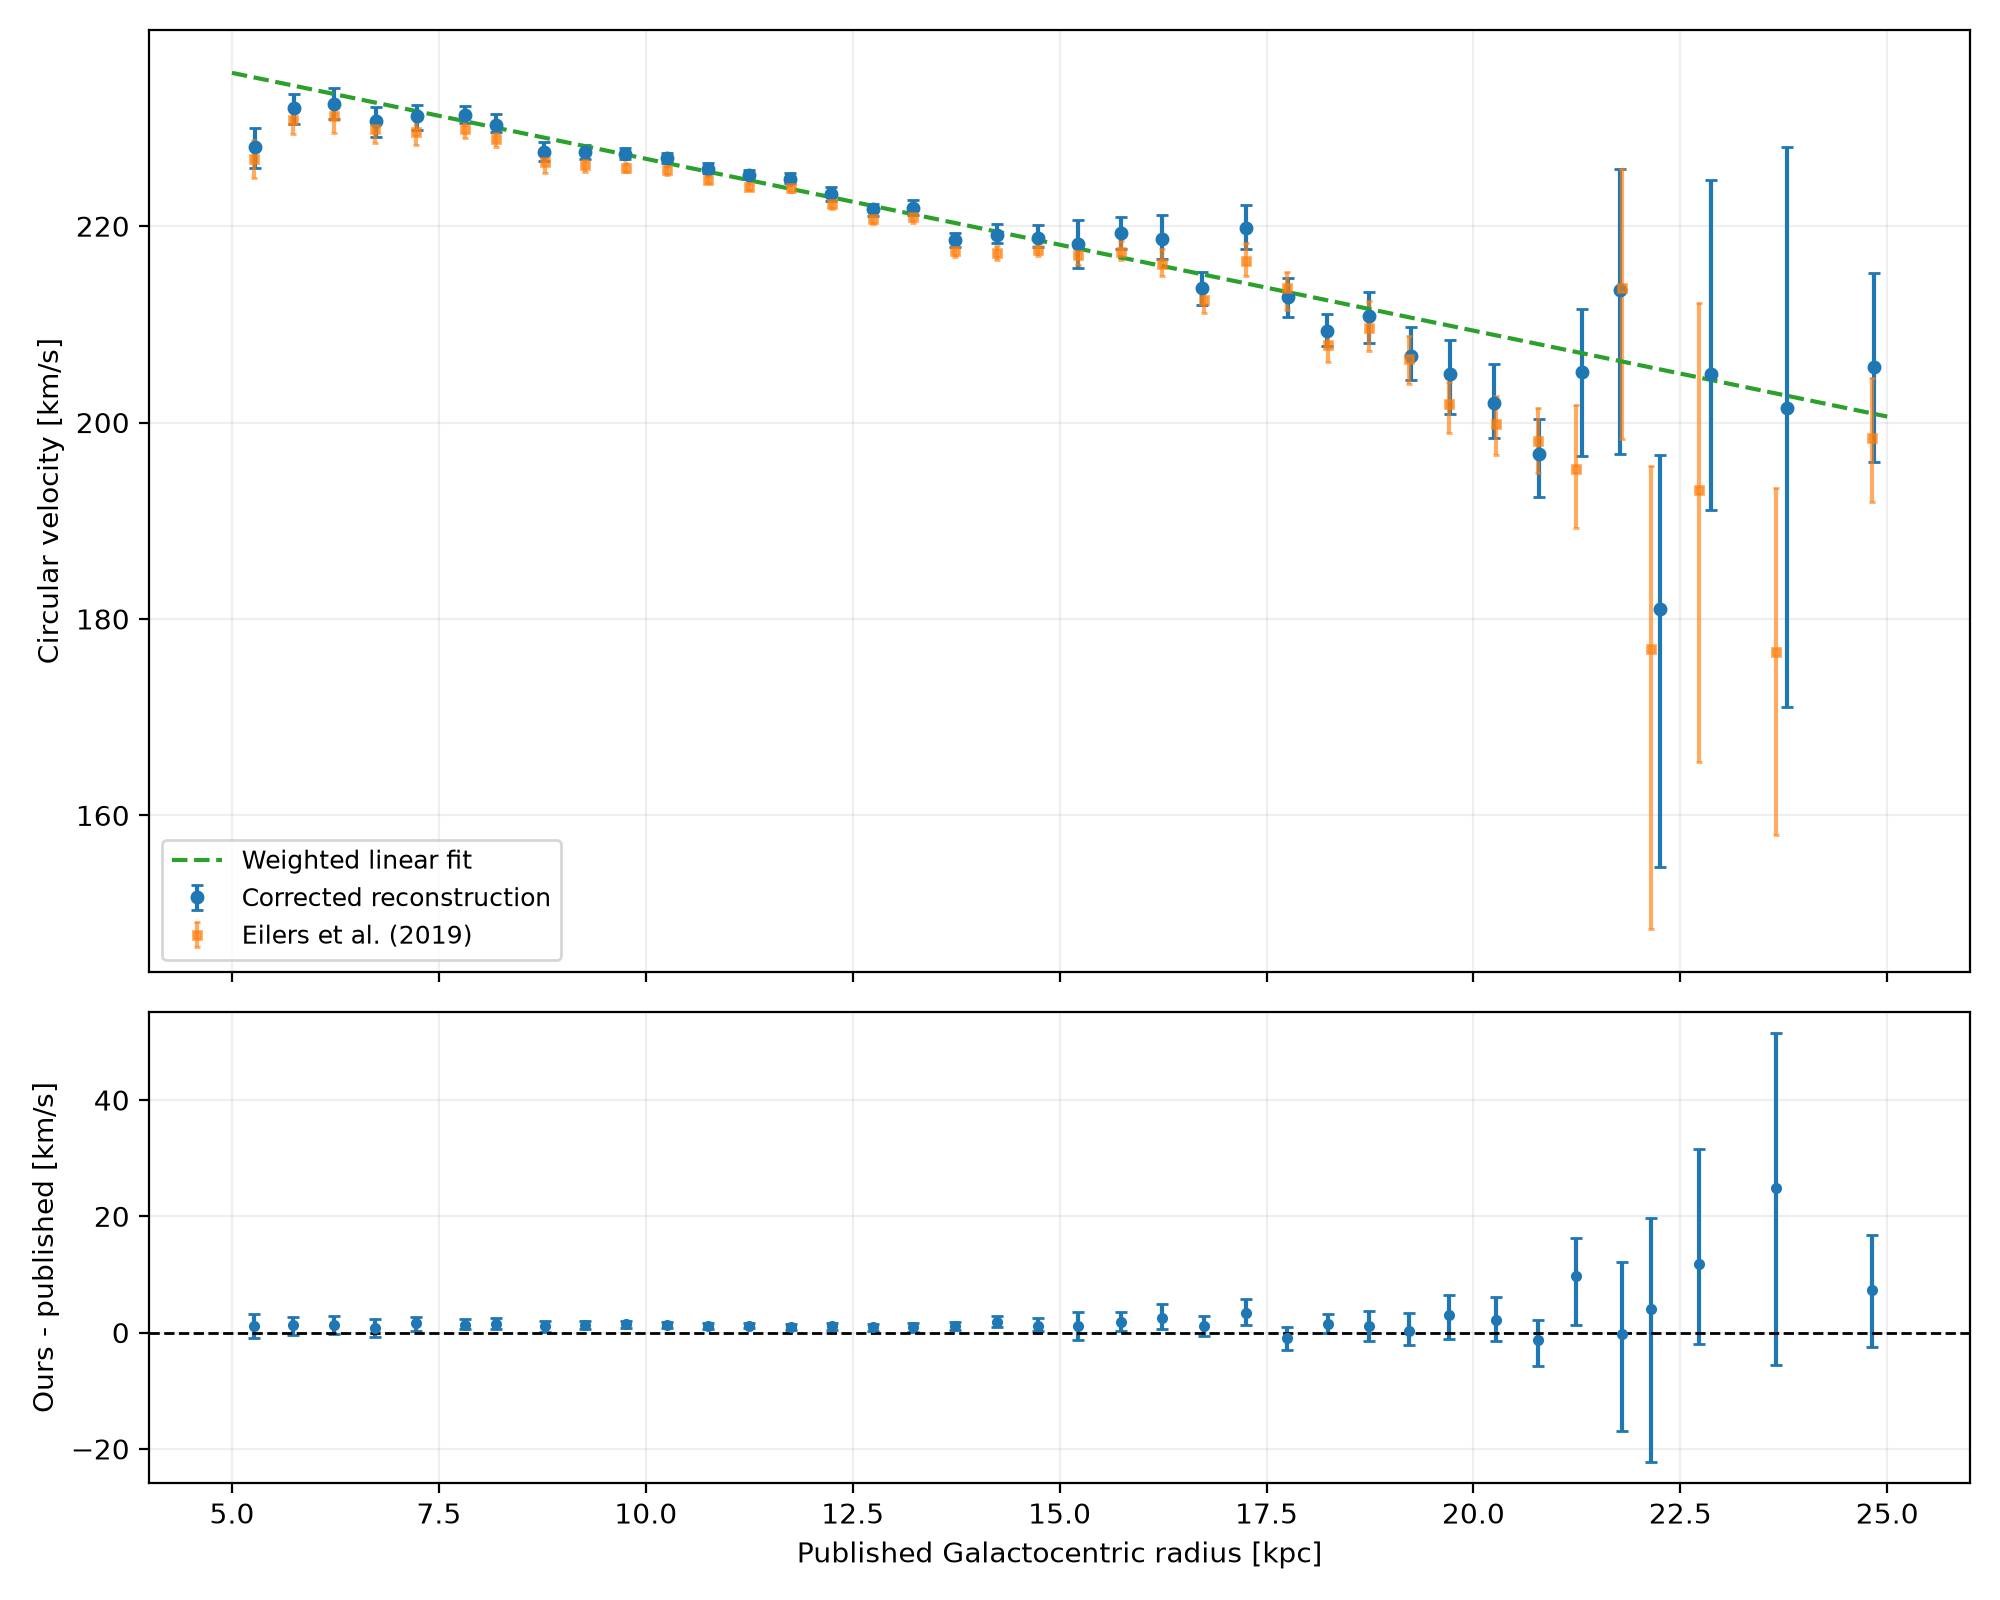

Figure 2 — three radial profiles


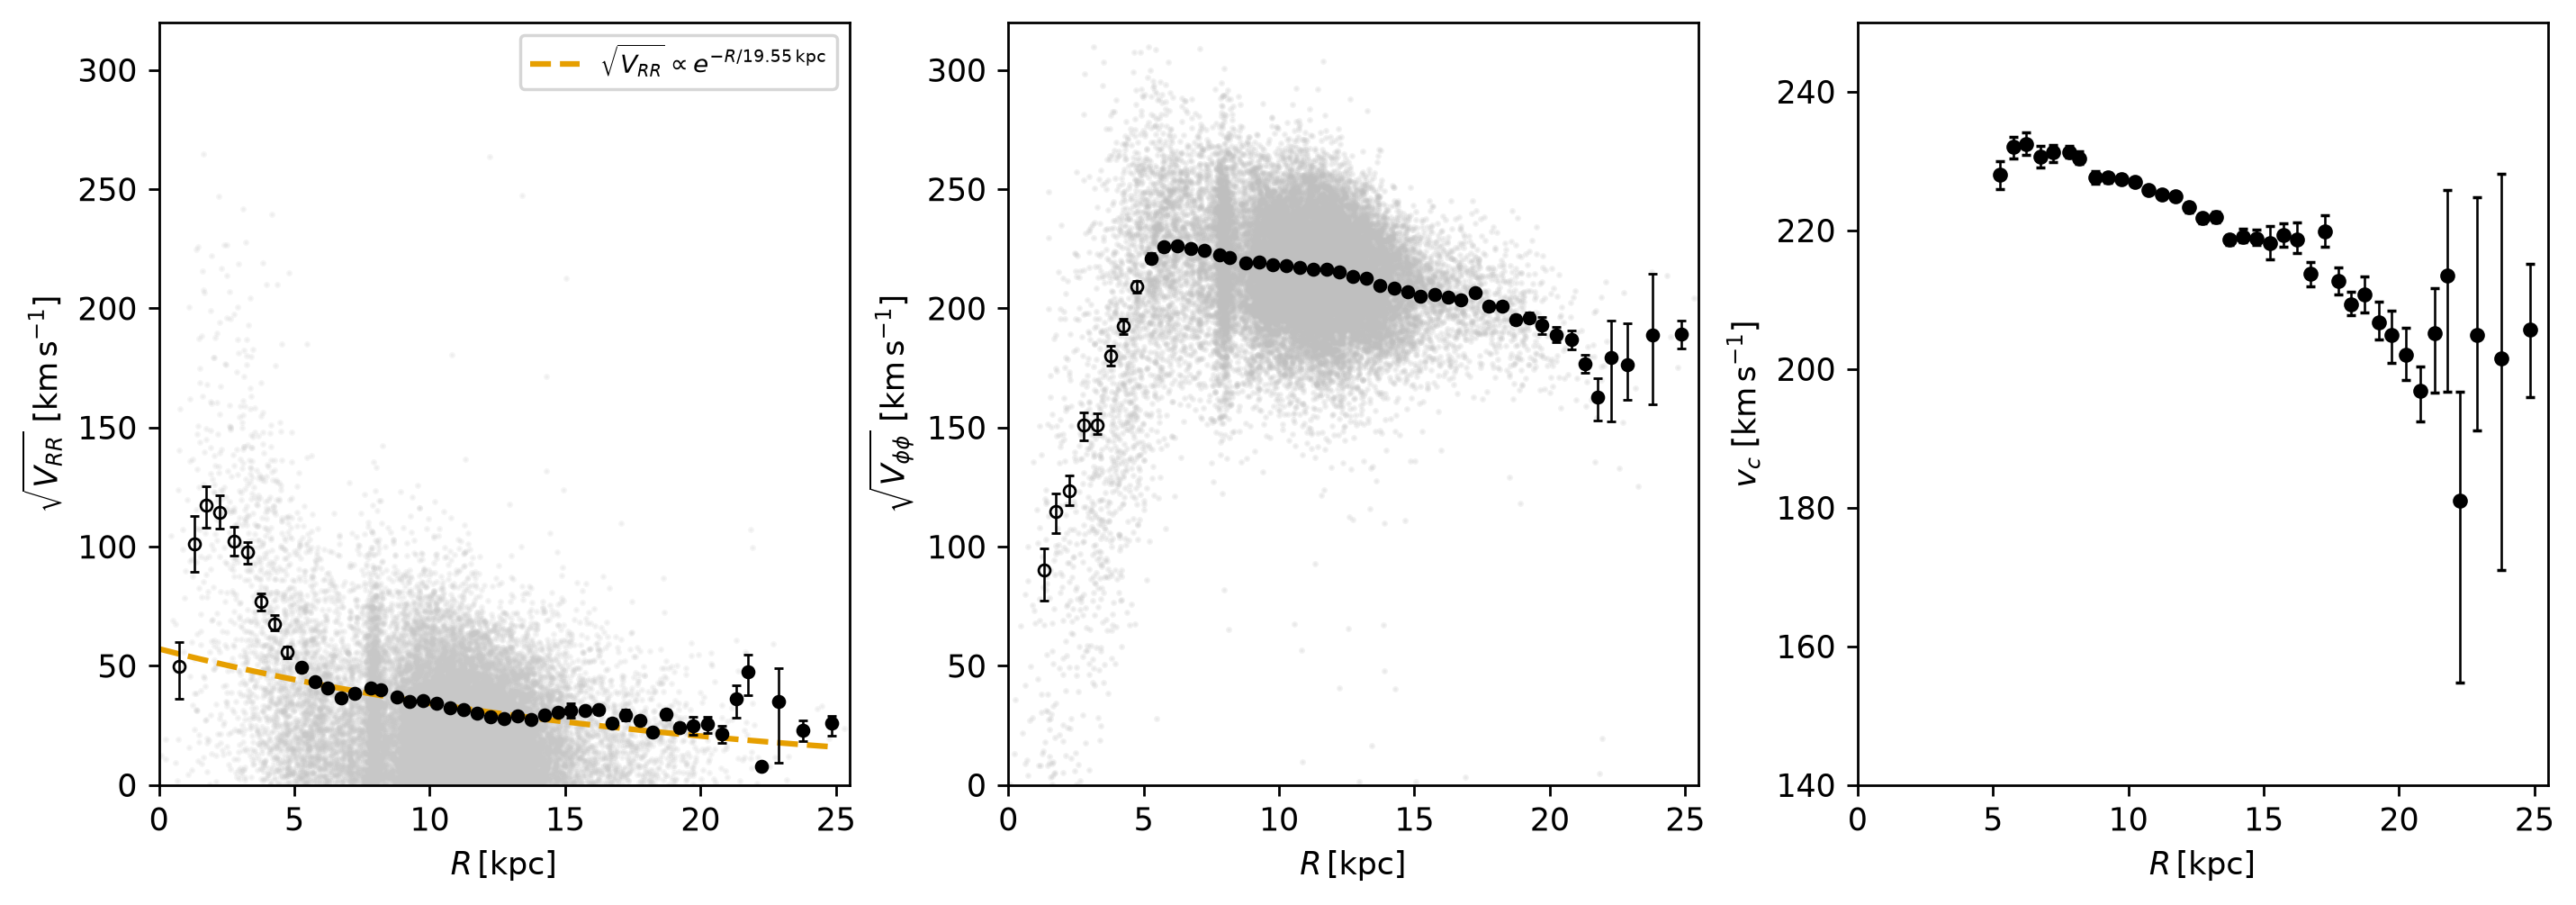

Figure 3 — three spatial maps


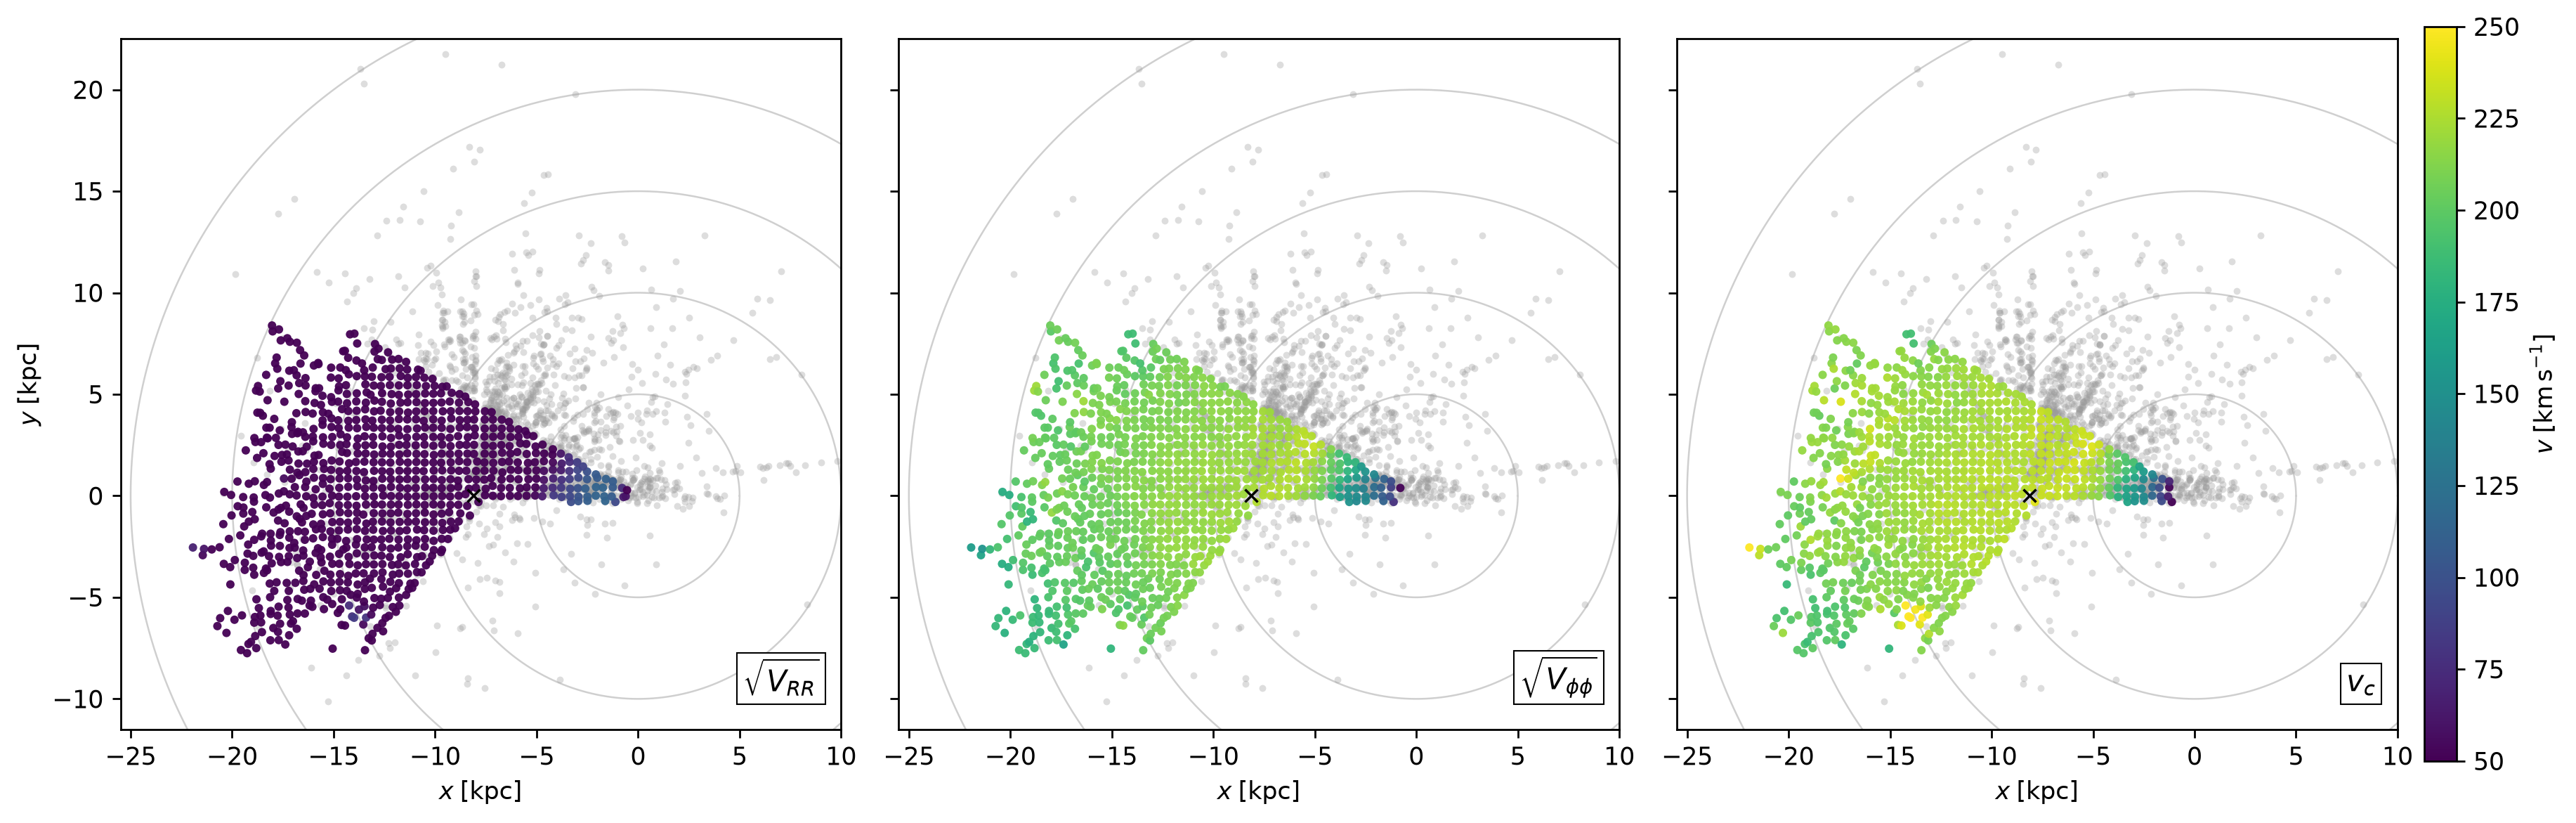

Figure 4 — controlled systematic sensitivities


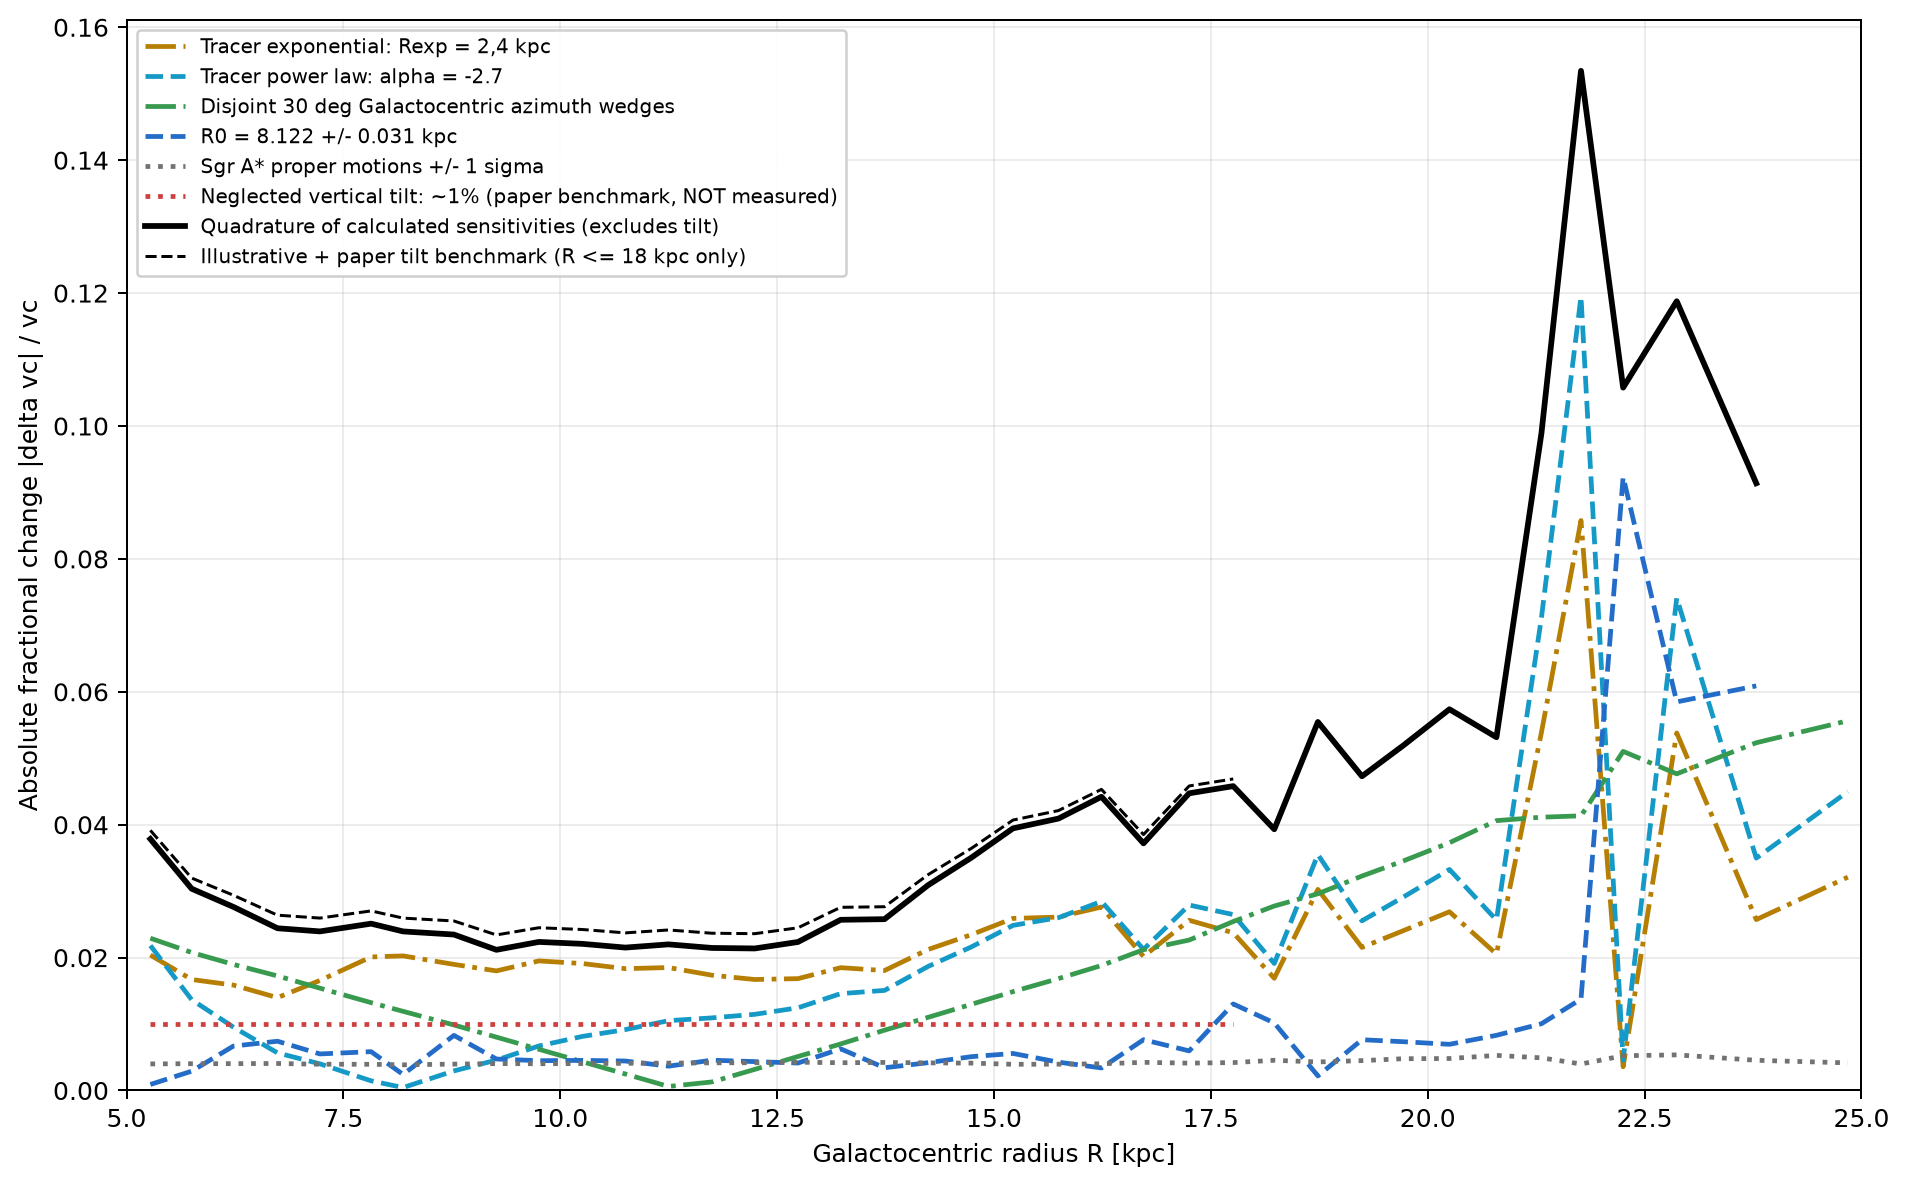

Figure 5 — fixed-baryon NFW decomposition


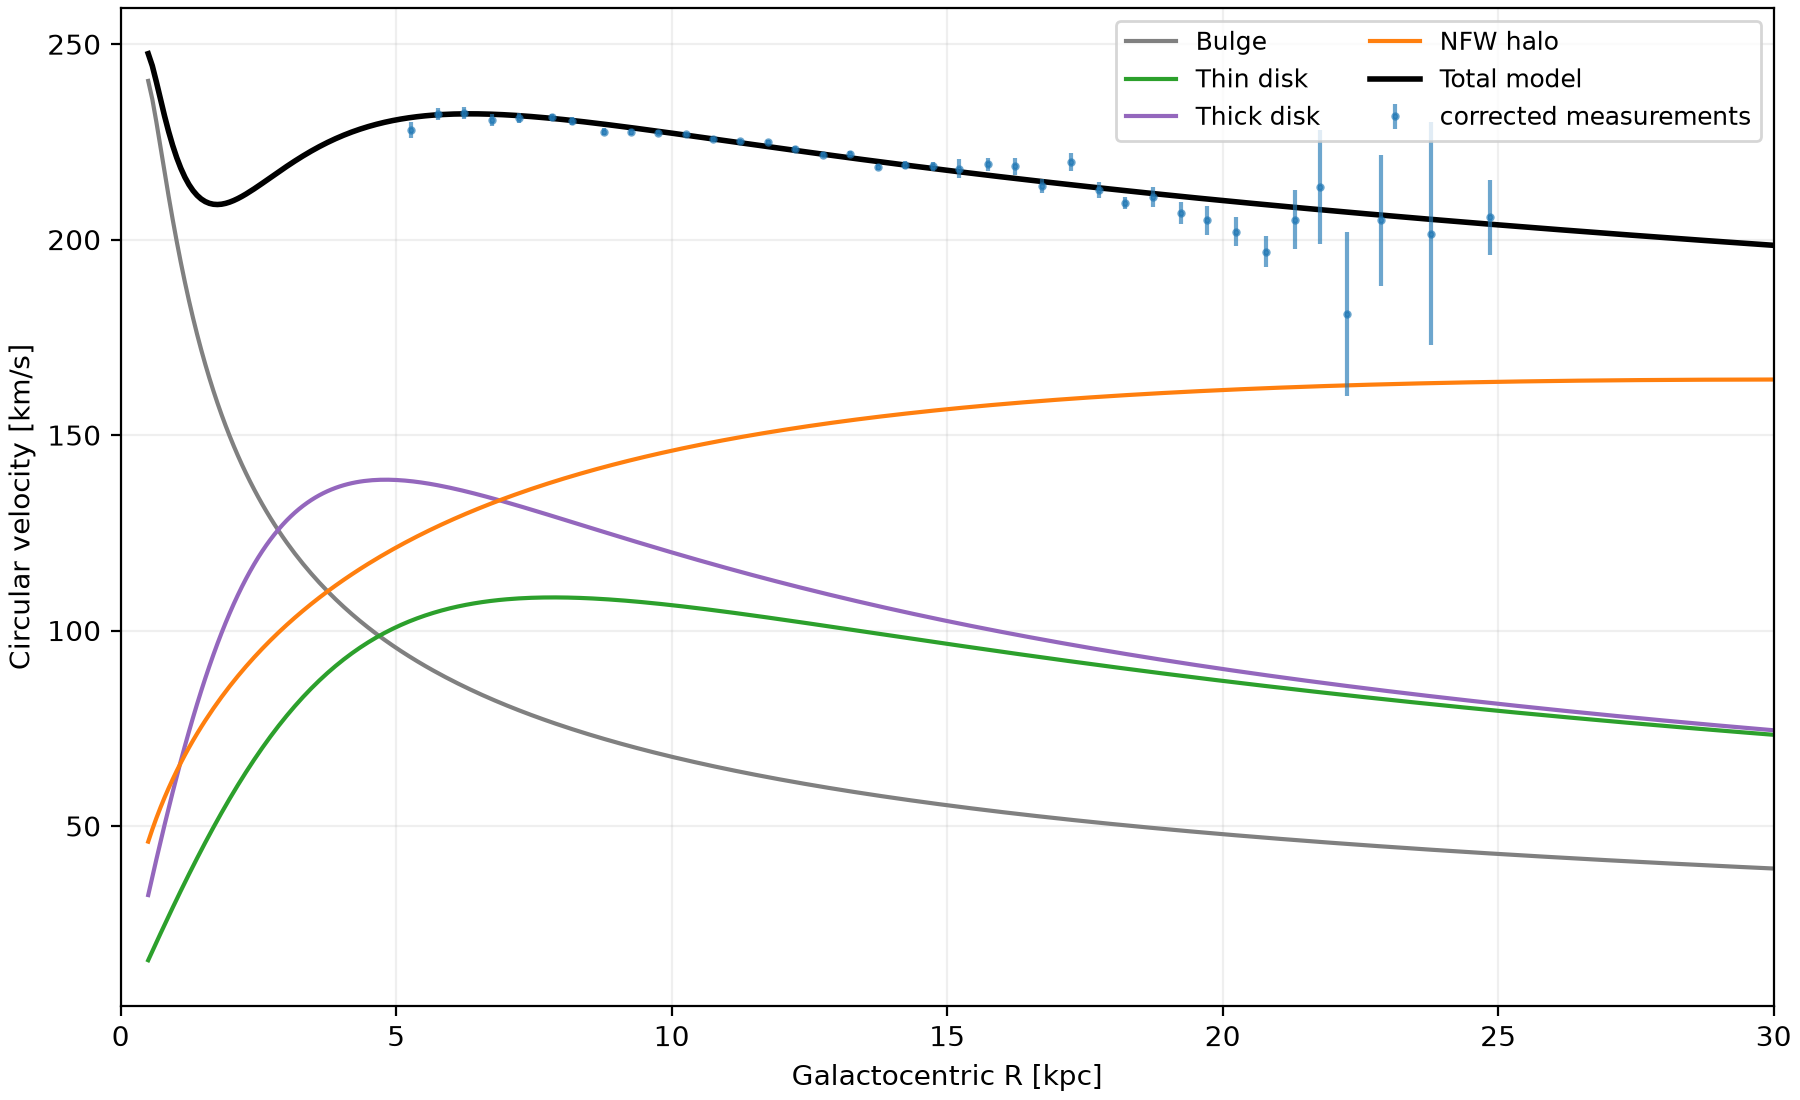

Halo posterior distributions


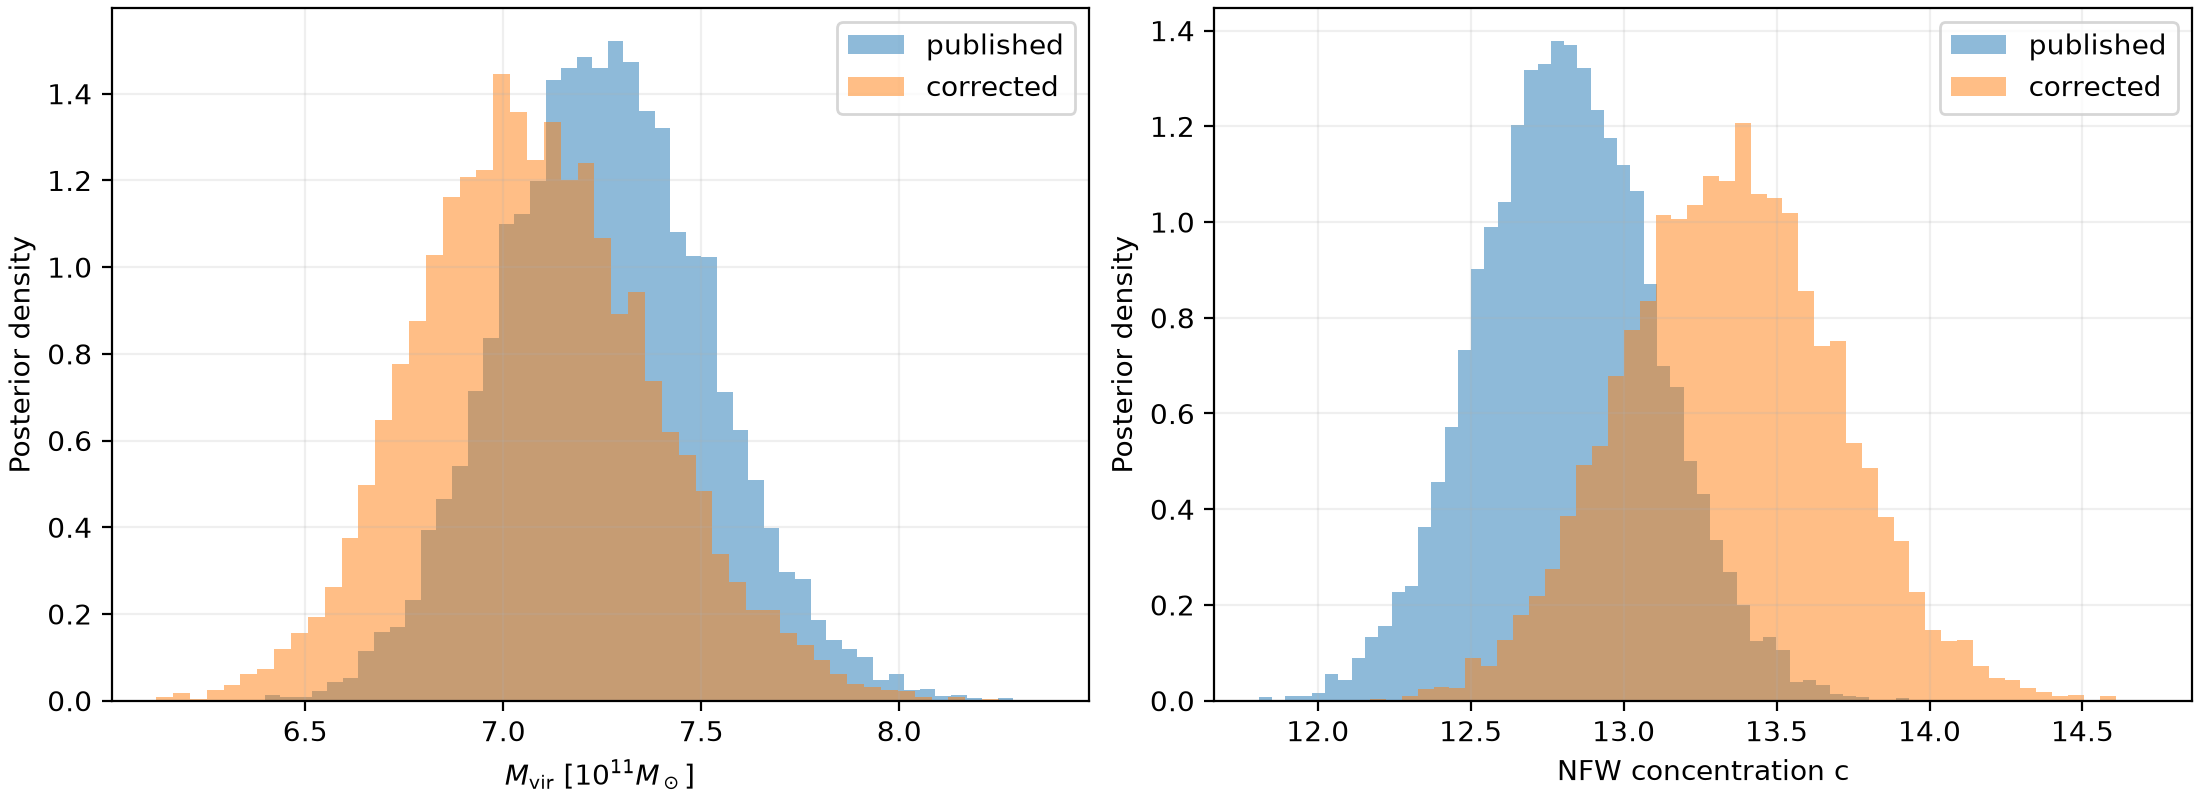

Mass–concentration degeneracy


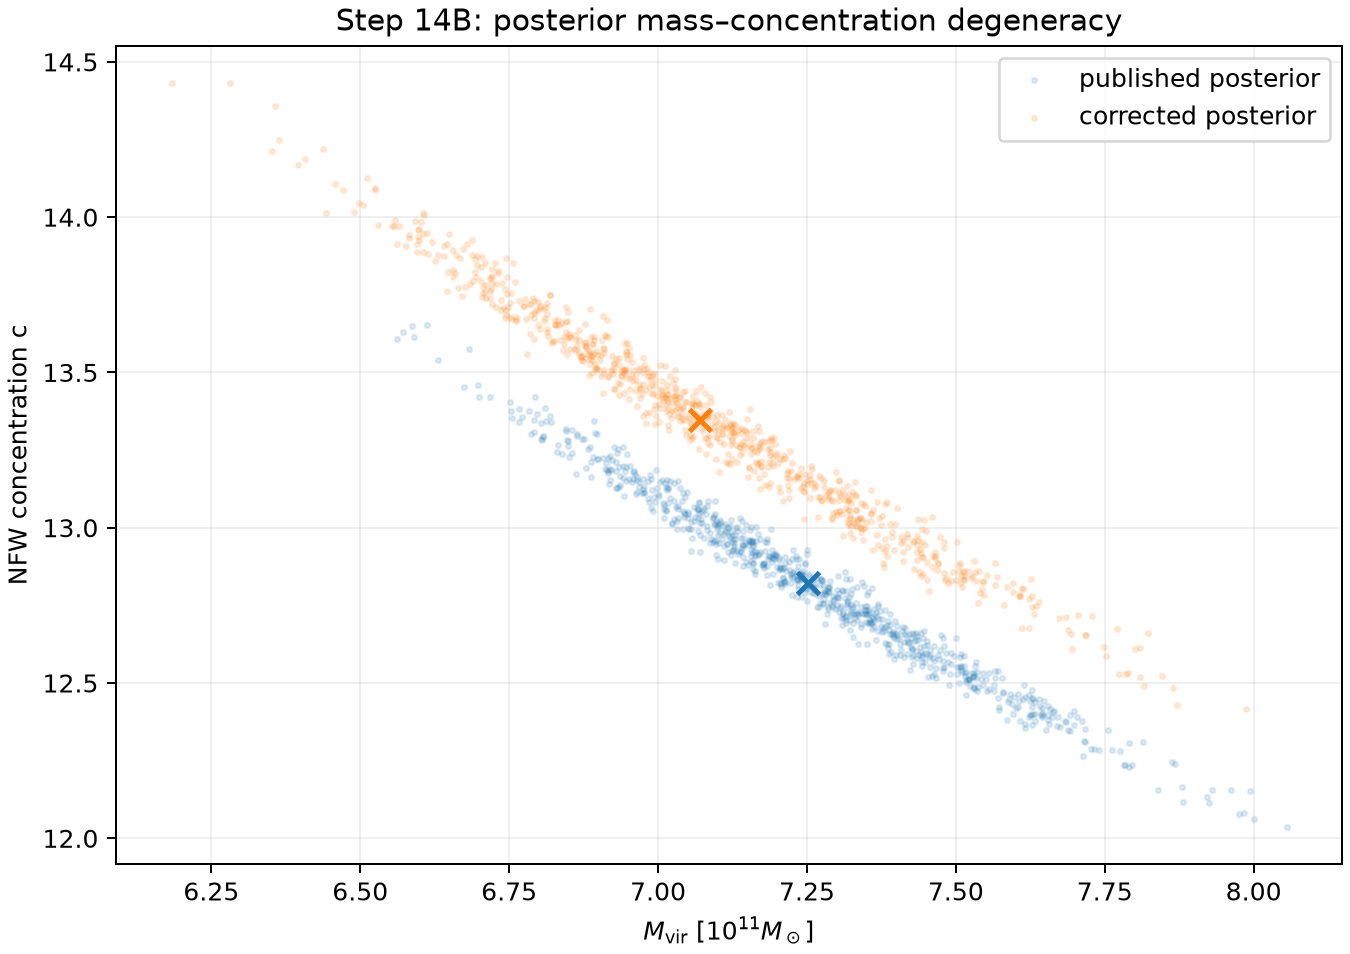

All outputs are in the run directory: /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5


In [22]:
# Inspect the regenerated baseline figures
for name, title in (
    ('step11_corrected_candidate_vs_table1.png', 'Figure 1 — rotation curve and residuals'),
    ('fig1_velocity_profiles_step12_corrected.png', 'Figure 2 — three radial profiles'),
    ('fig2_galactic_maps_step12_corrected.png', 'Figure 3 — three spatial maps'),
    ('step13_systematics_vs_paper_fig4.png', 'Figure 4 — controlled systematic sensitivities'),
    ('step14_corrected_halo_decomposition.png', 'Figure 5 — fixed-baryon NFW decomposition'),
    ('step14_posterior_distributions.png', 'Halo posterior distributions'),
    ('step14B_joint_posterior_correlation.png', 'Mass–concentration degeneracy'),
):
    path = PROJECT/'figures'/name
    if not path.is_file():
        raise FileNotFoundError(path)
    print(title)
    display(Image(filename=str(path), width=1250))
print('All outputs are in the run directory:', PROJECT)


In [23]:
# Align the selected stars and velocity tensors by 2MASS identifier
phase_path = PROJECT / "data/interim/phase_space_catalogue_step8A.csv"
tensor_path = PROJECT / "data/processed/eilers2019_kinematics_tensors.npz"
moment_path = PROJECT / (
    "data/processed/"
    "eilers2019_velocity_moments_step10_corrected_candidate.npz"
)

for path in (phase_path, tensor_path, moment_path):
    if not path.is_file():
        raise FileNotFoundError(path)

q_phase = pd.read_csv(phase_path, low_memory=False)
q_phase["2MASS_ID"] = q_phase["2MASS_ID"].astype(str).str.strip()

assert q_phase["2MASS_ID"].is_unique

with np.load(tensor_path, allow_pickle=False) as data:
    q_ids = data["target_ids"].astype(str)
    q_nominal = data["XS_cyl_true_n"].copy()
    q_mean = data["mean_XS_cyl_n"].copy()
    q_cov = data["var_XS_cyl_n"].copy()

assert len(q_ids) == 23010
assert len(np.unique(q_ids)) == len(q_ids)

# Explicit ID alignment: never assume CSV and NPZ row orders agree.
indexed = q_phase.set_index("2MASS_ID")
missing_ids = pd.Index(q_ids).difference(indexed.index)
assert len(missing_ids) == 0, missing_ids.tolist()[:10]

q_stars = indexed.loc[q_ids].reset_index()
assert np.array_equal(q_stars["2MASS_ID"].to_numpy(), q_ids)

with np.load(moment_path, allow_pickle=False) as data:
    q_edges = data["bin_edges"].copy()

print("Aligned selected stars:", len(q_stars))
print("Existing radial bins:", len(q_edges) - 1)


Aligned selected stars: 23010
Existing radial bins: 47


In [24]:
# Longitude signs, literal quadrants and sample counts
q_sky = SkyCoord(
    ra=pd.to_numeric(
        q_stars["SEL_RA_APOGEE_DEG"], errors="raise"
    ).to_numpy() * u.deg,
    dec=pd.to_numeric(
        q_stars["SEL_DEC_APOGEE_DEG"], errors="raise"
    ).to_numpy() * u.deg,
    frame="icrs",
)

q_longitude = q_sky.galactic.l.deg
q_latitude = q_sky.galactic.b.deg
q_signed_longitude = (q_longitude + 180.0) % 360.0 - 180.0

catalogue_l = pd.to_numeric(
    q_stars["SEL_GLON_DEG"], errors="coerce"
).to_numpy()

valid_l = np.isfinite(catalogue_l)
longitude_difference = (
    q_longitude[valid_l] - catalogue_l[valid_l] + 180.0
) % 360.0 - 180.0

print(
    "Maximum catalogue/coordinate longitude difference:",
    np.max(np.abs(longitude_difference)),
    "degrees",
)

# Strict conventional quadrants. Boundary stars are excluded.
q1 = (q_longitude > 0.0) & (q_longitude < 90.0)
q4 = (q_longitude > 270.0) & (q_longitude < 360.0)

# Also record the broader longitude-sign split mentioned by Joss.
positive_l = q_signed_longitude > 0.0
negative_l = q_signed_longitude < 0.0

q_radius = q_nominal[:, 0]
q_domain = (q_radius >= 5.0) & (q_radius <= 25.0)

q_summary = pd.DataFrame([
    {
        "sample": name,
        "N_selected": int(mask.sum()),
        "N_R5_to_25": int((mask & q_domain).sum()),
        "median_R_kpc": (
            float(np.median(q_radius[mask])) if mask.any() else np.nan
        ),
    }
    for name, mask in [
        ("Q1: 0 < l < 90", q1),
        ("Q4: 270 < l < 360", q4),
        ("All positive signed longitude", positive_l),
        ("All negative signed longitude", negative_l),
        ("Outside Q1 and Q4", ~(q1 | q4)),
    ]
])

display(q_summary)

q_summary.to_csv(
    PROJECT / "reports/q1_q4_sample_summary.csv",
    index=False,
)

print(
    "Positive-longitude stars outside Q1:",
    int((positive_l & ~q1).sum()),
)
print(
    "Negative-longitude stars outside Q4:",
    int((negative_l & ~q4).sum()),
)


Maximum catalogue/coordinate longitude difference: 0.00023780560852060262 degrees


,sample,N_selected,N_R5_to_25,median_R_kpc
0,Q1: 0 < l < 90,4804,3689,6.991753
1,Q4: 270 < l < 360,138,53,4.494433
2,All positive signed longitude,17001,15884,10.460946
3,All negative signed longitude,6009,5916,12.090359
4,Outside Q1 and Q4,18068,18058,11.576509


Positive-longitude stars outside Q1: 12197
Negative-longitude stars outside Q4: 5871


,bin_index,R_left_kpc,R_right_kpc,R_centre_kpc,N_Q1,N_Q4,both_at_least_3,both_at_least_30_diagnostic
9,9,5.000000,5.500000,5.250000,336,9,True,False
10,10,5.500000,6.000000,5.750000,370,17,True,False
11,11,6.000000,6.500000,6.250000,302,12,True,False
12,12,6.500000,7.000000,6.750000,292,10,True,False
13,13,7.000000,7.500000,7.250000,385,4,True,False
14,14,7.500000,8.000000,7.750000,1058,1,False,False
15,15,8.000000,8.500000,8.250000,789,0,False,False
16,16,8.500000,9.000000,8.750000,124,0,False,False
17,17,9.000000,9.500000,9.250000,33,0,False,False
18,18,9.500000,10.000000,9.750000,0,0,False,False


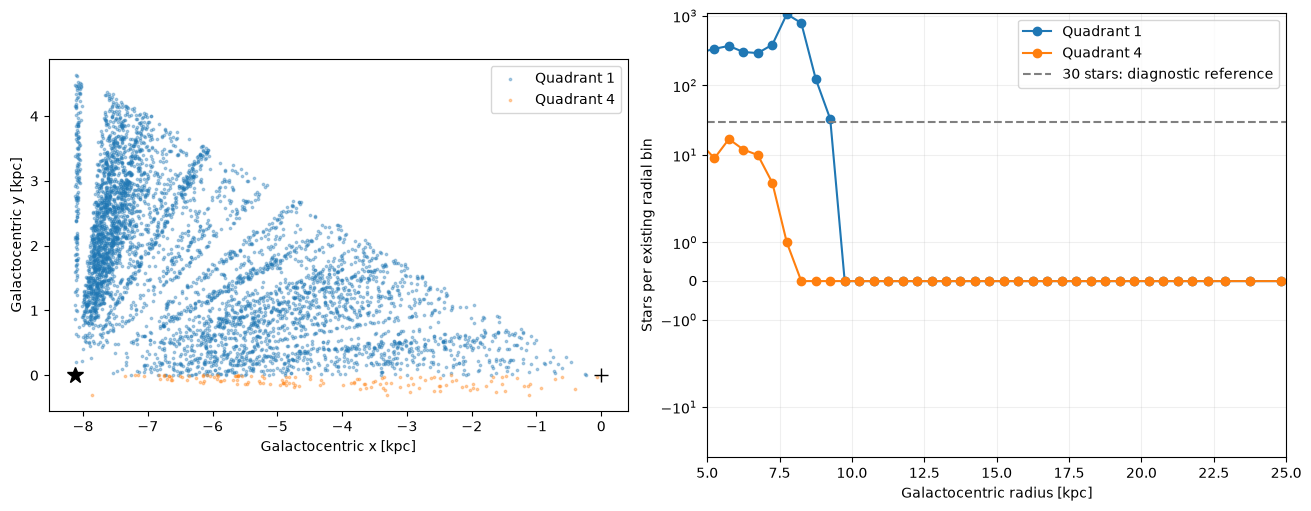

In [25]:
# Radial coverage by longitude and quadrant
q_bin_rows = []

for index, (left, right) in enumerate(
    zip(q_edges[:-1], q_edges[1:])
):
    in_bin = (q_radius >= left) & (q_radius < right)

    n1 = int((in_bin & q1).sum())
    n4 = int((in_bin & q4).sum())

    q_bin_rows.append({
        "bin_index": index,
        "R_left_kpc": left,
        "R_right_kpc": right,
        "R_centre_kpc": 0.5 * (left + right),
        "N_Q1": n1,
        "N_Q4": n4,
        "both_at_least_3": min(n1, n4) >= 3,
        "both_at_least_30_diagnostic": min(n1, n4) >= 30,
    })

q_coverage = pd.DataFrame(q_bin_rows)

q_coverage.to_csv(
    PROJECT / "results/q1_q4_radial_bin_coverage.csv",
    index=False,
)

display(
    q_coverage.loc[
        q_coverage["R_centre_kpc"].between(5, 25)
    ]
)

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), constrained_layout=True
)

for mask, label, colour in [
    (q1, "Quadrant 1", "tab:blue"),
    (q4, "Quadrant 4", "tab:orange"),
]:
    axes[0].scatter(
        q_nominal[mask, 0] * np.cos(q_nominal[mask, 1]),
        q_nominal[mask, 0] * np.sin(q_nominal[mask, 1]),
        s=3, alpha=0.35, color=colour, label=label,
    )

axes[0].plot(-8.122, 0, "*", color="black", markersize=12)
axes[0].plot(0, 0, "+", color="black", markersize=10)
axes[0].set(
    xlabel="Galactocentric x [kpc]",
    ylabel="Galactocentric y [kpc]",
)
axes[0].set_aspect("equal", adjustable="box")
axes[0].legend()

for column, label, colour in [
    ("N_Q1", "Quadrant 1", "tab:blue"),
    ("N_Q4", "Quadrant 4", "tab:orange"),
]:
    axes[1].plot(
        q_coverage["R_centre_kpc"],
        q_coverage[column],
        "o-", color=colour, label=label,
    )

axes[1].axhline(
    30, color="grey", linestyle="--",
    label="30 stars: diagnostic reference",
)
axes[1].set(
    xlabel="Galactocentric radius [kpc]",
    ylabel="Stars per existing radial bin",
    xlim=(5, 25),
    yscale="symlog",
)
axes[1].legend()
axes[1].grid(alpha=0.2)

save_figure_pair(fig, "q1_q4_sample_coverage")


In [26]:
# Export memberships and proper-motion checks
q_membership = pd.DataFrame({
    "2MASS_ID": q_ids,
    "l_deg": q_longitude,
    "l_signed_deg": q_signed_longitude,
    "b_deg": q_latitude,
    "R_nominal_kpc": q_radius,
    "quadrant": np.where(q1, "Q1", np.where(q4, "Q4", "OTHER")),
    "in_R5_to_25": q_domain,
})

q_membership.to_csv(
    PROJECT / "results/q1_q4_stellar_membership.csv",
    index=False,
)

q_pm_rows = []

for mask, label in [(q1, "Q1"), (q4, "Q4")]:
    row = {"quadrant": label, "N": int(mask.sum())}

    for column in [
        "SEL_GAIA_PMRA_MAS_YR",
        "SEL_GAIA_PMDEC_MAS_YR",
        "SEL_GAIA_PMRA_ERR_MAS_YR",
        "SEL_GAIA_PMDEC_ERR_MAS_YR",
    ]:
        values = pd.to_numeric(
            q_stars.loc[mask, column], errors="coerce"
        ).to_numpy()

        row[f"{column}_nonfinite"] = int(
            (~np.isfinite(values)).sum()
        )

    q_pm_rows.append(row)

q_pm_check = pd.DataFrame(q_pm_rows)
display(q_pm_check)

q_pm_check.to_csv(
    PROJECT / "reports/q1_q4_proper_motion_input_check.csv",
    index=False,
)

print("Quadrant preparation complete.")
print("Existing DR2-based kinematics and spectrophotometric distances retained.")
print("Release provenance comes from the audited source catalogue;")
print("finite proper-motion columns alone do not establish a Gaia release.")


,quadrant,N,SEL_GAIA_PMRA_MAS_YR_nonfinite,SEL_GAIA_PMDEC_MAS_YR_nonfinite,SEL_GAIA_PMRA_ERR_MAS_YR_nonfinite,SEL_GAIA_PMDEC_ERR_MAS_YR_nonfinite
0,Q1,4804,0,0,0,0
1,Q4,138,0,0,0,0


Quadrant preparation complete.
Existing DR2-based kinematics and spectrophotometric distances retained.
Release provenance comes from the audited source catalogue;
finite proper-motion columns alone do not establish a Gaia release.


In [27]:
# Select radial bins with common longitude coverage
ls_masks = {
    "Lpos": q_signed_longitude > 0,
    "Lneg": q_signed_longitude < 0,
}

assert not np.any(ls_masks["Lpos"] & ls_masks["Lneg"])

ls_radius = q_nominal[:, 0]

# Compare longitude signs calculated from coordinates with catalogue signs.
ls_catalogue = (
    pd.to_numeric(q_stars["SEL_GLON_DEG"]).to_numpy() + 180
) % 360 - 180

print(
    "Catalogue/coordinate longitude-sign disagreements:",
    np.count_nonzero(
        np.sign(ls_catalogue) != np.sign(q_signed_longitude)
    ),
)

# Check membership equivalence with the earlier Galactocentric split.
ls_phi = np.arctan2(
    np.sin(q_nominal[:, 1] - np.pi),
    np.cos(q_nominal[:, 1] - np.pi),
)

print(
    "Positive-longitude / earlier negative-azimuth-half differences:",
    np.count_nonzero(ls_masks["Lpos"] != (ls_phi < 0)),
)

for side, mask in ls_masks.items():
    print(side, "selected stars:", int(mask.sum()))

# Coverage criteria set before examining the velocity differences.
LS_MIN_N = 30
LS_MIN_R = 5.0
LS_MAX_R = 18.0

ls_rows = []

for k, (left, right) in enumerate(
    zip(q_edges[:-1], q_edges[1:])
):
    in_bin = (ls_radius >= left) & (ls_radius < right)

    ls_rows.append({
        "bin_index": k,
        "R_left": left,
        "R_right": right,
        "R_eval": 0.5 * (left + right),
        "N_Lpos": int((in_bin & ls_masks["Lpos"]).sum()),
        "N_Lneg": int((in_bin & ls_masks["Lneg"]).sum()),
    })

ls_coverage = pd.DataFrame(ls_rows)

ls_coverage["use"] = (
    ls_coverage["R_left"].ge(LS_MIN_R)
    & ls_coverage["R_right"].le(LS_MAX_R + 1e-9)
    & ls_coverage["N_Lpos"].ge(LS_MIN_N)
    & ls_coverage["N_Lneg"].ge(LS_MIN_N)
)

ls_common = ls_coverage.loc[
    ls_coverage["use"]
].reset_index(drop=True)

assert len(ls_common) >= 8, "Insufficient common radial coverage."

# Both samples are evaluated at the same radial-bin centres.
ls_r = ls_common["R_eval"].to_numpy()

ls_coverage.to_csv(
    PROJECT / "results/longitude_sign_common_coverage.csv",
    index=False,
)

display(ls_common)

print(
    "Common comparison interval:",
    ls_common["R_left"].min(),
    "to",
    ls_common["R_right"].max(),
    "kpc",
)


Catalogue/coordinate longitude-sign disagreements: 0
Positive-longitude / earlier negative-azimuth-half differences: 0
Lpos selected stars: 17001
Lneg selected stars: 6009


,bin_index,R_left,R_right,R_eval,N_Lpos,N_Lneg,use
0,16,8.5,9.0,8.75,591,58,True
1,17,9.0,9.5,9.25,916,239,True
2,18,9.5,10.0,9.75,1116,321,True
3,19,10.0,10.5,10.25,1231,451,True
4,20,10.5,11.0,10.75,1385,519,True
5,21,11.0,11.5,11.25,1390,573,True
6,22,11.5,12.0,11.75,1255,597,True
7,23,12.0,12.5,12.25,1117,592,True
8,24,12.5,13.0,12.75,881,534,True
9,25,13.0,13.5,13.25,727,447,True


Common comparison interval: 8.5 to 18.0 kpc


In [28]:
# Calculate longitude-specific velocity moments
LS_NBOOT = 1000
LS_SEED = 20261111

ls_rng = np.random.default_rng(LS_SEED)
ls_data = {}
ls_diagnostics = []

for side, side_mask in ls_masks.items():
    points = []
    draws = []

    for row in ls_common.itertuples(index=False):
        selected = (
            side_mask
            & (ls_radius >= row.R_left)
            & (ls_radius < row.R_right)
        )

        velocity = q_mean[selected, 3:6]
        covariance = q_cov[selected]

        # Uncentred, measurement-noise-corrected second moments.
        values = np.column_stack((
            velocity[:, 0]**2 - covariance[:, 0, 0],
            velocity[:, 1]**2 - covariance[:, 1, 1],
            velocity[:, 0],
            velocity[:, 1],
        ))

        assert np.isfinite(values).all()

        points.append(values.mean(axis=0))

        indices = ls_rng.integers(
            0,
            len(velocity),
            size=(LS_NBOOT, len(velocity)),
        )

        draws.append(values[indices].mean(axis=1))

        ls_diagnostics.append({
            "side": side,
            "R_eval": row.R_eval,
            "N": len(velocity),
            "R_mean": ls_radius[selected].mean(),
            "median_abs_z": np.median(
                np.abs(q_nominal[selected, 2])
            ),
            "median_distance": pd.to_numeric(
                q_stars.loc[selected, "STEP8A_DISTANCE_KPC"]
            ).median(),
            "median_abs_l": np.median(
                np.abs(q_signed_longitude[selected])
            ),
            "median_alpha": pd.to_numeric(
                q_stars.loc[selected, "SEL_ALPHA_M"]
            ).median(),
        })

    ls_data[side] = {
        "point": np.asarray(points),
        "boot": np.asarray(draws),
    }

ls_diagnostics = pd.DataFrame(ls_diagnostics)

ls_diagnostics.to_csv(
    PROJECT / "results/longitude_sign_bin_population_diagnostics.csv",
    index=False,
)

print("Bootstrap calculations complete.")
print("Moment columns: Vrr, Vpp, mean vR, mean vphi.")
print("Bootstrap realizations per side:", LS_NBOOT)


Bootstrap calculations complete.
Moment columns: Vrr, Vpp, mean vR, mean vphi.
Bootstrap realizations per side: 1000


In [29]:
# Estimate the Jeans curves with paired stellar bootstrap
LS_TRACER_SCALE = 3.0


def ls_exponential(radius, amplitude, scale):
    return amplitude * np.exp(-radius / scale)


def ls_scale_fit(rr, sigma, guess=(60.0, 21.0)):
    good = (
        (rr > 0)
        & np.isfinite(rr)
        & np.isfinite(sigma)
        & (sigma > 0)
    )

    if good.sum() < 8:
        raise ValueError("Fewer than eight valid scale-fit bins.")

    parameters, _ = curve_fit(
        ls_exponential,
        ls_r[good],
        np.sqrt(rr[good]),
        sigma=sigma[good],
        p0=guess,
        bounds=([1e-6, 1.0], [1e5, 1000.0]),
        maxfev=10000,
    )

    return parameters


for side, data in ls_data.items():
    rr, pp = data["point"][:, :2].T
    boot = data["boot"]

    assert (rr > 0).all() and (pp > 0).all()

    root_rr = np.where(
        boot[:, :, 0] > 0,
        np.sqrt(np.maximum(boot[:, :, 0], 0)),
        np.nan,
    )

    rr_quantiles = np.nanpercentile(
        root_rr, [16, 84], axis=1
    )
    sigma_rr = (rr_quantiles[1] - rr_quantiles[0]) / 2

    amplitude, scale = ls_scale_fit(rr, sigma_rr)

    vc_squared = pp - rr * (
        1
        - ls_r / LS_TRACER_SCALE
        - 2 * ls_r / scale
    )

    assert (vc_squared > 0).all()

    vc_boot = np.full(
        (len(ls_r), LS_NBOOT), np.nan
    )
    scale_boot = np.full(LS_NBOOT, np.nan)

    for j in range(LS_NBOOT):
        try:
            _, scale_boot[j] = ls_scale_fit(
                boot[:, j, 0],
                sigma_rr,
                guess=(amplitude, scale),
            )

            boot_vc_squared = (
                boot[:, j, 1]
                - boot[:, j, 0] * (
                    1
                    - ls_r / LS_TRACER_SCALE
                    - 2 * ls_r / scale_boot[j]
                )
            )

            valid = (
                (boot[:, j, 0] > 0)
                & (boot[:, j, 1] > 0)
                & (boot_vc_squared > 0)
            )

            vc_boot[valid, j] = np.sqrt(
                boot_vc_squared[valid]
            )

        except (ValueError, RuntimeError):
            continue

    valid_fraction = np.isfinite(vc_boot).mean(axis=1)

    print(
        side,
        "Rprime =", round(scale, 4), "kpc;",
        "minimum valid bootstrap fraction =",
        valid_fraction.min(),
    )

    assert valid_fraction.min() >= 0.95, (
        "Too many invalid bootstrap draws; stop and inspect."
    )
    assert np.isfinite(scale_boot).mean() >= 0.95

    bound_hits = (
        np.isfinite(scale_boot)
        & ((scale_boot < 1.01) | (scale_boot > 999.0))
    )

    print("Scale-fit bound hits:", int(bound_hits.sum()))

    assert bound_hits.sum() < 0.05 * LS_NBOOT, (
        "Scale fit is poorly constrained at its parameter bounds."
    )

    data.update({
        "scale": scale,
        "scale_boot": scale_boot,
        "vc": np.sqrt(vc_squared),
        "vc_boot": vc_boot,
    })

print("Both joint-bootstrap Jeans estimates complete.")


Lpos Rprime = 22.9261 kpc; minimum valid bootstrap fraction = 1.0
Scale-fit bound hits: 0
Lneg Rprime = 22.9596 kpc; minimum valid bootstrap fraction = 1.0
Scale-fit bound hits: 0
Both joint-bootstrap Jeans estimates complete.


In [30]:
# Calculate longitude contrasts and fitted slopes
ls_delta = (
    ls_data["Lpos"]["vc"] - ls_data["Lneg"]["vc"]
)

ls_delta_boot = (
    ls_data["Lpos"]["vc_boot"]
    - ls_data["Lneg"]["vc_boot"]
)

ls_curve = ls_common[[
    "bin_index", "R_left", "R_right", "R_eval",
    "N_Lpos", "N_Lneg",
]].copy()

for side, data in ls_data.items():
    ls_curve[f"vc_{side}"] = data["vc"]

    quantiles = np.nanpercentile(
        data["vc_boot"], [16, 50, 84], axis=1
    )

    for label, values in zip(
        ("p16", "p50", "p84"), quantiles
    ):
        ls_curve[f"vc_{side}_{label}"] = values

    ls_curve[f"mean_vR_{side}"] = data["point"][:, 2]
    ls_curve[f"mean_vphi_{side}"] = data["point"][:, 3]

ls_dq = np.nanpercentile(
    ls_delta_boot, [16, 50, 84], axis=1
)

ls_curve["delta_vc_Lpos_minus_Lneg"] = ls_delta

for label, values in zip(
    ("p16", "p50", "p84"), ls_dq
):
    ls_curve[f"delta_vc_{label}"] = values

ls_curve.to_csv(
    PROJECT / "results/longitude_sign_rotation_curve_comparison.csv",
    index=False,
)

LS_PIVOT = 12.0

ls_design = np.column_stack((
    np.ones(len(ls_r)),
    ls_r - LS_PIVOT,
))

ls_summary_rows = []

for side, data in ls_data.items():
    quantiles = np.nanpercentile(
        data["vc_boot"], [16, 84], axis=1
    )
    sigma = (quantiles[1] - quantiles[0]) / 2

    assert np.all(np.isfinite(sigma) & (sigma > 0))

    weighted_design = ls_design / sigma[:, None]

    projection = np.linalg.solve(
        weighted_design.T @ weighted_design,
        ls_design.T / sigma[None, :]**2,
    )

    data["coef"] = projection @ data["vc"]

    complete = np.isfinite(
        data["vc_boot"]
    ).all(axis=0)

    assert complete.mean() >= 0.95, (
        "Too few complete bootstrap realizations for curve fits."
    )

    data["coef_boot"] = np.full((2, LS_NBOOT), np.nan)

    data["coef_boot"][:, complete] = (
        projection @ data["vc_boot"][:, complete]
    )

    parameters = [
        (
            "Rprime_kpc",
            data["scale"],
            data["scale_boot"],
        ),
        (
            "vc_at_12_kpc",
            data["coef"][0],
            data["coef_boot"][0],
        ),
        (
            "slope_kms_per_kpc",
            data["coef"][1],
            data["coef_boot"][1],
        ),
    ]

    for name, point, draws in parameters:
        quantiles = np.nanpercentile(draws, [16, 50, 84])

        ls_summary_rows.append({
            "sample": side,
            "quantity": name,
            "point": point,
            "p16": quantiles[0],
            "p50": quantiles[1],
            "p84": quantiles[2],
        })

for k, name in enumerate([
    "delta_vc_at_12_kpc",
    "delta_slope_kms_per_kpc",
]):
    draws = (
        ls_data["Lpos"]["coef_boot"][k]
        - ls_data["Lneg"]["coef_boot"][k]
    )

    quantiles = np.nanpercentile(draws, [16, 50, 84])

    ls_summary_rows.append({
        "sample": "Lpos_minus_Lneg",
        "quantity": name,
        "point": (
            ls_data["Lpos"]["coef"][k]
            - ls_data["Lneg"]["coef"][k]
        ),
        "p16": quantiles[0],
        "p50": quantiles[1],
        "p84": quantiles[2],
    })

ls_summary = pd.DataFrame(ls_summary_rows)

ls_summary.to_csv(
    PROJECT / "results/longitude_sign_fit_summary.csv",
    index=False,
)

np.savez_compressed(
    PROJECT / "results/longitude_sign_joint_bootstrap.npz",
    R=ls_r,
    vc_Lpos=ls_data["Lpos"]["vc"],
    vc_Lneg=ls_data["Lneg"]["vc"],
    boot_vc_Lpos=ls_data["Lpos"]["vc_boot"],
    boot_vc_Lneg=ls_data["Lneg"]["vc_boot"],
    delta_boot=ls_delta_boot,
    scale_boot_Lpos=ls_data["Lpos"]["scale_boot"],
    scale_boot_Lneg=ls_data["Lneg"]["scale_boot"],
    seed=LS_SEED,
    n_boot=LS_NBOOT,
    tracer_scale=LS_TRACER_SCALE,
    pivot_radius=LS_PIVOT,
)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 180,
):
    display(ls_summary)
    display(ls_curve)


,sample,quantity,point,p16,p50,p84
0,Lpos,Rprime_kpc,22.926095,21.027662,22.761328,25.035531
1,Lpos,vc_at_12_kpc,222.937534,222.696886,222.948772,223.216602
2,Lpos,slope_kms_per_kpc,-1.478187,-1.594707,-1.479516,-1.364632
3,Lneg,Rprime_kpc,22.959610,19.953521,22.808528,26.105774
4,Lneg,vc_at_12_kpc,223.748289,223.363985,223.788312,224.236089
5,Lneg,slope_kms_per_kpc,-2.278976,-2.438775,-2.290389,-2.145059
6,Lpos_minus_Lneg,delta_vc_at_12_kpc,-0.810755,-1.324089,-0.827098,-0.346471
7,Lpos_minus_Lneg,delta_slope_kms_per_kpc,0.800789,0.633467,0.809954,0.997647


,bin_index,R_left,R_right,R_eval,N_Lpos,N_Lneg,vc_Lpos,vc_Lpos_p16,vc_Lpos_p50,vc_Lpos_p84,mean_vR_Lpos,mean_vphi_Lpos,vc_Lneg,vc_Lneg_p16,vc_Lneg_p50,vc_Lneg_p84,mean_vR_Lneg,mean_vphi_Lneg,delta_vc_Lpos_minus_Lneg,delta_vc_p16,delta_vc_p50,delta_vc_p84
0,16,8.5,9.0,8.75,591,58,227.083349,226.068003,227.104241,228.148383,-5.181308,217.699683,227.834075,224.379071,227.845389,231.265209,-8.347222,217.064513,-0.750726,-4.345595,-0.810629,2.960401
1,17,9.0,9.5,9.25,916,239,226.483462,225.677965,226.484618,227.295522,-3.963198,217.902560,229.857727,228.374389,229.827185,231.514391,-4.222323,219.475964,-3.374266,-5.239645,-3.381115,-1.568227
2,18,9.5,10.0,9.75,1116,321,227.198244,226.496185,227.225176,227.947707,-6.307887,216.991389,226.010378,224.902907,226.108127,227.254687,0.163727,218.074983,1.187865,-0.214573,1.110955,2.506289
3,19,10.0,10.5,10.25,1231,451,225.874240,225.225235,225.877697,226.568093,-3.473802,216.270409,228.498020,227.580446,228.563993,229.564756,1.464531,218.856397,-2.623780,-3.905585,-2.693818,-1.481964
4,20,10.5,11.0,10.75,1385,519,225.234485,224.639673,225.251533,225.883743,-1.833001,215.890639,226.095520,224.962775,226.139701,227.144668,3.334380,215.981085,-0.861035,-2.072914,-0.852593,0.472153
5,21,11.0,11.5,11.25,1390,573,224.857137,224.262324,224.895858,225.562638,0.038509,215.067427,224.774597,223.918830,224.827017,225.822607,3.861570,215.568379,0.082540,-1.078961,0.109847,1.171077
6,22,11.5,12.0,11.75,1255,597,223.828511,223.181008,223.849907,224.498367,3.378843,214.482769,225.871172,224.958606,225.952186,226.925757,4.007531,217.098504,-2.042661,-3.362612,-2.097005,-0.913988
7,23,12.0,12.5,12.25,1117,592,221.604156,221.008478,221.691096,222.303687,2.285758,213.245999,225.458869,224.293481,225.488143,226.819276,5.418098,215.599558,-3.854713,-5.178553,-3.881454,-2.450866
8,24,12.5,13.0,12.75,881,534,220.023355,219.294250,220.035083,220.779060,5.758359,210.765935,223.622888,222.762996,223.651835,224.608388,4.523953,215.008208,-3.599533,-4.713745,-3.627638,-2.396146
9,25,13.0,13.5,13.25,727,447,220.936777,220.194001,220.965603,221.738537,3.483347,211.815245,222.502885,221.081236,222.489109,224.094573,4.371321,211.901268,-1.566108,-3.212177,-1.539539,0.038587


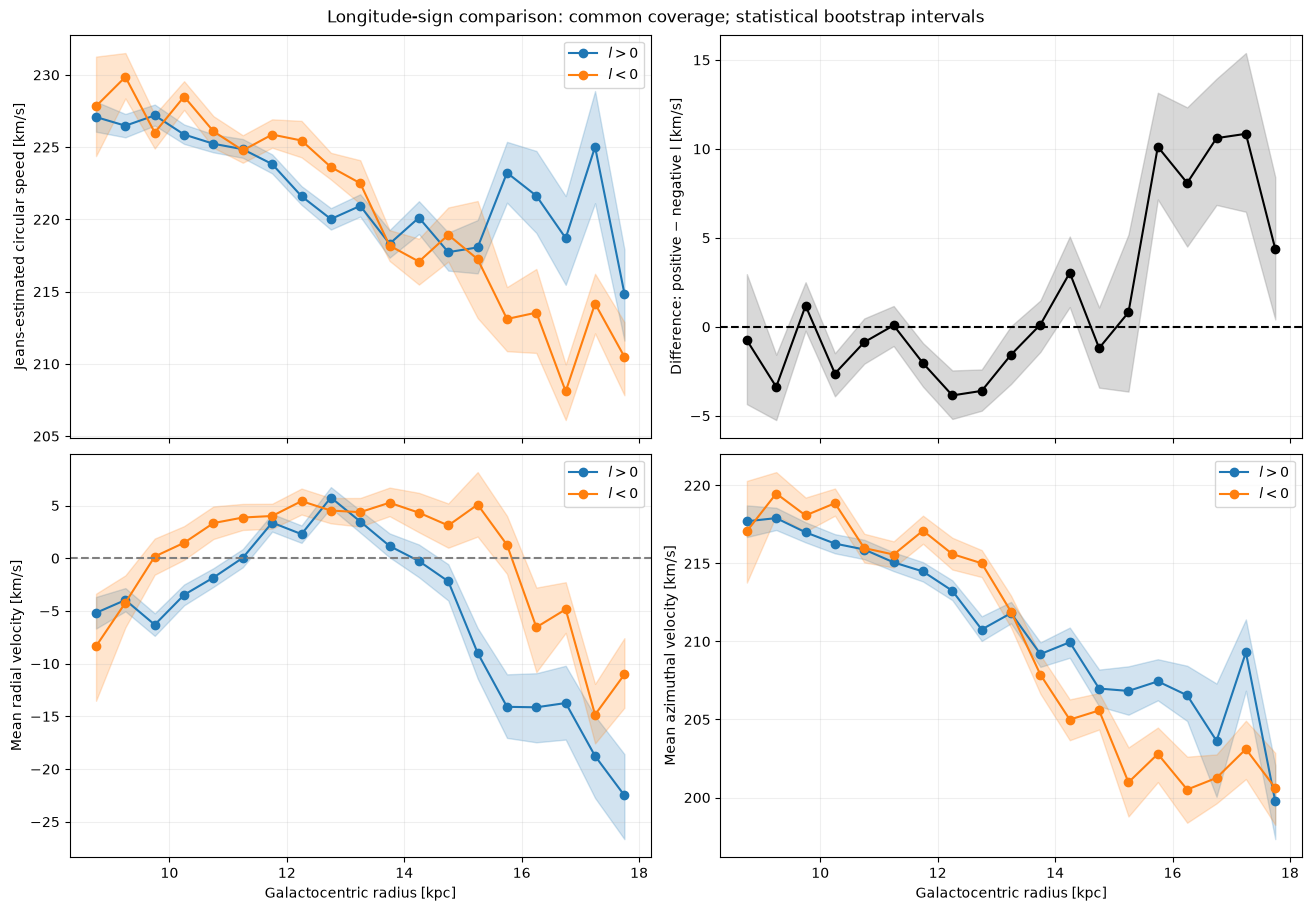

In [31]:
# Plot longitude-split rotation and streaming
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9),
    sharex=True,
    constrained_layout=True,
)

for side, label, colour in [
    ("Lpos", r"$l>0$", "tab:blue"),
    ("Lneg", r"$l<0$", "tab:orange"),
]:
    data = ls_data[side]

    quantiles = np.nanpercentile(
        data["vc_boot"], [16, 84], axis=1
    )

    axes[0, 0].plot(
        ls_r, data["vc"], "o-",
        color=colour, label=label,
    )
    axes[0, 0].fill_between(
        ls_r, quantiles[0], quantiles[1],
        color=colour, alpha=0.2,
    )

    for ax, column in [
        (axes[1, 0], 2),
        (axes[1, 1], 3),
    ]:
        quantiles = np.percentile(
            data["boot"][:, :, column],
            [16, 84],
            axis=1,
        )

        ax.plot(
            ls_r, data["point"][:, column],
            "o-", color=colour, label=label,
        )
        ax.fill_between(
            ls_r, quantiles[0], quantiles[1],
            color=colour, alpha=0.2,
        )

axes[0, 1].plot(ls_r, ls_delta, "ko-")
axes[0, 1].fill_between(
    ls_r, ls_dq[0], ls_dq[2],
    color="grey", alpha=0.3,
)
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[1, 0].axhline(0, color="grey", linestyle="--")

labels = [
    "Jeans-estimated circular speed [km/s]",
    "Difference: positive − negative l [km/s]",
    "Mean radial velocity [km/s]",
    "Mean azimuthal velocity [km/s]",
]

for ax, label in zip(axes.flat, labels):
    ax.set_ylabel(label)
    ax.grid(alpha=0.2)

for ax in (axes[0, 0], axes[1, 0], axes[1, 1]):
    ax.legend()

for ax in axes[1]:
    ax.set_xlabel("Galactocentric radius [kpc]")

fig.suptitle(
    "Longitude-sign comparison: common coverage; "
    "statistical bootstrap intervals"
)

save_figure_pair(fig, "longitude_sign_rotation_and_streaming")


In [32]:
# Inspect population differences by radial bin
ls_population_comparison = ls_diagnostics.pivot(
    index="R_eval",
    columns="side",
    values=[
        "N",
        "R_mean",
        "median_abs_z",
        "median_distance",
        "median_abs_l",
        "median_alpha",
    ],
)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 200,
):
    display(ls_population_comparison)

print("Saved outputs in the existing results/ and figures/ folders.")
print("No original full-sample reproduction products were replaced.")


N             R_mean            median_abs_z           median_distance           median_abs_l             median_alpha          
side     Lneg    Lpos       Lneg       Lpos         Lneg      Lpos            Lneg      Lpos         Lneg        Lpos         Lneg      Lpos
R_eval                                                                                                                                      
8.75     58.0   591.0   8.843217   8.767691     0.451193  0.248776        0.957183  2.430134   147.377620   97.562131     0.016445  0.013390
9.25    239.0   916.0   9.266751   9.263307     0.252511  0.253654        1.370990  2.136982   155.041339  119.361245     0.014761  0.014165
9.75    321.0  1116.0   9.762191   9.751592     0.207718  0.250389        1.841282  2.426596   157.824831  125.228605     0.016307  0.014690
10.25   451.0  1231.0  10.246849  10.257954     0.225285  0.297585        2.330459  2.886003   160.451146  131.727389     0.020782  0.018942
10.75   519.0  1385.0  10.755224  10.748972     0.270770  0.333105        2.833664  3.253090   161.743835  139.950168     0.023439  0.022149
11.25   573.0  1390.0  11.256346  11.244601     0.226457  0.349731        3.362475  3.635703   160.427881  143.245607     0.025261  0.028641
11.75   597.0  1255.0  11.746257  11.749256     0.277140  0.359600        3.856537  4.210526   161.764932  144.888748     0.024170  0.030387
12.25   592.0  1117.0  12.247686  12.240324     0.315007  0.388576        4.374453  4.614675   160.624369  146.569081     0.031545  0.033794
12.75   534.0   881.0  12.745322  12.737494     0.335572  0.432794        4.900760  5.181347   158.346180  146.461912     0.033912  0.036654
13.25   447.0   727.0  13.238204  13.228120     0.393360  0.471901        5.382131  5.630631   160.413970  146.685686     0.039126  0.042082
13.75   416.0   543.0  13.742510  13.734454     0.391733  0.526055        5.908420  6.031363   161.419276  153.651346     0.041538  0.046348
14.25   275.0   313.0  14.240512  14.240453     0.486120  0.552554        6.426735  6.548788   159.555205  153.927770     0.042615  0.048911
14.75   202.0   221.0  14.744203  14.738150     0.709305  0.603354        6.896552  6.997901   163.962612  157.862995     0.045345  0.053690
15.25   121.0   130.0  15.246021  15.194294     0.487911  0.599677        7.490637  7.496357   157.974652  154.114038     0.042535  0.049391
15.75    91.0   112.0  15.757258  15.731419     0.563771  0.688393        8.006405  7.936513   160.381215  159.921335     0.040637  0.054075
16.25    59.0    78.0  16.240948  16.236877     0.667433  0.742211        8.438819  8.532423   164.409047  159.411723     0.048082  0.054440
16.75    67.0    63.0  16.729501  16.716932     0.666928  0.762183        8.888889  8.888889   165.354451  160.958127     0.046645  0.063972
17.25    59.0    51.0  17.257247  17.241077     0.637283  0.672489        9.398496  9.372071   161.892860  161.135378     0.063924  0.059146
17.75    46.0    31.0  17.751394  17.767213     0.752484  0.818226        9.910813  9.920635   163.256585  165.365167     0.048856  0.056336

Saved outputs in the existing results/ and figures/ folders.
No original full-sample reproduction products were replaced.


In [33]:
# Compare model and radial-range choices
rb_npos = ls_common["N_Lpos"].to_numpy(float)
rb_nneg = ls_common["N_Lneg"].to_numpy(float)
rb_total = rb_npos + rb_nneg

rb_rr = (
    rb_npos * ls_data["Lpos"]["point"][:, 0]
    + rb_nneg * ls_data["Lneg"]["point"][:, 0]
) / rb_total

rb_rr_boot = (
    rb_npos[:, None] * ls_data["Lpos"]["boot"][:, :, 0]
    + rb_nneg[:, None] * ls_data["Lneg"]["boot"][:, :, 0]
) / rb_total[:, None]

rb_root = np.where(
    rb_rr_boot > 0,
    np.sqrt(np.maximum(rb_rr_boot, 0)),
    np.nan,
)

rb_quantiles = np.nanpercentile(
    rb_root, [16, 84], axis=1
)
rb_sigma = (
    rb_quantiles[1] - rb_quantiles[0]
) / 2

rb_amplitude, rb_scale = ls_scale_fit(
    rb_rr, rb_sigma
)

rb_scale_boot = np.full(LS_NBOOT, np.nan)

for j in range(LS_NBOOT):
    try:
        _, rb_scale_boot[j] = ls_scale_fit(
            rb_rr_boot[:, j],
            rb_sigma,
            guess=(rb_amplitude, rb_scale),
        )
    except (ValueError, RuntimeError):
        continue

assert np.isfinite(rb_scale_boot).mean() >= 0.95

rb_bound_hits = (
    np.isfinite(rb_scale_boot)
    & (
        (rb_scale_boot < 1.01)
        | (rb_scale_boot > 999)
    )
)

assert rb_bound_hits.sum() < 0.05 * LS_NBOOT

print("Shared dispersion scale:", rb_scale, "kpc")
print(
    "Bootstrap 16/50/84 percentiles:",
    np.nanpercentile(rb_scale_boot, [16, 50, 84]),
)

# Save the underlying moments too, for later checks and recovery.
np.savez_compressed(
    PROJECT / "results/longitude_sign_moment_bootstrap.npz",
    R=ls_r,
    moments_Lpos=ls_data["Lpos"]["point"],
    moments_Lneg=ls_data["Lneg"]["point"],
    boot_moments_Lpos=ls_data["Lpos"]["boot"],
    boot_moments_Lneg=ls_data["Lneg"]["boot"],
    shared_Rprime=rb_scale,
    shared_Rprime_boot=rb_scale_boot,
    N_Lpos=rb_npos,
    N_Lneg=rb_nneg,
    seed=LS_SEED,
)


Shared dispersion scale: 23.888387423810784 kpc
Bootstrap 16/50/84 percentiles: [21.99747841 23.76294984 25.81392994]


In [34]:
# Decompose Jeans contrasts and tracer-density sensitivity
rb_scenarios = {}
rb_density_rows = []

for density in (2.0, 3.0, 4.0):
    scenario = {
        "point": {},
        "boot": {},
    }

    for side in ("Lpos", "Lneg"):
        rr, pp = ls_data[side]["point"][:, :2].T
        boot = ls_data[side]["boot"]

        vc_squared = pp - rr * (
            1
            - ls_r / density
            - 2 * ls_r / rb_scale
        )

        assert (vc_squared > 0).all()

        boot_vc_squared = (
            boot[:, :, 1]
            - boot[:, :, 0] * (
                1
                - ls_r[:, None] / density
                - 2 * ls_r[:, None] / rb_scale_boot[None, :]
            )
        )

        valid = (
            (boot[:, :, 0] > 0)
            & (boot[:, :, 1] > 0)
            & (boot_vc_squared > 0)
            & np.isfinite(rb_scale_boot)[None, :]
        )

        scenario["point"][side] = np.sqrt(vc_squared)

        scenario["boot"][side] = np.where(
            valid,
            np.sqrt(np.maximum(boot_vc_squared, 0)),
            np.nan,
        )

    scenario["delta"] = (
        scenario["point"]["Lpos"]
        - scenario["point"]["Lneg"]
    )

    scenario["delta_boot"] = (
        scenario["boot"]["Lpos"]
        - scenario["boot"]["Lneg"]
    )

    assert (
        np.isfinite(scenario["delta_boot"])
        .mean(axis=1)
        .min()
        >= 0.95
    )

    rb_scenarios[density] = scenario

    quantiles = np.nanpercentile(
        scenario["delta_boot"],
        [16, 50, 84],
        axis=1,
    )

    for i, radius in enumerate(ls_r):
        rb_density_rows.append({
            "R_kpc": radius,
            "tracer_scale_kpc": density,
            "delta_vc": scenario["delta"][i],
            "p16": quantiles[0, i],
            "p50": quantiles[1, i],
            "p84": quantiles[2, i],
        })

rb_density = pd.DataFrame(rb_density_rows)

rb_density.to_csv(
    PROJECT / "results/longitude_sign_density_sensitivity.csv",
    index=False,
)

# Exact nominal decomposition for the 3 kpc tracer-density baseline.
rb_base = rb_scenarios[3.0]

positive = ls_data["Lpos"]["point"]
negative = ls_data["Lneg"]["point"]

# vc² = Vpp + K * Vrr
K = ls_r / 3.0 + 2 * ls_r / rb_scale - 1

# Difference of square roots:
# vc_pos - vc_neg = (vc_pos² - vc_neg²) / (vc_pos + vc_neg)
denominator = (
    rb_base["point"]["Lpos"]
    + rb_base["point"]["Lneg"]
)

rb_terms = pd.DataFrame({
    "R_kpc": ls_r,
    "delta_vc_shared_scale": rb_base["delta"],

    "mean_vphi_squared_term": (
        positive[:, 3]**2 - negative[:, 3]**2
    ) / denominator,

    "centred_phi_second_moment_term": (
        (positive[:, 1] - positive[:, 3]**2)
        - (negative[:, 1] - negative[:, 3]**2)
    ) / denominator,

    "mean_vR_squared_term": K * (
        positive[:, 2]**2 - negative[:, 2]**2
    ) / denominator,

    "centred_R_second_moment_term": K * (
        (positive[:, 0] - positive[:, 2]**2)
        - (negative[:, 0] - negative[:, 2]**2)
    ) / denominator,
})

rb_components = list(rb_terms.columns[2:])

np.testing.assert_allclose(
    rb_terms[rb_components].sum(axis=1),
    rb_terms["delta_vc_shared_scale"],
    atol=1e-10,
)

rb_terms.to_csv(
    PROJECT / (
        "results/longitude_sign_velocity_term_decomposition.csv"
    ),
    index=False,
)

print("Exact algebraic decomposition verified.")
display(rb_terms)


Exact algebraic decomposition verified.


,R_kpc,delta_vc_shared_scale,mean_vphi_squared_term,centred_phi_second_moment_term,mean_vR_squared_term,centred_R_second_moment_term
0,8.75,-0.738283,0.607289,0.087791,-0.249530,-1.183833
1,9.25,-3.357857,-1.508626,0.042874,-0.013288,-1.878816
2,9.75,1.162473,-1.040616,0.138844,0.269127,1.795117
3,10.25,-2.624249,-2.477452,0.220126,0.071543,-0.438466
4,10.75,-0.857155,-0.086581,-0.068609,-0.059901,-0.642065
5,11.25,0.075139,-0.479972,0.151332,-0.122474,0.526252
6,11.75,-2.051199,-2.511249,-0.004545,-0.040291,0.504886
7,12.25,-3.845016,-2.258459,-0.223119,-0.221867,-1.141571
8,12.75,-3.605910,-4.072803,0.246310,0.123564,0.097018
9,13.25,-1.557351,-0.082230,-0.227814,-0.071216,-1.176091


In [35]:
# Fit robustness scenarios and test height composition
def rb_coefficients(velocity, bootstrap, keep):
    quantiles = np.nanpercentile(
        bootstrap, [16, 84], axis=1
    )
    sigma = (
        quantiles[1] - quantiles[0]
    ) / 2

    good = (
        keep
        & np.isfinite(sigma)
        & (sigma > 0)
    )

    assert good.sum() >= 8

    design = np.column_stack((
        np.ones(good.sum()),
        ls_r[good] - 12.0,
    ))

    weights = 1 / sigma[good]**2

    projection = np.linalg.solve(
        design.T @ (weights[:, None] * design),
        design.T * weights,
    )

    point = projection @ velocity[good]

    valid_bootstrap = np.isfinite(
        bootstrap[good]
    ).all(axis=0)

    assert valid_bootstrap.mean() >= 0.95

    draws = np.full((2, LS_NBOOT), np.nan)

    draws[:, valid_bootstrap] = (
        projection
        @ bootstrap[good][:, valid_bootstrap]
    )

    return point, draws


rb_fit_rows = []

for density, scenario in rb_scenarios.items():
    for maximum_radius in (14.0, 15.0, 16.0, 18.0):
        keep = (
            ls_common["R_right"].to_numpy()
            <= maximum_radius + 1e-9
        )

        positive_point, positive_boot = rb_coefficients(
            scenario["point"]["Lpos"],
            scenario["boot"]["Lpos"],
            keep,
        )

        negative_point, negative_boot = rb_coefficients(
            scenario["point"]["Lneg"],
            scenario["boot"]["Lneg"],
            keep,
        )

        difference = positive_point - negative_point
        difference_boot = positive_boot - negative_boot

        for k, quantity in enumerate((
            "delta_vc_at_12_kpc",
            "delta_slope",
        )):
            quantiles = np.nanpercentile(
                difference_boot[k], [16, 50, 84]
            )

            rb_fit_rows.append({
                "tracer_scale_kpc": density,
                "line_fit_Rmax_kpc": maximum_radius,
                "N_bins": int(keep.sum()),
                "quantity": quantity,
                "point": difference[k],
                "p16": quantiles[0],
                "p50": quantiles[1],
                "p84": quantiles[2],
            })

rb_fits = pd.DataFrame(rb_fit_rows)

rb_fits.to_csv(
    PROJECT / (
        "results/longitude_sign_range_density_fit_checks.csv"
    ),
    index=False,
)

print("Shared-scale results for the baseline tracer scale:")
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(
        rb_fits.loc[
            rb_fits["tracer_scale_kpc"] == 3.0
        ]
    )

# Common-height coverage only; no new stellar selection is adopted.
rb_height_rows = []

for row in ls_common.itertuples(index=False):
    thin_bin = (
        (ls_radius >= row.R_left)
        & (ls_radius < row.R_right)
        & (np.abs(q_nominal[:, 2]) <= 0.5)
    )

    rb_height_rows.append({
        "R_kpc": row.R_eval,
        "N_Lpos_absz_le_0p5": int(
            (thin_bin & ls_masks["Lpos"]).sum()
        ),
        "N_Lneg_absz_le_0p5": int(
            (thin_bin & ls_masks["Lneg"]).sum()
        ),
    })

rb_height = pd.DataFrame(rb_height_rows)

rb_height.to_csv(
    PROJECT / "results/longitude_sign_thin_height_coverage.csv",
    index=False,
)

print("Counts after a common |z| <= 0.5 kpc restriction:")
display(rb_height)


Shared-scale results for the baseline tracer scale:


,tracer_scale_kpc,line_fit_Rmax_kpc,N_bins,quantity,point,p16,p50,p84
8,3.0,14.0,11,delta_vc_at_12_kpc,-1.554716,-1.975387,-1.575885,-1.139315
9,3.0,14.0,11,delta_slope,0.045072,-0.220557,0.037671,0.308041
10,3.0,15.0,13,delta_vc_at_12_kpc,-1.294630,-1.686945,-1.309058,-0.905717
11,3.0,15.0,13,delta_slope,0.255490,0.011895,0.262192,0.511304
12,3.0,16.0,15,delta_vc_at_12_kpc,-1.062279,-1.446124,-1.066783,-0.675591
13,3.0,16.0,15,delta_slope,0.492349,0.280932,0.499069,0.723869
14,3.0,18.0,19,delta_vc_at_12_kpc,-0.813605,-1.159492,-0.831305,-0.453713
15,3.0,18.0,19,delta_slope,0.788729,0.619456,0.795266,0.986627


Counts after a common |z| <= 0.5 kpc restriction:


,R_kpc,N_Lpos_absz_le_0p5,N_Lneg_absz_le_0p5
0,8.75,464,37
1,9.25,684,170
2,9.75,896,247
3,10.25,935,365
4,10.75,1006,391
5,11.25,971,437
6,11.75,828,435
7,12.25,687,376
8,12.75,482,347
9,13.25,387,270


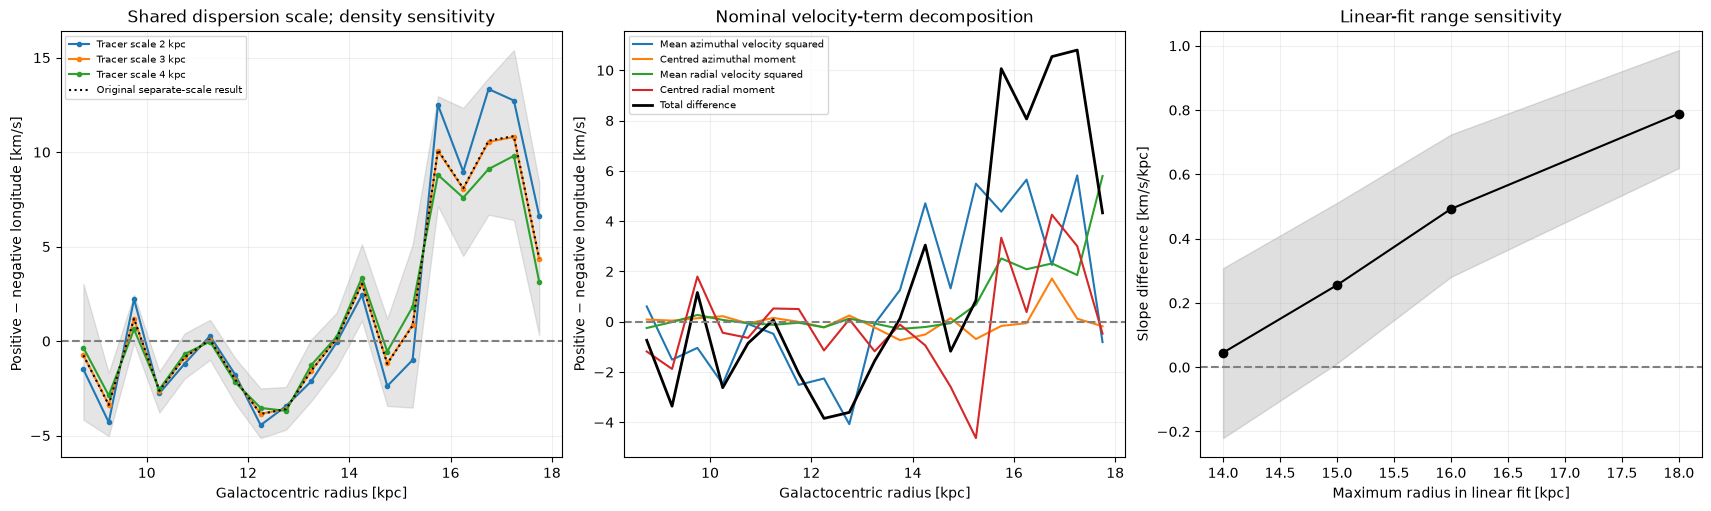

In [36]:
# Plot Jeans robustness scenarios
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True,
)

# Panel 1: common dispersion scale and tracer-density sensitivity.
for density, scenario in rb_scenarios.items():
    quantiles = np.nanpercentile(
        scenario["delta_boot"],
        [16, 84],
        axis=1,
    )

    axes[0].plot(
        ls_r,
        scenario["delta"],
        "o-",
        markersize=3,
        label=f"Tracer scale {density:g} kpc",
    )

    if density == 3.0:
        axes[0].fill_between(
            ls_r,
            quantiles[0],
            quantiles[1],
            color="grey",
            alpha=0.2,
        )

axes[0].plot(
    ls_r,
    ls_delta,
    "k:",
    label="Original separate-scale result",
)

# Panel 2: exact nominal velocity-term decomposition.
term_labels = {
    "mean_vphi_squared_term": "Mean azimuthal velocity squared",
    "centred_phi_second_moment_term": "Centred azimuthal moment",
    "mean_vR_squared_term": "Mean radial velocity squared",
    "centred_R_second_moment_term": "Centred radial moment",
}

for column, label in term_labels.items():
    axes[1].plot(
        ls_r,
        rb_terms[column],
        label=label,
    )

axes[1].plot(
    ls_r,
    rb_terms["delta_vc_shared_scale"],
    "k-",
    linewidth=2,
    label="Total difference",
)

# Panel 3: dependence of the slope difference on line-fitting range.
fit_subset = rb_fits.loc[
    (rb_fits["tracer_scale_kpc"] == 3.0)
    & (rb_fits["quantity"] == "delta_slope")
]

axes[2].plot(
    fit_subset["line_fit_Rmax_kpc"],
    fit_subset["point"],
    "ko-",
)

axes[2].fill_between(
    fit_subset["line_fit_Rmax_kpc"],
    fit_subset["p16"],
    fit_subset["p84"],
    color="grey",
    alpha=0.25,
)

for ax in axes:
    ax.axhline(0, color="grey", linestyle="--")
    ax.grid(alpha=0.2)

for ax in axes[:2]:
    ax.set_xlabel("Galactocentric radius [kpc]")
    ax.set_ylabel("Positive − negative longitude [km/s]")
    ax.legend(fontsize=7)

axes[2].set_xlabel("Maximum radius in linear fit [kpc]")
axes[2].set_ylabel("Slope difference [km/s/kpc]")

axes[0].set_title(
    "Shared dispersion scale; density sensitivity"
)
axes[1].set_title(
    "Nominal velocity-term decomposition"
)
axes[2].set_title(
    "Linear-fit range sensitivity"
)

save_figure_pair(fig, "longitude_sign_robustness_checks")


In [37]:
# Define common broad bins and a fixed height cut
HT_EDGES = np.array([
    8.5, 9.5, 10.5, 11.5, 12.5,
    13.5, 14.5, 15.5, 16.5, 18.0,
])

HT_NBOOT = 1000
HT_SEED = 2026111115

ht_r = (HT_EDGES[:-1] + HT_EDGES[1:]) / 2
ht_height = np.abs(q_nominal[:, 2]) <= 0.5

ht_coverage_rows = []

for k, (left, right) in enumerate(
    zip(HT_EDGES[:-1], HT_EDGES[1:])
):
    in_bin = (
        (ls_radius >= left)
        & (ls_radius < right)
    )

    row = {
        "bin_index": k,
        "R_left": left,
        "R_right": right,
        "R_eval": ht_r[k],
    }

    for side, mask in ls_masks.items():
        row[f"N_full_{side}"] = int(
            (in_bin & mask).sum()
        )
        row[f"N_height_{side}"] = int(
            (in_bin & mask & ht_height).sum()
        )

    ht_coverage_rows.append(row)

ht_coverage = pd.DataFrame(ht_coverage_rows)

count_columns = [
    "N_full_Lpos", "N_full_Lneg",
    "N_height_Lpos", "N_height_Lneg",
]

assert ht_coverage[count_columns].min().min() >= 30

ht_coverage.to_csv(
    PROJECT / "results/longitude_sign_height_test_coverage.csv",
    index=False,
)

display(ht_coverage)


,bin_index,R_left,R_right,R_eval,N_full_Lpos,N_height_Lpos,N_full_Lneg,N_height_Lneg
0,0,8.5,9.5,9.00,1507,1148,297,207
1,1,9.5,10.5,10.00,2347,1831,772,612
2,2,10.5,11.5,11.00,2775,1977,1092,828
3,3,11.5,12.5,12.00,2372,1515,1189,811
4,4,12.5,13.5,13.00,1608,869,981,617
5,5,13.5,14.5,14.00,856,409,691,398
6,6,14.5,15.5,15.00,351,153,323,149
7,7,15.5,16.5,16.00,190,69,150,60
8,8,16.5,18.0,17.25,145,50,172,62


In [38]:
# Recompute broad-bin moments and stellar resamples
ht_rng = np.random.default_rng(HT_SEED)

ht_data = {
    "full": {},
    "height": {},
}

ht_population_rows = []

for side, side_mask in ls_masks.items():
    accumulated = {
        case: {"point": [], "boot": []}
        for case in ht_data
    }

    for k, (left, right) in enumerate(
        zip(HT_EDGES[:-1], HT_EDGES[1:])
    ):
        chosen = (
            side_mask
            & (ls_radius >= left)
            & (ls_radius < right)
        )

        velocity = q_mean[chosen, 3:6]
        covariance = q_cov[chosen]

        values = np.column_stack((
            velocity[:, 0]**2 - covariance[:, 0, 0],
            velocity[:, 1]**2 - covariance[:, 1, 1],
            velocity[:, 0],
            velocity[:, 1],
        ))

        thin = ht_height[chosen]

        assert np.isfinite(values).all()

        accumulated["full"]["point"].append(
            values.mean(axis=0)
        )
        accumulated["height"]["point"].append(
            values[thin].mean(axis=0)
        )

        boot_full = np.empty((HT_NBOOT, 4))
        boot_height = np.empty((HT_NBOOT, 4))

        # Small chunks limit memory use.
        for start in range(0, HT_NBOOT, 100):
            stop = min(start + 100, HT_NBOOT)

            indices = ht_rng.integers(
                0,
                len(values),
                size=(stop - start, len(values)),
            )

            sampled_values = values[indices]
            sampled_thin = thin[indices]
            thin_count = sampled_thin.sum(axis=1)

            assert (thin_count > 0).all()

            boot_full[start:stop] = (
                sampled_values.mean(axis=1)
            )

            boot_height[start:stop] = (
                (
                    sampled_values
                    * sampled_thin[:, :, None]
                ).sum(axis=1)
                / thin_count[:, None]
            )

        accumulated["full"]["boot"].append(boot_full)
        accumulated["height"]["boot"].append(boot_height)

        # Record residual population and survey-field differences.
        for case, extra_mask in [
            ("full", np.ones(len(values), dtype=bool)),
            ("height", thin),
        ]:
            rows = np.flatnonzero(chosen)[extra_mask]

            fields = (
                q_stars.iloc[rows]["SEL_LOCATION_ID"]
                .dropna()
                .value_counts()
            )

            ht_population_rows.append({
                "case": case,
                "side": side,
                "R_eval": ht_r[k],
                "N": len(rows),
                "R_mean": ls_radius[rows].mean(),
                "median_abs_z": np.median(
                    np.abs(q_nominal[rows, 2])
                ),
                "median_abs_l": np.median(
                    np.abs(q_signed_longitude[rows])
                ),
                "median_alpha": pd.to_numeric(
                    q_stars.iloc[rows]["SEL_ALPHA_M"]
                ).median(),
                "N_fields": len(fields),
                "largest_field_fraction": (
                    float(fields.max() / len(rows))
                    if len(fields) else np.nan
                ),
            })

    for case in ht_data:
        ht_data[case][side] = {
            key: np.asarray(value)
            for key, value in accumulated[case].items()
        }

ht_population = pd.DataFrame(ht_population_rows)

ht_population.to_csv(
    PROJECT / "results/longitude_sign_height_test_populations.csv",
    index=False,
)

print("Joint full/height bootstrap complete.")
print("Outer-bin population diagnostics after the height restriction:")

with pd.option_context("display.max_columns", None):
    display(
        ht_population.loc[
            (ht_population["case"] == "height")
            & (ht_population["R_eval"] >= 15.5)
        ]
    )


Joint full/height bootstrap complete.
Outer-bin population diagnostics after the height restriction:


,case,side,R_eval,N,R_mean,median_abs_z,median_abs_l,median_alpha,N_fields,largest_field_fraction
15,height,Lpos,16.00,69,15.939327,0.113371,157.278364,0.052296,25,0.144928
17,height,Lpos,17.25,50,17.027017,0.117047,160.532479,0.056691,18,0.160000
33,height,Lneg,16.00,60,15.925910,0.118830,160.222353,0.038896,21,0.133333
35,height,Lneg,17.25,62,17.139409,0.116525,160.507533,0.055008,14,0.193548


In [39]:
# Fit the common dispersion profile for broad bins
ht_npos = ht_coverage["N_full_Lpos"].to_numpy(float)
ht_nneg = ht_coverage["N_full_Lneg"].to_numpy(float)
ht_ntotal = ht_npos + ht_nneg

ht_rr = (
    ht_npos * ht_data["full"]["Lpos"]["point"][:, 0]
    + ht_nneg * ht_data["full"]["Lneg"]["point"][:, 0]
) / ht_ntotal

ht_rr_boot = (
    ht_npos[:, None]
    * ht_data["full"]["Lpos"]["boot"][:, :, 0]
    + ht_nneg[:, None]
    * ht_data["full"]["Lneg"]["boot"][:, :, 0]
) / ht_ntotal[:, None]

ht_root = np.where(
    ht_rr_boot > 0,
    np.sqrt(np.maximum(ht_rr_boot, 0)),
    np.nan,
)

ht_quantiles = np.nanpercentile(
    ht_root, [16, 84], axis=1
)
ht_sigma = (
    ht_quantiles[1] - ht_quantiles[0]
) / 2


def ht_fit_scale(rr, guess):
    good = (
        (rr > 0)
        & np.isfinite(rr)
        & np.isfinite(ht_sigma)
        & (ht_sigma > 0)
    )

    if good.sum() < 8:
        raise ValueError("Too few valid dispersion bins.")

    parameters, _ = curve_fit(
        ls_exponential,
        ht_r[good],
        np.sqrt(rr[good]),
        sigma=ht_sigma[good],
        p0=guess,
        bounds=([1e-6, 1.0], [1e5, 1000.0]),
        maxfev=10000,
    )

    return parameters


ht_amplitude, ht_scale = ht_fit_scale(
    ht_rr, (60.0, 24.0)
)

ht_scale_boot = np.full(HT_NBOOT, np.nan)

for j in range(HT_NBOOT):
    try:
        _, ht_scale_boot[j] = ht_fit_scale(
            ht_rr_boot[:, j],
            (ht_amplitude, ht_scale),
        )
    except (ValueError, RuntimeError):
        continue

assert np.isfinite(ht_scale_boot).mean() >= 0.95

bound_hits = (
    np.isfinite(ht_scale_boot)
    & (
        (ht_scale_boot < 1.01)
        | (ht_scale_boot > 999)
    )
)
assert bound_hits.sum() < 0.05 * HT_NBOOT

for case in ht_data:
    for side, data in ht_data[case].items():
        rr, pp = data["point"][:, :2].T
        boot = data["boot"]

        vc_squared = pp - rr * (
            1 - ht_r / 3.0 - 2 * ht_r / ht_scale
        )

        assert (rr > 0).all()
        assert (pp > 0).all()
        assert (vc_squared > 0).all()

        boot_vc_squared = (
            boot[:, :, 1]
            - boot[:, :, 0] * (
                1
                - ht_r[:, None] / 3.0
                - 2 * ht_r[:, None] / ht_scale_boot[None, :]
            )
        )

        valid = (
            (boot[:, :, 0] > 0)
            & (boot[:, :, 1] > 0)
            & (boot_vc_squared > 0)
            & np.isfinite(ht_scale_boot)[None, :]
        )

        data["vc"] = np.sqrt(vc_squared)
        data["vc_boot"] = np.where(
            valid,
            np.sqrt(np.maximum(boot_vc_squared, 0)),
            np.nan,
        )

        assert (
            np.isfinite(data["vc_boot"])
            .mean(axis=1)
            .min()
            >= 0.95
        )

print("Shared full-sample scale on the broader bins:", ht_scale)
print(
    "Bootstrap scale 16/50/84:",
    np.nanpercentile(ht_scale_boot, [16, 50, 84]),
)

ht_payload = {
    "edges": HT_EDGES,
    "R": ht_r,
    "shared_scale": ht_scale,
    "shared_scale_boot": ht_scale_boot,
    "n_boot": HT_NBOOT,
    "seed": HT_SEED,
}

for case in ht_data:
    for side, data in ht_data[case].items():
        for key in ("point", "boot", "vc", "vc_boot"):
            ht_payload[f"{case}_{side}_{key}"] = data[key]

np.savez_compressed(
    PROJECT / "results/longitude_sign_height_test_bootstrap.npz",
    **ht_payload,
)


Shared full-sample scale on the broader bins: 25.663617749249582
Bootstrap scale 16/50/84: [23.65859142 25.64717445 28.43852593]


In [40]:
# Compare full and height-cut contrasts
ht_differences = {}
ht_comparison_rows = []

for case in ht_data:
    ht_differences[case] = {}

    for quantity, column in [
        ("vc", None),
        ("mean_vR", 2),
        ("mean_vphi", 3),
    ]:
        if column is None:
            point = (
                ht_data[case]["Lpos"]["vc"]
                - ht_data[case]["Lneg"]["vc"]
            )
            boot = (
                ht_data[case]["Lpos"]["vc_boot"]
                - ht_data[case]["Lneg"]["vc_boot"]
            )
        else:
            point = (
                ht_data[case]["Lpos"]["point"][:, column]
                - ht_data[case]["Lneg"]["point"][:, column]
            )
            boot = (
                ht_data[case]["Lpos"]["boot"][:, :, column]
                - ht_data[case]["Lneg"]["boot"][:, :, column]
            )

        ht_differences[case][quantity] = {
            "point": point,
            "boot": boot,
        }

        quantiles = np.nanpercentile(
            boot, [16, 50, 84], axis=1
        )

        for i, radius in enumerate(ht_r):
            ht_comparison_rows.append({
                "case": case,
                "quantity": quantity,
                "R_left": HT_EDGES[i],
                "R_right": HT_EDGES[i + 1],
                "R_eval": radius,
                "delta": point[i],
                "p16": quantiles[0, i],
                "p50": quantiles[1, i],
                "p84": quantiles[2, i],
            })

ht_comparison = pd.DataFrame(ht_comparison_rows)

ht_comparison.to_csv(
    PROJECT / "results/longitude_sign_height_test_comparison.csv",
    index=False,
)

change = (
    ht_differences["height"]["vc"]["point"]
    - ht_differences["full"]["vc"]["point"]
)

change_boot = (
    ht_differences["height"]["vc"]["boot"]
    - ht_differences["full"]["vc"]["boot"]
)

assert (
    np.isfinite(change_boot).mean(axis=1).min()
    >= 0.95
)

quantiles = np.nanpercentile(
    change_boot, [16, 50, 84], axis=1
)

ht_change = pd.DataFrame({
    "R_left": HT_EDGES[:-1],
    "R_right": HT_EDGES[1:],
    "R_eval": ht_r,
    "change_in_delta_vc": change,
    "p16": quantiles[0],
    "p50": quantiles[1],
    "p84": quantiles[2],
})

ht_change.to_csv(
    PROJECT / "results/longitude_sign_height_test_change.csv",
    index=False,
)

with pd.option_context("display.max_columns", None):
    print("Positive-minus-negative Jeans estimates:")
    display(
        ht_comparison.loc[
            ht_comparison["quantity"] == "vc"
        ]
    )

    print("Effect of height restriction: height minus full")
    display(ht_change)


Positive-minus-negative Jeans estimates:


,case,quantity,R_left,R_right,R_eval,delta,p16,p50,p84
0,full,vc,8.5,9.5,9.00,-2.547979,-3.943869,-2.417300,-0.914512
1,full,vc,9.5,10.5,10.00,-0.918041,-1.801420,-0.956666,-0.091556
2,full,vc,10.5,11.5,11.00,-0.362181,-1.104402,-0.305902,0.418426
3,full,vc,11.5,12.5,12.00,-2.842794,-3.713831,-2.852219,-1.981952
4,full,vc,12.5,13.5,13.00,-2.652821,-3.559621,-2.615837,-1.656861
5,full,vc,13.5,14.5,14.00,1.261236,0.015230,1.283129,2.393814
6,full,vc,14.5,15.5,15.00,-0.371134,-2.537431,-0.428225,1.739409
7,full,vc,15.5,16.5,16.00,9.222771,6.682952,9.177738,11.732650
8,full,vc,16.5,18.0,17.25,9.250653,7.039504,9.442332,11.669228
27,height,vc,8.5,9.5,9.00,-2.161906,-3.888800,-2.051374,-0.388630


Effect of height restriction: height minus full


,R_left,R_right,R_eval,change_in_delta_vc,p16,p50,p84
0,8.5,9.5,9.00,0.386072,-0.598432,0.334724,1.342071
1,9.5,10.5,10.00,0.096181,-0.335885,0.095969,0.530922
2,10.5,11.5,11.00,-0.347837,-0.818393,-0.363744,0.136805
3,11.5,12.5,12.00,0.639874,-0.045837,0.638041,1.308036
4,12.5,13.5,13.00,0.681591,-0.114789,0.647536,1.423884
5,13.5,14.5,14.00,0.932134,-0.146618,0.970766,2.088581
6,14.5,15.5,15.00,-0.040307,-2.346785,0.020873,2.436990
7,15.5,16.5,16.00,2.891587,-0.132946,2.786276,5.847887
8,16.5,18.0,17.25,-8.507462,-12.040927,-8.381100,-4.739761


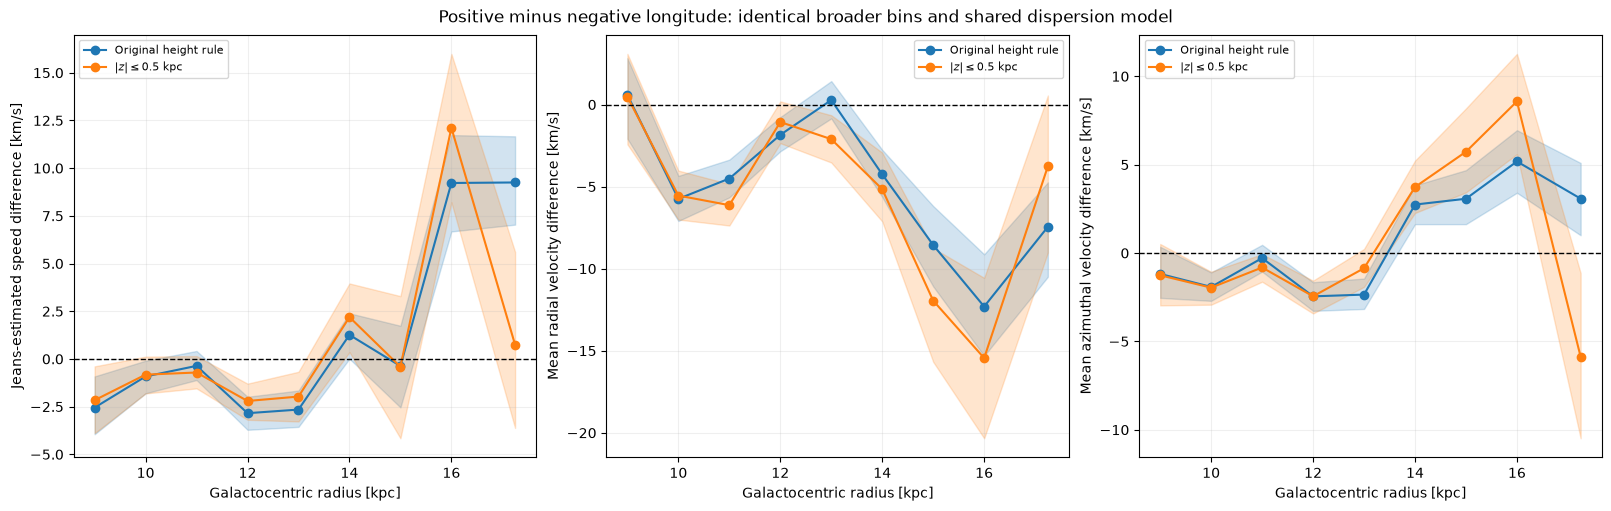

In [41]:
# Plot the height-controlled comparison
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    constrained_layout=True,
)

quantities = [
    ("vc", "Jeans-estimated speed difference [km/s]"),
    ("mean_vR", "Mean radial velocity difference [km/s]"),
    ("mean_vphi", "Mean azimuthal velocity difference [km/s]"),
]

for ax, (quantity, ylabel) in zip(axes, quantities):
    for case, colour, label in [
        ("full", "tab:blue", "Original height rule"),
        ("height", "tab:orange", r"$|z|\leq0.5$ kpc"),
    ]:
        data = ht_differences[case][quantity]

        quantiles = np.nanpercentile(
            data["boot"], [16, 84], axis=1
        )

        ax.plot(
            ht_r,
            data["point"],
            "o-",
            color=colour,
            label=label,
        )

        ax.fill_between(
            ht_r,
            quantiles[0],
            quantiles[1],
            color=colour,
            alpha=0.2,
        )

    ax.axhline(
        0, color="black", linestyle="--", linewidth=1
    )
    ax.grid(alpha=0.2)
    ax.set_xlabel("Galactocentric radius [kpc]")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

fig.suptitle(
    "Positive minus negative longitude: "
    "identical broader bins and shared dispersion model"
)

save_figure_pair(fig, "longitude_sign_height_control")


In [42]:
# Aggregate velocity moments by APOGEE field
FB_NBOOT = 1000
FB_SEED = 2026111120

fb_cases = ("full", "height")
fb_sides = ("Lpos", "Lneg")

fb_domain = (
    (ls_radius >= HT_EDGES[0])
    & (ls_radius < HT_EDGES[-1])
    & (ls_masks["Lpos"] | ls_masks["Lneg"])
)

fb_location = pd.to_numeric(
    q_stars["SEL_LOCATION_ID"],
    errors="coerce",
).to_numpy(float)

assert np.isfinite(fb_location[fb_domain]).all()
assert (fb_location[fb_domain] > 0).all()
assert np.all(
    fb_location[fb_domain]
    == np.round(fb_location[fb_domain])
)

fb_fields = np.unique(
    fb_location[fb_domain]
).astype(np.int64)

fb_M = len(fb_fields)
fb_B = len(ht_r)

# Dimensions: case, longitude side, radial bin, observing field.
fb_n = np.zeros((2, 2, fb_B, fb_M))

# Last dimension contains:
# Vrr contribution, Vpp contribution, vR, vphi.
fb_sums = np.zeros((2, 2, fb_B, fb_M, 4))

fb_values = np.column_stack((
    q_mean[:, 3]**2 - q_cov[:, 0, 0],
    q_mean[:, 4]**2 - q_cov[:, 1, 1],
    q_mean[:, 3],
    q_mean[:, 4],
))

for ci, case in enumerate(fb_cases):
    for si, side in enumerate(fb_sides):
        for k, (left, right) in enumerate(
            zip(HT_EDGES[:-1], HT_EDGES[1:])
        ):
            selected = (
                ls_masks[side]
                & (ls_radius >= left)
                & (ls_radius < right)
            )

            if case == "height":
                selected = selected & ht_height

            field_index = np.searchsorted(
                fb_fields,
                fb_location[selected].astype(np.int64),
            )

            fb_n[ci, si, k] = np.bincount(
                field_index,
                minlength=fb_M,
            )

            for column in range(4):
                fb_sums[ci, si, k, :, column] = np.bincount(
                    field_index,
                    weights=fb_values[selected, column],
                    minlength=fb_M,
                )

        nominal_moments = (
            fb_sums[ci, si].sum(axis=1)
            / fb_n[ci, si].sum(axis=1)[:, None]
        )

        np.testing.assert_allclose(
            nominal_moments,
            ht_data[case][side]["point"],
            rtol=1e-12,
            atol=1e-8,
        )

print("LOCATION_ID blocks:", fb_M)
print("Field aggregation agrees with the previous results.")


LOCATION_ID blocks: 325
Field aggregation agrees with the previous results.


In [43]:
# Run paired whole-field bootstrap
fb_rng = np.random.default_rng(FB_SEED)

# Sample fb_M observing fields with replacement per realization.
fb_weights = fb_rng.multinomial(
    fb_M,
    np.full(fb_M, 1.0 / fb_M),
    size=FB_NBOOT,
)

fb_counts = np.einsum(
    "csbf,jf->csbj",
    fb_n,
    fb_weights,
    optimize=True,
)

fb_totals = np.einsum(
    "csbfv,jf->csbjv",
    fb_sums,
    fb_weights,
    optimize=True,
)

fb_moments = np.full_like(fb_totals, np.nan)

np.divide(
    fb_totals,
    fb_counts[:, :, :, :, None],
    out=fb_moments,
    where=fb_counts[:, :, :, :, None] > 0,
)

# Pool the original-height sample to estimate the shared gradient.
fb_pooled_count = fb_counts[0].sum(axis=0)

fb_pooled_rr = np.full(
    (fb_B, FB_NBOOT), np.nan
)

np.divide(
    fb_totals[0, :, :, :, 0].sum(axis=0),
    fb_pooled_count,
    out=fb_pooled_rr,
    where=fb_pooled_count > 0,
)

fb_scale_boot = np.full(FB_NBOOT, np.nan)

for j in range(FB_NBOOT):
    try:
        _, fb_scale_boot[j] = ht_fit_scale(
            fb_pooled_rr[:, j],
            (60.0, ht_scale),
        )
    except (ValueError, RuntimeError):
        continue

assert np.isfinite(fb_scale_boot).mean() >= 0.95

fb_bound_hits = (
    np.isfinite(fb_scale_boot)
    & (
        (fb_scale_boot < 1.01)
        | (fb_scale_boot > 999)
    )
)

assert fb_bound_hits.mean() < 0.05

fb_curves = {}

for ci, case in enumerate(fb_cases):
    fb_curves[case] = {}

    for si, side in enumerate(fb_sides):
        boot = fb_moments[ci, si]

        vc_squared = (
            boot[:, :, 1]
            - boot[:, :, 0] * (
                1
                - ht_r[:, None] / 3.0
                - 2 * ht_r[:, None] / fb_scale_boot[None, :]
            )
        )

        valid = (
            (fb_counts[ci, si] > 0)
            & (boot[:, :, 0] > 0)
            & (boot[:, :, 1] > 0)
            & (vc_squared > 0)
            & np.isfinite(fb_scale_boot)[None, :]
        )

        fb_curves[case][side] = np.where(
            valid,
            np.sqrt(np.maximum(vc_squared, 0)),
            np.nan,
        )

    fb_curves[case]["delta"] = (
        fb_curves[case]["Lpos"]
        - fb_curves[case]["Lneg"]
    )

    valid_fraction = np.isfinite(
        fb_curves[case]["delta"]
    ).mean(axis=1)

    print(
        case,
        "minimum valid field-bootstrap fraction:",
        valid_fraction.min(),
    )

    assert valid_fraction.min() >= 0.95

fb_summary_rows = []

for case in fb_cases:
    field_quantiles = np.nanpercentile(
        fb_curves[case]["delta"],
        [2.5, 16, 50, 84, 97.5],
        axis=1,
    )

    star_quantiles = np.nanpercentile(
        ht_differences[case]["vc"]["boot"],
        [16, 50, 84],
        axis=1,
    )

    for k, radius in enumerate(ht_r):
        fb_summary_rows.append({
            "case": case,
            "R_left": HT_EDGES[k],
            "R_right": HT_EDGES[k + 1],
            "R_eval": radius,
            "point": ht_differences[case]["vc"]["point"][k],
            "star_p16": star_quantiles[0, k],
            "star_p50": star_quantiles[1, k],
            "star_p84": star_quantiles[2, k],
            "field_p025": field_quantiles[0, k],
            "field_p16": field_quantiles[1, k],
            "field_p50": field_quantiles[2, k],
            "field_p84": field_quantiles[3, k],
            "field_p975": field_quantiles[4, k],
        })

fb_summary = pd.DataFrame(fb_summary_rows)

fb_summary.to_csv(
    PROJECT / "results/longitude_sign_field_bootstrap_summary.csv",
    index=False,
)

np.savez_compressed(
    PROJECT / "results/longitude_sign_field_bootstrap.npz",
    fields=fb_fields,
    weights=fb_weights,
    R=ht_r,
    edges=HT_EDGES,
    shared_scale_boot=fb_scale_boot,
    delta_full=fb_curves["full"]["delta"],
    delta_height=fb_curves["height"]["delta"],
    seed=FB_SEED,
    n_boot=FB_NBOOT,
)

with pd.option_context("display.max_columns", None):
    display(
        fb_summary.loc[fb_summary["R_left"] >= 15.5]
    )


full minimum valid field-bootstrap fraction: 1.0
height minimum valid field-bootstrap fraction: 1.0


,case,R_left,R_right,R_eval,point,star_p16,star_p50,star_p84,field_p025,field_p16,field_p50,field_p84,field_p975
7,full,15.5,16.5,16.00,9.222771,6.682952,9.177738,11.732650,4.753953,6.803998,9.160069,11.711316,13.779897
8,full,16.5,18.0,17.25,9.250653,7.039504,9.442332,11.669228,4.542362,6.865818,9.219780,11.422286,13.947742
16,height,15.5,16.5,16.00,12.114358,8.210169,12.213353,15.989159,3.835787,7.947698,11.994955,16.089361,20.028832
17,height,16.5,18.0,17.25,0.743192,-3.617248,0.931503,5.610815,-7.464725,-3.403457,0.750381,4.404408,7.863820


In [44]:
# Measure leave-one-field-out influence
fb_total_n = fb_n.sum(axis=3)
fb_total_sums = fb_sums.sum(axis=3)

fb_leave_rows = []
fb_failed = []

for field_index, field in enumerate(fb_fields):
    counts_after = (
        fb_total_n - fb_n[:, :, :, field_index]
    )

    sums_after = (
        fb_total_sums - fb_sums[:, :, :, field_index, :]
    )

    try:
        if np.any(counts_after <= 0):
            raise ValueError("Empty bin after field removal.")

        moments_after = (
            sums_after / counts_after[:, :, :, None]
        )

        pooled_rr_after = (
            sums_after[0, :, :, 0].sum(axis=0)
            / counts_after[0].sum(axis=0)
        )

        _, scale_after = ht_fit_scale(
            pooled_rr_after,
            (60.0, ht_scale),
        )

        vc_squared_after = (
            moments_after[:, :, :, 1]
            - moments_after[:, :, :, 0] * (
                1
                - ht_r[None, None, :] / 3.0
                - 2 * ht_r[None, None, :] / scale_after
            )
        )

        if np.any(vc_squared_after <= 0):
            raise ValueError(
                "Nonpositive Jeans speed squared."
            )

        vc_after = np.sqrt(vc_squared_after)

        for ci, case in enumerate(fb_cases):
            difference_after = (
                vc_after[ci, 0] - vc_after[ci, 1]
            )

            outer_bins = np.flatnonzero(
                HT_EDGES[:-1] >= 15.5
            )

            for k in outer_bins:
                nominal_delta = (
                    ht_differences[case]["vc"]["point"][k]
                )

                fb_leave_rows.append({
                    "field_removed": int(field),
                    "case": case,
                    "R_left": HT_EDGES[k],
                    "R_right": HT_EDGES[k + 1],
                    "delta_without_field": difference_after[k],
                    "nominal_delta": nominal_delta,
                    "change": (
                        difference_after[k] - nominal_delta
                    ),
                    "N_Lpos_remaining": int(
                        counts_after[ci, 0, k]
                    ),
                    "N_Lneg_remaining": int(
                        counts_after[ci, 1, k]
                    ),
                    "N_Lpos_removed": int(
                        fb_n[ci, 0, k, field_index]
                    ),
                    "N_Lneg_removed": int(
                        fb_n[ci, 1, k, field_index]
                    ),
                })

    except (ValueError, RuntimeError) as error:
        fb_failed.append({
            "field_removed": int(field),
            "error": str(error),
        })

fb_leave = pd.DataFrame(fb_leave_rows)

fb_leave.to_csv(
    PROJECT / "results/longitude_sign_leave_one_field_out.csv",
    index=False,
)

pd.DataFrame(
    fb_failed,
    columns=["field_removed", "error"],
).to_csv(
    PROJECT / "reports/longitude_sign_leave_one_field_failures.csv",
    index=False,
)

print("Failed field-removal checks:", len(fb_failed))

assert not fb_failed, (
    "Inspect failed removals before interpreting influence ranges."
)

print("Leave-one-field-out ranges — NOT confidence intervals:")

display(
    fb_leave.groupby(
        ["case", "R_left", "R_right"]
    )["delta_without_field"].agg(["min", "max"])
)

fb_focus = fb_leave.loc[
    (fb_leave["case"] == "height")
    & (fb_leave["R_left"] == 15.5)
].copy()

fb_focus["abs_change"] = fb_focus["change"].abs()

print("Largest influences on the height-restricted 15.5–16.5 kpc result:")

with pd.option_context("display.max_columns", None):
    display(fb_focus.nlargest(8, "abs_change"))


Failed field-removal checks: 0
Leave-one-field-out ranges — NOT confidence intervals:


min        max
case   R_left R_right                      
full   15.5   16.5      8.557900   9.759499
       16.5   18.0      8.244618   9.949998
height 15.5   16.5     10.819606  13.558537
       16.5   18.0     -1.321322   2.310010

Largest influences on the height-restricted 15.5–16.5 kpc result:


,field_removed,case,R_left,R_right,delta_without_field,nominal_delta,change,N_Lpos_remaining,N_Lneg_remaining,N_Lpos_removed,N_Lneg_removed,abs_change
574,4418,height,15.5,16.5,13.558537,12.114358,1.444179,69,58,0,2,1.444179
1166,5105,height,15.5,16.5,13.533338,12.114358,1.418980,64,60,5,0,1.418980
882,4595,height,15.5,16.5,13.437567,12.114358,1.323209,69,59,0,1,1.323209
1054,5063,height,15.5,16.5,10.819606,12.114358,-1.294752,61,60,8,0,1.294752
282,4157,height,15.5,16.5,11.163988,12.114358,-0.950370,69,56,0,4,0.950370
1154,5102,height,15.5,16.5,11.166809,12.114358,-0.947549,63,60,6,0,0.947549
550,4411,height,15.5,16.5,11.178365,12.114358,-0.935993,69,54,0,6,0.935993
1122,5088,height,15.5,16.5,11.183617,12.114358,-0.930741,69,53,0,7,0.930741


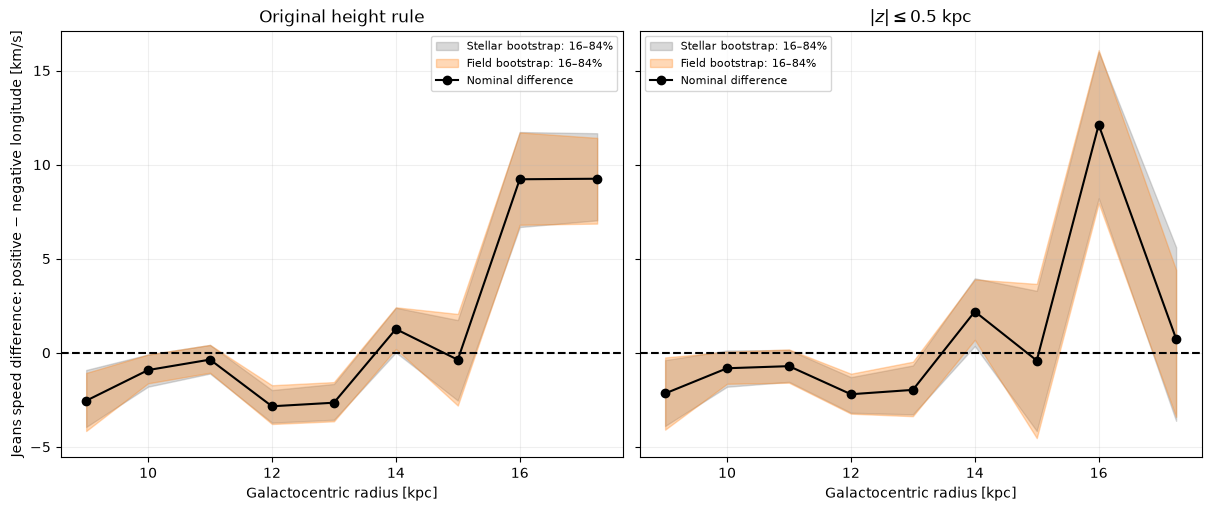

In [45]:
# Plot whole-field sampling uncertainty
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True,
    constrained_layout=True,
)

for ax, case, title in zip(
    axes,
    fb_cases,
    ["Original height rule", r"$|z|\leq0.5$ kpc"],
):
    table = fb_summary.loc[
        fb_summary["case"] == case
    ]

    ax.fill_between(
        table["R_eval"],
        table["star_p16"],
        table["star_p84"],
        color="grey",
        alpha=0.3,
        label="Stellar bootstrap: 16–84%",
    )

    ax.fill_between(
        table["R_eval"],
        table["field_p16"],
        table["field_p84"],
        color="tab:orange",
        alpha=0.3,
        label="Field bootstrap: 16–84%",
    )

    ax.plot(
        table["R_eval"],
        table["point"],
        "ko-",
        label="Nominal difference",
    )

    ax.axhline(0, color="black", linestyle="--")
    ax.grid(alpha=0.2)
    ax.set_xlabel("Galactocentric radius [kpc]")
    ax.set_title(title)
    ax.legend(fontsize=8)

axes[0].set_ylabel(
    "Jeans speed difference: positive − negative longitude [km/s]"
)

save_figure_pair(fig, "longitude_sign_field_bootstrap")


In [46]:
# Match reflected geometry and chemical abundance
MP_LEFT = 15.5
MP_RIGHT = 16.5
MP_R_EVAL = 0.5 * (MP_LEFT + MP_RIGHT)

mp_domain = (
    (ls_radius >= MP_LEFT)
    & (ls_radius < MP_RIGHT)
    & ht_height
)

mp_pos = np.flatnonzero(
    mp_domain & ls_masks["Lpos"]
)
mp_neg = np.flatnonzero(
    mp_domain & ls_masks["Lneg"]
)

mp_abs_phi = np.abs(
    np.degrees(
        np.arctan2(
            np.sin(q_nominal[:, 1] - np.pi),
            np.cos(q_nominal[:, 1] - np.pi),
        )
    )
)

mp_alpha = pd.to_numeric(
    q_stars["SEL_ALPHA_M"],
    errors="coerce",
).to_numpy(float)

mp_features = np.column_stack((
    ls_radius,
    mp_abs_phi,
    q_nominal[:, 2],  # signed height
    mp_alpha,
))

mp_feature_names = [
    "R_kpc", "abs_phi_deg", "z_kpc", "alpha"
]

assert np.isfinite(
    mp_features[np.r_[mp_pos, mp_neg]]
).all()

mp_specs = {
    "geometry": (
        [0, 1, 2],
        np.array([0.25, 3.0, 0.15]),
    ),
    "geometry_alpha": (
        [0, 1, 2, 3],
        np.array([0.25, 3.0, 0.15, 0.03]),
    ),
}

mp_samples = {
    "unmatched": {
        "Lpos": mp_pos,
        "Lneg": mp_neg,
    }
}

mp_pair_rows = []

for name, (columns, calipers) in mp_specs.items():
    separation = np.abs(
        mp_features[mp_pos][:, columns][:, None, :]
        - mp_features[mp_neg][:, columns][None, :, :]
    ) / calipers

    allowed = (separation <= 1).all(axis=2)
    distance = (separation**2).sum(axis=2)

    # Dummy columns allow stars without acceptable counterparts
    # to remain unmatched. The penalty prioritizes the number
    # of valid pairs before minimizing their separation.
    penalty = (
        min(len(mp_pos), len(mp_neg)) + 1
    ) * (len(columns) + 1)

    assignment_cost = np.full(
        (
            len(mp_pos),
            len(mp_neg) + len(mp_pos),
        ),
        penalty,
        dtype=float,
    )

    assignment_cost[:, :len(mp_neg)] = np.where(
        allowed,
        distance,
        100 * penalty,
    )

    ii, jj = linear_sum_assignment(assignment_cost)

    real_match = jj < len(mp_neg)
    ii = ii[real_match]
    jj = jj[real_match]

    assert allowed[ii, jj].all()
    assert len(np.unique(ii)) == len(ii)
    assert len(np.unique(jj)) == len(jj)

    assert len(ii) >= 20, (
        f"{name}: fewer than 20 supported pairs; "
        "inspect overlap before proceeding."
    )

    mp_samples[name] = {
        "Lpos": mp_pos[ii],
        "Lneg": mp_neg[jj],
    }

    for pair_index, (i, j) in enumerate(zip(ii, jj)):
        row = {
            "sample": name,
            "pair_index": pair_index,
            "row_Lpos": int(mp_pos[i]),
            "row_Lneg": int(mp_neg[j]),
            "ID_Lpos": str(q_ids[mp_pos[i]]),
            "ID_Lneg": str(q_ids[mp_neg[j]]),
            "scaled_squared_distance": distance[i, j],
        }

        for column, feature in enumerate(mp_feature_names):
            row[f"{feature}_Lpos"] = (
                mp_features[mp_pos[i], column]
            )
            row[f"{feature}_Lneg"] = (
                mp_features[mp_neg[j], column]
            )

        mp_pair_rows.append(row)

    print(name, ":", len(ii), "unique pairs")

mp_pairs = pd.DataFrame(mp_pair_rows)

mp_pairs.to_csv(
    PROJECT / "results/longitude_sign_mirror_pairs.csv",
    index=False,
)


geometry : 44 unique pairs
geometry_alpha : 31 unique pairs


In [47]:
# Validate matched-pair geometry and sample sizes
mp_reference_sd = np.sqrt(
    (
        mp_features[mp_pos].var(axis=0, ddof=1)
        + mp_features[mp_neg].var(axis=0, ddof=1)
    ) / 2
)

mp_balance_rows = []
mp_count_rows = []

for name, samples in mp_samples.items():
    positive_rows = samples["Lpos"]
    negative_rows = samples["Lneg"]

    mp_count_rows.append({
        "sample": name,
        "N_Lpos": len(positive_rows),
        "N_Lneg": len(negative_rows),
        "fields_Lpos": len(
            np.unique(fb_location[positive_rows])
        ),
        "fields_Lneg": len(
            np.unique(fb_location[negative_rows])
        ),
    })

    for column, feature in enumerate(mp_feature_names):
        positive_mean = mp_features[
            positive_rows, column
        ].mean()

        negative_mean = mp_features[
            negative_rows, column
        ].mean()

        difference = positive_mean - negative_mean

        mp_balance_rows.append({
            "sample": name,
            "feature": feature,
            "mean_Lpos": positive_mean,
            "mean_Lneg": negative_mean,
            "mean_difference": difference,
            "standardized_difference": (
                difference / mp_reference_sd[column]
                if mp_reference_sd[column] > 0
                else np.nan
            ),
        })

mp_counts = pd.DataFrame(mp_count_rows)
mp_balance = pd.DataFrame(mp_balance_rows)

mp_counts.to_csv(
    PROJECT / "results/longitude_sign_mirror_sample_counts.csv",
    index=False,
)

mp_balance.to_csv(
    PROJECT / "results/longitude_sign_mirror_balance.csv",
    index=False,
)

display(mp_counts)

with pd.option_context("display.max_columns", None):
    display(mp_balance)


,sample,N_Lpos,N_Lneg,fields_Lpos,fields_Lneg
0,unmatched,69,60,25,21
1,geometry,44,44,14,16
2,geometry_alpha,31,31,10,12


,sample,feature,mean_Lpos,mean_Lneg,mean_difference,standardized_difference
0,unmatched,R_kpc,15.939327,15.925910,0.013416,0.046534
1,unmatched,abs_phi_deg,12.359492,9.267462,3.092029,0.464017
2,unmatched,z_kpc,0.008532,0.033553,-0.025021,-0.113517
3,unmatched,alpha,0.049908,0.043349,0.006559,0.229575
4,geometry,R_kpc,15.918879,15.918174,0.000705,0.002445
5,geometry,abs_phi_deg,10.266195,10.069074,0.197120,0.029582
6,geometry,z_kpc,0.067554,0.058588,0.008967,0.040680
7,geometry,alpha,0.047331,0.040889,0.006442,0.225482
8,geometry_alpha,R_kpc,15.928067,15.924889,0.003178,0.011023
9,geometry_alpha,abs_phi_deg,10.224906,9.881037,0.343869,0.051604


In [48]:
# Estimate mirror-matched streaming and Jeans contrasts
mp_values = np.column_stack((
    q_mean[:, 3]**2 - q_cov[:, 0, 0],
    q_mean[:, 4]**2 - q_cov[:, 1, 1],
    q_mean[:, 3],
    q_mean[:, 4],
))

mp_stats = {}
mp_summary_rows = []

for name, samples in mp_samples.items():
    side_results = {}

    for side, rows in samples.items():
        field_index = np.searchsorted(
            fb_fields,
            fb_location[rows].astype(np.int64),
        )

        assert np.array_equal(
            fb_fields[field_index],
            fb_location[rows].astype(np.int64),
        )

        counts = np.bincount(
            field_index,
            minlength=fb_M,
        )

        sums = np.column_stack([
            np.bincount(
                field_index,
                weights=mp_values[rows, column],
                minlength=fb_M,
            )
            for column in range(4)
        ])

        denominator = fb_weights @ counts

        boot = np.full((FB_NBOOT, 4), np.nan)

        np.divide(
            fb_weights @ sums,
            denominator[:, None],
            out=boot,
            where=denominator[:, None] > 0,
        )

        point = mp_values[rows].mean(axis=0)

        vc_squared = point[1] - point[0] * (
            1
            - MP_R_EVAL / 3.0
            - 2 * MP_R_EVAL / ht_scale
        )

        assert point[0] > 0
        assert point[1] > 0
        assert vc_squared > 0

        boot_vc_squared = (
            boot[:, 1]
            - boot[:, 0] * (
                1
                - MP_R_EVAL / 3.0
                - 2 * MP_R_EVAL / fb_scale_boot
            )
        )

        valid = (
            (denominator > 0)
            & (boot[:, 0] > 0)
            & (boot[:, 1] > 0)
            & (boot_vc_squared > 0)
            & np.isfinite(fb_scale_boot)
        )

        side_results[side] = {
            "point": np.array([
                np.sqrt(vc_squared),
                point[2],
                point[3],
            ]),
            "boot": np.column_stack((
                np.where(
                    valid,
                    np.sqrt(np.maximum(boot_vc_squared, 0)),
                    np.nan,
                ),
                boot[:, 2],
                boot[:, 3],
            )),
        }

    difference = (
        side_results["Lpos"]["point"]
        - side_results["Lneg"]["point"]
    )

    difference_boot = (
        side_results["Lpos"]["boot"]
        - side_results["Lneg"]["boot"]
    )

    assert (
        np.isfinite(difference_boot)
        .mean(axis=0)
        .min()
        >= 0.95
    )

    mp_stats[name] = {
        "point": difference,
        "boot": difference_boot,
    }

    for column, quantity in enumerate((
        "Jeans_proxy",
        "mean_vR",
        "mean_vphi",
    )):
        quantiles = np.nanpercentile(
            difference_boot[:, column],
            [2.5, 16, 50, 84, 97.5],
        )

        mp_summary_rows.append({
            "sample": name,
            "quantity": quantity,
            "point": difference[column],
            "p025": quantiles[0],
            "p16": quantiles[1],
            "p50": quantiles[2],
            "p84": quantiles[3],
            "p975": quantiles[4],
        })

mp_summary = pd.DataFrame(mp_summary_rows)

mp_summary.to_csv(
    PROJECT / "results/longitude_sign_mirror_comparison.csv",
    index=False,
)

# Verify continuity with the preceding unmatched height test.
mp_bin_index = int(np.flatnonzero(
    (HT_EDGES[:-1] == MP_LEFT)
    & (HT_EDGES[1:] == MP_RIGHT)
)[0])

np.testing.assert_allclose(
    mp_stats["unmatched"]["boot"][:, 0],
    fb_curves["height"]["delta"][mp_bin_index],
    rtol=1e-10,
    atol=1e-8,
    equal_nan=True,
)

# Changes relative to the unmatched estimate, with covariance retained.
mp_change_rows = []

for name in mp_specs:
    change = (
        mp_stats[name]["point"][0]
        - mp_stats["unmatched"]["point"][0]
    )

    change_boot = (
        mp_stats[name]["boot"][:, 0]
        - mp_stats["unmatched"]["boot"][:, 0]
    )

    assert np.isfinite(change_boot).mean() >= 0.95

    quantiles = np.nanpercentile(
        change_boot,
        [2.5, 16, 50, 84, 97.5],
    )

    mp_change_rows.append({
        "sample": name,
        "change_in_Jeans_difference": change,
        "p025": quantiles[0],
        "p16": quantiles[1],
        "p50": quantiles[2],
        "p84": quantiles[3],
        "p975": quantiles[4],
    })

mp_changes = pd.DataFrame(mp_change_rows)

mp_changes.to_csv(
    PROJECT / "results/longitude_sign_mirror_changes.csv",
    index=False,
)

with pd.option_context("display.max_columns", None):
    display(mp_summary)
    display(mp_changes)


,sample,quantity,point,p025,p16,p50,p84,p975
0,unmatched,Jeans_proxy,12.114358,3.835787,7.947698,11.994955,16.089361,20.028832
1,unmatched,mean_vR,-15.445583,-24.132808,-19.876605,-15.643113,-11.190588,-5.652055
2,unmatched,mean_vphi,8.579495,1.192287,5.046405,8.620651,11.867800,15.086011
3,geometry,Jeans_proxy,12.405587,1.057614,7.271694,12.778395,17.918540,23.143541
4,geometry,mean_vR,-21.287827,-32.216147,-27.315836,-21.552075,-15.949769,-9.863699
5,geometry,mean_vphi,7.582472,0.377529,4.102675,7.759467,11.215169,14.028722
6,geometry_alpha,Jeans_proxy,17.227056,3.170213,10.695552,17.284578,23.432270,29.876708
7,geometry_alpha,mean_vR,-26.827724,-40.456736,-33.984570,-26.957891,-20.068955,-12.711221
8,geometry_alpha,mean_vphi,11.831417,3.990525,8.055305,11.663245,15.497074,18.782460


,sample,change_in_Jeans_difference,p025,p16,p50,p84,p975
0,geometry,0.291229,-5.984116,-2.332871,0.519347,3.309375,6.423165
1,geometry_alpha,5.112698,-4.087664,0.766930,5.016066,9.160834,14.288355


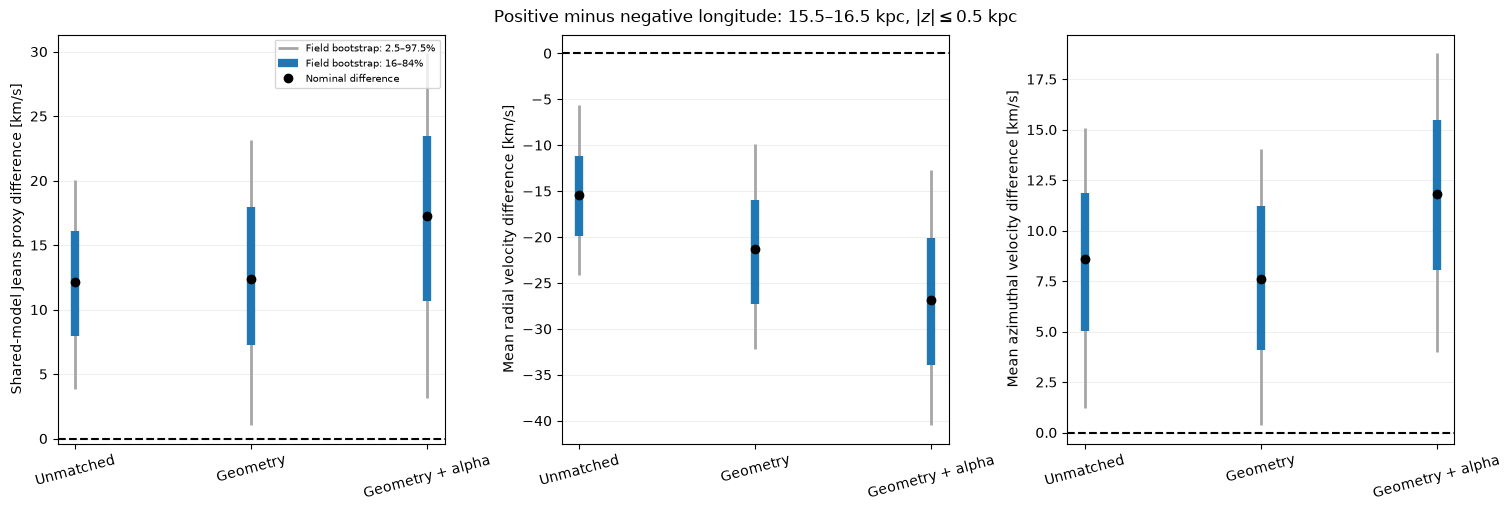

In [49]:
# Plot mirror-matched results
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    constrained_layout=True,
)

mp_order = list(mp_samples)

quantities = [
    ("Jeans_proxy", "Shared-model Jeans proxy difference [km/s]"),
    ("mean_vR", "Mean radial velocity difference [km/s]"),
    ("mean_vphi", "Mean azimuthal velocity difference [km/s]"),
]

for ax, (quantity, ylabel) in zip(axes, quantities):
    table = (
        mp_summary.loc[mp_summary["quantity"] == quantity]
        .set_index("sample")
        .loc[mp_order]
    )

    positions = np.arange(len(table))

    ax.vlines(
        positions,
        table["p025"],
        table["p975"],
        color="0.65",
        linewidth=2,
        label="Field bootstrap: 2.5–97.5%",
    )

    ax.vlines(
        positions,
        table["p16"],
        table["p84"],
        color="tab:blue",
        linewidth=6,
        label="Field bootstrap: 16–84%",
    )

    ax.plot(
        positions,
        table["point"],
        "ko",
        label="Nominal difference",
    )

    ax.axhline(0, color="black", linestyle="--")
    ax.grid(axis="y", alpha=0.2)

    ax.set_xticks(
        positions,
        ["Unmatched", "Geometry", "Geometry + alpha"],
        rotation=15,
    )

    ax.set_ylabel(ylabel)

axes[0].legend(fontsize=7)

fig.suptitle(
    r"Positive minus negative longitude: "
    r"15.5–16.5 kpc, $|z|\leq0.5$ kpc"
)

save_figure_pair(fig, "longitude_sign_mirror_comparison")


In [50]:
# Screen catalogue quality and count retained stars and pairs
def qa_boolean(column):
    text = (
        q_stars[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    text = text.str.replace(
        r"^b['\"](.*)['\"]$",
        r"\1",
        regex=True,
    )

    known = text.isin([
        "true", "false", "1", "0",
        "yes", "no", "t", "f",
    ])

    if not known.all():
        raise ValueError(
            f"Unrecognized or missing boolean values in {column}"
        )

    return text.isin(
        ["true", "1", "yes", "t"]
    ).to_numpy(bool)


def qa_numeric(column):
    return pd.to_numeric(
        q_stars[column], errors="coerce"
    ).to_numpy(float)


qa_severe = qa_boolean("STARFLAG_SEVERE")
qa_rv_warning = qa_boolean("STARFLAG_RV_WARNING")

qa_rvscatter = qa_numeric("SEL_VSCATTER_KMS")
qa_rverr = qa_numeric("SEL_RV_ERR_KMS")

qa_fracpi = (
    qa_numeric("spec_parallax_err")
    / qa_numeric("spec_parallax")
)

qa_bad_rverr = (
    ~np.isfinite(qa_rverr)
    | (qa_rverr <= 0)
)

qa_variable = (
    np.isfinite(qa_rvscatter)
    & (qa_rvscatter > 5.0)
)

qa_good = ~(
    qa_severe
    | qa_rv_warning
    | qa_bad_rverr
    | qa_variable
)

qa_summary_rows = []

for name, samples in mp_samples.items():
    for side, rows in samples.items():
        qa_summary_rows.append({
            "sample": name,
            "side": side,
            "N": len(rows),
            "severe_flag": int(qa_severe[rows].sum()),
            "RV_warning": int(qa_rv_warning[rows].sum()),
            "RV_scatter_gt5": int(qa_variable[rows].sum()),
            "bad_RV_error": int(qa_bad_rverr[rows].sum()),
            "median_frac_parallax_error": np.nanmedian(
                qa_fracpi[rows]
            ),
            "maximum_frac_parallax_error": np.nanmax(
                qa_fracpi[rows]
            ),
            "median_SNR": np.nanmedian(
                qa_numeric("SEL_SNR")[rows]
            ),
        })

qa_summary = pd.DataFrame(qa_summary_rows)

qa_summary.to_csv(
    PROJECT / "reports/longitude_sign_mirror_quality_summary.csv",
    index=False,
)

qa_union = np.sort(np.r_[
    mp_samples["unmatched"]["Lpos"],
    mp_samples["unmatched"]["Lneg"],
])

qa_columns = [
    "2MASS_ID", "SEL_LOCATION_ID", "SEL_SNR",
    "SEL_RV_KMS", "SEL_RV_ERR_KMS", "SEL_VSCATTER_KMS",
    "SEL_GAIA_PMRA_MAS_YR", "SEL_GAIA_PMDEC_MAS_YR",
    "SEL_GAIA_PMRA_ERR_MAS_YR", "SEL_GAIA_PMDEC_ERR_MAS_YR",
    "spec_parallax", "spec_parallax_err", "SEL_ALPHA_M",
    "STARFLAG_SEVERE", "STARFLAG_RV_WARNING",
]

qa_stars = q_stars.iloc[qa_union][qa_columns].copy()
qa_stars["row_index"] = qa_union

qa_stars["longitude_sign"] = np.where(
    ls_masks["Lpos"][qa_union],
    "positive",
    "negative",
)

qa_stars["passes_quality_sensitivity"] = qa_good[qa_union]

for name, samples in mp_samples.items():
    qa_stars[f"in_{name}"] = np.isin(
        qa_union,
        np.r_[samples["Lpos"], samples["Lneg"]],
    )

qa_stars.to_csv(
    PROJECT / "results/longitude_sign_mirror_quality_stars.csv",
    index=False,
)

with pd.option_context("display.max_columns", None):
    display(qa_summary)
    display(
        qa_stars.loc[
            ~qa_stars["passes_quality_sensitivity"]
        ]
    )


,sample,side,N,severe_flag,RV_warning,RV_scatter_gt5,bad_RV_error,median_frac_parallax_error,maximum_frac_parallax_error,median_SNR
0,unmatched,Lpos,69,0,0,0,0,0.069457,0.132916,197.6110
1,unmatched,Lneg,60,0,0,1,0,0.078675,0.129827,172.7200
2,geometry,Lpos,44,0,0,0,0,0.066975,0.132916,208.7585
3,geometry,Lneg,44,0,0,1,0,0.077819,0.111567,209.4100
4,geometry_alpha,Lpos,31,0,0,0,0,0.063665,0.132916,244.3900
5,geometry_alpha,Lneg,31,0,0,1,0,0.078189,0.111567,202.3160


,2MASS_ID,SEL_LOCATION_ID,SEL_SNR,SEL_RV_KMS,SEL_RV_ERR_KMS,SEL_VSCATTER_KMS,SEL_GAIA_PMRA_MAS_YR,SEL_GAIA_PMDEC_MAS_YR,SEL_GAIA_PMRA_ERR_MAS_YR,SEL_GAIA_PMDEC_ERR_MAS_YR,spec_parallax,spec_parallax_err,SEL_ALPHA_M,STARFLAG_SEVERE,STARFLAG_RV_WARNING,row_index,longitude_sign,passes_quality_sensitivity,in_unmatched,in_geometry,in_geometry_alpha
13634,2M06371427+0644272,5090.0,202.316,81.6867,0.008011,5.30337,-0.539141,-0.855043,0.169485,0.15579,0.1215,0.0095,0.046198,False,False,13634,negative,False,True,True,True


In [51]:
# Recompute matched contrasts after quality screens
qa_samples = {}

for name, samples in mp_samples.items():
    positive = samples["Lpos"]
    negative = samples["Lneg"]

    if name == "unmatched":
        qa_samples[name] = {
            "Lpos": positive[qa_good[positive]],
            "Lneg": negative[qa_good[negative]],
        }
    else:
        keep_pair = (
            qa_good[positive] & qa_good[negative]
        )

        qa_samples[name] = {
            "Lpos": positive[keep_pair],
            "Lneg": negative[keep_pair],
        }

    assert min(
        len(rows) for rows in qa_samples[name].values()
    ) >= 20


def qa_estimate(samples):
    sides = {}

    for side, rows in samples.items():
        field_index = np.searchsorted(
            fb_fields,
            fb_location[rows].astype(np.int64),
        )

        assert np.array_equal(
            fb_fields[field_index],
            fb_location[rows].astype(np.int64),
        )

        counts = np.bincount(
            field_index, minlength=fb_M
        )

        sums = np.column_stack([
            np.bincount(
                field_index,
                weights=mp_values[rows, column],
                minlength=fb_M,
            )
            for column in range(4)
        ])

        denominator = fb_weights @ counts

        boot = np.full((FB_NBOOT, 4), np.nan)

        np.divide(
            fb_weights @ sums,
            denominator[:, None],
            out=boot,
            where=denominator[:, None] > 0,
        )

        point = mp_values[rows].mean(axis=0)

        vc_squared = point[1] - point[0] * (
            1
            - MP_R_EVAL / 3.0
            - 2 * MP_R_EVAL / ht_scale
        )

        assert point[0] > 0
        assert point[1] > 0
        assert vc_squared > 0

        boot_vc_squared = (
            boot[:, 1]
            - boot[:, 0] * (
                1
                - MP_R_EVAL / 3.0
                - 2 * MP_R_EVAL / fb_scale_boot
            )
        )

        valid = (
            (denominator > 0)
            & (boot[:, 0] > 0)
            & (boot[:, 1] > 0)
            & (boot_vc_squared > 0)
            & np.isfinite(fb_scale_boot)
        )

        sides[side] = {
            "point": np.array([
                np.sqrt(vc_squared),
                point[2],
                point[3],
            ]),
            "boot": np.column_stack((
                np.where(
                    valid,
                    np.sqrt(np.maximum(boot_vc_squared, 0)),
                    np.nan,
                ),
                boot[:, 2],
                boot[:, 3],
            )),
        }

    result = {
        "point": (
            sides["Lpos"]["point"]
            - sides["Lneg"]["point"]
        ),
        "boot": (
            sides["Lpos"]["boot"]
            - sides["Lneg"]["boot"]
        ),
    }

    assert (
        np.isfinite(result["boot"])
        .mean(axis=0)
        .min()
        >= 0.95
    )

    return result


qa_stats = {
    name: qa_estimate(samples)
    for name, samples in qa_samples.items()
}

qa_result_rows = []
qa_change_rows = []

for name, data in qa_stats.items():
    for column, quantity in enumerate((
        "Jeans_proxy", "mean_vR", "mean_vphi"
    )):
        quantiles = np.nanpercentile(
            data["boot"][:, column],
            [2.5, 16, 50, 84, 97.5],
        )

        qa_result_rows.append({
            "sample": name,
            "quantity": quantity,
            "N_Lpos": len(qa_samples[name]["Lpos"]),
            "N_Lneg": len(qa_samples[name]["Lneg"]),
            "point": data["point"][column],
            "p025": quantiles[0],
            "p16": quantiles[1],
            "p50": quantiles[2],
            "p84": quantiles[3],
            "p975": quantiles[4],
        })

    change = (
        data["point"][0]
        - mp_stats[name]["point"][0]
    )

    change_boot = (
        data["boot"][:, 0]
        - mp_stats[name]["boot"][:, 0]
    )

    assert np.isfinite(change_boot).mean() >= 0.95

    quantiles = np.nanpercentile(
        change_boot, [2.5, 50, 97.5]
    )

    qa_change_rows.append({
        "sample": name,
        "change_in_Jeans_proxy": change,
        "p025": quantiles[0],
        "p50": quantiles[1],
        "p975": quantiles[2],
    })

qa_results = pd.DataFrame(qa_result_rows)
qa_changes = pd.DataFrame(qa_change_rows)

qa_results.to_csv(
    PROJECT / "results/longitude_sign_quality_sensitivity.csv",
    index=False,
)

qa_changes.to_csv(
    PROJECT / "results/longitude_sign_quality_changes.csv",
    index=False,
)

with pd.option_context("display.max_columns", None):
    display(qa_results)
    display(qa_changes)


,sample,quantity,N_Lpos,N_Lneg,point,p025,p16,p50,p84,p975
0,unmatched,Jeans_proxy,69,59,11.939181,3.805693,7.722656,11.802540,15.939283,19.880038
1,unmatched,mean_vR,69,59,-15.214104,-23.974821,-19.772664,-15.412730,-10.807143,-5.259298
2,unmatched,mean_vphi,69,59,8.567362,1.131922,5.044920,8.619309,11.854354,15.086642
3,geometry,Jeans_proxy,43,43,12.481755,0.595093,7.180618,12.703749,18.156878,23.438955
4,geometry,mean_vR,43,43,-21.395840,-32.913940,-27.649202,-21.693600,-15.694004,-9.080354
5,geometry,mean_vphi,43,43,7.530818,0.154642,3.917817,7.699723,11.238749,14.113620
6,geometry_alpha,Jeans_proxy,30,30,17.491207,2.494850,10.722291,17.625515,23.975615,30.674229
7,geometry_alpha,mean_vR,30,30,-27.167206,-41.944308,-34.850508,-27.343301,-20.022399,-12.204655
8,geometry_alpha,mean_vphi,30,30,11.899012,3.879633,8.063954,11.700967,15.671131,19.038787


,sample,change_in_Jeans_proxy,p025,p50,p975
0,unmatched,-0.175178,-0.628010,-0.146671,0.000000
1,geometry,0.076168,-0.872630,0.000000,1.258788
2,geometry_alpha,0.264151,-0.743838,0.204202,1.910164


In [52]:
# Write and display the scientific checkpoint
def qa_markdown_table(frame):
    def format_value(value):
        if isinstance(value, (float, np.floating)):
            return f"{value:.3f}"
        return str(value)

    lines = [
        "| " + " | ".join(map(str, frame.columns)) + " |",
        "| " + " | ".join(["---"] * len(frame.columns)) + " |",
    ]

    for row in frame.itertuples(index=False, name=None):
        lines.append(
            "| "
            + " | ".join(format_value(value) for value in row)
            + " |"
        )

    return "\n".join(lines)


saved_fields = pd.read_csv(
    PROJECT / "results/longitude_sign_field_bootstrap_summary.csv"
)

outer_table = saved_fields.loc[
    saved_fields["R_left"] >= 15.5,
    [
        "case", "R_left", "R_right",
        "point", "field_p025", "field_p975",
    ],
]

matched_table = mp_summary[[
    "sample", "quantity", "point", "p025", "p975"
]]

quality_table = qa_results[[
    "sample", "quantity", "N_Lpos", "N_Lneg",
    "point", "p025", "p975",
]]

report_parts = [
    "# USYD longitude-sign comparison — preliminary checkpoint",

    """## Height and field-sampling checks
Differences below are positive minus negative longitude, in km/s.
The final columns are conditional central 95% field-bootstrap intervals.""",

    qa_markdown_table(outer_table),

    """The 15.5–16.5 kpc difference survives deleting any single
LOCATION_ID field. The 16.5–18 kpc result is sensitive to the height
restriction. These are exploratory local results, not global detection
significances.""",

    """## Mirror-matched local diagnostic
At 15.5–16.5 kpc and |z| <= 0.5 kpc, geometric matching retains
44 pairs; geometry-plus-alpha matching retains 31 pairs.
Matching uses nominal radius, reflected azimuth, signed height and
optionally alpha abundance, without using velocities.

The Jeans proxy retains the common density and dispersion-gradient
model. Mean radial and azimuthal velocities are also compared directly.""",

    qa_markdown_table(matched_table),

    """Intervals condition on the selected matches. The change caused
by alpha matching includes zero in its conditional 95% interval;
the larger point estimate does not establish an enhancement.""",

    """## Catalogue-quality sensitivity
The diagnostic screen excludes severe STARFLAG records, RV-warning
records, invalid/nonpositive RV uncertainties and RV scatter >5 km/s.
The scatter threshold is an exploratory sensitivity criterion.
A rejected member removes its entire matched pair.

This does not replace the baseline selection. The shared Jeans model
is held common to isolate the effect of the screen.""",

    qa_markdown_table(quality_table),
]

report = "\n\n".join(report_parts)

checkpoint = (
    PROJECT / "reports/longitude_sign_interim_summary.md"
)

checkpoint.write_text(report, encoding="utf-8")

print(report)
print("Saved:", checkpoint)


# USYD longitude-sign comparison — preliminary checkpoint

## Height and field-sampling checks
Differences below are positive minus negative longitude, in km/s.
The final columns are conditional central 95% field-bootstrap intervals.

| case | R_left | R_right | point | field_p025 | field_p975 |
| --- | --- | --- | --- | --- | --- |
| full | 15.500 | 16.500 | 9.223 | 4.754 | 13.780 |
| full | 16.500 | 18.000 | 9.251 | 4.542 | 13.948 |
| height | 15.500 | 16.500 | 12.114 | 3.836 | 20.029 |
| height | 16.500 | 18.000 | 0.743 | -7.465 | 7.864 |

The 15.5–16.5 kpc difference survives deleting any single
LOCATION_ID field. The 16.5–18 kpc result is sensitive to the height
restriction. These are exploratory local results, not global detection
significances.

## Mirror-matched local diagnostic
At 15.5–16.5 kpc and |z| <= 0.5 kpc, geometric matching retains
44 pairs; geometry-plus-alpha matching retains 31 pairs.
Matching uses nominal radius, reflected azimuth, signed height and
optionally alp

In [53]:
# Confirm the run wrote all result families and inventory the generated files.
required_outputs = (
    "reports/notebook_report_validation.csv",
    "reports/phase1_119_forensic_scenario_matrix.csv",
    "reports/step15B_full_parent_mc_manifest.json",
    "results/table1_reproduced.csv",
    "results/step14B_model_sensitivity_fits.csv",
    "results/longitude_sign_rotation_curve_comparison.csv",
    "results/longitude_sign_field_bootstrap_summary.csv",
    "results/longitude_sign_mirror_pairs.csv",
    "reports/longitude_sign_interim_summary.md",
)
missing_outputs = [name for name in required_outputs if not (PROJECT / name).is_file()]
if missing_outputs:
    raise RuntimeError(f"Missing expected products: {missing_outputs}")

assert q_summary["N_selected"].tolist() == [4804, 138, 17001, 6009, 18068]
assert len(ls_common) == 19 and len(fb_fields) == 325
assert fb_leave["field_removed"].nunique() == 325
assert len(mp_pairs.loc[mp_pairs["sample"].eq("geometry")]) == 44
assert len(mp_pairs.loc[mp_pairs["sample"].eq("geometry_alpha")]) == 31
assert not qa_results.empty and not qa_changes.empty
print("Longitude, field-deletion, mirror-pair and quality-screen checks passed.")

inventory = PROJECT / "reports/complete_output_inventory.csv"
products = sorted(
    path
    for folder in ("data/interim", "data/processed", "results", "figures", "reports", "logs", "scripts")
    for path in (PROJECT / folder).rglob("*")
    if path.is_file() and path != inventory and "__pycache__" not in path.parts
)
pd.DataFrame(
    {"file": str(path.relative_to(PROJECT)), "bytes": path.stat().st_size, "sha256": sha256(path)}
    for path in products
).to_csv(inventory, index=False)
print(f"Completed all stages. {len(products)} run products inventoried at {inventory}")


Longitude, field-deletion, mirror-pair and quality-screen checks passed.
Completed all stages. 137 run products inventoried at /Volumes/Sudipta_T7/Projects/Galactic_Rotation_Curve/notebook/USYD_Reproduction_Bundle/usyd_runs/20261119T173423Z-x6gyd1g5/reports/complete_output_inventory.csv
